# OEAS 805 Project: Exploratory Data Analysis (NB00)
## Road Pavement Cracking & Tidal Flooding in The Hague, Norfolk, VA
### Jupyter Notebook created by Nick Carpenter for the Fall 2026 OEAS 805: Advanced Environmental Data Science course

This project asks whether **pavement cracking** in the Hague neighborhood of Norfolk, VA is associated with
**chronic tidal (high-tide) flooding**. The inputs are:

- a 2 cm drone orthomosaic and a 0.5 m drone DEM of the neighborhood;
- a crack map and pavement mask derived from that imagery;
- road centerlines with traffic volumes;
- a tidal-datum surface, used to express elevation as height above Mean Higher High Water (MHHW);
- an empirical tide-gauge equation (Ezer, 2022) that turns that height into **flood days per year**.

No ArcGIS Pro software is used. Every external dataset is read from its public **ArcGIS REST API** link, requesting
only the study-area extent. The only files read from disk are the author's own datasets in `DATA/01_Raw_Data_Custom`.

This notebook is the **exploratory data analysis (EDA)** of every dataset the project uses. It follows the project
outline ([Project_outline.md](https://github.com/jessiesturner/OEAS805_envdatasci/blob/main/homeworks/Project_outline.md)):

| Outline requirement | Where it is addressed |
|---|---|
| 1. Data description & access | The **Input data sources** cell below (description, links and REST endpoints of every external dataset; the custom datasets are stated to be the author's own data), and **Section 01** (each dataset loaded, with its size, data types and missing data) |
| 2. Spatial & temporal coverage | **Section 02**: Q4 spatial bounds and actual data footprint, Q5 resolution, Q6 time range and sampling frequency of every dataset |
| 3. Data integration & overlap | **Section 03** (cleaning onto one grid and the 5 m analysis cells) and **Section 04**: Q7 resolution compatibility and grid alignment, Q8 spatial overlap, Q9 temporal overlap |
| 4. Visualization guidelines | Maps, histograms, box plots, bar charts, a timeline and line plots throughout. Every figure has a title, labeled axes with units (maps: easting/northing in m or lon/lat, with a scale bar, north arrow and legend or colour bar), and a short text paragraph next to it that explains what it shows |

The questions answered in the cell outputs are numbered throughout the notebook:

- **Section 01**: Q1 size, Q2 data types, Q3 missing data.
- **Section 02**: Q4 spatial bounds, Q5 spatial resolution, Q6 temporal coverage & sampling frequency.
- **Section 04**: Q7 resolution compatibility, Q8 spatial overlap, Q9 temporal overlap.

**Notebook sections:**

| Section | Purpose |
|---|---|
| **00 Setup & derived flood-days dataset** | Imports, user settings, helper functions, clean-up of the previous run. Builds the cleaned DEM / VDatum / water-surface rasters and the derived **flood days per year** raster |
| **01 Data description & access** | Loads and describes every dataset (Q1 size, Q2 data types, Q3 missing data) with maps |
| **02 Spatial & temporal coverage** | Q4 spatial bounds, Q5 spatial resolution, Q6 time ranges and sampling frequency |
| **03 Data cleaning** | Filters, reprojects and joins the vector layers. Builds the traffic (AADT) polygon and the **5 m analysis cells** (fishnet clipped to the road mask) with every per-cell variable |
| **04 Data integration & overlap** | Q7 resolution/grid alignment, Q8 spatial overlap with the analysis cells, Q9 temporal overlap, integrated maps |
| **05 Descriptive statistics & distributions** | Per dataset: statistics table, distribution plot, additional figures |
| **06 Outliers** | IQR outliers per dataset |
| **07 First look at relationships** | Crack density vs. elevation, flood days, traffic and surface type (exploratory) |
| **08 Summary, EDA note & initial conclusions** | Key numbers, a time-stamped summary note, and what the EDA suggests |

**How to run:** activate the `oes805_proj` environment and run the cells from top to bottom. Everything you might
need to change is in **00.0 (Step B)**, the second code cell. The two slow steps (aggregating the 2 cm crack raster,
building the downsampled 0.32 m-pixel imagery preview) and all API downloads are cached after the first run. Every other output is deleted and
rebuilt on each run.

## Input data sources

**Project spatial reference:** the drone orthomosaic (`Imagery_dry`). Every dataset is:

- filtered to its extent;
- reprojected to its coordinate system (NAD83(2011) / Virginia South, EPSG:6594, metres; vertical datum NAVD88,
  EPSG:5703);
- for rasters, snapped to its 0.02 m pixel grid.

Full citations are in the **References** cell below.

**Primary data (project-collected, Old Dominion University).** Both are read from tiled image services, which return
LERC-compressed tiles.

- **Hague 2025 Dry RGB Imagery** (Steiner, 2026b)
  - 3-band (RGB, 8-bit) orthomosaic at **0.02 m**.
  - Collected during a **low-tide drone flight on October 3, 2025** with a DJI Mavic 3 Multispectral (M3M) quadcopter.
  - Item: <https://www.arcgis.com/home/item.html?id=ac0a20f8293143c191a5039b6f161cbe>
  - REST: `https://tiledimageservices.arcgis.com/2DbqGRRQS9wbBetw/arcgis/rest/services/Hague_2025_Dry_RGB_Imagery/ImageServer`
- **Hague 2025 Digital Elevation Model** (Steiner, 2026a)
  - 1-band, 32-bit float elevations (m, NAVD88) at **0.5 m**.
  - From the same October 3, 2025 low-tide flight.
  - Item: <https://www.arcgis.com/home/item.html?id=c7e6e2c791fc4cc895db55a59be804a6>
  - REST: `https://tiledimageservices.arcgis.com/2DbqGRRQS9wbBetw/arcgis/rest/services/ESLRClip_hague2025_DEM_1/ImageServer`

**External data (downloaded through the APIs for the study-area extent only):**

- **NOAA VDatum Conversion** (National Oceanic and Atmospheric Administration [NOAA], 2022; Esri Living Atlas)
  - Each pixel is the MHHW tidal datum expressed as an elevation in NAVD88 metres (0.00045° pixels, about 40 m E–W × 50 m N–S).
  - Item: <https://www.arcgis.com/home/item.html?id=a7238c20bfc445be97b3d32a49e5b363>
  - REST: `https://tiledimageservices.arcgis.com/P3ePLMYs2RVChkJx/arcgis/rest/services/NOAA_VDatum_Conversion/ImageServer`
- **Virginia Road Centerlines (RCL), layer "< 50,000" (ID 5)** (Virginia Geographic Information Network [VGIN], 2024)
  - Statewide road centerlines maintained by VGIN, VDOT and local governments, republished quarterly.
  - Carries the VDOT traffic volume **`VDOT_AADT`** (Annual Average Daily Traffic, vehicles/day).
  - Service metadata: created 2021-04-01, last revised 2024-09-17; segment edit dates in the study area run to
    September 2026. The AADT count year is not stated.
  - Page: <https://vgin.vdem.virginia.gov/datasets/cd9bed71346d4476a0a08d3685cb36ae/about>
  - REST: `https://vginmaps.vdem.virginia.gov/arcgis/rest/services/VA_Base_Layers/VBMP_RCL/FeatureServer/5`
- **City of Norfolk Driveways** (City of Norfolk Department of Public Works, 2022)
  - Polygons digitized from 2006/2008 VGIN aerial photography.
  - Page: <https://norfolkgisdata-orf.opendata.arcgis.com/datasets/ORF::driveway-city-of-norfolk/about>
  - REST: `https://gisshare.norfolk.gov/pubserver/rest/services/OpenData/Public_Works/FeatureServer/2`
- **City of Norfolk Sidewalks** (City of Norfolk, 2022)
  - Lines digitized from 2006 VGIN aerial photography.
  - Used as the reference for hand-drawing the `Custom_Sidewalk_2025Hague` polygons; shown here for comparison.
  - Page: <https://norfolkgisdata-orf.opendata.arcgis.com/datasets/ORF::sidewalk-city-of-norfolk/about>
- **Observed relative sea level trend, Sewells Point (station 8638610)** (NOAA CO-OPS, 2026)
  - Monthly mean sea level, 1927–present; NOAA's trend summary from the Derived Product API.
  - Page: <https://tidesandcurrents.noaa.gov/sltrends/sltrends_station.shtml?id=8638610>
  - Data API (monthly means): `https://api.tidesandcurrents.noaa.gov/api/prod/datagetter?product=monthly_mean&station=8638610&datum=MSL&units=metric&format=csv`
  - API: `https://api.tidesandcurrents.noaa.gov/dpapi/prod/webapi/product/sealvltrends.json?station=8638610&affil=US`
- **Relative sea-level-rise projection, Sewells Point**
  - From the U.S. Army Corps of Engineers Sea-Level Change Curve Calculator (U.S. Army Corps of Engineers [USACE],
    2022), using the NOAA 2017 Intermediate-High scenario (Sweet et al., 2017) with local subsidence in Norfolk.
  - The 10-value table is coded directly in 00.0 (Step B).

**Custom data (made by the author; shipped in `DATA/01_Raw_Data_Custom`, never modified; Carpenter, 2026).** These
were made in ArcGIS Pro from the imagery and the datasets above. Only the final products are shipped. The
intermediate hand-drawn layers listed below are not needed for this analysis.

- **`Road_Mask_Final_Shrunk3.tif`**: pavement (road + sidewalk/driveway) mask on the 0.02 m imagery grid (1 = pavement).
  - The road centerlines were buffered 6 m to define the area the mask may cover, and the sidewalk/driveway surface
    polygon (`Custom_Sidewalk_2025Hague` merged with the City driveways) was added to it.
  - Segment Anything Model 3 (Eagle Technology et al., 2026) was run on the imagery with the prompts "Concrete,
    Impervious Surface, Pavement, Road". Its detections were clipped to that allowed area, and hand-drawn polygons of
    pavement it missed were added.
  - Exclusions were cut out. These were SAM3 detections of "power line shadow, gravel, shadow" (buffered 5 cm),
    hand-drawn shadow/thin-feature lines (buffered 10 cm), hand-drawn sidewalk control-joint grooves (buffered 5 cm),
    and hand-drawn exclusion polygons.
  - The final polygon was rasterized on the imagery grid (cell centre) and shrunk inward by 3 pixels (6 cm) to drop
    the unreliable edge.
- **`Cracks_Classified_Combined_Shrunk.tif`**: crack map on the imagery grid (1 = crack, 0 = no crack, NoData outside
  the mask).
  - Esri's pretrained Pavement Crack Detection model (Esri, 2026c) was run on the masked imagery. Its lines were
    hand-edited into a full crack inventory, and a training subset was kept separately.
  - An HED edge-detection model was trained on 256 × 256-pixel chips of the masked RGB imagery, with crack lines
    buffered 2 cm (up to 50 epochs), and used to classify every pixel.
  - The inventory lines were forced in (buffered 6 cm). Specks under 4 connected pixels were removed, and the result
    was clipped to the shrunk mask.
- **`Custom_AccuracyPts_Labeled_2025Hague_20261003.shp`**: accuracy-assessment points.
  - Made with an equalized stratified random design: ~75 points on each class of the crack raster, kept ≥ 1 m from
    the model's training lines.
  - Each point was labeled by eye on the imagery: `GrndTruth` 1 = crack, 0 = no crack. `Classified` = the crack
    raster's value at the point.
- **`Custom_Sidewalk_2025Hague.shp`**: sidewalk/driveway surface polygons.
  - Hand-digitized on the 2025 imagery, using the City of Norfolk sidewalk lines as a guide.
- **`Custom_AddRCL_2025Hague.shp`**: centerlines for minor roads and parking-lot lanes.
  - Hand-drawn on the 2025 imagery where the VGIN RCL layer has none.
- **`WaterSurface_Final.shp`**: the open-water surface removed from the DEM.
  - Built from the 1 m hydro-corrected HCDEM (Chen, 2023; water = 0 m), whose cells ≤ 0 m were
    converted to polygons and PAEK-smoothed.
  - SAM3 "Water" detections on the imagery were added, and everything was dissolved into one polygon.
  - Shipped as a file because the public HCDEM service serves only map pictures, not elevation values.

## References (APA 7)

**Data sets & models**

Carpenter, N. (2026). *Hague 2025 road-cracking project: Custom data sets* (Cracks_Classified_Combined_Shrunk, Road_Mask_Final_Shrunk3, Custom_AccuracyPts_Labeled_2025Hague_20261003, Custom_Sidewalk_2025Hague, Custom_AddRCL_2025Hague, WaterSurface_Final) [Unpublished raw data]. Old Dominion University.

Chen, Y.-H. (2023). *HCDEM: Hydro-corrected DEM with 1 meter resolution* [Data set]. Old Dominion University. ArcGIS Online. https://www.arcgis.com/home/item.html?id=f4fe88d43aa948fba1c0cae88e4a5376

City of Norfolk. (2022). *Sidewalk - City of Norfolk* [Data set]. City of Norfolk Open Data. https://norfolkgisdata-orf.opendata.arcgis.com/datasets/ORF::sidewalk-city-of-norfolk/about

City of Norfolk Department of Public Works. (2022). *Driveway - City of Norfolk* [Data set]. City of Norfolk Open Data. https://norfolkgisdata-orf.opendata.arcgis.com/datasets/ORF::driveway-city-of-norfolk/about

Eagle Technology, Meta, & Interactive Digital Technologies. (2026). *Segment Anything Model 3 (SAM3)* [Deep learning package]. ArcGIS Online. https://www.arcgis.com/home/item.html?id=37ef2e1ba0c042ce99501f56295ec0d4

Esri. (2026c). *Pavement crack detection* [Deep learning package]. ArcGIS Living Atlas of the World. https://www.arcgis.com/home/item.html?id=a9c3134e361e49a191efda169f5a337d

National Oceanic and Atmospheric Administration. (2022). *NOAA VDatum conversion* [Data set]. Esri ArcGIS Living Atlas of the World. https://www.arcgis.com/home/item.html?id=a7238c20bfc445be97b3d32a49e5b363

National Oceanic and Atmospheric Administration, Center for Operational Oceanographic Products and Services. (2026). *Relative sea level trend 8638610 Sewells Point, Virginia* [Data set]. https://tidesandcurrents.noaa.gov/sltrends/sltrends_station.shtml?id=8638610

Steiner, B. (2026a). *Hague 2025 digital elevation model* [Data set]. Old Dominion University GeoSEA. ArcGIS Online. https://www.arcgis.com/home/item.html?id=c7e6e2c791fc4cc895db55a59be804a6

Steiner, B. (2026b). *Hague 2025 dry RGB imagery* [Data set]. Old Dominion University. ArcGIS Online. https://www.arcgis.com/home/item.html?id=ac0a20f8293143c191a5039b6f161cbe

U.S. Army Corps of Engineers. (2022). *Sea-level change curve calculator* [Online tool]. https://cwbi-app.sec.usace.army.mil/rccslc/slcc_calc.html

Virginia Geographic Information Network. (2024). *Virginia road centerlines (RCL)* [Data set; VBMP_RCL feature service, layer 5]. Virginia Department of Emergency Management. https://vgin.vdem.virginia.gov/datasets/cd9bed71346d4476a0a08d3685cb36ae/about

**Literature, methods & documentation**

Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement, 20*(1), 37–46. https://doi.org/10.1177/001316446002000104

Esri. (2026a). *Image tile*. ArcGIS REST APIs. https://developers.arcgis.com/rest/services-reference/enterprise/image-tile/

Esri. (2026b). *LERC: Limited Error Raster Compression* [Computer software]. GitHub. https://github.com/Esri/lerc

Esri. (2026d). *Query (Feature Service/Layer)*. ArcGIS REST APIs. https://developers.arcgis.com/rest/services-reference/enterprise/query-feature-service-layer/

Ezer, T. (2022). A demonstration of a simple methodology of flood prediction for a coastal city under threat of sea level rise: The case of Norfolk, VA, USA. *Earth's Future, 10*(9), e2022EF002786. https://doi.org/10.1029/2022EF002786

National Oceanic and Atmospheric Administration, Center for Operational Oceanographic Products and Services. (2022, September). *Tidal datums*. https://tidesandcurrents.noaa.gov/datum_options.html

Sweet, W. V., Kopp, R. E., Weaver, C. P., Obeysekera, J., Horton, R. M., Thieler, E. R., & Zervas, C. (2017). *Global and regional sea level rise scenarios for the United States* (NOAA Technical Report NOS CO-OPS 083). National Oceanic and Atmospheric Administration. https://tidesandcurrents.noaa.gov/publications/techrpt83_Global_and_Regional_SLR_Scenarios_for_the_US_final.pdf

Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.

U.S. Census Bureau. (2026). *MAF/TIGER feature class code (MTFCC) definitions*. Retrieved October 5, 2026, from https://www.census.gov/library/reference/code-lists/mt-feature-class-codes.html

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 00) Setup & derived flood-days dataset

### 00.0 Setup

- **Step A** installs (only `lerc`, if missing) and imports every package. Nothing is installed or imported further
  down.
- **Step B** holds **every setting a person might edit**: the project folder, on/off switches, custom file names,
  API links, map extents, and processing and plotting settings.
- **Step C** builds the folder paths, deletes the outputs of the previous run (keeping the caches), and defines the
  shared helper functions. It needs no edits.

Outputs follow the project naming rules:

- Clean data (rebuilt on every run) → `DATA/02_Clean_Data/OUT_DATA_NB00_Sec##/`
- Figures (only when `SAVE_FIGURES = True`) → `FIGURES/Figures/OUT_FIGURES_NB00_Sec##/` or `FIGURES/Maps/OUT_FIGURES_NB00_Sec##/`,
  named `Fig##_ShortName_YYYYMMDD_HHMMSS.png`
- Notes → `REPORTS/02_Notes/OUT_REPORTS_NB00_Sec08/`
- API download cache (kept between runs) → `CODE/scratch_temp/NB00/api_cache/`

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

In [1]:
# ---------------------------------------------------------------------
# 00.0 (Step A) — Install (if needed) and import every package used in this notebook
# ---------------------------------------------------------------------
# All packages are installed (if needed) and imported HERE, and nowhere else in the notebook. They are all in the
# oes805_proj environment (oes805_proj.yml / oes805_proj.txt) except `lerc`, Esri's decoder for the LERC-compressed
# tiles of the ArcGIS tiled image services. The conda "lerc" package is only the C library, so the Python module is
# installed from PyPI (pip) into the active environment the first time this cell runs.
import sys
import subprocess
import importlib
import importlib.util
AUTO_INSTALL_LERC = True        # True = pip-install the 'lerc' Python package into this environment if it is missing
if importlib.util.find_spec("lerc") is None and AUTO_INSTALL_LERC:
    print("[00.0 A] installing the 'lerc' Python package with pip (one time only) ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "lerc"])
    importlib.invalidate_caches()
_required = ["numpy", "pandas", "matplotlib", "seaborn", "scipy", "requests", "geopandas",
             "shapely", "pyproj", "rasterio", "pyogrio", "lerc"]
_missing = [p for p in _required if importlib.util.find_spec(p) is None]
if _missing:
    raise ImportError(f"Missing packages: {_missing}\n  Install them into the active environment, e.g.:  "
                      f"conda install {' '.join(m for m in _missing if m != 'lerc')}"
                      + ("   and   pip install lerc" if "lerc" in _missing else ""))

# Standard library: file paths, folder deletion, JSON, math, timing, run stamp, parallel tile downloads
import os
import json
import math
import time
import shutil
import warnings
from pathlib import Path
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor

# numpy / pandas: arrays and tables
import numpy as np
import pandas as pd

# matplotlib / seaborn: plotting (AnchoredSizeBar = scale bars, patheffects = outlined lines)
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.patheffects as pe
import matplotlib.font_manager as fm
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import seaborn as sns

# scipy.stats: skewness and Spearman correlations
from scipy import stats, ndimage

# requests: HTTP calls to the ArcGIS REST APIs (with automatic retries)
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# geopandas / shapely / pyproj: vector data, geometry and coordinate reference systems
import geopandas as gpd
import shapely
from shapely.geometry import box
import pyproj
from pyproj import CRS

# rasterio: read/write rasters, reproject/snap them, burn polygons into rasters
import rasterio
from rasterio.transform import from_origin
from rasterio.windows import Window
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio import features
from rasterio.io import MemoryFile

# lerc: decodes the LERC-compressed tiles returned by the ArcGIS tiled image services
import lerc

# cartopy: web-map tiles (street map for the locator, satellite under the VDatum surface). Optional.
try:
    import cartopy.crs as ccrs
    import cartopy.io.img_tiles as cimgt
except ImportError:
    ccrs = cimgt = None

# Display options: show every column of wide tables; silence harmless numerical notices
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", message="All-NaN slice encountered")
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="Setting the shape on a NumPy array")
print(f"[00.0 A] packages imported (numpy {np.__version__}, pandas {pd.__version__}, geopandas {gpd.__version__}, "
      f"rasterio {rasterio.__version__}, shapely {shapely.__version__})")

[00.0 A] packages imported (numpy 2.4.6, pandas 3.0.6, geopandas 1.1.3, rasterio 1.4.4, shapely 2.1.2)


In [2]:
# =====================================================================
# 00.0 (Step B) — USER SETTINGS  <-- the only cell you should need to edit
# =====================================================================

# ----- B1. Project folder ----------------------------------------------------------------------------------
# Absolute path of the project folder (the one that holds CODE, DATA, FIGURES, REPORTS).
# None = auto-detect: this notebook lives in <project>/CODE, so the project root is one folder up.
# NOTE: ****EDIT THIS LINE TO THE FOLDER PATH OR THE CODE WON'T RUN!!!****
PROJECT_ROOT = r"C:\Users\..........\OEAS805_ncarp_finalproj"
RAW_CUSTOM_DIR_NAME = "01_Raw_Data_Custom"      # DATA sub-folder with the custom files (read-only)
CLEAN_DIR_NAME      = "02_Clean_Data"           # DATA sub-folder for cleaned data

# ----- B2. Run switches ------------------------------------------------------------------------------------
CLEAN_BEFORE_RUN      = True    # True = delete this notebook's previous clean-data outputs (except the caches) first
REFRESH_API_DOWNLOADS = False   # True = re-download from the APIs (otherwise cached downloads in CODE/scratch_temp are reused)
FORCE_REBUILD_HEAVY   = False   # True = redo the slow cached steps (01.2 imagery preview, 01.6.2 crack/mask aggregation)
SAVE_FIGURES          = False   # True = export every figure as PNG to FIGURES/...  (leave False until final edits)
WRITE_REPORTS         = True    # True = write the time-stamped EDA summary .txt to REPORTS/02_Notes/...
SHOW_WEB_BASEMAP      = True    # True = draw web-map tiles (street map 01.1, satellite 01.4) -- needs internet + cartopy

# ----- B3. Custom input files (DATA/01_Raw_Data_Custom; never modified) -------------------------------------
CRACK_RASTER_FILE = "Cracks_Classified_Combined_Shrunk.tif"
ROAD_MASK_FILE    = "Road_Mask_Final_Shrunk3.tif"
ACCURACY_PTS_FILE = "Custom_AccuracyPts_Labeled_2025Hague_20261003.shp"
SIDEWALK_FILE     = "Custom_Sidewalk_2025Hague.shp"
ADD_RCL_FILE      = "Custom_AddRCL_2025Hague.shp"
WATER_FILE        = "WaterSurface_Final.shp"
CRACK_VALUE       = 1             # crack raster: 1 = crack (anything else = no crack)
ROAD_MASK_VALUE   = 1             # road mask: 1 = pavement
GRNDTRUTH_FIELD   = "GrndTruth"   # accuracy points: 1 = crack, 0 = no crack (-1 = not labeled yet)
CLASSIFIED_FIELD  = "Classified"  # accuracy points: crack-raster value stored by ArcGIS Pro

# ----- B4. API links (ArcGIS REST endpoints) ---------------------------------------------------------------
URL_IMAGERY = "https://tiledimageservices.arcgis.com/2DbqGRRQS9wbBetw/arcgis/rest/services/Hague_2025_Dry_RGB_Imagery/ImageServer"
URL_DEM     = "https://tiledimageservices.arcgis.com/2DbqGRRQS9wbBetw/arcgis/rest/services/ESLRClip_hague2025_DEM_1/ImageServer"
URL_VDATUM  = "https://tiledimageservices.arcgis.com/P3ePLMYs2RVChkJx/arcgis/rest/services/NOAA_VDatum_Conversion/ImageServer"
URL_VGIN_RCL         = "https://vginmaps.vdem.virginia.gov/arcgis/rest/services/VA_Base_Layers/VBMP_RCL/FeatureServer/5"
URL_NORFOLK_DRIVEWAY = "https://gisshare.norfolk.gov/pubserver/rest/services/OpenData/Public_Works/FeatureServer/2"
URL_NORFOLK_SIDEWALK = "https://gisshare.norfolk.gov/pubserver/rest/services/OpenData/Public_Works/FeatureServer/3"
# NOAA CO-OPS relative sea level trend, Sewells Point (station 8638610): monthly means (Data API) + trend summary (JSON API).
# NOAA's sltrends CSV download (8638610_meantrend.csv) does not serve the file, so the monthly means come from the
# CO-OPS Data API, and the trend line is fitted to them in 01.7.1.
URL_NOAA_DATAGETTER = "https://api.tidesandcurrents.noaa.gov/api/prod/datagetter"
URL_NOAA_SLT_JSON = "https://api.tidesandcurrents.noaa.gov/dpapi/prod/webapi/product/sealvltrends.json?station=8638610&affil=US"

# ----- B5. Reference grid = the Imagery_dry grid (from the imagery service's REST page) ----------------------
# Full extent, 0.02 m pixels, EPSG:6594 (+ NAVD88 EPSG:5703). Checked against the live service in 00.1 (Step A).
REF_GRID = dict(epsg=6594, xmin=3696165.99155396, ymax=1060650.14758581, res=0.02, width=31205, height=26380)

# ----- B6. Zoomed map extents (EPSG:6594 metres; reused by every zoomed-in map) ----------------------------
ZOOM_EXTENTS = {
    "Botetourt St & Mowbray Arch": dict(left=3696438.16058173, right=3696636.55312137,
                                        bottom=1060206.82084547, top=1060335.81681775),
    "Memorial Pl & Mowbray Arch":  dict(left=3696570.96656166, right=3696769.35910131,
                                        bottom=1060212.12764179, top=1060341.12361407),
    "Mowbray Arch & Fairfax Ave":  dict(left=3696172.99675149, right=3696349.34567562,
                                        bottom=1060511.44728329, top=1060626.11036976),
}
ZOOM_IMAGERY_RES_M = 0.08       # imagery pixel size for the zoomed maps (a multiple of 0.02 m; 0.04 = sharper, slower)
ZOOM_CRACK_FACTOR  = 3          # zoomed crack/mask maps: 3 x 3 imagery pixels per drawn pixel (0.06 m)

# ----- B7. Processing settings -----------------------------------------------------------------------------
AGG_FACTOR             = 25     # raster grid = 25 x 25 imagery pixels = 0.50 m (same cell size as the drone DEM)
FISHNET_CELL_M         = 5      # analysis cells: 5 m x 5 m fishnet squares clipped to the shrunk road mask (multiple of 0.5 m)
SIDEWALK_FRAC_THRESHOLD = 0.5   # a cell whose pavement is >= 50 % sidewalk/driveway is a "Sidewalk" cell ...
SIDEWALK_AADT_VALUE    = 0      # ... and gets this AADT (sidewalks are not loaded by road traffic)
AADT_BUFFER_M          = 6      # traffic polygon: centerlines with a VDOT count buffered this far (each side; flat ends)
IMAGERY_PREVIEW_FACTOR = 16     # full-site imagery preview = 16 x 0.02 m = 0.32 m pixels
VECTOR_PAD_M           = 25     # vector downloads extend this far beyond the imagery extent (m)
VDATUM_PAD_M           = 1500   # VDatum download extends this far beyond the imagery extent (m; its pixels are ~40 x 50 m)
MAX_AADT_CLASSES       = 6      # traffic/surface classes use each distinct AADT value when there are at most this many
STRIP_COARSE_ROWS      = 40     # rows of 0.5 m cells processed per strip in 01.6.2 (lower it if memory is tight)
TILE_WORKERS           = 8      # parallel tile downloads
HTTP_TIMEOUT_S         = 60
MAX_TILES              = 2000   # safety limit per tiled-image download

# ----- B8. Flood-days model (00.1) ------------------------------------------------------------------------
# Relative sea-level rise at Sewells Point (m, relative to 2000): USACE Sea-Level Change Curve Calculator (2022),
# NOAA 2017 Intermediate-High scenario (Sweet et al., 2017), including local subsidence in Norfolk.
NOAA_SLR_TABLE = {2000: 0.00, 2020: 0.19, 2030: 0.33, 2040: 0.49, 2050: 0.68,
                  2060: 0.90, 2070: 1.14, 2080: 1.42, 2090: 1.71, 2100: 2.04}
FLOOD_YEAR = 2025               # imagery year; its RSLR is interpolated from the table (0.26 m)
# Ezer (2022) Eq. 3: percent of time flooded = min(10**A, 100), A = a*Year + b*(F - RSLR) + c, F = height above MHHW (m)
EZER_A_YEAR, EZER_B_HEIGHT, EZER_C = 0.02, -2.4, -39.6
DAYS_PER_YEAR      = 365
LOG_FD_OFFSET_DAYS = 1e-4       # per cell: mean of log10(flood days + offset) = log10 of the geometric-mean flood days

# ----- B9. Temporal coverage (02.4) ------------------------------------------------------------------------
# (dataset, start, end, sampling / note). Dates of the VGIN edits are also read from the data itself in 02.4.
TEMPORAL_INFO = [
    ("Drone imagery (Imagery_dry)",  "2025-10-03", "2025-10-03", "One low-tide flight (DJI M3M)"),
    ("Drone DEM",                    "2025-10-03", "2025-10-03", "Same low-tide flight as the imagery"),
    ("NOAA VDatum (MHHW in NAVD88)", "1983-01-01", "2001-12-31", "Static surface; tidal datums on the 1983-2001 National Tidal Datum Epoch"),
    ("VGIN RCL + VDOT_AADT",         None,         None,         "Living layer, republished quarterly (created 2021-04-01, revised 2024-09-17); AADT count year not stated"),
    ("Custom_AddRCL",                "2025-10-03", "2025-10-03", "Represents the 2025 imagery (digitized on it in 2026)"),
    ("Norfolk Driveways",            "2006-01-01", "2008-12-31", "Digitized once from 2006/2008 VGIN aerials"),
    ("Norfolk Sidewalks",            "2006-01-01", "2006-12-31", "Digitized once from 2006 VGIN aerials"),
    ("Custom_Sidewalk",              "2025-10-03", "2025-10-03", "Represents the 2025 imagery (digitized on it in 2026)"),
    ("WaterSurface_Final",           "2023-09-13", "2025-10-03", "HCDEM water (item updated 2023-09-13) + SAM3 on the 2025 imagery"),
    ("Road mask & crack raster",     "2025-10-03", "2025-10-03", "Derived once from the 2025 imagery"),
    ("Accuracy points",              "2025-10-03", "2025-10-03", "Labeled on the 2025 imagery (labels made Oct 2026)"),
    ("NOAA sea level trend (Sewells Point)", None, None,      "Monthly mean sea level (dates read from the data in 02.4)"),
    ("NOAA 2017 SLR projection",     "2000-01-01", "2100-12-31", "Decadal values (2000, 2020, 2030 ... 2100)"),
    ("Flood days per year (derived)", "2025-01-01", "2025-12-31", "Modeled for one year (2025)"),
]

# ----- B10. Plot & map style ---------------------------------------------------------------------------------
FIG_DPI       = 150
SCALE_BAR_M   = None             # map scale bar length (m); None = automatic (a round length ~1/5 of the map width)
CMAP_ELEV     = "viridis"
CMAP_CRACK    = "magma_r"
COLOR_ROAD    = "#2a78d6"
COLOR_ACCENT  = "#eb6834"
COLOR_GREY    = "#6f6e69"
# Flood days per year classes: upper bounds and colours (first class white, 30 % transparent).
FLOOD_CLASS_UPPER  = [0.5, 1.5, 3, 7, 14, 30, 60, 90, 300, 365]
FLOOD_CLASS_COLORS = ["#FFFFFF", "#EBFEFE", "#B0DEE2", "#7ABFD1", "#589DC4",
                      "#427BB8", "#3F57A4", "#383975", "#000000", "#0000FF"]
FLOOD_CLASS_ALPHA  = [0.7] + [1.0] * 9
# Vector map styling (01.5.4)
COLOR_VGIN, COLOR_ADDRCL = "white", "#ff69b4"
COLOR_DRIVEWAY, COLOR_SIDEWALK_CUSTOM = "#66c2a5", "#8da0cb"
COLOR_WATER = "#1f5fd1"
COLOR_SIDEWALK_CITY = "red"      # Norfolk sidewalk lines are drawn bright red (01.5.4)
CMAP_VDATUM, VDATUM_ALPHA = "cool", 0.85
ACC_MARKER_SIZE = 3              # accuracy-point marker size (points) on the crack maps
COLOR_CELLS = "#f2b84b"          # fill of the 5 m analysis cells (03.4 map)
print("[00.0 B] settings loaded")

[00.0 B] settings loaded


In [3]:
# ---------------------------------------------------------------------
# 00.0 (Step C.1) — Folders, run stamp, input check & clean-up of the previous run
# ---------------------------------------------------------------------
# Project folders
if PROJECT_ROOT is None:
    _cwd = Path.cwd()
    PROJECT = _cwd.parent if _cwd.name.upper() == "CODE" else _cwd
else:
    PROJECT = Path(PROJECT_ROOT)
NB         = "NB00"
DATA       = PROJECT / "DATA"
RAW_CUSTOM = DATA / RAW_CUSTOM_DIR_NAME
CLEAN      = DATA / CLEAN_DIR_NAME
FIG_ROOT   = PROJECT / "FIGURES"
REPORT_OUT = PROJECT / "REPORTS" / "02_Notes" / f"OUT_REPORTS_{NB}_Sec08"
API_CACHE  = PROJECT / "CODE" / "scratch_temp" / NB / "api_cache"     # throwaway download cache


def clean_dir(sec):
    """Clean-data output folder of a notebook section: DATA/02_Clean_Data/OUT_DATA_NB00_Sec##."""
    d = CLEAN / f"OUT_DATA_{NB}_Sec{sec:02d}"
    d.mkdir(parents=True, exist_ok=True)
    return d


# One date-and-time stamp (YYYYMMDD_HHMMSS) for every figure/note of this run.
STAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# Custom input paths + a check that they are all present.
crack_path    = RAW_CUSTOM / CRACK_RASTER_FILE
mask_path     = RAW_CUSTOM / ROAD_MASK_FILE
accpts_path   = RAW_CUSTOM / ACCURACY_PTS_FILE
sidewalk_path = RAW_CUSTOM / SIDEWALK_FILE
addrcl_path   = RAW_CUSTOM / ADD_RCL_FILE
water_path    = RAW_CUSTOM / WATER_FILE
_inputs = pd.DataFrame({"Custom input": ["Crack raster", "Road mask (Shrunk3)", "Accuracy points", "Custom sidewalk",
                                         "Custom AddRCL", "Water surface"],
                        "Path": [crack_path, mask_path, accpts_path, sidewalk_path, addrcl_path, water_path]})
_inputs["Found"] = _inputs["Path"].apply(lambda p: Path(p).exists())
_inputs["Path"] = _inputs["Path"].apply(lambda p: str(Path(p).relative_to(PROJECT)))
print(f"[00.0 C] project folder: {PROJECT}")
print(f"[00.0 C] run stamp: {STAMP}")
display(_inputs)
if not _inputs["Found"].all():
    raise FileNotFoundError("Custom file(s) missing:\n  " + "\n  ".join(_inputs.loc[~_inputs["Found"], "Path"]))

# Clean-up: delete everything this notebook wrote to DATA/02_Clean_Data on the previous run, EXCEPT the two slow
# cached products (kept unless FORCE_REBUILD_HEAVY). API downloads (scratch_temp), figures and stamped notes are
# never deleted here.
CACHE_KEEP = {"Imagery_dry_Preview_0p32m.tif", "RoadMask_Count_0p5m.tif", "Crack_Count_0p5m.tif",
              "CrackValid_Count_0p5m.tif"}
if CLEAN_BEFORE_RUN and CLEAN.exists():
    n_del = 0
    for d in CLEAN.glob(f"OUT_DATA_{NB}_Sec*"):
        for f in d.iterdir():
            if f.name in CACHE_KEEP and not FORCE_REBUILD_HEAVY:
                continue
            try:
                shutil.rmtree(f) if f.is_dir() else f.unlink()
                n_del += 1
            except PermissionError:
                print(f"[WARN] could not delete {f.name} (open in another program?)")
    print(f"[00.0 C] clean-up: {n_del} previous output(s) deleted"
          + ("" if FORCE_REBUILD_HEAVY else f"; caches kept: {', '.join(sorted(CACHE_KEEP))}"))
API_CACHE.mkdir(parents=True, exist_ok=True)

# Registry filled in Section 01 (one entry per dataset), used by Sections 02, 04 and 07.
DATASETS = {}

[00.0 C] project folder: C:\Users\jonat\OneDrive\Documents\00Coursework\00Fall2026\OEAS805_ncarp_finalproj
[00.0 C] run stamp: 20261122_104844


,Custom input,Path,Found
0,Crack raster,DATA\01_Raw_Data_Custom\Cracks_Classified_Comb...,True
1,Road mask (Shrunk3),DATA\01_Raw_Data_Custom\Road_Mask_Final_Shrunk...,True
2,Accuracy points,DATA\01_Raw_Data_Custom\Custom_AccuracyPts_Lab...,True
3,Custom sidewalk,DATA\01_Raw_Data_Custom\Custom_Sidewalk_2025Ha...,True
4,Custom AddRCL,DATA\01_Raw_Data_Custom\Custom_AddRCL_2025Hagu...,True
5,Water surface,DATA\01_Raw_Data_Custom\WaterSurface_Final.shp,True


[00.0 C] clean-up: 9 previous output(s) deleted; caches kept: CrackValid_Count_0p5m.tif, Crack_Count_0p5m.tif, Imagery_dry_Preview_0p32m.tif, RoadMask_Count_0p5m.tif


In [4]:
# ---------------------------------------------------------------------
# 00.0 (Step C.2) — Helper functions: figures and maps
# ---------------------------------------------------------------------
def save_fig(fig, fig_num, short_name, sec, maps=False):
    """Save a figure as FIGURES/<Figures|Maps>/OUT_FIGURES_NB00_Sec##/Fig##_ShortName_YYYYMMDD_HHMMSS.png
    -- only when SAVE_FIGURES is True (figures are not exported until final edits)."""
    if not SAVE_FIGURES:
        return None
    out_dir = FIG_ROOT / ("Maps" if maps else "Figures") / f"OUT_FIGURES_{NB}_Sec{sec:02d}"
    out_dir.mkdir(parents=True, exist_ok=True)
    path = out_dir / f"Fig{fig_num:02d}_{short_name}_{STAMP}.png"
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    print(f"[saved] {path.relative_to(PROJECT)}")
    return path


def style_ax(ax, grid_axis="both"):
    """Light-gray grid drawn behind the data (charts)."""
    ax.set_axisbelow(True)
    ax.grid(True, axis=grid_axis, color="lightgray", linewidth=0.6)


def add_north_and_scale(ax, units_per_m=1.0):
    """North arrow in the bottom-right corner and a SCALE_BAR_M scale bar directly to its left.
    units_per_m converts metres to map units (1 for EPSG:6594; ~1/cos(lat) for web-mercator maps)."""
    ax.annotate("N", xy=(0.965, 0.19), xytext=(0.965, 0.04), xycoords="axes fraction", textcoords="axes fraction",
                ha="center", va="bottom", fontweight="bold", fontsize=9, zorder=30,
                path_effects=[pe.withStroke(linewidth=2.5, foreground="white")],
                arrowprops=dict(facecolor="black", edgecolor="white", width=2.5, headwidth=8, headlength=7))
    ylim, xlim = ax.get_ylim(), ax.get_xlim()
    bar_m = SCALE_BAR_M
    if bar_m is None:                                   # round length (1, 2 or 5 x 10^k m) near 1/5 of the map width
        target = abs(xlim[1] - xlim[0]) / units_per_m / 5
        k = 10 ** math.floor(math.log10(target))
        bar_m = max(m * k for m in (1, 2, 5) if m * k <= target)
    label = f"{bar_m / 1000:g} km" if bar_m >= 1000 else f"{bar_m:g} m"
    ax.add_artist(AnchoredSizeBar(ax.transData, bar_m * units_per_m, label, loc="lower right",
                                  bbox_to_anchor=(0.935, 0.025), bbox_transform=ax.transAxes, pad=0.3, borderpad=0.1,
                                  sep=3, frameon=True, color="black", size_vertical=abs(ylim[1] - ylim[0]) * 0.008,
                                  fontproperties=fm.FontProperties(size=8)))


def map_axes(ax, title, units_per_m=1.0, xlabel=None, ylabel=None):
    """Finish a map: title, axis labels with units, equal aspect, thin semi-transparent black grid ON TOP of the
    map, north arrow (bottom right) and a scale bar next to it."""
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel(xlabel or f"Easting (m, {REF_CRS_NAME})")
    ax.set_ylabel(ylabel or "Northing (m)")
    ax.set_aspect("equal")
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.tick_params(axis="x", labelrotation=30)
    ax.set_axisbelow(False)
    ax.grid(True, color="black", alpha=0.18, linewidth=0.4)
    add_north_and_scale(ax, units_per_m)


def set_extent(ax, ext):
    """Zoom a map to an extent dict(left, right, bottom, top)."""
    ax.set_xlim(ext["left"], ext["right"])
    ax.set_ylim(ext["bottom"], ext["top"])


def outlined(color, width, outline="black", outline_extra=1.2):
    """Line style with a thin outline (path effect), e.g. white lines with black edges."""
    return dict(color=color, linewidth=width,
                path_effects=[pe.Stroke(linewidth=width + outline_extra, foreground=outline), pe.Normal()])

In [5]:
# ---------------------------------------------------------------------
# 00.0 (Step C.3) — Helper functions: rasters, grids and statistics
# ---------------------------------------------------------------------
def horiz_crs(crs_like):
    """Horizontal part of a CRS (drops a vertical datum such as NAVD88 from a compound CRS)."""
    c = CRS.from_user_input(crs_like.to_wkt() if hasattr(crs_like, "to_wkt") else crs_like)
    return c.sub_crs_list[0] if c.is_compound else c


def raster_meta(path):
    """Basic metadata of a raster file as a dict."""
    with rasterio.open(path) as s:
        return dict(path=Path(path), crs=horiz_crs(s.crs), res_x=s.res[0], res_y=s.res[1], width=s.width,
                    height=s.height, bands=s.count, dtype=s.dtypes[0], nodata=s.nodata, bounds=tuple(s.bounds),
                    transform=s.transform)


def grid_offset(meta):
    """Offset of a raster's upper-left corner from the imagery grid, in imagery pixels (x, y).
    Whole numbers = the raster is snapped to the imagery grid."""
    return ((meta["bounds"][0] - REF_X0) / REF_RES, (REF_Y0 - meta["bounds"][3]) / REF_RES)


def write_tif(arr, path, transform, nodata=np.nan, crs=None):
    """Write a 2-D (or band-first 3-D) array as a compressed GeoTIFF in the project CRS (overwrites)."""
    arr3 = arr[None] if arr.ndim == 2 else arr
    with rasterio.open(path, "w", driver="GTiff", height=arr3.shape[1], width=arr3.shape[2], count=arr3.shape[0],
                       dtype=arr3.dtype, crs=crs or REF_CRS.to_wkt(), transform=transform, nodata=nodata,
                       compress="deflate", tiled=True) as dst:
        dst.write(arr3)
    return Path(path)


def read_ref_window(meta, path, ext, factor=1, mode="max", value=1):
    """Read the window `ext` (dict left/right/bottom/top) of a raster that is ON the imagery grid, and reduce it by
    `factor` x `factor` blocks: mode 'max' = 1 if any pixel equals `value`; 'mean' = share of pixels equal to `value`.
    Returns (array, imshow extent)."""
    c0, r0 = int(math.floor((ext["left"] - REF_X0) / REF_RES)), int(math.floor((REF_Y0 - ext["top"]) / REF_RES))
    w = int(math.ceil((ext["right"] - REF_X0) / REF_RES)) - c0
    h = int(math.ceil((REF_Y0 - ext["bottom"]) / REF_RES)) - r0
    w, h = int(math.ceil(w / factor) * factor), int(math.ceil(h / factor) * factor)
    ox, oy = (int(round(v)) for v in grid_offset(meta))
    with rasterio.open(path) as s:
        a = s.read(1, window=Window(c0 - ox, r0 - oy, w, h), boundless=True, fill_value=0) == value
    blocks = a.reshape(h // factor, factor, w // factor, factor)
    out = blocks.any(axis=(1, 3)) if mode == "max" else blocks.mean(axis=(1, 3))
    x0, y0 = REF_X0 + c0 * REF_RES, REF_Y0 - r0 * REF_RES
    return out, (x0, x0 + w * REF_RES, y0 - h * REF_RES, y0)


def _skew(v):
    """Sample skewness; NaN when the values are (nearly) constant or too few."""
    if v.size < 3 or np.ptp(v) <= 1e-9 * max(1.0, np.abs(v).max()):
        return np.nan
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return float(stats.skew(v))


def nice_stats(values, name, units):
    """Descriptive statistics (count, mean, std, quartiles, IQR, skew) of a 1-D array, NaN ignored."""
    v = np.asarray(values, dtype="float64")
    v = v[np.isfinite(v)]
    if v.size == 0:
        return pd.Series(dtype="float64", name=f"{name} ({units})")
    q1, med, q3 = np.percentile(v, [25, 50, 75])
    return pd.Series({"count": v.size, "mean": v.mean(), "std": v.std(ddof=1) if v.size > 1 else np.nan,
                      "min": v.min(), "25%": q1, "50% (median)": med, "75%": q3, "max": v.max(),
                      "IQR": q3 - q1, "skewness": _skew(v)}, name=f"{name} ({units})")

In [6]:
# ---------------------------------------------------------------------
# 00.0 (Step C.4) — Helper functions: ArcGIS REST downloads (tiled image services + feature layers)
# ---------------------------------------------------------------------
_session = requests.Session()
_session.mount("https://", HTTPAdapter(pool_maxsize=TILE_WORKERS * 2, max_retries=Retry(
    total=3, backoff_factor=1.0, status_forcelist=(429, 500, 502, 503, 504), allowed_methods=("GET",))))
_session.mount("http://", HTTPAdapter(pool_maxsize=TILE_WORKERS * 2))
_session.headers.update({"User-Agent": "OEAS805-NB00-EDA (python-requests)"})


def get_json(url, params=None):
    """GET an ArcGIS REST resource as JSON (f=json unless params says otherwise); raise on an ArcGIS error."""
    p = {"f": "json"}
    p.update(params or {})
    r = _session.get(url, params=p, timeout=HTTP_TIMEOUT_S)
    r.raise_for_status()
    d = r.json()
    if isinstance(d, dict) and "error" in d:
        raise RuntimeError(f"ArcGIS error from {url}: {d['error']}")
    return d


def get_service_info(url, cache_name):
    """Service description (JSON), cached in the API cache so later runs work offline."""
    cache = API_CACHE / f"{cache_name}_info.json"
    if cache.exists() and not REFRESH_API_DOWNLOADS:
        return json.loads(cache.read_text())
    info = get_json(url)
    cache.write_text(json.dumps(info))
    return info


def esri_sr_to_crs(sr):
    """Esri spatialReference dict -> pyproj CRS (latestWkid first: 103175 -> 6594, 102100 -> 3857)."""
    for k in ("latestWkid", "wkid"):
        if sr.get(k):
            try:
                return CRS.from_epsg(int(sr[k]))
            except Exception:
                pass
    if sr.get("wkt"):
        return CRS.from_wkt(sr["wkt"])
    raise ValueError(f"Cannot interpret spatial reference {sr}")


def decode_tile(content, th, tw):
    """Decode one service tile (LERC, or PNG/JPEG as a fallback) into a float32 (bands, rows, cols) array, NaN = no data."""
    if content[:6] == b"Lerc2 " or content[:9] == b"CntZImage":
        res, arr, mask = lerc.decode(content)
        if res != 0:
            raise RuntimeError(f"LERC decode failed (code {res})")
        arr = np.asarray(arr)
        if arr.ndim == 2:
            arr = arr[None]
        elif arr.shape[0] == th and arr.shape[1] == tw:     # (rows, cols, bands) -> (bands, rows, cols)
            arr = np.moveaxis(arr, -1, 0)
        arr = arr.astype("float32")
        if mask is not None:
            mask = np.asarray(mask).astype(bool)
            if mask.ndim == 2:
                arr[:, ~mask] = np.nan
            else:
                arr[~mask] = np.nan
        return arr
    with MemoryFile(content) as mf, mf.open() as ds:          # PNG / JPEG tiles
        arr = ds.read().astype("float32")
    if arr.shape[0] in (2, 4):                                  # last band = alpha -> no data where transparent
        arr[:, arr[-1] == 0] = np.nan
        arr = arr[:-1]
    return arr


def fetch_tiled_raster(service_url, bounds, bounds_crs, out_tif, target_res=None, label=""):
    """Download ONLY the cached tiles of an ArcGIS tiled image service that cover `bounds`, mosaic them and save a
    GeoTIFF in the service's own CRS and tile grid (cropped to the bounds). Tile URL: <service>/tile/<level>/<row>/<col>.
    target_res picks the zoom level whose pixel size is closest (default = the service's native pixel size).
    A cached copy is reused unless REFRESH_API_DOWNLOADS is True."""
    out_tif = Path(out_tif)
    if out_tif.exists() and not REFRESH_API_DOWNLOADS:
        print(f"[api] {label}: using cached download {out_tif.name}")
        return out_tif
    t0 = time.time()
    info = get_json(service_url)
    ti = info.get("tileInfo")
    if not ti:
        raise RuntimeError(f"{service_url} has no tileInfo (not a tiled service)")
    crs = esri_sr_to_crs(ti.get("spatialReference") or info["spatialReference"])
    lods = ti["lods"]
    target = target_res or info.get("pixelSizeX") or lods[-1]["resolution"]
    lod = min(lods, key=lambda l: abs(l["resolution"] - target))
    lvl, res = lod["level"], lod["resolution"]
    ox, oy = ti["origin"]["x"], ti["origin"]["y"]
    tw, th = ti["cols"], ti["rows"]
    # Requested area in the service's CRS, limited to the service's data extent.
    xmin, ymin, xmax, ymax = transform_bounds(bounds_crs, crs, *bounds, densify_pts=21)
    fe = info.get("fullExtent") or info.get("extent")
    if fe:
        xmin, ymin = max(xmin, fe["xmin"]), max(ymin, fe["ymin"])
        xmax, ymax = min(xmax, fe["xmax"]), min(ymax, fe["ymax"])
    if xmin >= xmax or ymin >= ymax:
        raise RuntimeError(f"{label}: the requested area is outside the service extent")
    # Tile rows/columns that cover the area.
    c0, c1 = int(math.floor((xmin - ox) / (tw * res))), int(math.floor((xmax - ox) / (tw * res)))
    r0, r1 = int(math.floor((oy - ymax) / (th * res))), int(math.floor((oy - ymin) / (th * res)))
    jobs = [(r, c) for r in range(r0, r1 + 1) for c in range(c0, c1 + 1)]
    if len(jobs) > MAX_TILES:
        raise RuntimeError(f"{label}: {len(jobs)} tiles needed (> MAX_TILES = {MAX_TILES}); use a coarser target_res")
    nb = int(info.get("bandCount", 1))
    mosaic = np.full((nb, (r1 - r0 + 1) * th, (c1 - c0 + 1) * tw), np.nan, dtype="float32")

    def _get(rc):
        r, c = rc
        resp = _session.get(f"{service_url}/tile/{lvl}/{r}/{c}", timeout=HTTP_TIMEOUT_S)
        if resp.status_code == 404 or not resp.content:
            return rc, None
        resp.raise_for_status()
        return rc, decode_tile(resp.content, th, tw)

    n_missing = 0
    with ThreadPoolExecutor(TILE_WORKERS) as ex:
        for (r, c), arr in ex.map(_get, jobs):
            if arr is None:
                n_missing += 1
                continue
            b = min(nb, arr.shape[0])
            mosaic[:b, (r - r0) * th:(r - r0 + 1) * th, (c - c0) * tw:(c - c0 + 1) * tw] = arr[:b, :th, :tw]
    # Crop the tile mosaic to the requested bounds (whole pixels of the service grid) and save it.
    tx, ty = ox + c0 * tw * res, oy - r0 * th * res
    ca, cb = max(0, int(math.floor((xmin - tx) / res))), min(mosaic.shape[2], int(math.ceil((xmax - tx) / res)))
    ra, rb = max(0, int(math.floor((ty - ymax) / res))), min(mosaic.shape[1], int(math.ceil((ty - ymin) / res)))
    crop = mosaic[:, ra:rb, ca:cb]
    write_tif(crop, out_tif, from_origin(tx + ca * res, ty - ra * res, res, res), nodata=np.nan, crs=crs.to_wkt())
    print(f"[api] {label}: {len(jobs)} tiles at level {lvl} ({res:g} {crs.axis_info[0].unit_name} pixels), "
          f"{n_missing} empty, {crop.shape[2]} x {crop.shape[1]} px -> {out_tif.name} ({time.time() - t0:.1f} s)")
    return out_tif


def query_features(layer_url, bbox_ll, cache_name, where="1=1", out_fields="*"):
    """Download the features of an ArcGIS feature layer that intersect bbox_ll (lon/lat: xmin, ymin, xmax, ymax),
    page by page (resultOffset), as GeoJSON in WGS84. Esri date fields become datetimes.
    A cached GeoPackage is reused unless REFRESH_API_DOWNLOADS is True."""
    cache = API_CACHE / f"{cache_name}.gpkg"
    if cache.exists() and not REFRESH_API_DOWNLOADS:
        print(f"[api] {cache_name}: using cached download {cache.name}")
        return gpd.read_file(cache)
    t0 = time.time()
    meta = get_json(layer_url)
    page = int(meta.get("maxRecordCount") or 1000)
    params = dict(where=where, geometry=",".join(f"{v:.7f}" for v in bbox_ll), geometryType="esriGeometryEnvelope",
                  inSR=4326, spatialRel="esriSpatialRelIntersects", outFields=out_fields, outSR=4326,
                  returnGeometry="true", resultRecordCount=page, f="geojson")
    feats, offset, seen_first = [], 0, set()
    for _ in range(500):                                          # hard stop: 500 pages
        d = get_json(f"{layer_url}/query", {**params, "resultOffset": offset})
        fs = d.get("features", [])
        if not fs:
            break
        key = json.dumps(fs[0].get("properties"), sort_keys=True, default=str)
        if key in seen_first:                                     # server ignored resultOffset -> stop
            break
        seen_first.add(key)
        feats += fs
        more = d.get("exceededTransferLimit") or (d.get("properties") or {}).get("exceededTransferLimit")
        if not more:
            break
        offset += len(fs)
    if feats:
        gdf = gpd.GeoDataFrame.from_features(feats, crs="EPSG:4326")
    else:
        gdf = gpd.GeoDataFrame({"geometry": []}, geometry="geometry", crs="EPSG:4326")
    for f in meta.get("fields", []):
        if f.get("type") == "esriFieldTypeDate" and f["name"] in gdf.columns:
            gdf[f["name"]] = pd.to_datetime(gdf[f["name"]], unit="ms", errors="coerce")
    gdf.to_file(cache, driver="GPKG")
    print(f"[api] {cache_name}: {len(gdf)} features downloaded ({time.time() - t0:.1f} s)")
    return gdf

In [7]:
# ---------------------------------------------------------------------
# 00.0 (Step C.5) — Helper functions: dataset description (Q1 size, Q2 data types, Q3 missing data)
# ---------------------------------------------------------------------
def describe_gdf(gdf, name):
    """Answer Q1-Q3 for a vector layer / table, one line each, and return a per-column table."""
    is_geo = isinstance(gdf, gpd.GeoDataFrame)
    attrs = gdf.drop(columns=gdf.geometry.name) if is_geo else gdf
    print(f"===== {name} =====")
    geom_txt = ""
    if is_geo:
        geom_txt = (f"; geometry types {gdf.geometry.geom_type.value_counts(dropna=False).to_dict()}; "
                    f"CRS {gdf.crs.name if gdf.crs else 'None'}")
    print(f"Q1) Size: {len(gdf):,} features x {attrs.shape[1]} attribute columns = {attrs.size:,} attribute values{geom_txt}")
    print(f"Q2) Data types: {attrs.dtypes.astype(str).value_counts().to_dict()} (column count per type)")
    nun = attrs.nunique(dropna=True)
    if len(nun):
        print(f"Q2b) Unique values per column: " + ", ".join(f"{c} {n:,}" for c, n in nun.items()))
    n_empty = int((gdf.geometry.isna() | gdf.geometry.is_empty).sum()) if is_geo else 0
    n_invalid = int((~gdf.geometry.is_valid).sum()) if is_geo else 0
    miss = attrs.isna().sum()
    print(f"Q3) Missing data: {int(miss.sum()):,} missing (NaN) attribute values in {int((miss > 0).sum())} column(s); "
          f"{n_empty} empty/missing geometries; {n_invalid} invalid geometries")
    return pd.DataFrame({"dtype": attrs.dtypes.astype(str), "missing (NaN)": miss,
                         "% missing": (100 * attrs.isna().mean()).round(1), "# unique": attrs.nunique(dropna=True)})


def register(name, kind, source, crs, res, bounds, n):
    """Record a dataset for the coverage (02) and overlap (04) tables."""
    DATASETS[name] = dict(kind=kind, source=source, crs=CRS.from_user_input(crs) if crs is not None else None,
                          res=res, bounds=tuple(bounds) if bounds is not None else None, n=n)


print("[00.0 C] folders, clean-up and helpers ready")

[00.0 C] folders, clean-up and helpers ready


--------------------------------------------------------------------------------------

### 00.1 Derived dataset: flood days per year (DEM + VDatum + water surface + Ezer, 2022)

The flooding variable of this project is not downloaded. It is **derived** from three inputs, which are cleaned first
and then combined:

1. **Step A: reference & analysis grids.** The project grid is the `Imagery_dry` grid (0.02 m, EPSG:6594). Every
   raster is snapped to a coarser **0.5 m analysis grid** with the same origin. Each cell is exactly 25 × 25 imagery
   pixels, the drone DEM's native cell size.
2. **Step B: drone DEM** (m, NAVD88) is downloaded and bilinearly resampled onto the analysis grid. Its own 0.5 m grid
   is a fraction of a cell off the imagery grid, so it must be resampled to be snapped.
3. **Step C: NOAA VDatum** (MHHW in NAVD88, m) is downloaded for a padded box, reprojected and bilinearly resampled
   onto the same grid.
4. **Step D: water surface** (`WaterSurface_Final`) is reprojected and burned into the grid (cell centres).
5. **Step E: elevation above MHHW.**
   - `F = DEM(NAVD88) − VDatum`, then open-water cells are removed (the water-surface hydrocorrection, "WtrHC").
   - MHHW is the average height of each day's higher high tide (NOAA CO-OPS, 2022), so F is how high each cell sits
     above an ordinary high tide.
6. **Step F: flood days per year.** Ezer's (2022) empirical Eq. 3 for Norfolk (Sewells Point tide gauge) is applied to
   every cell for the imagery year:

   `A = 0.02·Year − 2.4·(F − RSLR) − 39.6`, percent of time flooded = `min(10^A, 100)`, flood days = percent / 100 × 365

   - RSLR is the relative sea-level rise for that year (0.26 m in 2025, interpolated from the USACE / NOAA 2017
     Intermediate-High projection in 00.0 Step B).
   - The year term and the RSLR term may both carry sea-level rise, so absolute flood days can run high. 05.7 also
     shows that the projected 0.26 m is about twice the observed 2025 level at Sewells Point (≈ 0.12 m above 2000).
     Relative differences between cells, which drive the analysis, are unaffected.

All outputs go to `DATA/02_Clean_Data/OUT_DATA_NB00_Sec00/` and are rebuilt on every run, which takes a few seconds.

In [8]:
# ---------------------------------------------------------------------
# 00.1 (Step A) — Reference grid (Imagery_dry) and the 0.5 m analysis grid
# ---------------------------------------------------------------------
G = REF_GRID
REF_CRS = CRS.from_epsg(G["epsg"])
REF_RES, REF_X0, REF_Y0, REF_W, REF_H = G["res"], G["xmin"], G["ymax"], G["width"], G["height"]
# Compare with the live imagery service (cached), so a re-published service is noticed.
try:
    _info = get_service_info(URL_IMAGERY, "Imagery_dry")
    _fe, _px = _info.get("fullExtent", {}), _info.get("pixelSizeX")
    _d = max(abs(_fe.get("xmin", REF_X0) - REF_X0), abs(_fe.get("ymax", REF_Y0) - REF_Y0))
    print(f"[00.1 A] imagery service check: corner offset {_d:.4f} m, pixel {_px} m "
          + ("(matches REF_GRID)" if _d < REF_RES / 2 and (_px is None or abs(_px - REF_RES) < 1e-6)
             else "-> WARNING: differs from REF_GRID in 00.0 Step B"))
except Exception as e:
    print(f"[00.1 A] imagery service not reachable for the grid check ({type(e).__name__}); REF_GRID used as is")

REF_EPSG = REF_CRS.to_epsg()
REF_CRS_NAME = f"EPSG:{REF_EPSG}"
REF_BOUNDS = (REF_X0, REF_Y0 - REF_H * REF_RES, REF_X0 + REF_W * REF_RES, REF_Y0)   # xmin, ymin, xmax, ymax
AOI = gpd.GeoDataFrame({"Name": ["Imagery_dry extent"]}, geometry=[box(*REF_BOUNDS)], crs=REF_CRS)
aoi_geom = AOI.geometry.iloc[0]
AOI_AREA_M2 = aoi_geom.area

# Analysis grid: AGG_FACTOR x AGG_FACTOR imagery pixels per cell, same origin as the imagery (= snapped).
G_RES = REF_RES * AGG_FACTOR
G_W, G_H = math.ceil(REF_W / AGG_FACTOR), math.ceil(REF_H / AGG_FACTOR)
G_T = from_origin(REF_X0, REF_Y0, G_RES, G_RES)
G_EXTENT = (REF_X0, REF_X0 + G_W * G_RES, REF_Y0 - G_H * G_RES, REF_Y0)      # imshow extent (l, r, b, t)

# Study-area bounding boxes in lon/lat for the API queries; output folder of this section.
AOI_LL = transform_bounds(REF_CRS, "EPSG:4326", *REF_BOUNDS, densify_pts=21)
_pb = (REF_BOUNDS[0] - VECTOR_PAD_M, REF_BOUNDS[1] - VECTOR_PAD_M, REF_BOUNDS[2] + VECTOR_PAD_M, REF_BOUNDS[3] + VECTOR_PAD_M)
VEC_BBOX_LL = transform_bounds(REF_CRS, "EPSG:4326", *_pb, densify_pts=21)
OUT00 = clean_dir(0)
gridspec = {"description": "Project reference grid = Imagery_dry (Hague 2025 drone orthomosaic); analysis grid snapped to it",
            "created": STAMP, "crs_epsg": REF_EPSG, "crs_name": REF_CRS.name, "vertical_datum": "NAVD88 (EPSG:5703)",
            "imagery_grid": {"xmin": REF_X0, "ymax": REF_Y0, "pixel_size_m": REF_RES, "width": REF_W, "height": REF_H},
            "analysis_grid": {"xmin": REF_X0, "ymax": REF_Y0, "cell_size_m": G_RES, "width": G_W, "height": G_H,
                              "imagery_pixels_per_cell_side": AGG_FACTOR}}
(OUT00 / "Imagery_dry_GridSpec.json").write_text(json.dumps(gridspec, indent=2))
print(f"[00.1 A] imagery grid {REF_W} x {REF_H} px at {REF_RES} m; analysis grid {G_W} x {G_H} cells at {G_RES} m "
      f"({REF_CRS.name})")

[00.1 A] imagery service check: corner offset 0.0000 m, pixel 0.0200000000000035 m (matches REF_GRID)
[00.1 A] imagery grid 31205 x 26380 px at 0.02 m; analysis grid 1249 x 1056 cells at 0.5 m (NAD83(2011) / Virginia South)


In [9]:
# ---------------------------------------------------------------------
# 00.1 (Step B) — Drone DEM: download (cached) and snap onto the 0.5 m analysis grid
# ---------------------------------------------------------------------
def to_grid(path, resampling=Resampling.bilinear, band=1):
    """Reproject/resample one raster band onto the 0.5 m analysis grid (float32, NaN = no data)."""
    out = np.full((G_H, G_W), np.nan, dtype="float32")
    with rasterio.open(path) as s:
        reproject(rasterio.band(s, band), out, src_crs=horiz_crs(s.crs).to_wkt(), dst_transform=G_T,
                  dst_crs=REF_CRS.to_wkt(), resampling=resampling,
                  src_nodata=s.nodata if s.nodata is not None else np.nan, dst_nodata=np.nan)
    return out


dem_raw_path = fetch_tiled_raster(URL_DEM, REF_BOUNDS, REF_CRS, API_CACHE / "DroneDEM_tiles.tif",
                                  target_res=0.5, label="Drone DEM")
dem_g = to_grid(dem_raw_path)                                   # m NAVD88, snapped
print(f"[00.1 B] DEM on the analysis grid: {np.isfinite(dem_g).sum():,} valid cells, "
      f"{np.nanmin(dem_g):.2f} to {np.nanmax(dem_g):.2f} m NAVD88")

[api] Drone DEM: using cached download DroneDEM_tiles.tif
[00.1 B] DEM on the analysis grid: 286,856 valid cells, -0.07 to 3.72 m NAVD88


In [10]:
# ---------------------------------------------------------------------
# 00.1 (Step C) — NOAA VDatum: download a padded box (cached) and resample onto the analysis grid
# ---------------------------------------------------------------------
_vb = (REF_BOUNDS[0] - VDATUM_PAD_M, REF_BOUNDS[1] - VDATUM_PAD_M, REF_BOUNDS[2] + VDATUM_PAD_M, REF_BOUNDS[3] + VDATUM_PAD_M)
vdatum_path = fetch_tiled_raster(URL_VDATUM, _vb, REF_CRS, API_CACHE / "VDatum_tiles.tif", label="NOAA VDatum")
vdatum_g = to_grid(vdatum_path)                                 # MHHW expressed in m NAVD88
print(f"[00.1 C] VDatum over the study area: {np.nanmin(vdatum_g):.3f} to {np.nanmax(vdatum_g):.3f} m NAVD88 "
      f"(MHHW above NAVD88 -> expected small and positive)")

[api] NOAA VDatum: using cached download VDatum_tiles.tif
[00.1 C] VDatum over the study area: 0.386 to 0.387 m NAVD88 (MHHW above NAVD88 -> expected small and positive)


In [11]:
# ---------------------------------------------------------------------
# 00.1 (Step D) — Water surface: reproject, clip and burn onto the analysis grid
# ---------------------------------------------------------------------
water_raw = gpd.read_file(water_path)
_n_bad_water = int((~water_raw.geometry.is_valid).sum())
water_c = water_raw.to_crs(REF_CRS)
water_c["geometry"] = water_c.geometry.make_valid()               # repair self-intersections before clipping
water_c = gpd.clip(water_c, aoi_geom)
water_g = (features.rasterize(((g, 1) for g in water_c.geometry), out_shape=(G_H, G_W), transform=G_T, fill=0,
                              dtype="uint8") if len(water_c) else np.zeros((G_H, G_W), "uint8"))
print(f"[00.1 D] water surface: {len(water_raw)} polygon(s) ({_n_bad_water} invalid geometry repaired with make_valid); "
      f"{int(water_g.sum()):,} analysis cells are open water")

[00.1 D] water surface: 1 polygon(s) (1 invalid geometry repaired with make_valid); 245,800 analysis cells are open water


In [12]:
# ---------------------------------------------------------------------
# 00.1 (Step E) — Elevation above MHHW and the water-surface hydrocorrection (WtrHC); write the clean rasters
# ---------------------------------------------------------------------
mhhw_g = dem_g - vdatum_g                                       # m above MHHW
wtrhc_g = np.where(water_g == 1, np.nan, mhhw_g).astype("float32")
for arr, name in ((dem_g, "DEM_NAVD88_0p5m.tif"), (vdatum_g, "VDatum_MHHWinNAVD88_0p5m.tif"),
                  (mhhw_g, "DEM_MHHW_0p5m.tif"), (wtrhc_g, "DEM_MHHW_WtrHC_0p5m.tif")):
    write_tif(arr, OUT00 / name, G_T)
write_tif(water_g, OUT00 / "WaterSurface_0p5m.tif", G_T, nodata=255)
print(f"[00.1 E] elevation above MHHW (water removed): {np.nanmin(wtrhc_g):.2f} to {np.nanmax(wtrhc_g):.2f} m")

[00.1 E] elevation above MHHW (water removed): -0.42 to 3.33 m


In [13]:
# ---------------------------------------------------------------------
# 00.1 (Step F) — Flood days per year (Ezer, 2022, Eq. 3) for FLOOD_YEAR; write the raster
# ---------------------------------------------------------------------
noaa = pd.DataFrame({"Year": list(NOAA_SLR_TABLE), "RSLR_m": list(NOAA_SLR_TABLE.values())})
RSLR_FLOOD_YEAR = float(np.interp(FLOOD_YEAR, noaa["Year"], noaa["RSLR_m"]))
A_exp = EZER_A_YEAR * FLOOD_YEAR + EZER_B_HEIGHT * (wtrhc_g - RSLR_FLOOD_YEAR) + EZER_C
flood_g = (10 ** np.minimum(A_exp, 2.0) / 100 * DAYS_PER_YEAR).astype("float32")   # capped at 100 % of the time
flood_path = write_tif(flood_g, OUT00 / f"FloodDays_{FLOOD_YEAR}_0p5m.tif", G_T)
print(f"[00.1 F] RSLR {FLOOD_YEAR} = {RSLR_FLOOD_YEAR:.3f} m; flood days per year: "
      f"{np.nanmin(flood_g):.3g} to {np.nanmax(flood_g):.3g} (median {np.nanmedian(flood_g):.3g}) "
      f"-> {flood_path.relative_to(PROJECT)}")

[00.1 F] RSLR 2025 = 0.260 m; flood days per year: 1.23e-06 to 365 (median 0.58) -> DATA\02_Clean_Data\OUT_DATA_NB00_Sec00\FloodDays_2025_0p5m.tif


--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 01) Data description & access

Every dataset is described with the same three questions:

- **Q1) Size:** how many features/pixels and attributes/bands does the dataset have?
- **Q2) Data types:** what type is each attribute or band (integer, floating point, text, date, geometry)?
- **Q3) Missing data:** how many values, pixels or geometries are missing, empty or invalid?

**Access.** External datasets come from their ArcGIS REST API links, requesting only the study area:

- **Image services (imagery, DEM, VDatum).** These are *tiled*: their REST pages list no `exportImage` operation, only
  cached tiles. The notebook therefore requests just the 256 × 256-pixel tiles that cover the study area
  (`<service>/tile/<level>/<row>/<col>`) and decodes their LERC-compressed values (Esri, 2026a, 2026b).
- **Feature services (VGIN, Norfolk).** These use the `query` operation with an envelope (bounding-box) filter and
  paging (`resultOffset`), returned as GeoJSON (Esri, 2026d).

Every download is cached in `CODE/scratch_temp/NB00/api_cache`. The custom datasets are read from
`DATA/01_Raw_Data_Custom`.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 01.1 Reference grid & study area (`Imagery_dry`)

`Imagery_dry` defines the project's coordinate system, extent and pixel grid (00.1 Step A). Cleaned rasters use the
**0.5 m analysis grid** snapped to it.

In [14]:
# ---------------------------------------------------------------------
# 01.1 (Step A) — Reference grid & analysis grid properties
# ---------------------------------------------------------------------
print("Reference grid (project spatial reference) and analysis grid:")
display(pd.DataFrame({
    "Property": ["Horizontal CRS", "Vertical datum", "Pixel size (m)", "Columns x rows (px)",
                 "Extent W-E x S-N (m)", "Area (m2)", "Bounds (xmin, ymin, xmax, ymax), m",
                 "Bounds lon/lat (W, S, E, N)", "Analysis cell (m)", "Analysis grid columns x rows"],
    "Value": [f"{REF_CRS.name} ({REF_CRS_NAME})", "NAVD88 (EPSG:5703)", REF_RES, f"{REF_W} x {REF_H}",
              f"{REF_W * REF_RES:.2f} x {REF_H * REF_RES:.2f}", f"{AOI_AREA_M2:,.0f}",
              ", ".join(f"{v:.2f}" for v in REF_BOUNDS), ", ".join(f"{v:.5f}" for v in AOI_LL),
              G_RES, f"{G_W} x {G_H}"]}))

Reference grid (project spatial reference) and analysis grid:


,Property,Value
0,Horizontal CRS,NAD83(2011) / Virginia South (EPSG:6594)
1,Vertical datum,NAVD88 (EPSG:5703)
2,Pixel size (m),0.02
3,Columns x rows (px),31205 x 26380
4,Extent W-E x S-N (m),624.10 x 527.60
5,Area (m2),"329,275"
6,"Bounds (xmin, ymin, xmax, ymax), m","3696165.99, 1060122.55, 3696790.09, 1060650.15"
7,"Bounds lon/lat (W, S, E, N)","-76.30013, 36.85437, -76.29299, 36.85926"
8,Analysis cell (m),0.5
9,Analysis grid columns x rows,1249 x 1056


Map: location of the study area (Imagery_dry extent) in Norfolk, VA


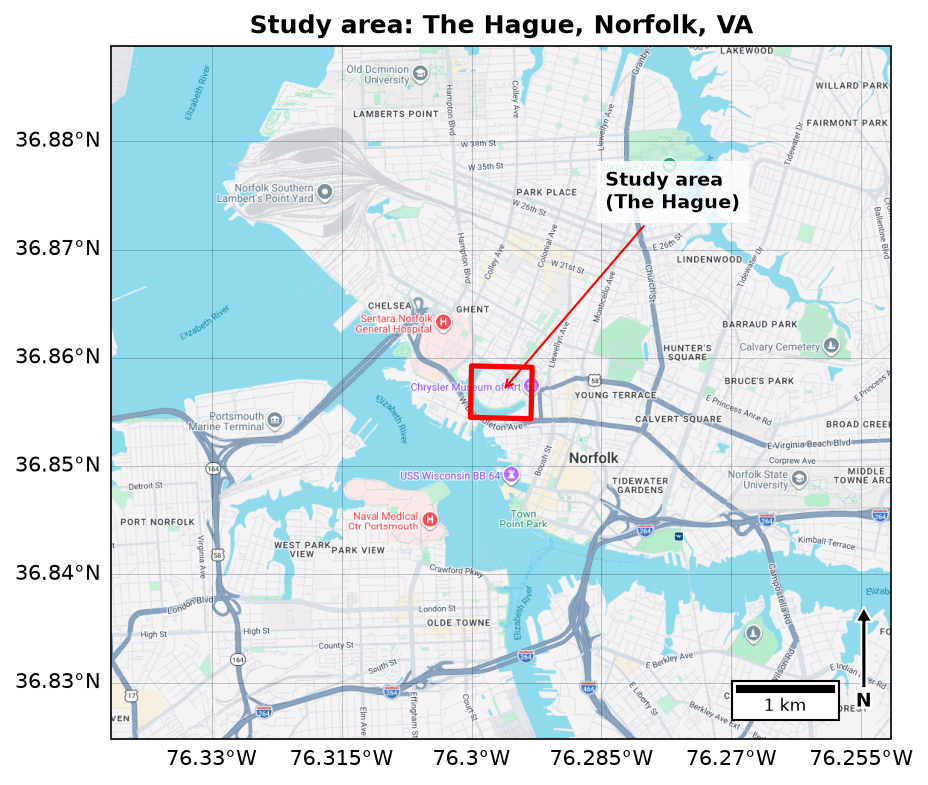

In [15]:
# ---------------------------------------------------------------------
# 01.1 (Step B) — Locator map: where the study area is (street-map tiles via cartopy)
# ---------------------------------------------------------------------
print("Map: location of the study area (Imagery_dry extent) in Norfolk, VA")
aoi_ll_geom = AOI.to_crs(epsg=4326).geometry.iloc[0]
lon_c, lat_c = aoi_ll_geom.centroid.x, aoi_ll_geom.centroid.y
WM_PER_M = 1 / math.cos(math.radians(lat_c))        # web-mercator units per real metre at this latitude


def web_map(extent_ll, style, with_tiles, zoom, figsize=(7, 6)):
    """Axes in web-mercator with optional Google map tiles (style 'street' or 'satellite')."""
    tiler = cimgt.GoogleTiles(style=style)
    fig = plt.figure(figsize=figsize, dpi=FIG_DPI)
    ax = plt.axes(projection=tiler.crs)
    ax.set_extent(extent_ll, crs=ccrs.PlateCarree())
    if with_tiles:
        ax.add_image(tiler, zoom)
    return fig, ax


def finish_web_map(ax, title):
    """Lon/lat grid lines (thin, semi-transparent black, on top), north arrow and scale bar."""
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color="black", alpha=0.25, zorder=20)
    gl.top_labels = gl.right_labels = False
    ax.set_title(title, fontweight="bold")
    add_north_and_scale(ax, WM_PER_M)


def build_web_map(draw, extent_ll, style, zoom, title):
    """Draw a web map with tiles; if the tiles cannot be fetched (no internet), redraw it without them."""
    if ccrs is None:
        print("[info] cartopy not installed -- web map skipped"); return None
    for with_tiles in ((True, False) if SHOW_WEB_BASEMAP else (False,)):
        try:
            fig, ax = web_map(extent_ll, style, with_tiles, zoom)
            draw(ax)
            finish_web_map(ax, title)
            fig.canvas.draw()                      # tiles are fetched here, so a failure is caught
            return fig
        except Exception as e:
            plt.close("all")
            print(f"[info] map tiles skipped ({type(e).__name__}); drawing without them")
    return None


def _draw_locator(ax):
    ax.add_geometries([aoi_ll_geom], crs=ccrs.PlateCarree(), facecolor="none", edgecolor="red", linewidth=2.5, zorder=5)
    tr = ccrs.PlateCarree()._as_mpl_transform(ax)
    ax.annotate("Study area\n(The Hague)", xy=(lon_c, lat_c), xytext=(lon_c + 0.012, lat_c + 0.017), xycoords=tr,
                textcoords=tr, fontsize=9, fontweight="bold", arrowprops=dict(arrowstyle="->", color="red"),
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"), zorder=6)


fig = build_web_map(_draw_locator, [lon_c - 0.045, lon_c + 0.045, lat_c - 0.032, lat_c + 0.032], "street", 14,
                    "Study area: The Hague, Norfolk, VA")
if fig is not None:
    save_fig(fig, 1, "StudyAreaLocator", 1, maps=True)
    plt.show()

**What the map shows.** The study area (red box, about 0.6 × 0.5 km) sits in central Norfolk on the Hague, a
small tidal inlet of the Elizabeth River at the southern edge of the Ghent neighborhood, next to the Chrysler Museum
of Art. The inlet connects directly to tidal water, which is why the streets around it flood at high tide.

### 01.2 Drone imagery (`Imagery_dry`): primary data

The full image is 31,205 × 26,380 pixels × 3 bands, about 2.5 GB uncompressed. For full-site maps and RGB statistics,
the notebook builds a **downsampled imagery preview with 0.32 m pixels** (each preview pixel covers 16 × 16 of the
original 0.02 m pixels). It comes from the service's 0.32 m tile level (~70 tiles), resampled onto the snapped grid.
Zoomed maps use finer `ZOOM_IMAGERY_RES_M` pixels (0.08 m by default). The 0.32 m-pixel preview is cached in
`OUT_DATA_NB00_Sec01`.

The flight did not cover the whole rectangle. It followed the streets around the inlet, so the image is a C-shaped
corridor (Mowbray Arch and its side streets). Pixels outside the corridor are no-data by design.

In [16]:
# ---------------------------------------------------------------------
# 01.2 (Step A) — Build (or reuse) the 0.32 m imagery preview on the snapped grid
# ---------------------------------------------------------------------
t0 = time.time()
OUT01 = clean_dir(1)
PF = IMAGERY_PREVIEW_FACTOR
P_RES = REF_RES * PF
P_W, P_H = math.ceil(REF_W / PF), math.ceil(REF_H / PF)
P_T = from_origin(REF_X0, REF_Y0, P_RES, P_RES)
P_EXTENT = (REF_X0, REF_X0 + P_W * P_RES, REF_Y0 - P_H * P_RES, REF_Y0)
preview_path = OUT01 / "Imagery_dry_Preview_0p32m.tif"
if preview_path.exists() and not FORCE_REBUILD_HEAVY:
    img_source = "cached preview"
else:
    tif = fetch_tiled_raster(URL_IMAGERY, REF_BOUNDS, REF_CRS, API_CACHE / "Imagery_dry_tiles.tif",
                             target_res=P_RES, label="Imagery_dry")
    rgb = np.full((3, P_H, P_W), np.nan, dtype="float32")
    with rasterio.open(tif) as s:
        reproject(s.read([1, 2, 3]), rgb, src_transform=s.transform, src_crs=s.crs, dst_transform=P_T,
                  dst_crs=REF_CRS.to_wkt(), resampling=Resampling.bilinear, src_nodata=np.nan, dst_nodata=np.nan)
    # 8-bit RGB with 0 = no data (the imagery's own minimum value is 1).
    write_tif(np.where(np.isfinite(rgb), np.clip(np.round(rgb), 1, 255), 0).astype("uint8"), preview_path, P_T, nodata=0)
    img_source = "imagery service tiles (resampled)"
with rasterio.open(preview_path) as s:
    rgb_u8 = s.read()
img_valid = rgb_u8.max(axis=0) > 0
IMG_DISPLAY = np.dstack([rgb_u8.transpose(1, 2, 0), (img_valid * 255).astype("uint8")])   # RGBA for imshow
print(f"[01.2] downsampled imagery preview ({P_RES:.2f} m pixels) from {img_source}: {P_W} x {P_H} px ({time.time() - t0:.1f} s)")

[01.2] downsampled imagery preview (0.32 m pixels) from cached preview: 1951 x 1649 px (0.0 s)


In [17]:
# ---------------------------------------------------------------------
# 01.2 (Step B) — Q1-Q3: size, data type and missing data of the imagery
# ---------------------------------------------------------------------
print(f"Q1) Size: {REF_W:,} columns x {REF_H:,} rows x 3 bands = {REF_W * REF_H:,} pixels per band "
      f"({REF_W * REF_H * 3 / 1e9:.2f} GB as 8-bit values), pixel size {REF_RES} m")
print("Q2) Data type: unsigned 8-bit integers (0-255, digital numbers) in 3 bands: Red, Green, Blue")
print("Q2b) Unique values per band (0.32 m-pixel preview): "
      + ", ".join(f"{b} {len(np.unique(rgb_u8[i][img_valid]))}" for i, b in enumerate(["Red", "Green", "Blue"])))
print(f"Q3) Missing data: {100 * (1 - img_valid.mean()):.2f} % of the rectangular extent has no imagery (no-data pixels "
      f"in the 0.32 m-pixel preview). These lie outside the flight footprint, a corridor along the streets around the "
      f"inlet, so they are not gaps; imagery covers {img_valid.sum() * P_RES ** 2:,.0f} m2")
band_stats = pd.DataFrame({b: nice_stats(rgb_u8[i][img_valid], b, "DN") for i, b in enumerate(["Red", "Green", "Blue"])}).T
print("\nDescriptive statistics of the 0.32 m-pixel preview (digital numbers, 0-255):")
display(band_stats.round(2))
register("Drone imagery (Imagery_dry)", "raster (RGB)", "imagery service (tiles)", REF_CRS, f"{REF_RES} m", REF_BOUNDS,
         f"{REF_W * REF_H:,} px x 3")

Q1) Size: 31,205 columns x 26,380 rows x 3 bands = 823,187,900 pixels per band (2.47 GB as 8-bit values), pixel size 0.02 m
Q2) Data type: unsigned 8-bit integers (0-255, digital numbers) in 3 bands: Red, Green, Blue
Q2b) Unique values per band (0.32 m-pixel preview): Red 256, Green 256, Blue 256
Q3) Missing data: 82.94 % of the rectangular extent has no imagery (no-data pixels in the 0.32 m-pixel preview). These lie outside the flight footprint, a corridor along the streets around the inlet, so they are not gaps; imagery covers 56,203 m2

Descriptive statistics of the 0.32 m-pixel preview (digital numbers, 0-255):


,count,mean,std,min,25%,50% (median),75%,max,IQR,skewness
Red,548859.0,113.13,61.20,0.0,58.0,111.0,163.0,255.0,105.0,0.16
Green,548859.0,113.93,55.06,0.0,65.0,118.0,155.0,255.0,90.0,0.07
Blue,548859.0,91.55,56.06,0.0,46.0,75.0,140.0,255.0,94.0,0.49


Map: drone imagery (full site)


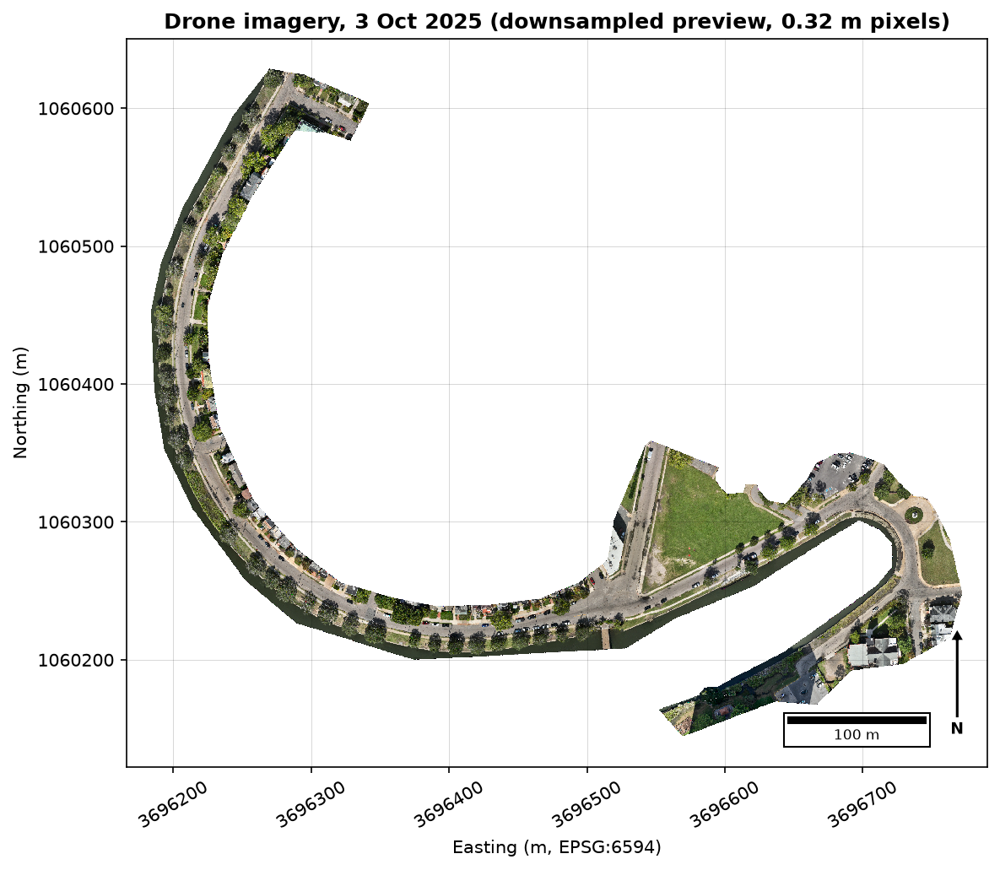

In [18]:
# ---------------------------------------------------------------------
# 01.2 (Step C) — Imagery helpers for the maps (full-site preview and zoomed extents) + full-site map
# ---------------------------------------------------------------------
_zoom_cache = {}


def get_zoom_imagery(ext):
    """Imagery for a zoom extent at ZOOM_IMAGERY_RES_M, from the service tiles (cached), resampled onto a grid snapped
    to the imagery grid. Returns (RGBA uint8 array, imshow extent)."""
    key = tuple(round(ext[k], 2) for k in ("left", "right", "bottom", "top"))
    if key in _zoom_cache:
        return _zoom_cache[key]
    zr = ZOOM_IMAGERY_RES_M
    c0 = math.floor((ext["left"] - REF_X0) / zr); c1 = math.ceil((ext["right"] - REF_X0) / zr)
    r0 = math.floor((REF_Y0 - ext["top"]) / zr); r1 = math.ceil((REF_Y0 - ext["bottom"]) / zr)
    zt = from_origin(REF_X0 + c0 * zr, REF_Y0 - r0 * zr, zr, zr)
    zext = (REF_X0 + c0 * zr, REF_X0 + c1 * zr, REF_Y0 - r1 * zr, REF_Y0 - r0 * zr)
    tif = fetch_tiled_raster(URL_IMAGERY, (zext[0], zext[2], zext[1], zext[3]), REF_CRS,
                             API_CACHE / f"Imagery_zoom_{int(zext[0])}_{int(zext[2])}_{zr:g}m.tif".replace("0.", "0p"),
                             target_res=zr, label="Imagery zoom")
    arr = np.full((3, r1 - r0, c1 - c0), np.nan, dtype="float32")
    with rasterio.open(tif) as s:
        reproject(s.read([1, 2, 3]), arr, src_transform=s.transform, src_crs=s.crs, dst_transform=zt,
                  dst_crs=REF_CRS.to_wkt(), resampling=Resampling.bilinear, src_nodata=np.nan, dst_nodata=np.nan)
    valid = np.isfinite(arr).all(axis=0)
    rgba = np.dstack([np.nan_to_num(arr).clip(0, 255).astype("uint8").transpose(1, 2, 0), (valid * 255).astype("uint8")])
    _zoom_cache[key] = (rgba, zext)
    return _zoom_cache[key]


def draw_imagery(ax, ext=None, alpha=1.0):
    """Imagery as the bottom map layer: the downsampled 0.32 m-pixel preview (ext=None) or a zoom extent."""
    if ext is None:
        ax.imshow(IMG_DISPLAY, extent=P_EXTENT, interpolation="none", alpha=alpha, zorder=0)
        ax.set_xlim(P_EXTENT[0], P_EXTENT[1]); ax.set_ylim(P_EXTENT[2], P_EXTENT[3])
    else:
        rgba, zext = get_zoom_imagery(ext)
        ax.imshow(rgba, extent=zext, interpolation="none", alpha=alpha, zorder=0)
        set_extent(ax, ext)


print("Map: drone imagery (full site)")
fig, ax = plt.subplots(figsize=(8, 7), dpi=FIG_DPI)
draw_imagery(ax)
map_axes(ax, f"Drone imagery, 3 Oct 2025 (downsampled preview, {P_RES:.2f} m pixels)")
plt.tight_layout()
save_fig(fig, 2, "DroneImagery", 1, maps=True)
plt.show()

**What the map shows.** The imagery covers ≈ 56,200 m², about 17 % of the rectangular extent. This is the 82.9 %
"missing" in Q3: the outside of the corridor, not holes in the image. The corridor follows Mowbray Arch along the
west and south shore of the inlet, the triangular field and Botetourt St at the south end, and the loop at the east
end. Inside the corridor the image is complete. The RGB statistics above mix pavement, trees, lawns, roofs and water;
05.1 separates pavement from everything else.

### 01.3 Drone DEM: primary data

Elevations in metres above **NAVD88** (vertical datum EPSG:5703) at 0.5 m. The service's tile grid starts exactly at
the DEM's own corner, so the downloaded tiles (00.1 Step B) reproduce the original pixels.

In [19]:
# ---------------------------------------------------------------------
# 01.3 (Step A) — Q1-Q3 of the drone DEM (as downloaded, before snapping)
# ---------------------------------------------------------------------
dm = raster_meta(dem_raw_path)
with rasterio.open(dem_raw_path) as s:
    dem_raw = s.read(1, masked=True).astype("float32").filled(np.nan)
dem_raw[~np.isfinite(dem_raw)] = np.nan
DEM_EXTENT = (dm["bounds"][0], dm["bounds"][2], dm["bounds"][1], dm["bounds"][3])
print(f"Q1) Size: {dm['width']} columns x {dm['height']} rows = {dm['width'] * dm['height']:,} cells of "
      f"{dm['res_x']:g} x {dm['res_y']:g} m ({dm['bands']} band); CRS {dm['crs'].name}")
print(f"Q2) Data type: {dm['dtype']} (continuous elevation, m NAVD88)")
print(f"Q2b) Unique values: {len(np.unique(dem_raw[np.isfinite(dem_raw)])):,} distinct elevations")
print(f"Q3) Missing data: {int(np.isnan(dem_raw).sum()):,} no-data cells ({100 * np.isnan(dem_raw).mean():.1f} % of its "
      f"rectangular grid). Like the imagery, the DEM covers only the flight corridor, so these cells are outside the "
      f"survey, not gaps; valid area {int(np.isfinite(dem_raw).sum()) * dm['res_x'] * dm['res_y']:,.0f} m2")
display(nice_stats(dem_raw, "DEM elevation", "m NAVD88").to_frame().T.round(3))
register("Drone DEM", "raster (elevation)", "DEM service (tiles)", dm["crs"], f"{dm['res_x']:g} m", dm["bounds"],
         f"{dm['width'] * dm['height']:,} cells")

Q1) Size: 1196 columns x 980 rows = 1,172,080 cells of 0.5 x 0.5 m (1 band); CRS NAD83(2011) / Virginia South
Q2) Data type: float32 (continuous elevation, m NAVD88)
Q2b) Unique values: 259,133 distinct elevations
Q3) Missing data: 885,224 no-data cells (75.5 % of its rectangular grid). Like the imagery, the DEM covers only the flight corridor, so these cells are outside the survey, not gaps; valid area 71,714 m2


,count,mean,std,min,25%,50% (median),75%,max,IQR,skewness
DEM elevation (m NAVD88),286856.0,1.325,0.689,-0.094,0.892,1.282,1.681,3.734,0.789,0.374


Map: drone DEM (m NAVD88)


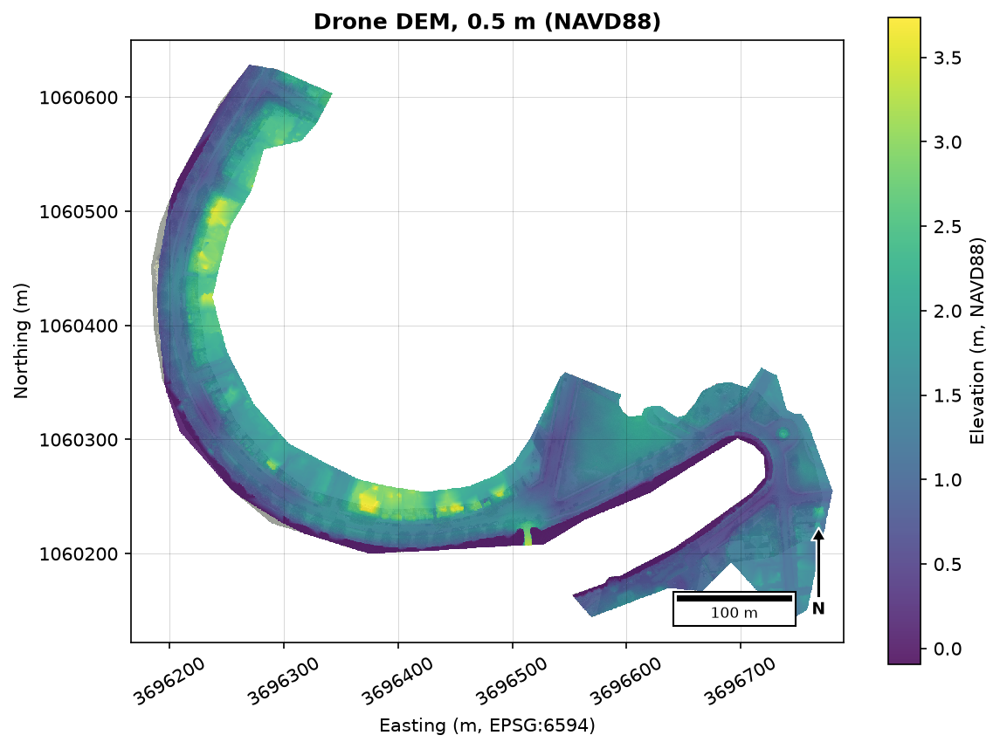

In [20]:
# ---------------------------------------------------------------------
# 01.3 (Step B) — Map of the drone DEM over the imagery
# ---------------------------------------------------------------------
print("Map: drone DEM (m NAVD88)")
fig, ax = plt.subplots(figsize=(8, 7), dpi=FIG_DPI)
draw_imagery(ax, alpha=0.5)
im = ax.imshow(dem_raw, extent=DEM_EXTENT, cmap=CMAP_ELEV, interpolation="none", alpha=0.85, zorder=1)
fig.colorbar(im, ax=ax, shrink=0.75, label="Elevation (m, NAVD88)")
map_axes(ax, "Drone DEM, 0.5 m (NAVD88)")
plt.tight_layout()
save_fig(fig, 3, "DroneDEM", 1, maps=True)
plt.show()

**What the map shows.**

- **Range and coverage.** The DEM ranges from −0.09 to 3.73 m NAVD88, with a median of 1.28 m. Its 286,856 valid
  0.5 m cells (≈ 71,700 m²) cover the same corridor as the imagery and reach a little further over the water's edge
  (grey fringe on the west side). The 75.5 % no-data in Q3 is the area outside that corridor.
- **Lowest ground (< 0.5 m).** Along the shoreline, in Botetourt St along the west side of the field, and
  along the southeastern street at the east end.
- **Highest values (up to 3.7 m).** On the inland side of the south and west arc, away from the water.

### 01.4 NOAA VDatum conversion surface (MHHW in NAVD88)

**What it is.** Each pixel holds the elevation of Mean Higher High Water (MHHW, the average of each day's higher
high tide; NOAA CO-OPS, 2022) expressed in NAVD88 metres. Its pixels are 0.00045° (about 40 m E–W × 50 m N–S), far coarser than the
study area's features, so a padded box (`VDATUM_PAD_M`) is downloaded and resampled bilinearly. Around Norfolk the
values are small and positive (≈ 0.386 m here), because MHHW sits a few tenths of a metre above NAVD88.

**Why it is needed.** The drone DEM is referenced to the land survey datum NAVD88. Ezer's (2022) flood equation needs
each cell's height above **MHHW**, the tidal datum the Sewells Point flood statistics are measured against. Subtracting
this surface from the DEM (`F = DEM − VDatum`, 00.1 Step E) converts every elevation to height above an ordinary high
tide, so the flood-days model can be applied.

The map draws the surface semi-transparent over Google satellite imagery.

In [21]:
# ---------------------------------------------------------------------
# 01.4 (Step A) — Q1-Q3 of the VDatum download
# ---------------------------------------------------------------------
vm = raster_meta(vdatum_path)
with rasterio.open(vdatum_path) as s:
    vdatum_raw = s.read(1).astype("float32")
vdatum_raw[~np.isfinite(vdatum_raw) | (np.abs(vdatum_raw) > 100)] = np.nan
_unit = vm["crs"].axis_info[0].unit_name
_res_m = vm["res_x"] * (111_320 * math.cos(math.radians(lat_c)) if _unit.startswith("deg") else 1)   # E-W size
_res_my = vm["res_y"] * (110_950 if _unit.startswith("deg") else 1)                                # N-S size
VDATUM_RES_LABEL = (f"{vm['res_x']:g} {_unit} (~{_res_m:.0f} m E-W x {_res_my:.0f} m N-S)" if _unit.startswith("deg")
                    else f"{vm['res_x']:g} m")
print(f"Q1) Size of the downloaded box: {vm['width']} x {vm['height']} = {vm['width'] * vm['height']} pixels of "
      f"{VDATUM_RES_LABEL} in {vm['crs'].name}")
print(f"Q2) Data type: {vm['dtype']} (continuous, m NAVD88)")
print(f"Q2b) Unique values: {len(np.unique(vdatum_raw[np.isfinite(vdatum_raw)]))} distinct MHHW values in the box")
print(f"Q3) Missing data in the box: {int(np.isnan(vdatum_raw).sum())} pixels ({100 * np.isnan(vdatum_raw).mean():.1f} %)")
display(nice_stats(vdatum_raw, "MHHW in NAVD88", "m").to_frame().T.round(4))
register("NOAA VDatum (MHHW in NAVD88)", "raster (datum surface)", "VDatum service (tiles)", vm["crs"],
         VDATUM_RES_LABEL, vm["bounds"], f"{vm['width'] * vm['height']} px")

Q1) Size of the downloaded box: 93 x 73 = 6789 pixels of 0.000449158 degree (~40 m E-W x 50 m N-S) in WGS 84
Q2) Data type: float32 (continuous, m NAVD88)
Q2b) Unique values: 269 distinct MHHW values in the box
Q3) Missing data in the box: 0 pixels (0.0 %)


,count,mean,std,min,25%,50% (median),75%,max,IQR,skewness
MHHW in NAVD88 (m),6789.0,0.3854,0.0042,0.3713,0.3826,0.3859,0.3877,0.3941,0.0051,-0.1256


Map: VDatum surface over satellite imagery (red outline = study area)


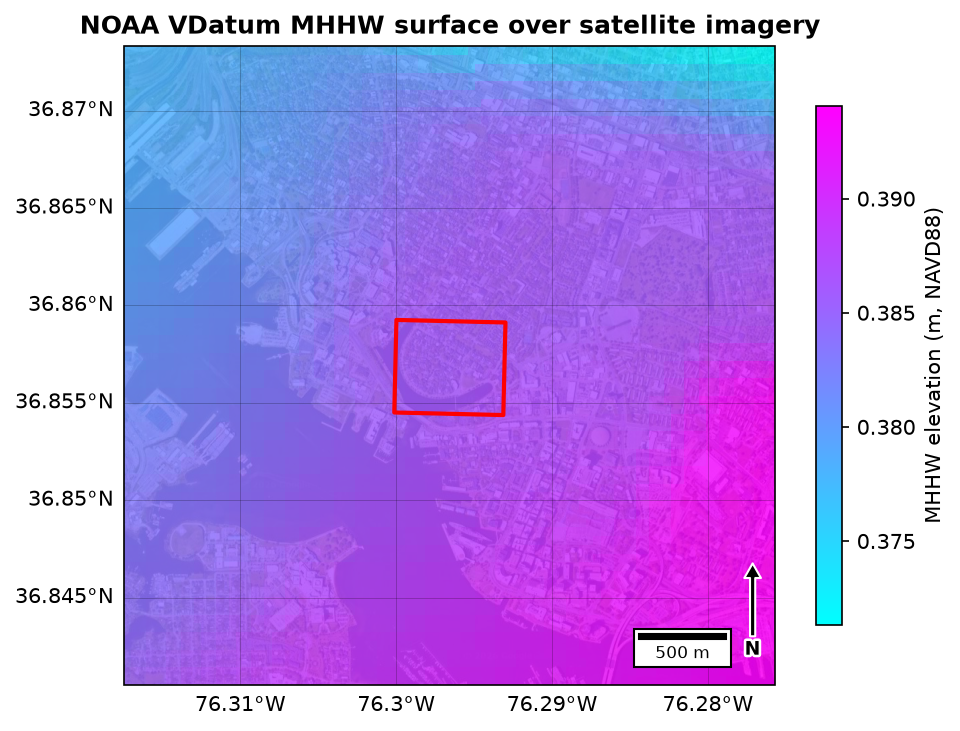

In [22]:
# ---------------------------------------------------------------------
# 01.4 (Step B) — Map: VDatum surface (semi-transparent) over Google satellite imagery
# ---------------------------------------------------------------------
print("Map: VDatum surface over satellite imagery (red outline = study area)")
_vb_ll = transform_bounds(vm["crs"], "EPSG:4326", *vm["bounds"], densify_pts=21)
_vnorm = mcolors.Normalize(np.nanmin(vdatum_raw), max(np.nanmax(vdatum_raw), np.nanmin(vdatum_raw) + 1e-3))


def _draw_vdatum(ax):
    ax.imshow(vdatum_raw, extent=(vm["bounds"][0], vm["bounds"][2], vm["bounds"][1], vm["bounds"][3]),
              transform=ccrs.epsg(vm["crs"].to_epsg()) if not _unit.startswith("deg") else ccrs.PlateCarree(),
              cmap=CMAP_VDATUM, norm=_vnorm, alpha=VDATUM_ALPHA, interpolation="nearest", zorder=2)
    ax.add_geometries([aoi_ll_geom], crs=ccrs.PlateCarree(), facecolor="none", edgecolor="red", linewidth=2, zorder=5)
    plt.colorbar(plt.cm.ScalarMappable(norm=_vnorm, cmap=CMAP_VDATUM), ax=ax, shrink=0.75,
                 label="MHHW elevation (m, NAVD88)")


fig = build_web_map(_draw_vdatum, [_vb_ll[0], _vb_ll[2], _vb_ll[1], _vb_ll[3]], "satellite", 15,
                    "NOAA VDatum MHHW surface over satellite imagery")
if fig is not None:
    save_fig(fig, 4, "VDatumSurface", 1, maps=True)
    plt.show()

**What the map shows.**

- **Downloaded box.** The 93 × 73-pixel box holds MHHW values from 0.371 to 0.394 m NAVD88, rising from north
  (cyan) to southeast (magenta). Nothing is missing.
- **Study area.** Over the red outline the surface changes by only 1.1 mm, from 0.3859 to 0.3870 m. MHHW is
  therefore effectively a single number, ≈ 0.386 m above NAVD88, for the whole site. Subtracting it shifts every
  elevation by the same amount: it sets the level of flood exposure, not its pattern.

### 01.5 Vector datasets

The vector layers that describe the road network, the non-road paved surfaces, and the open water.

#### 01.5.1 Road centerlines: VGIN RCL with VDOT traffic, plus `Custom_AddRCL`

VGIN layer 5 ("< 50,000", all other centerlines) is downloaded for the padded study area (VGIN, 2024). `MTFCC` is the
Census MAF/TIGER feature class code, i.e. the road type (U.S. Census Bureau, 2026).

**Attribute of interest: `VDOT_AADT`**, the VDOT Annual Average Daily Traffic in **vehicles per day** (both directions
combined). It is the traffic control in the analysis. A value of 0 or blank means no count.

`Custom_AddRCL` adds hand-drawn centerlines for minor roads and parking-lot lanes that VGIN does not include
(Carpenter, 2026). They have no traffic counts.

In [23]:
# ---------------------------------------------------------------------
# 01.5.1 (Step A) — VGIN Road Centerlines (with VDOT_AADT): download and Q1-Q3
# ---------------------------------------------------------------------
# MTFCC codes -> descriptions (Census MTFCC road classes; VGIN splits S1200 into S1200PRI / S1200LOC)
MTFCC_DESC = {"S1100": "Primary roads", "S1200": "Secondary roads", "S1400": "Local roads", "S1500": "4WD trails",
              "S1200PRI": "Secondary roads (VDOT primary route)", "S1200LOC": "Secondary roads (local route)",
              "S1630": "Ramps", "S1640": "Service drives (highway frontage)", "S1710": "Walkways / pedestrian trails",
              "S1720": "Stairways", "S1730": "Alleys", "S1740": "Private drives (service vehicles)",
              "S1780": "Parking lot roads", "S1820": "Bike paths / trails", "S1830": "Bridle paths",
              "S2000": "Road medians", "S9999": "Driveways"}
rcl_raw = query_features(URL_VGIN_RCL, VEC_BBOX_LL, "VGIN_RCL_layer5")
rcl_tbl = describe_gdf(rcl_raw, "VGIN RCL (layer 5)")
_rcl_in = rcl_raw[rcl_raw.to_crs(REF_CRS).intersects(aoi_geom)] if len(rcl_raw) else rcl_raw
if "VDOT_AADT" in rcl_raw.columns:
    _a = pd.to_numeric(_rcl_in["VDOT_AADT"], errors="coerce")
    print(f"Q3b) VDOT_AADT missing in the study area: {int(_a.isna().sum()) + int((_a == 0).sum())} of {len(_a)} "
          f"segments ({int(_a.isna().sum())} blank, {int((_a == 0).sum())} zero = no count); "
          f"{int((_a > 0).sum())} segments carry a count (vehicles/day)")
else:
    print("Q3b) VDOT_AADT field not returned by the service -- every segment is missing a traffic count")
display(rcl_tbl)
if "MTFCC" in rcl_raw.columns:
    print("Road classes (MTFCC):")
    display(rcl_raw["MTFCC"].map(lambda c: f"{c} - {MTFCC_DESC.get(c, '?')}").value_counts().to_frame("# segments"))
if len(rcl_raw):
    register("VGIN RCL (layer 5)", "vector (lines)", "VGIN REST API", rcl_raw.crs, "vector", rcl_raw.total_bounds,
             f"{len(rcl_raw)} lines")

[api] VGIN_RCL_layer5: using cached download VGIN_RCL_layer5.gpkg
===== VGIN RCL (layer 5) =====
Q1) Size: 102 features x 58 attribute columns = 5,916 attribute values; geometry types {'LineString': 102}; CRS WGS 84
Q2) Data types: {'str': 32, 'int64': 10, 'float64': 9, 'datetime64[ms]': 4, 'object': 3} (column count per type)
Q2b) Unique values per column: Shape__Length 102, OBJECTID 102, RCL_ID 102, LOCAL_ID 56, VDOT_ID 99, MFIPS 1, GEO_ET 5, GEO_EFFDT 0, GEO_SRC 1, GEO_ED 5, ADD_LF 22, ADD_LT 24, ADD_RF 39, ADD_RT 50, ADD_FORMAT 1, ADD_SRC 1, ADD_ED 5, ST_PREMD 1, ST_PREDIR 2, ST_NAME 27, ST_SUFFIX 9, ST_SUFFDIR 1, ST_PSTMD 1, ST_FULL 30, ST_SRC 1, ST_ED 6, MTFCC 3, SEG_TYPE 1, SPEED_MPH 4, DUAL_CW 1, ONE_WAY 2, REVERSIBLE 1, SEG_EXISTS 1, FIPS_L 1, FIPS_R 1, MSAG_ESNL 1, MSAG_ESNR 1, MSAG_COMML 1, MSAG_COMMR 1, ZIP_L 2, ZIP_R 2, PO_L 1, PO_R 1, STATE_L 1, STATE_R 1, VDOT_RNAM 33, VDOT_RNUM 2, VDOT_RTYP 2, VDOT_RCAT 2, VDOT_FC 4, VDOT_PTYP 1, VDOT_SPD 0, VDOT_RST 0, VDOT_LC 3, VDOT_

,dtype,missing (NaN),% missing,# unique
Shape__Length,float64,0,0.0,102
OBJECTID,int64,0,0.0,102
RCL_ID,int64,0,0.0,102
LOCAL_ID,float64,44,43.1,56
VDOT_ID,float64,1,1.0,99
MFIPS,str,0,0.0,1
GEO_ET,float64,89,87.3,5
GEO_EFFDT,datetime64[ms],102,100.0,0
GEO_SRC,str,0,0.0,1
GEO_ED,datetime64[ms],90,88.2,5


Road classes (MTFCC):


,# segments
MTFCC,
S1400 - Local roads,85
S1200LOC - Secondary roads (local route),10
S1200PRI - Secondary roads (VDOT primary route),7


In [24]:
# ---------------------------------------------------------------------
# 01.5.1 (Step B) — Custom_AddRCL (hand-drawn additional centerlines): read and Q1-Q3
# ---------------------------------------------------------------------
addrcl_raw = gpd.read_file(addrcl_path)
_add_tbl = describe_gdf(addrcl_raw, "Custom_AddRCL")
_n_add_aadt = int((pd.to_numeric(addrcl_raw["VDOT_AADT"], errors="coerce") > 0).sum()) if "VDOT_AADT" in addrcl_raw.columns else 0
print(f"Q3b) VDOT_AADT missing: {len(addrcl_raw) - _n_add_aadt} of {len(addrcl_raw)} segments (expected: all -- "
      "hand-drawn lines carry no VDOT traffic count)")
display(_add_tbl)
print(f"    total length: {addrcl_raw.to_crs(REF_CRS).length.sum():,.0f} m")
register("Custom_AddRCL", "vector (lines)", "custom file", addrcl_raw.crs, "vector", addrcl_raw.total_bounds,
         f"{len(addrcl_raw)} lines")

===== Custom_AddRCL =====
Q1) Size: 9 features x 1 attribute columns = 9 attribute values; geometry types {'LineString': 9}; CRS NAD83(2011) / Virginia South + NAVD88 height
Q2) Data types: {'int32': 1} (column count per type)
Q2b) Unique values per column: Id 1
Q3) Missing data: 0 missing (NaN) attribute values in 0 column(s); 0 empty/missing geometries; 0 invalid geometries
Q3b) VDOT_AADT missing: 9 of 9 segments (expected: all -- hand-drawn lines carry no VDOT traffic count)


,dtype,missing (NaN),% missing,# unique
Id,int32,0,0.0,1


    total length: 507 m


**What the tables show.**

- **VGIN download.** 102 segments came back for the padded query box. 85 of them, all local roads (`MTFCC` S1400),
  are inside the study area.
- **Traffic counts.** All 85 carry a VDOT traffic count (Q3b: none missing). The counts range from 220 to
  9,500 vehicles/day.
- **Missing values.** The 1,258 missing attribute values sit in 24 administrative columns, such as the edit dates,
  `VDOT_SPD`, `VDOT_RST` and `SHAPE_Leng`, none of which the project uses.
- **Custom_AddRCL.** Its 9 lines (507 m) have only an `Id` field, so their AADT is missing by design. They mark
  driveable surface that VGIN does not map.

#### 01.5.2 Sidewalks & driveways: City of Norfolk layers + `Custom_Sidewalk`

These layers were used to build the **pavement mask** and to mark the **non-road paved areas** (sidewalks and
driveways) in the study area. The mask's allowed area was the road-centerline buffer plus the sidewalk/driveway
surface (01.6.1). In 03.3, pavement cells inside these polygons are labeled `Sidewalk/Driveway` and every other
pavement cell `Road`.

- **City of Norfolk Sidewalks** (City of Norfolk, 2022): lines from 2006 aerials. Used as the guide for hand-drawing
  `Custom_Sidewalk`; shown here for comparison only.
- **`Custom_Sidewalk_2025Hague`** (Carpenter, 2026): sidewalk/driveway *surface polygons* digitized on the 2025
  imagery.
- **City of Norfolk Driveways** (City of Norfolk Department of Public Works, 2022): polygons from 2006/2008 aerials.

In [25]:
# ---------------------------------------------------------------------
# 01.5.2 (Step A) — Sidewalks: City of Norfolk sidewalk lines (API) and Custom_Sidewalk polygons; Q1-Q3
# ---------------------------------------------------------------------
sidewalk_city_raw = query_features(URL_NORFOLK_SIDEWALK, VEC_BBOX_LL, "Norfolk_Sidewalk")
display(describe_gdf(sidewalk_city_raw, "City of Norfolk Sidewalks"))
if len(sidewalk_city_raw):
    register("Norfolk Sidewalks", "vector (lines)", "City of Norfolk REST API", sidewalk_city_raw.crs, "vector",
             sidewalk_city_raw.total_bounds, f"{len(sidewalk_city_raw)} lines")
sidewalk_raw = gpd.read_file(sidewalk_path)
display(describe_gdf(sidewalk_raw, "Custom_Sidewalk"))
print(f"    total custom sidewalk/driveway surface: {sidewalk_raw.to_crs(REF_CRS).area.sum():,.0f} m2")
register("Custom_Sidewalk", "vector (polygons)", "custom file", sidewalk_raw.crs, "vector", sidewalk_raw.total_bounds,
         f"{len(sidewalk_raw)} polygons")

[api] Norfolk_Sidewalk: using cached download Norfolk_Sidewalk.gpkg
===== City of Norfolk Sidewalks =====
Q1) Size: 274 features x 8 attribute columns = 2,192 attribute values; geometry types {'LineString': 274}; CRS WGS 84
Q2) Data types: {'float64': 3, 'object': 2, 'datetime64[ms]': 2, 'int64': 1} (column count per type)
Q2b) Unique values per column: OBJECTID 274, FTR_CODE 2, YEAR 3, created_user 0, created_date 0, last_edited_user 0, last_edited_date 0, Shape__Length 274
Q3) Missing data: 1,104 missing (NaN) attribute values in 6 column(s); 0 empty/missing geometries; 0 invalid geometries


,dtype,missing (NaN),% missing,# unique
OBJECTID,int64,0,0.0,274
FTR_CODE,float64,4,1.5,2
YEAR,float64,4,1.5,3
created_user,object,274,100.0,0
created_date,datetime64[ms],274,100.0,0
last_edited_user,object,274,100.0,0
last_edited_date,datetime64[ms],274,100.0,0
Shape__Length,float64,0,0.0,274


===== Custom_Sidewalk =====
Q1) Size: 14 features x 1 attribute columns = 14 attribute values; geometry types {'Polygon': 14}; CRS NAD83(2011) / Virginia South + NAVD88 height
Q2) Data types: {'int32': 1} (column count per type)
Q2b) Unique values per column: Id 1
Q3) Missing data: 0 missing (NaN) attribute values in 0 column(s); 0 empty/missing geometries; 0 invalid geometries


,dtype,missing (NaN),% missing,# unique
Id,int32,0,0.0,1


    total custom sidewalk/driveway surface: 5,295 m2


In [26]:
# ---------------------------------------------------------------------
# 01.5.2 (Step B) — Driveways: City of Norfolk driveway polygons (API); Q1-Q3
# ---------------------------------------------------------------------
driveway_raw = query_features(URL_NORFOLK_DRIVEWAY, VEC_BBOX_LL, "Norfolk_Driveway")
display(describe_gdf(driveway_raw, "City of Norfolk Driveways"))
if len(driveway_raw):
    print(f"    total driveway area inside the study area: {gpd.clip(driveway_raw.to_crs(REF_CRS), aoi_geom).area.sum():,.0f} m2")
    register("Norfolk Driveways", "vector (polygons)", "City of Norfolk REST API", driveway_raw.crs, "vector",
             driveway_raw.total_bounds, f"{len(driveway_raw)} polygons")

[api] Norfolk_Driveway: using cached download Norfolk_Driveway.gpkg
===== City of Norfolk Driveways =====
Q1) Size: 112 features x 9 attribute columns = 1,008 attribute values; geometry types {'Polygon': 112}; CRS WGS 84
Q2) Data types: {'float64': 4, 'object': 2, 'datetime64[ms]': 2, 'int64': 1} (column count per type)
Q2b) Unique values per column: OBJECTID 112, FTR_CODE 1, YEAR 2, created_user 0, created_date 0, last_edited_user 0, last_edited_date 0, Shape__Area 112, Shape__Length 112
Q3) Missing data: 452 missing (NaN) attribute values in 6 column(s); 0 empty/missing geometries; 0 invalid geometries


,dtype,missing (NaN),% missing,# unique
OBJECTID,int64,0,0.0,112
FTR_CODE,float64,2,1.8,1
YEAR,float64,2,1.8,2
created_user,object,112,100.0,0
created_date,datetime64[ms],112,100.0,0
last_edited_user,object,112,100.0,0
last_edited_date,datetime64[ms],112,100.0,0
Shape__Area,float64,0,0.0,112
Shape__Length,float64,0,0.0,112


    total driveway area inside the study area: 6,542 m2


**What the tables show.**

- **City of Norfolk sidewalks.** 274 lines downloaded, 226 of them in the study area. Only 4 lack `FTR_CODE` /
  `YEAR`; the four edit-tracking fields are empty on every feature.
- **City of Norfolk driveways.** 112 polygons downloaded (100 in the study area, 6,542 m²), with the same pattern of
  missing values.
- **`Custom_Sidewalk`.** 14 polygons (5,295 m²) with no missing values or invalid geometries.
- **Combined surface.** Merging the driveways with `Custom_Sidewalk` in 03.1 gives a non-road paved surface of
  11,767 m².

#### 01.5.3 Open-water surface (`WaterSurface_Final`)

**Why it was made.** The drone DEM records the water surface of the Hague inlet as if it were very low ground. Left
in, those cells would show up as the "most flooded" land and would distort any elevation or flood statistic. The
water surface marks them so they are removed from the DEM before the flood-days model (00.1 Steps D–E).

**How it was made** (Carpenter, 2026):

1. The 1 m hydro-corrected HCDEM (Chen, 2023), in which water = 0 m, was cut to the study area.
   Its cells ≤ 0 m were converted to polygons and PAEK-smoothed, because the 1 m shoreline is jagged.
2. Segment Anything Model 3 (Eagle Technology et al., 2026) was run on `Imagery_dry` with the prompt "Water", to
   capture the shoreline at 2 cm detail.
3. The two were merged and dissolved into one polygon.

It is shipped as a file because the public HCDEM service only serves map pictures, not elevation values.

Its single multipolygon has one invalid (self-intersecting) geometry, a common result of dissolving smoothed
polygons. It is repaired with `make_valid` before clipping (00.1 Step D). Open water covers ≈ 61,500 m², about 19 % of
the study area.

In [27]:
# ---------------------------------------------------------------------
# 01.5.3 (Step A) — Q1-Q3 of the water surface (read in 00.1 Step D)
# ---------------------------------------------------------------------
display(describe_gdf(water_raw, "WaterSurface_Final"))
print(f"    water area inside the study area: {water_c.area.sum():,.0f} m2 "
      f"({100 * water_c.area.sum() / AOI_AREA_M2:.1f} % of the extent)")
register("WaterSurface_Final", "vector (polygons)", "custom file", water_raw.crs, "vector", water_raw.total_bounds,
         f"{len(water_raw)} polygon(s)")

===== WaterSurface_Final =====
Q1) Size: 1 features x 3 attribute columns = 3 attribute values; geometry types {'MultiPolygon': 1}; CRS NAD83(2011) / Virginia South + NAVD88 height
Q2) Data types: {'float64': 2, 'int32': 1} (column count per type)
Q2b) Unique values per column: Shape_Leng 1, Shape_Area 1, WaterVal 1
Q3) Missing data: 0 missing (NaN) attribute values in 0 column(s); 0 empty/missing geometries; 1 invalid geometries


,dtype,missing (NaN),% missing,# unique
Shape_Leng,float64,0,0.0,1
Shape_Area,float64,0,0.0,1
WaterVal,int32,0,0.0,1


    water area inside the study area: 61,469 m2 (18.7 % of the extent)


#### 01.5.4 Vector layer maps

Three stacked maps on the downsampled (0.32 m-pixel) imagery preview: (a) road centerlines, (b) sidewalks and driveways, (c) open water. The
year each layer represents is in parentheses.

Maps: vector layers on the 0.32 m-pixel imagery preview


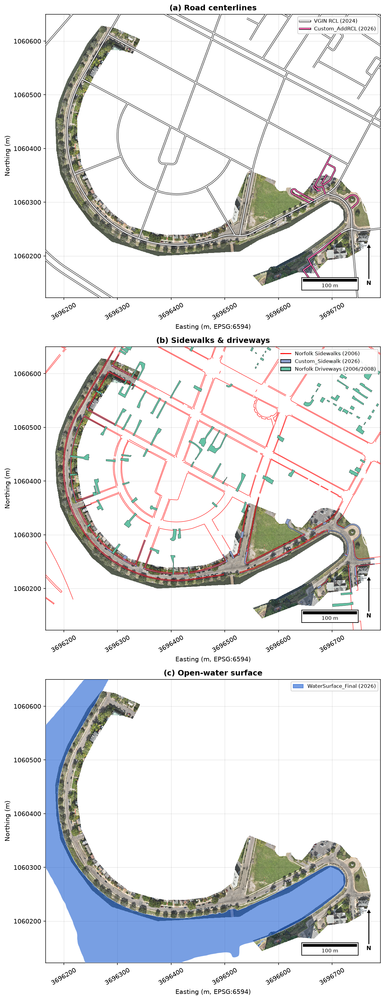

In [28]:
# ---------------------------------------------------------------------
# 01.5.4 (Step A) — Maps of the vector layers (3 rows x 1 column)
# ---------------------------------------------------------------------
rcl_m, add_m = rcl_raw.to_crs(REF_CRS), addrcl_raw.to_crs(REF_CRS)
sw_city_m, sw_m, drv_m = sidewalk_city_raw.to_crs(REF_CRS), sidewalk_raw.to_crs(REF_CRS), driveway_raw.to_crs(REF_CRS)
print("Maps: vector layers on the 0.32 m-pixel imagery preview")
fig, axes = plt.subplots(3, 1, figsize=(9, 22), dpi=FIG_DPI)
for ax in axes:
    draw_imagery(ax, alpha=0.85)
# (a) road centerlines: VGIN white, Custom_AddRCL pink, both with thin black outlines
ax = axes[0]
rcl_m.plot(ax=ax, zorder=3, **outlined(COLOR_VGIN, 1.6))
add_m.plot(ax=ax, zorder=4, **outlined(COLOR_ADDRCL, 1.6))
ax.legend(handles=[mlines.Line2D([], [], **outlined(COLOR_VGIN, 2), label="VGIN RCL (2024)"),
                   mlines.Line2D([], [], **outlined(COLOR_ADDRCL, 2), label="Custom_AddRCL (2026)")],
          loc="upper right", fontsize=8, framealpha=0.9)
# (b) sidewalks & driveways: sidewalk lines (bottom), Custom_Sidewalk, driveways (top)
ax = axes[1]
sw_m.plot(ax=ax, facecolor=COLOR_SIDEWALK_CUSTOM, edgecolor="black", linewidth=0.3, zorder=2)
if len(sw_city_m):
    sw_city_m.plot(ax=ax, color=COLOR_SIDEWALK_CITY, linewidth=0.6, zorder=3)
if len(drv_m):
    drv_m.plot(ax=ax, facecolor=COLOR_DRIVEWAY, edgecolor="black", linewidth=0.3, zorder=4)
ax.legend(handles=[mlines.Line2D([], [], color=COLOR_SIDEWALK_CITY, linewidth=1.5, label="Norfolk Sidewalks (2006)"),
                   mpatches.Patch(facecolor=COLOR_SIDEWALK_CUSTOM, edgecolor="black", label="Custom_Sidewalk (2026)"),
                   mpatches.Patch(facecolor=COLOR_DRIVEWAY, edgecolor="black", label="Norfolk Driveways (2006/2008)")],
          loc="upper right", fontsize=8, framealpha=0.9)
# (c) open water
ax = axes[2]
water_c.plot(ax=ax, facecolor=COLOR_WATER, edgecolor="white", alpha=0.6, linewidth=0.5, zorder=3)
ax.legend(handles=[mpatches.Patch(color=COLOR_WATER, alpha=0.6, label="WaterSurface_Final (2026)")],
          loc="upper right", fontsize=8, framealpha=0.9)
for ax, title in zip(axes, ["(a) Road centerlines", "(b) Sidewalks & driveways", "(c) Open-water surface"]):
    ax.set_xlim(P_EXTENT[0], P_EXTENT[1]); ax.set_ylim(P_EXTENT[2], P_EXTENT[3])   # full-site view
    map_axes(ax, title)
plt.tight_layout()
save_fig(fig, 5, "VectorLayers", 1, maps=True)
plt.show()

**What the maps show.**

- **(a) Road centerlines.** The VGIN centerlines cover the whole street grid of the neighborhood, but the drone
  imaged only the streets along the inlet. `Custom_AddRCL` (pink) adds the parking-lot lanes and minor drives at the
  east end.
- **(b) Sidewalks and driveways.** The City sidewalk lines (2006) and driveway polygons (2006/2008) cover the whole
  neighborhood. `Custom_Sidewalk` (2026, blue-grey) traces the sidewalk surface actually visible in the 2025 imagery
  along the corridor.
- **(c) Open water.** The water surface fills the inlet and meets the imagery along the shoreline. This is the
  water edge removed from the DEM before modelling flood days.

### 01.6 Crack-mapping datasets (custom)

The three custom datasets that measure the response variable. The **road mask** is the pavement each crack density
is measured over, the **crack raster** marks the cracks within it, and the **accuracy points** check the crack raster
against the imagery. All three were made by the author in ArcGIS Pro (Carpenter, 2026).

#### 01.6.1 Pavement (road) mask: `Road_Mask_Final_Shrunk3.tif`

**Why.** Cracks can only be counted where there is pavement. The mask defines that surface and is therefore the
denominator of crack density. It also keeps grass, roofs, cars and shadows from being classified as "cracks".

**How it was made:**

1. **Allowed area.** The road centerlines (VGIN RCL + `Custom_AddRCL`, 01.5.1) were buffered 6 m (square ends,
   mitered corners). The sidewalk/driveway surface (`Custom_Sidewalk` merged with the City driveways, 01.5.2) was
   added to the buffer.
2. **Pavement detection.** Segment Anything Model 3 (Eagle Technology et al., 2026) was run on the full imagery with
   the prompts "Concrete, Impervious Surface, Pavement, Road". Its polygons were clipped to the allowed area, and
   hand-drawn polygons of pavement it missed were added.
3. **Exclusions.** The following were cut out:
   - SAM3 detections of "power line shadow, gravel, shadow", grown 5 cm;
   - hand-drawn lines along shadows and thin features such as power lines and parking-lot paint, buffered 10 cm;
   - hand-drawn lines along sidewalk control-joint grooves, buffered 5 cm, because they look like cracks;
   - hand-drawn exclusion polygons (curb/gutter strips, extra shadow).
4. **Rasterize & shrink.** The final polygon was converted to the 0.02 m imagery grid (a pixel is pavement if its
   centre is inside), then shrunk inward by 3 pixels (6 cm). The shrink removes the edge, where the crack model
   mistakes the hard mask boundary for a crack.

*The hand-drawn include/exclude layers and the SAM3 detection layers are not part of this package.*

In [29]:
# ---------------------------------------------------------------------
# 01.6.1 (Step A) — Road mask: metadata, grid alignment, Q1 and Q2
# ---------------------------------------------------------------------
mm = raster_meta(mask_path)
ox, oy = grid_offset(mm)
mask_snapped = abs(ox - round(ox)) < 1e-3 and abs(oy - round(oy)) < 1e-3 and abs(mm["res_x"] - REF_RES) < 1e-9
print(f"Q1) Size: {mm['width']:,} columns x {mm['height']:,} rows = {mm['width'] * mm['height']:,} pixels of "
      f"{mm['res_x']:g} m; offset from the imagery grid ({ox:.3f}, {oy:.3f}) px -> "
      + ("snapped to the imagery grid" if mask_snapped else "NOT snapped"))
print(f"Q2) Data type: {mm['dtype']} (categorical: {ROAD_MASK_VALUE} = pavement, NoData = {mm['nodata']} elsewhere); "
      f"CRS {mm['crs'].name}")
_z = next(iter(ZOOM_EXTENTS.values()))                         # sample at a street intersection (first zoom extent)
_zx, _zy = (_z["left"] + _z["right"]) / 2, (_z["bottom"] + _z["top"]) / 2


def sample_window(src, size=1000):
    """size x size px window of a raster, centred on the first zoom extent (on pavement)."""
    c, r = (int((_zx - src.bounds.left) / src.res[0]), int((src.bounds.top - _zy) / src.res[1]))
    return Window(min(max(0, c - size // 2), src.width - size), min(max(0, r - size // 2), src.height - size), size, size)


with rasterio.open(mask_path) as _s:
    _mv, _mc = np.unique(_s.read(1, window=sample_window(_s)), return_counts=True)
print(f"Q2b) Unique values (1000 x 1000 px sample at the {next(iter(ZOOM_EXTENTS))} intersection, value: count): "
      f"{dict(zip(_mv.tolist(), _mc.tolist()))}")
print("Q3) Missing data: reported after the pixel counts in 01.6.2 (Step C)")
register("Road mask (Shrunk3)", "raster (custom)", "custom file", mm["crs"], f"{mm['res_x']:g} m", mm["bounds"],
         f"{mm['width'] * mm['height']:,} px")

Q1) Size: 28,664 columns x 22,960 rows = 658,125,440 pixels of 0.02 m; offset from the imagery grid (1645.000, 1189.000) px -> snapped to the imagery grid
Q2) Data type: uint8 (categorical: 1 = pavement, NoData = 0.0 elsewhere); CRS NAD83(2011) / Virginia South
Q2b) Unique values (1000 x 1000 px sample at the Botetourt St & Mowbray Arch intersection, value: count): {0: 412965, 1: 587035}
Q3) Missing data: reported after the pixel counts in 01.6.2 (Step C)


#### 01.6.2 Crack raster: `Cracks_Classified_Combined_Shrunk.tif`

**Why.** Crack density, the share of each cell's pavement that is cracked, is the response variable of the study.
The crack raster is the pixel-level map it is computed from.

**How it was made:**

1. **Base lines.** Esri's pretrained Pavement Crack Detection model (Esri, 2026c) was run on the road-masked imagery.
2. **Hand-edited lines.** The base lines were edited into a full **crack inventory**: false lines deleted, every
   missed crack added, especially darker ones. A **training subset** was kept separately, without the lines that
   taught the model to see cracks in plain pavement.
3. **Training.** An HED edge-detection model (`arcgis.learn`) was trained on the masked RGB imagery: 256 × 256-pixel
   chips with a 128-pixel stride, crack lines buffered 2 cm, up to 50 epochs with early stopping. It was then used to
   classify every pixel.
4. **Post-processing.**
   - The inventory lines (buffered 6 cm) were forced into the result.
   - Isolated specks under 4 connected pixels were removed (region grouping, not a majority filter, so thin cracks
     survive).
   - The result was clipped to the shrunk mask, giving 1 = crack and 0 = no crack inside it.

*The base lines, the hand-edited inventory/training lines and the trained model are not part of this package.*

Both 0.02 m rasters (~820 million pixels each) are then **counted** onto the 0.5 m analysis grid (Step B). For each
cell this gives:

- `MaskCount`: the pavement pixels;
- `CrackCount`: the crack pixels inside the pavement;
- `ValidCount`: the pavement pixels with a crack/no-crack value.

This is lossless and is done strip by strip to keep memory low. It is slow only the first time; the counts are cached.

In [30]:
# ---------------------------------------------------------------------
# 01.6.2 (Step A) — Crack raster: metadata, grid alignment, Q1 and Q2
# ---------------------------------------------------------------------
cm = raster_meta(crack_path)
ox, oy = grid_offset(cm)
with rasterio.open(crack_path) as s:                           # same 1000 x 1000 px sample as the mask
    _vals, _cnts = np.unique(s.read(1, window=sample_window(s)), return_counts=True)
print(f"Q1) Size: {cm['width']:,} columns x {cm['height']:,} rows = {cm['width'] * cm['height']:,} pixels of "
      f"{cm['res_x']:g} m; offset from the imagery grid ({ox:.3f}, {oy:.3f}) px")
print(f"Q2) Data type: {cm['dtype']} (categorical: {CRACK_VALUE} = crack, 0 = no crack, NoData = {cm['nodata']} "
      f"outside the mask)")
print(f"Q2b) Unique values (same 1000 x 1000 px sample, value: count): {dict(zip(_vals.tolist(), _cnts.tolist()))}")
register("Crack raster", "raster (custom)", "custom file", cm["crs"], f"{cm['res_x']:g} m", cm["bounds"],
         f"{cm['width'] * cm['height']:,} px")

Q1) Size: 28,664 columns x 22,960 rows = 658,125,440 pixels of 0.02 m; offset from the imagery grid (1645.000, 1189.000) px
Q2) Data type: uint8 (categorical: 1 = crack, 0 = no crack, NoData = 3.0 outside the mask)
Q2b) Unique values (same 1000 x 1000 px sample, value: count): {0: 529791, 1: 57244, 3: 412965}


In [31]:
# ---------------------------------------------------------------------
# 01.6.2 (Step B) — Count mask / crack / valid pixels per 0.5 m cell (strip by strip), or reuse the cached counts
# ---------------------------------------------------------------------
def read_aligned(src, ox, oy, ref_row0, nrows, ncols, fill):
    """Rows [ref_row0, ref_row0 + nrows) x columns [0, ncols) of the IMAGERY grid, read from a raster whose upper-left
    pixel sits at imagery pixel (ox, oy); pixels outside the raster get `fill`."""
    buf = np.full((nrows, ncols), fill, dtype=src.dtypes[0])
    sr0 = ref_row0 - oy
    a0, a1 = max(0, sr0), min(src.height, sr0 + nrows)
    c0, c1 = max(0, -ox), min(src.width, ncols - ox)
    if a1 > a0 and c1 > c0:
        buf[a0 - sr0:a1 - sr0, c0 + ox:c1 + ox] = src.read(1, window=Window(c0, a0, c1 - c0, a1 - a0))
    return buf


count_paths = {k: OUT01 / f"{k}_Count_0p5m.tif" for k in ("RoadMask", "Crack", "CrackValid")}
t0 = time.time()
if all(p.exists() for p in count_paths.values()) and not FORCE_REBUILD_HEAVY:
    counts = {}
    for k, p in count_paths.items():
        with rasterio.open(p) as s:
            counts[k] = s.read(1)
    agg_source = "cached counts"
else:
    f = AGG_FACTOR
    offs = {}
    for _name, _m in (("crack", cm), ("mask", mm)):
        _ox, _oy = grid_offset(_m)
        if abs(_m["res_x"] - REF_RES) > 1e-9 or abs(_ox - round(_ox)) > 1e-3 or abs(_oy - round(_oy)) > 1e-3:
            raise ValueError(f"The {_name} raster is not on the imagery grid (offset {_ox:.3f}, {_oy:.3f} px)")
        offs[_name] = (int(round(_ox)), int(round(_oy)))
    counts = {k: np.zeros((G_H, G_W), dtype="uint16") for k in count_paths}
    _nod = 255 if cm["nodata"] is None else cm["nodata"]
    with rasterio.open(crack_path) as sc, rasterio.open(mask_path) as sm:
        for R0 in range(0, G_H, STRIP_COARSE_ROWS):
            R1 = min(G_H, R0 + STRIP_COARSE_ROWS)
            nrows, ncols = (R1 - R0) * f, G_W * f
            m_buf = read_aligned(sm, *offs["mask"], R0 * f, nrows, ncols, 0) == ROAD_MASK_VALUE
            c_raw = read_aligned(sc, *offs["crack"], R0 * f, nrows, ncols, _nod)
            for k, arr in (("RoadMask", m_buf), ("Crack", (c_raw == CRACK_VALUE) & m_buf),
                           ("CrackValid", (c_raw != _nod) & m_buf)):
                counts[k][R0:R1] = arr.reshape(R1 - R0, f, G_W, f).sum(axis=(1, 3), dtype="uint16")
    for k, p in count_paths.items():
        write_tif(counts[k], p, G_T, nodata=None)
    agg_source = "computed from the 0.02 m rasters"
mask_cnt, crack_cnt, valid_cnt = counts["RoadMask"], counts["Crack"], counts["CrackValid"]
road_g = mask_cnt > 0                                           # cells that contain pavement
mask_frac_g = (mask_cnt / AGG_FACTOR ** 2).astype("float32")
crack_dens_g = np.where(road_g, crack_cnt / np.maximum(mask_cnt, 1), np.nan).astype("float32")
write_tif(mask_frac_g, OUT01 / "RoadMaskFrac_0p5m.tif", G_T)
write_tif(crack_dens_g, OUT01 / "CrackDensity_0p5m.tif", G_T)
TOTAL_MASK_PX, TOTAL_CRACK_PX = int(mask_cnt.sum(dtype="int64")), int(crack_cnt.sum(dtype="int64"))
TOTAL_VALID_PX = int(valid_cnt.sum(dtype="int64"))
print(f"[01.6.2] {agg_source} ({time.time() - t0:.1f} s)")

[01.6.2] cached counts (0.1 s)


In [32]:
# ---------------------------------------------------------------------
# 01.6.2 (Step C) — Q3 (missing data) of the road mask and crack raster, from the counts
# ---------------------------------------------------------------------
_imagery_px = REF_W * REF_H
print(f"Road mask    Q3) Missing data: none inside the mask by construction; the {100 * (1 - TOTAL_MASK_PX / _imagery_px):.1f} % "
      f"of the imagery outside the mask is NoData on purpose (not pavement). Pavement = {TOTAL_MASK_PX:,} px = "
      f"{TOTAL_MASK_PX * REF_RES ** 2:,.0f} m2 in {int(road_g.sum()):,} cells")
print(f"Crack raster Q3) Missing data: {TOTAL_MASK_PX - TOTAL_VALID_PX:,} pavement pixels "
      f"({100 * (1 - TOTAL_VALID_PX / max(TOTAL_MASK_PX, 1)):.3f} %) have no crack/no-crack value. Cracks = "
      f"{TOTAL_CRACK_PX:,} px = {TOTAL_CRACK_PX * REF_RES ** 2:,.1f} m2 (overall crack fraction "
      f"{TOTAL_CRACK_PX / max(TOTAL_MASK_PX, 1):.4f})")

Road mask    Q3) Missing data: none inside the mask by construction; the 96.3 % of the imagery outside the mask is NoData on purpose (not pavement). Pavement = 30,732,755 px = 12,293 m2 in 63,484 cells
Crack raster Q3) Missing data: 493,548 pavement pixels (1.606 %) have no crack/no-crack value. Cracks = 3,970,952 px = 1,588.4 m2 (overall crack fraction 0.1292)


**What the counts show.**

- **Pavement.** The mask marks 30.7 million 0.02 m pixels (12,293 m²) as pavement, spread over 63,484 cells of the
  0.5 m grid. This is 3.7 % of the imagery extent; the other 96.3 % is NoData on purpose.
- **Cracks.** 3.97 million pixels (1,588 m²) are cracks, an overall crack fraction of **0.129**.
- **Unclassified pavement.** 493,548 pavement pixels (1.6 %) have neither a crack nor a no-crack value. These are
  pavement pixels the crack raster left as NoData. Crack density uses only classified
  pixels as its denominator (`ValidCount`), so they do not bias it.

#### 01.6.3 Accuracy-assessment points: `Custom_AccuracyPts_Labeled_2025Hague_20261003.shp`

**Why.** To measure how well the crack raster matches what is visible in the imagery: its precision, recall and
agreement beyond chance.

**How they were made:**

1. ArcGIS Pro's *Create Accuracy Assessment Points* drew an **equalized stratified random** sample from the crack
   raster: ~75 points on crack pixels and ~75 on no-crack pixels. Equal numbers are needed because cracks are a tiny
   share of the pavement.
2. Before sampling, a 1 m buffer around the model's training lines was blanked out, so no point lands on the
   training data.
3. Each point was then labeled by eye on the 2 cm imagery: `GrndTruth` 1 = crack, 0 = no crack. `Classified` holds
   the raster's value at the point.

Each point is compared with the crack raster at its location, which gives four outcomes:

- crack correctly mapped;
- no crack correctly mapped;
- crack missed by the raster;
- false crack in the raster.

In [33]:
# ---------------------------------------------------------------------
# 01.6.3 (Step A) — Accuracy points: Q1-Q3, label counts, and the outcome at each point
# ---------------------------------------------------------------------
accpts_raw = gpd.read_file(accpts_path)
display(describe_gdf(accpts_raw, "Accuracy points"))
for _f in (GRNDTRUTH_FIELD, CLASSIFIED_FIELD):
    if _f in accpts_raw.columns:
        print(f"{_f}: " + ", ".join(f"{k} -> {v} points" for k, v in accpts_raw[_f].value_counts().sort_index().items()))
acc = accpts_raw.to_crs(REF_CRS).copy()
with rasterio.open(crack_path) as s:
    acc["Pred"] = [int(v[0] == CRACK_VALUE) for v in s.sample(list(zip(acc.geometry.x, acc.geometry.y)))]
ACC_STYLE = {   # outcome -> (marker colour, legend label)
    "TP": ("#1a9850", "Crack, correctly mapped"), "TN": ("#91bfdb", "No crack, correctly mapped"),
    "FN": ("#c51b7d", "Crack missed by raster"), "FP": ("#fee08b", "False crack in raster")}
if GRNDTRUTH_FIELD in acc.columns:
    if (acc[GRNDTRUTH_FIELD] == -1).any():
        print(f"[WARN] {(acc[GRNDTRUTH_FIELD] == -1).sum()} points are unlabeled (-1); they are left out of the outcomes")
    _gt = pd.to_numeric(acc[GRNDTRUTH_FIELD], errors="coerce")
    acc["Outcome"] = np.select([(_gt == 1) & (acc["Pred"] == 1), (_gt == 0) & (acc["Pred"] == 0),
                                (_gt == 1) & (acc["Pred"] == 0), (_gt == 0) & (acc["Pred"] == 1)],
                               ["TP", "TN", "FN", "FP"], default="unlabeled")
    print("Outcome at each point (crack raster vs. label):")
    display(acc["Outcome"].map(lambda k: ACC_STYLE.get(k, (None, k))[1]).value_counts().to_frame("# points"))
register("Accuracy points", "vector (points)", "custom file", accpts_raw.crs, "vector", accpts_raw.total_bounds,
         f"{len(accpts_raw)} points")

===== Accuracy points =====
Q1) Size: 150 features x 2 attribute columns = 300 attribute values; geometry types {'Point': 150}; CRS NAD83(2011) / Virginia South + NAVD88 height
Q2) Data types: {'int64': 2} (column count per type)
Q2b) Unique values per column: Classified 2, GrndTruth 2
Q3) Missing data: 0 missing (NaN) attribute values in 0 column(s); 0 empty/missing geometries; 0 invalid geometries


,dtype,missing (NaN),% missing,# unique
Classified,int64,0,0.0,2
GrndTruth,int64,0,0.0,2


GrndTruth: 0 -> 73 points, 1 -> 77 points
Classified: 0 -> 75 points, 1 -> 75 points
Outcome at each point (crack raster vs. label):


,# points
Outcome,
"Crack, correctly mapped",70
"No crack, correctly mapped",68
Crack missed by raster,7
False crack in raster,5


**What the table shows.**

- **Labels.** All 150 points are complete. 77 were labeled crack and 73 no crack; the raster classed 75 of each.
- **Agreement.** 138 of 150 points agree with the raster (70 cracks and 68 no-cracks correctly mapped).
- **Errors.** 7 cracks were missed and 5 false cracks drawn. Errors in both directions are rare and nearly
  balanced, so the raster neither strongly over- nor under-maps cracks. 05.6 turns these counts into precision,
  recall and Cohen's κ.

#### 01.6.4 Maps: crack raster, road mask & accuracy points

The layers, from bottom to top:

1. the imagery;
2. **Imagery Excluded From Mask** (everything outside the shrunk road mask, black at 50 % transparency);
3. the classified cracks (bright red);
4. the accuracy points by outcome.

On the full-site map, cracks are drawn as the 0.5 m cells that contain at least one crack pixel. The three zoomed
maps (extents from 00.0 Step B) draw them at 0.06 m.

In [34]:
# ---------------------------------------------------------------------
# 01.6.4 (Step A) — Shared drawing function for the crack maps
# ---------------------------------------------------------------------
EXCL_CMAP = mcolors.ListedColormap([(0, 0, 0, 0.5)])
CRACK_CMAP = mcolors.ListedColormap([(1, 0, 0, 0.75)])


def draw_crack_map(ax, ext=None, legend_loc="upper right"):
    """Imagery, excluded (non-mask) area, cracks, accuracy points; full site (ext=None) or a zoom extent."""
    draw_imagery(ax, ext)
    if ext is None:
        _in_img = np.zeros_like(road_g); _in_img[:REF_H // AGG_FACTOR, :REF_W // AGG_FACTOR] = True
        excluded = (mask_frac_g < 0.5) & _in_img
        ax.imshow(np.where(excluded, 1, np.nan), extent=G_EXTENT, cmap=EXCL_CMAP, interpolation="none", zorder=1)
        ax.imshow(np.where(crack_cnt > 0, 1, np.nan), extent=G_EXTENT, cmap=CRACK_CMAP, interpolation="none", zorder=2)
        crack_lab = "Classified cracks (0.5 m cells with cracks)"
    else:
        zmask, zext = read_ref_window(mm, mask_path, ext, ZOOM_CRACK_FACTOR, "mean", ROAD_MASK_VALUE)
        zcrack, _ = read_ref_window(cm, crack_path, ext, ZOOM_CRACK_FACTOR, "max", CRACK_VALUE)
        ax.imshow(np.where(zmask < 0.5, 1, np.nan), extent=zext, cmap=EXCL_CMAP, interpolation="none", zorder=1)
        ax.imshow(np.where(zcrack, 1, np.nan), extent=zext, cmap=CRACK_CMAP, interpolation="none", zorder=2)
        crack_lab = "Classified cracks"
        set_extent(ax, ext)
    handles = [mpatches.Patch(color=(0, 0, 0, 0.5), label="Imagery Excluded From Mask"),
               mpatches.Patch(color=(1, 0, 0, 0.75), label=crack_lab)]
    if "Outcome" in acc.columns:
        for k, (colr, lab) in ACC_STYLE.items():
            _a = acc[acc["Outcome"] == k]
            ax.scatter(_a.geometry.x, _a.geometry.y, s=ACC_MARKER_SIZE ** 2, color=colr, edgecolor="black", linewidth=0.3,
                       zorder=5)
            handles.append(mlines.Line2D([], [], marker="o", linestyle="", markerfacecolor=colr, markeredgecolor="black",
                                         markersize=6, label=f"Point: {lab} (n = {len(_a)})"))
    ax.legend(handles=handles, loc=legend_loc, fontsize=7.5, framealpha=0.9)

Map: crack raster, road mask and accuracy points (full site)


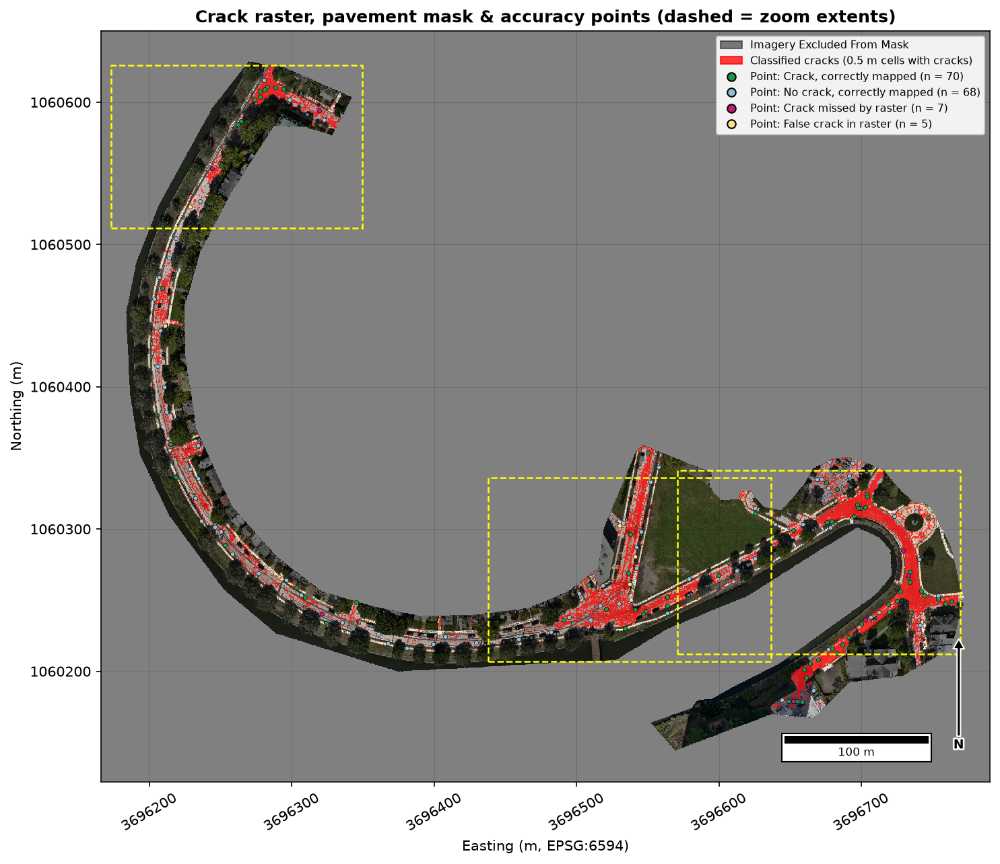

In [35]:
# ---------------------------------------------------------------------
# 01.6.4 (Step B) — Full-site map
# ---------------------------------------------------------------------
print("Map: crack raster, road mask and accuracy points (full site)")
fig, ax = plt.subplots(figsize=(10, 9), dpi=FIG_DPI)
draw_crack_map(ax)
for name, e in ZOOM_EXTENTS.items():                            # outline the zoom extents
    ax.add_patch(mpatches.Rectangle((e["left"], e["bottom"]), e["right"] - e["left"], e["top"] - e["bottom"],
                                    fill=False, edgecolor="yellow", linewidth=1.2, linestyle="--", zorder=6))
map_axes(ax, "Crack raster, pavement mask & accuracy points (dashed = zoom extents)")
plt.tight_layout()
save_fig(fig, 6, "CrackMask_FullSite", 1, maps=True)
plt.show()

Map: crack raster, pavement mask and accuracy points -- Botetourt St & Mowbray Arch
[api] Imagery zoom: using cached download Imagery_zoom_3696438_1060206_0p08m.tif


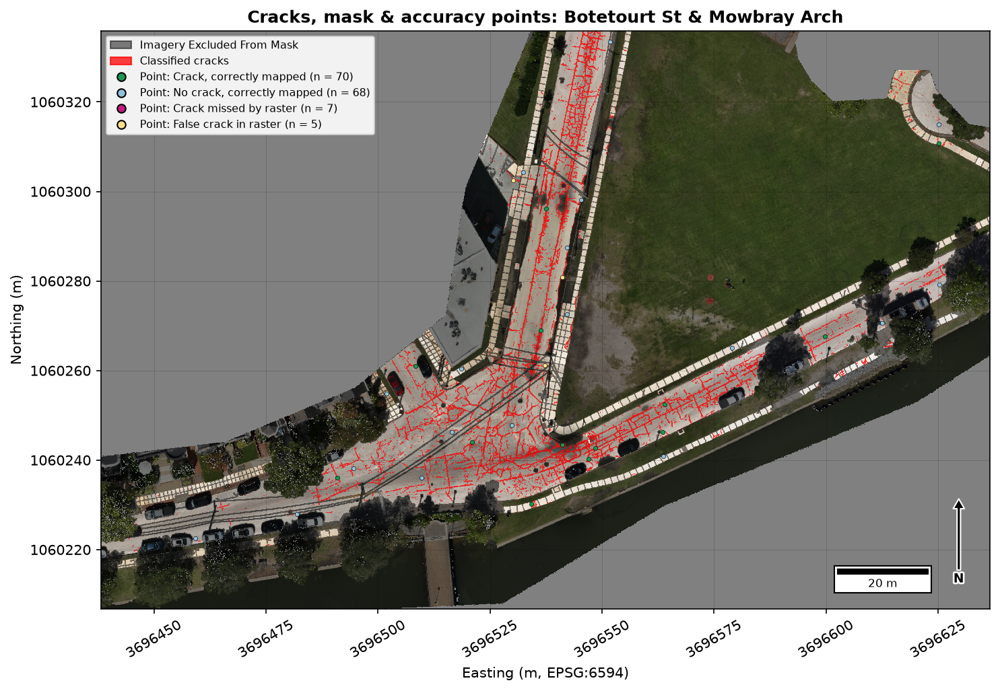

Map: crack raster, pavement mask and accuracy points -- Memorial Pl & Mowbray Arch
[api] Imagery zoom: using cached download Imagery_zoom_3696570_1060212_0p08m.tif


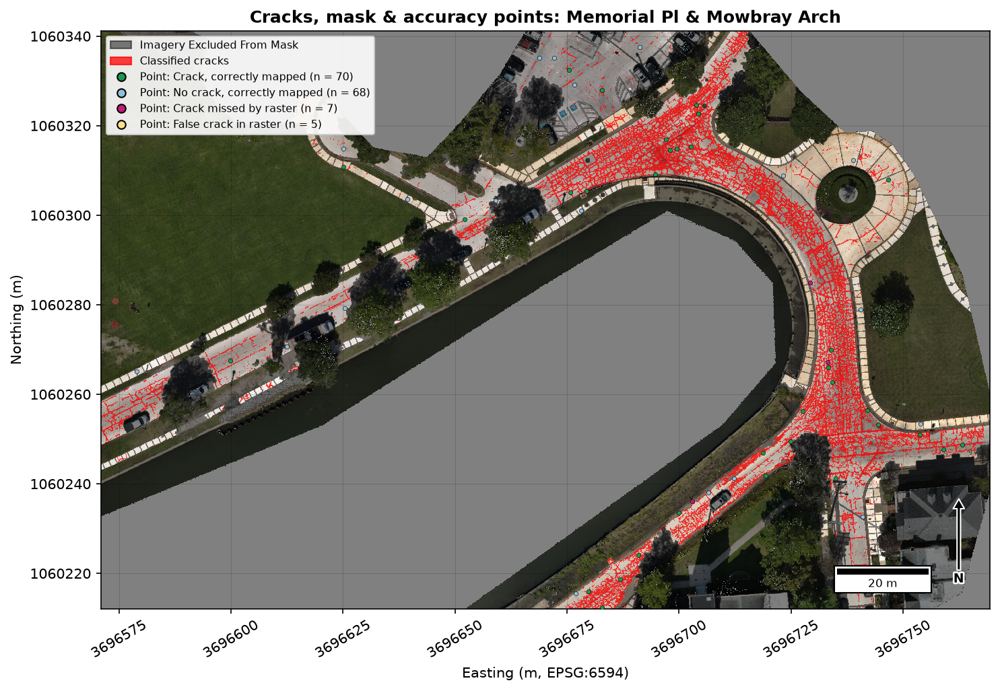

Map: crack raster, pavement mask and accuracy points -- Mowbray Arch & Fairfax Ave
[api] Imagery zoom: using cached download Imagery_zoom_3696172_1060511_0p08m.tif


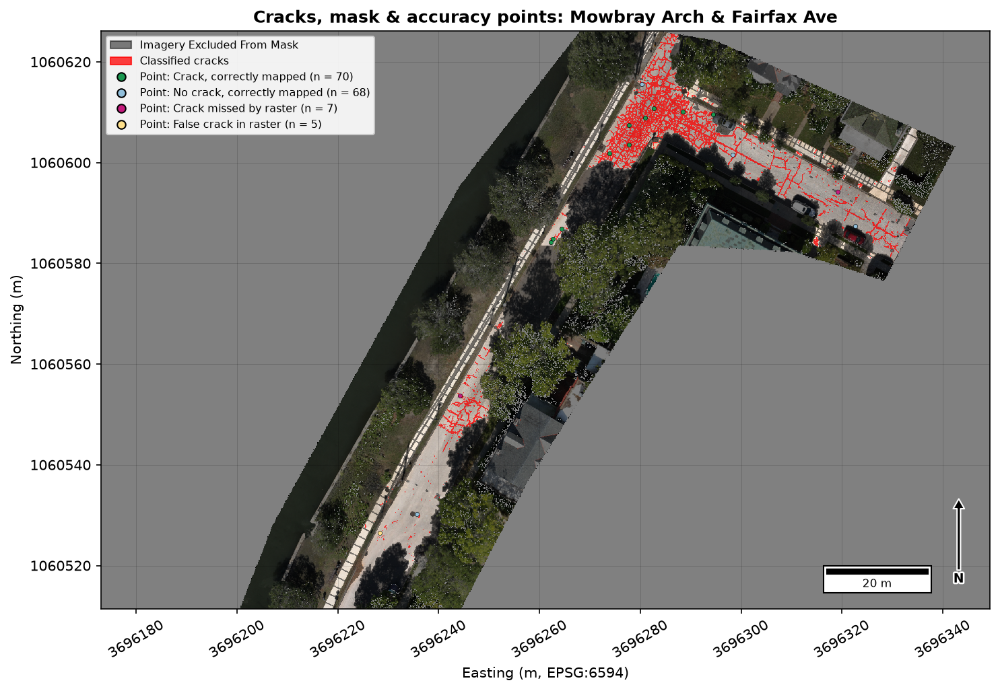

In [36]:
# ---------------------------------------------------------------------
# 01.6.4 (Step C) — Zoomed maps (one per extent in ZOOM_EXTENTS)
# ---------------------------------------------------------------------
for i, (name, ext) in enumerate(ZOOM_EXTENTS.items()):
    print(f"Map: crack raster, pavement mask and accuracy points -- {name}")
    fig, ax = plt.subplots(figsize=(10, 7.5), dpi=FIG_DPI)
    draw_crack_map(ax, ext, legend_loc="upper left")
    map_axes(ax, f"Cracks, mask & accuracy points: {name}")
    plt.tight_layout()
    save_fig(fig, 7 + i, f"CrackMask_Zoom{i + 1}", 1, maps=True)
    plt.show()

**What the maps show.**

- **Where the cracks are.** Cracks are densest at the east end, around the Memorial Pl loop and the streets leading
  into it. There are also dense patches at the Botetourt St intersection south of the field and at the
  Mowbray Arch / Fairfax Ave corner in the northwest. Most of the long arc of Mowbray Arch has only scattered cracks.
- **Detail in the zooms.** The zoomed maps show the cracks as connected networks of thin lines. The mask keeps the
  model to the road and sidewalk surface: lawns, roofs, parked cars and tree shadows are dark-grey "Imagery Excluded
  From Mask".
- **Accuracy points.** The points spread evenly over the pavement. The few misses and false cracks show no
  geographic cluster.

### 01.7 Relative sea level at Sewells Point: observed trend (NOAA) and projection (USACE / NOAA 2017)

Two related datasets describe the sea level that the flood-days model depends on.

#### 01.7.1 Observed relative sea level trend (NOAA CO-OPS, 2026)

- **What it is.** Monthly mean sea level at the Sewells Point tide gauge (station 8638610, Norfolk), about 10 km
  northwest of the study area, from 1927 to the present. As NOAA does for its published trend, the regular seasonal
  cycle is removed and a linear trend with 95 % confidence limits is fitted (01.7.1 Step A).
- **Access.** Two NOAA CO-OPS links:
  - Monthly means from the CO-OPS Data API (`product=monthly_mean`, `datum=MSL`, metric). NOAA's `sltrends`
    CSV download of the monthly means and trend does not serve the file:
    `https://api.tidesandcurrents.noaa.gov/api/prod/datagetter`
  - Trend summary from the CO-OPS Derived Product API:
    `https://api.tidesandcurrents.noaa.gov/dpapi/prod/webapi/product/sealvltrends.json?station=8638610&affil=US`
- **Why it is used.** It shows how much relative sea level has actually risen at the gauge Ezer (2022) fitted his
  flood equation to. It also lets the projection used for 2025 be checked against observations.
- **Units.** Metres, relative to the station's mean sea level datum. For comparison with the projection, the
  values are re-expressed relative to the trend's 2000 level (05.7).

In [37]:
# ---------------------------------------------------------------------
# 01.7.1 (Step A) — Download (cached) the NOAA monthly mean sea level for Sewells Point and fit its linear trend
# ---------------------------------------------------------------------
# Monthly means (verified, relative to the station's MSL datum, metres) from the CO-OPS Data API, cached as CSV
slt_csv_cache, slt_json_cache = API_CACHE / "NOAA_MonthlyMean_8638610_MSL.csv", API_CACHE / "NOAA_SLT_8638610_summary.json"
if not slt_csv_cache.exists() or REFRESH_API_DOWNLOADS:
    _params = dict(product="monthly_mean", station="8638610", datum="MSL", units="metric", time_zone="gmt",
                   format="csv", application="OEAS805_NB00", begin_date="19270101",
                   end_date=datetime.now().strftime("%Y%m%d"))
    _r = _session.get(URL_NOAA_DATAGETTER, params=_params, timeout=HTTP_TIMEOUT_S); _r.raise_for_status()
    if "error" in _r.text[:300].lower():                    # the API reports problems as text instead of data
        raise RuntimeError(_r.text[:300].strip())
    slt_csv_cache.write_text(_r.text)
    print(f"[api] NOAA monthly mean sea level: downloaded ({len(_r.text.splitlines())} lines)")
else:
    print(f"[api] NOAA monthly mean sea level: using cached download {slt_csv_cache.name}")
try:
    slt_info = get_service_info(URL_NOAA_SLT_JSON, "NOAA_SLT_8638610_summary")["SeaLvlTrends"][0]
except Exception as e:
    slt_info = {}
    print(f"[info] trend summary (JSON API) not available ({type(e).__name__}); only the trend fitted here is shown")

# Read the CSV: year, month, and monthly MSL (column names matched without case or spaces; blanks -> NaN, dropped)
_raw = pd.read_csv(slt_csv_cache, skipinitialspace=True)
_col = {c.strip().lower(): c for c in _raw.columns}
slt = pd.DataFrame({"Year": pd.to_numeric(_raw[_col["year"]], errors="coerce"),
                    "Month": pd.to_numeric(_raw[_col["month"]], errors="coerce"),
                    "MSL_raw_m": pd.to_numeric(_raw[_col["msl"]], errors="coerce")}).dropna().reset_index(drop=True)
slt[["Year", "Month"]] = slt[["Year", "Month"]].astype(int)
slt["DecYear"] = slt["Year"] + (slt["Month"] - 0.5) / 12

# Seasonal cycle removed as in NOAA's trend product: the mean departure of each calendar month from a straight line
_f0 = stats.linregress(slt["DecYear"], slt["MSL_raw_m"])
_dep = slt["MSL_raw_m"] - (_f0.intercept + _f0.slope * slt["DecYear"])
slt["MSL_m"] = slt["MSL_raw_m"] - slt["Month"].map(_dep.groupby(slt["Month"]).mean())

# Linear trend of the complete years (the current year is left out, as NOAA does) with its 95 % confidence limits.
# Neighbouring months are correlated (lag-1 autocorrelation r1), so the standard errors are widened by
# sqrt((1 + r1) / (1 - r1)) (Zervas, 2009).
_fit_rows = slt["Year"] < datetime.now().year
_x, _y = slt.loc[_fit_rows, "DecYear"].values, slt.loc[_fit_rows, "MSL_m"].values
_fit = stats.linregress(_x, _y)
_res = _y - (_fit.intercept + _fit.slope * _x)
_r1 = float(np.corrcoef(_res[:-1], _res[1:])[0, 1])
_infl = math.sqrt((1 + _r1) / (1 - _r1))
_se_slope, _se_mean = _fit.stderr * _infl, np.std(_res, ddof=2) / math.sqrt(len(_x)) * _infl
_t = slt["DecYear"].where(_fit_rows)                       # trend only over the fitted months (blank afterwards)
slt["Trend_m"] = _fit.intercept + _fit.slope * _t
_se_line = np.sqrt(_se_mean ** 2 + (_se_slope * (_t - _x.mean())) ** 2)
slt["TrendHi_m"], slt["TrendLo_m"] = slt["Trend_m"] + 1.96 * _se_line, slt["Trend_m"] - 1.96 * _se_line

# Same table as before: year, month, monthly MSL (seasonal cycle removed), linear trend, upper / lower 95 % limits
slt = slt[["Year", "Month", "MSL_m", "Trend_m", "TrendHi_m", "TrendLo_m"]].copy()
slt["Date"] = pd.to_datetime(dict(year=slt["Year"], month=slt["Month"], day=15))
slt["DecYear"] = slt["Year"] + (slt["Month"] - 0.5) / 12
print(f"[01.7.1] {len(slt):,} monthly values, {slt['Date'].min():%Y-%m} to {slt['Date'].max():%Y-%m}; "
      f"trend fitted here {1000 * _fit.slope:.2f} +/- {1000 * 1.96 * _se_slope:.2f} mm/yr (95 %)")

[api] NOAA monthly mean sea level: downloaded (1188 lines)
[01.7.1] 1,187 monthly values, 1927-08 to 2026-10; trend fitted here 4.83 +/- 0.21 mm/yr (95 %)


In [38]:
# ---------------------------------------------------------------------
# 01.7.1 (Step B) — Q1-Q3 of the observed sea level data
# ---------------------------------------------------------------------
display(describe_gdf(slt.drop(columns=["Date"]), "NOAA sea level trend, Sewells Point (monthly)"))
_n_months = (slt["Date"].max().year - slt["Date"].min().year) * 12 + slt["Date"].max().month - slt["Date"].min().month + 1
print(f"Q3b) Missing months in the record: {_n_months - len(slt)} of {_n_months} calendar months between the first and "
      f"last value; trend columns blank on {int(slt['Trend_m'].isna().sum())} recent months (NOAA fits the trend to complete years)")
if slt_info:
    _mm = slt_info.get("trend", np.nan) * 25.4 / 10            # inches/decade -> mm/yr
    print(f"NOAA trend summary: {slt_info.get('trend')} +/- {slt_info.get('trendError')} {slt_info.get('trendUnits')} "
          f"(= {_mm:.2f} mm/yr), fitted {slt_info.get('startDate')} to {slt_info.get('endDate')}")
register("NOAA sea level trend (Sewells Point)", "table (monthly time series)", "NOAA CO-OPS (Data API + trend API)", "EPSG:4326",
         "1 tide gauge, monthly", (-76.3286, 36.9428, -76.3286, 36.9428), f"{len(slt):,} months")

===== NOAA sea level trend, Sewells Point (monthly) =====
Q1) Size: 1,187 features x 7 attribute columns = 8,309 attribute values
Q2) Data types: {'float64': 5, 'int64': 2} (column count per type)
Q2b) Unique values per column: Year 100, Month 12, MSL_m 977, Trend_m 1,177, TrendHi_m 1,177, TrendLo_m 1,177, DecYear 1,187
Q3) Missing data: 30 missing (NaN) attribute values in 3 column(s); 0 empty/missing geometries; 0 invalid geometries


,dtype,missing (NaN),% missing,# unique
Year,int64,0,0.0,100
Month,int64,0,0.0,12
MSL_m,float64,0,0.0,977
Trend_m,float64,10,0.8,1177
TrendHi_m,float64,10,0.8,1177
TrendLo_m,float64,10,0.8,1177
DecYear,float64,0,0.0,1187


Q3b) Missing months in the record: 4 of 1191 calendar months between the first and last value; trend columns blank on 10 recent months (NOAA fits the trend to complete years)
NOAA trend summary: 0.75 +/- 0.07 inches/decade (= 1.90 mm/yr), fitted 01/15/1955 to 12/15/2025


**What the output shows.**

- **Record.** 1,185 monthly means from August 1927 to August 2026. Only 4 calendar months are missing.
- **Trend columns.** The trend columns are blank for the 10 most recent months, because the trend is fitted to
  complete years (1927–2025).
- **Rate.** NOAA's fitted rate is **1.9 ± 0.04 inches per decade (4.83 mm/yr)**. Over the 98-year record that is about
  0.47 m of relative sea-level rise at the gauge. This rate includes local land subsidence.

#### 01.7.2 Relative sea-level-rise projection (USACE, 2022; Sweet et al., 2017)

The table is very short, so its values are coded in 00.0 (Step B). They are mean sea-level projections for Sewells
Point (Norfolk), relative to 2000, from the U.S. Army Corps of Engineers Sea-Level Change Curve Calculator (USACE,
2022). They use the NOAA 2017 Intermediate-High scenario (Sweet et al., 2017) and account for local land subsidence.
This notebook uses the projection for the relative sea-level rise of the imagery year, 2025 (00.1 Step F).

In [39]:
# ---------------------------------------------------------------------
# 01.7.2 (Step A) — Sea-level-rise projection table: Q1-Q3 and the imagery-year value
# ---------------------------------------------------------------------
noaa["Scenario"] = "NOAA 2017 Intermediate-High (USACE calculator, Sewells Point)"
print(f"Q1) Size: {noaa.shape[0]} rows (years) x {noaa.shape[1]} columns")
print(f"Q2) Data types: {noaa.dtypes.astype(str).to_dict()}")
print(f"Q2b) Unique values: {noaa.nunique().to_dict()}")
print(f"Q3) Missing data: {int(noaa.isna().sum().sum())} missing values")
display(noaa.set_index("Year")[["RSLR_m"]].T)
print(f"Relative sea-level rise in {FLOOD_YEAR} (linear interpolation 2020-2030): {RSLR_FLOOD_YEAR:.3f} m above 2000")
register("NOAA 2017 SLR projection", "table", "coded (USACE, 2022)", None, "decadal", None, f"{len(noaa)} rows")

Q1) Size: 10 rows (years) x 3 columns
Q2) Data types: {'Year': 'int64', 'RSLR_m': 'float64', 'Scenario': 'str'}
Q2b) Unique values: {'Year': 10, 'RSLR_m': 10, 'Scenario': 1}
Q3) Missing data: 0 missing values


Year,2000,2020,2030,2040,2050,2060,2070,2080,2090,2100
RSLR_m,0.0,0.19,0.33,0.49,0.68,0.9,1.14,1.42,1.71,2.04


Relative sea-level rise in 2025 (linear interpolation 2020-2030): 0.260 m above 2000


**What the table shows.** The 10 projected values have no missing data. They rise from 0.19 m in 2020 to 0.33 m
in 2030 and 2.04 m in 2100, all relative to 2000. Linear interpolation gives **0.26 m for 2025**, the RSLR used in
the flood-days equation (00.1 Step F). 05.7 compares this value with what the tide gauge actually recorded.

### 01.8 Flood days per year (derived, 2025)

The raster built in 00.1. It holds the modeled number of days per year on which each 0.5 m cell is flooded at high
tide, from the DEM height above MHHW, open water removed, and Ezer's (2022) equation for 2025. Values range from
near 0 (high ground) to 365 (flooded at every high tide). Because the model is exponential in elevation, a few
centimetres of elevation change the flood days by a large factor. The maps therefore use the classes 0.5, 1.5, 3, 7,
14, 30, 60, 90, 300 and 365 days.

In [40]:
# ---------------------------------------------------------------------
# 01.8 (Step A) — Q1-Q3 and statistics of the flood-days raster
# ---------------------------------------------------------------------
fm_ = raster_meta(flood_path)
_land = np.isfinite(dem_g) & (water_g == 0)
print(f"Q1) Size: {fm_['width']} columns x {fm_['height']} rows = {fm_['width'] * fm_['height']:,} cells of {G_RES} m "
      f"(analysis grid, snapped to the imagery)")
print(f"Q2) Data type: {fm_['dtype']} (continuous, flood days per year, 0-365)")
print(f"Q2b) Unique values: {len(np.unique(flood_g[np.isfinite(flood_g)])):,} distinct values")
print(f"Q3) Missing data: {int(np.isnan(flood_g).sum()):,} cells ({100 * np.isnan(flood_g).mean():.1f} %) -- "
      f"{int((water_g == 1).sum()):,} open-water cells (removed on purpose), the rest outside the DEM; "
      f"{int((_land & np.isnan(flood_g)).sum())} land cells without a value")
display(pd.DataFrame([nice_stats(flood_g, f"Flood days {FLOOD_YEAR}, all land cells", "days/yr"),
                      nice_stats(np.where(road_g, flood_g, np.nan), f"Flood days {FLOOD_YEAR}, pavement cells",
                                 "days/yr")]).round(3))
register("Flood days per year (derived)", "raster (derived)", "00.1 (DEM - VDatum, water removed, Ezer 2022)",
         REF_CRS, f"{G_RES} m", (G_EXTENT[0], G_EXTENT[2], G_EXTENT[1], G_EXTENT[3]), f"{G_W * G_H:,} cells")

Q1) Size: 1249 columns x 1056 rows = 1,318,944 cells of 0.5 m (analysis grid, snapped to the imagery)
Q2) Data type: float32 (continuous, flood days per year, 0-365)
Q2b) Unique values: 233,705 distinct values
Q3) Missing data: 1,058,434 cells (80.2 %) -- 245,800 open-water cells (removed on purpose), the rest outside the DEM; 0 land cells without a value


,count,mean,std,min,25%,50% (median),75%,max,IQR,skewness
"Flood days 2025, all land cells (days/yr)",260510.0,5.716,19.387,0.0,0.073,0.580,4.150,365.000,4.078,11.009
"Flood days 2025, pavement cells (days/yr)",63394.0,8.623,14.604,0.0,0.562,3.041,9.931,339.429,9.369,3.989


**What the statistics show.**

- **Missing cells.** Of the 1,318,944 cells of the 0.5 m grid, 245,800 are open water (removed on purpose). The rest
  of the missing cells lie outside the DEM. No land cell lacks a value.
- **All land cells.** The values are extremely skewed (skewness 11): the median is 0.58 days/yr, but a few low
  cells reach 365.
- **Pavement cells.** Pavement sits lower than the land as a whole. Its median is 3.0 days/yr, its mean 8.6 and its
  maximum 339.

Map: modeled flood days per year (2025) over the imagery


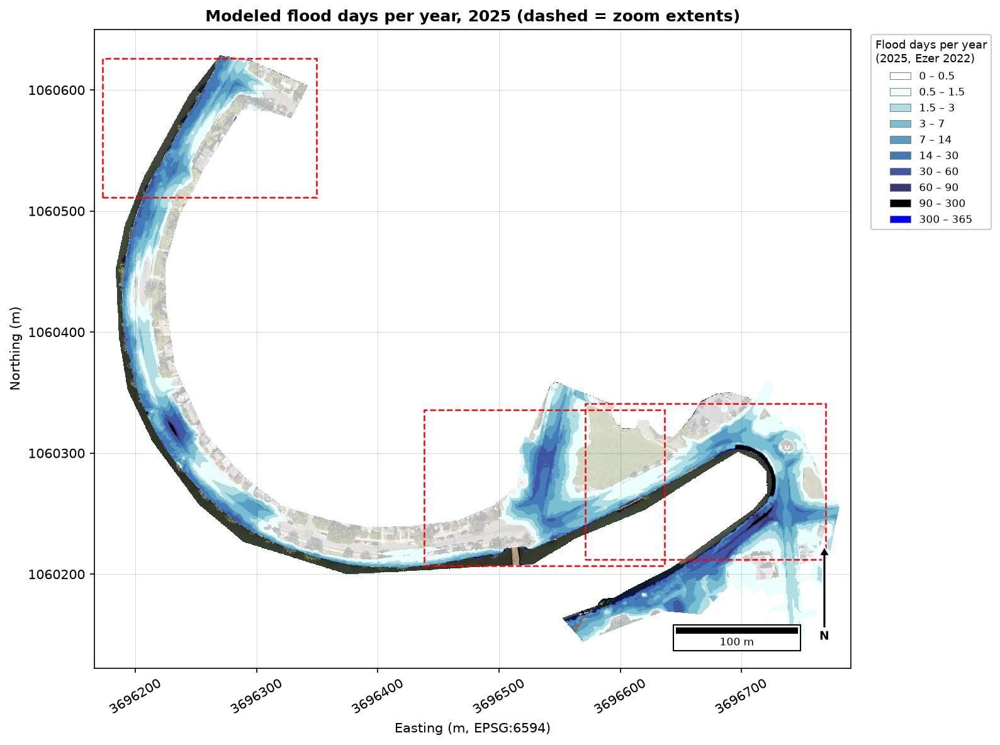

In [41]:
# ---------------------------------------------------------------------
# 01.8 (Step B) — Flood-day classes: colour map and full-site map over the imagery
# ---------------------------------------------------------------------
FLOOD_BOUNDS = [0] + FLOOD_CLASS_UPPER
FLOOD_CMAP = mcolors.ListedColormap([mcolors.to_rgba(c, a) for c, a in zip(FLOOD_CLASS_COLORS, FLOOD_CLASS_ALPHA)])
FLOOD_CMAP.set_over(FLOOD_CMAP(FLOOD_CMAP.N - 1))
FLOOD_NORM = mcolors.BoundaryNorm(FLOOD_BOUNDS, FLOOD_CMAP.N)
FLOOD_HANDLES = [mpatches.Patch(facecolor=FLOOD_CMAP(i), edgecolor="gray", linewidth=0.5, label=f"{lo:g} – {hi:g}")
                 for i, (lo, hi) in enumerate(zip(FLOOD_BOUNDS[:-1], FLOOD_BOUNDS[1:]))]


def draw_flood_map(ax, ext=None):
    """Imagery with the classified flood-days raster on top; legend outside the map (right)."""
    draw_imagery(ax, ext)
    ax.imshow(flood_g, extent=G_EXTENT, cmap=FLOOD_CMAP, norm=FLOOD_NORM, interpolation="none", zorder=1)
    if ext is not None:
        set_extent(ax, ext)
    ax.legend(handles=FLOOD_HANDLES, title=f"Flood days per year\n({FLOOD_YEAR}, Ezer 2022)", loc="upper left",
              bbox_to_anchor=(1.02, 1), fontsize=8, title_fontsize=8.5, framealpha=1)


print(f"Map: modeled flood days per year ({FLOOD_YEAR}) over the imagery")
fig, ax = plt.subplots(figsize=(11, 8), dpi=FIG_DPI)
draw_flood_map(ax)
for name, e in ZOOM_EXTENTS.items():
    ax.add_patch(mpatches.Rectangle((e["left"], e["bottom"]), e["right"] - e["left"], e["top"] - e["bottom"],
                                    fill=False, edgecolor="red", linewidth=1.2, linestyle="--", zorder=6))
map_axes(ax, f"Modeled flood days per year, {FLOOD_YEAR} (dashed = zoom extents)")
plt.tight_layout()
save_fig(fig, 10, "FloodDays_FullSite", 1, maps=True)
plt.show()

Map: modeled flood days per year -- Botetourt St & Mowbray Arch


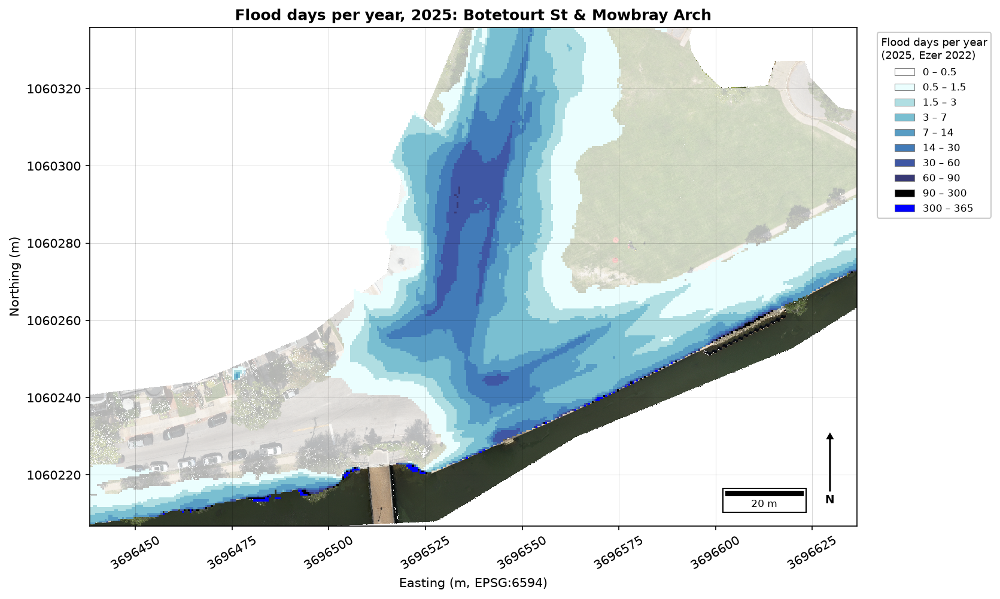

Map: modeled flood days per year -- Memorial Pl & Mowbray Arch


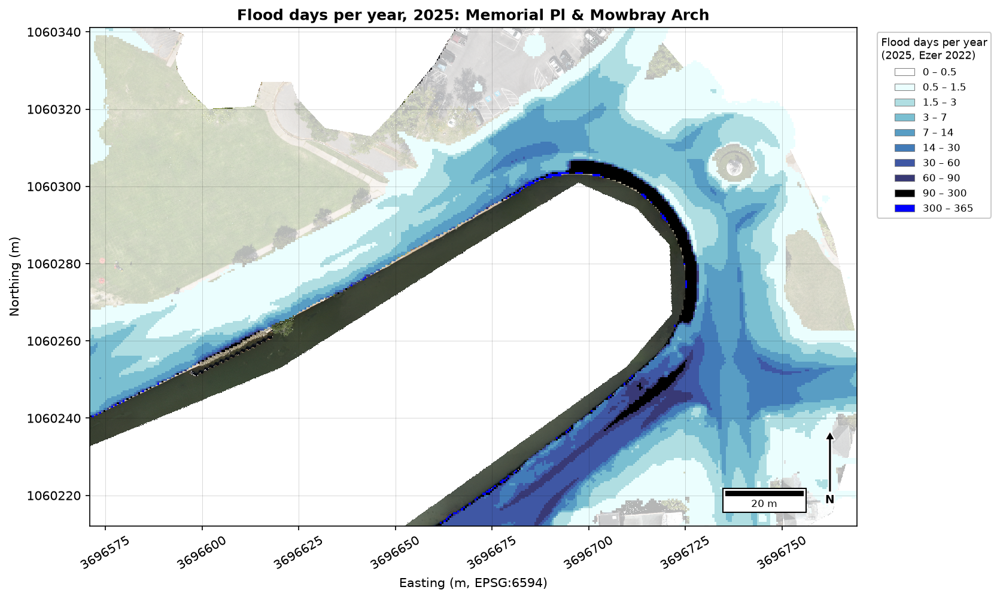

Map: modeled flood days per year -- Mowbray Arch & Fairfax Ave


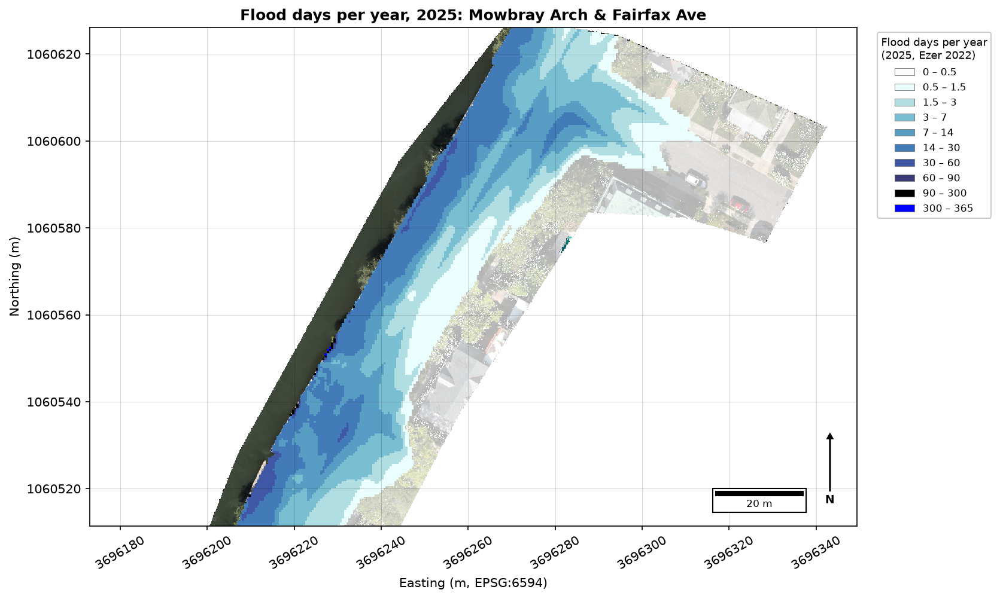

In [42]:
# ---------------------------------------------------------------------
# 01.8 (Step C) — Zoomed flood-days maps (one per extent in ZOOM_EXTENTS)
# ---------------------------------------------------------------------
for i, (name, ext) in enumerate(ZOOM_EXTENTS.items()):
    print(f"Map: modeled flood days per year -- {name}")
    fig, ax = plt.subplots(figsize=(11, 7), dpi=FIG_DPI)
    draw_flood_map(ax, ext)
    map_axes(ax, f"Flood days per year, {FLOOD_YEAR}: {name}")
    plt.tight_layout()
    save_fig(fig, 11 + i, f"FloodDays_Zoom{i + 1}", 1, maps=True)
    plt.show()

**What the maps show.**

- **Most flooded.** The highest flood frequencies (30–300 days/yr, dark blue to black) are in three places:
  - Botetourt St along the west side of the field, near its intersection with Mowbray Arch;
  - the streets around the Memorial Pl loop at the east end, including the southeastern street along the water;
  - a low spot on the western arc of Mowbray Arch, around northing 1,060,320 m.
- **Least flooded.** Most of the southern arc and the northern ends of the corridor are high ground (white, < 0.5
  days/yr).
- **Zoomed maps.** They show that flood frequency changes over a few metres, from the crown of a street to its
  gutter.

### 01.9 Section 01 summary

In [43]:
# ---------------------------------------------------------------------
# 01.9 (Step A) — Section 01 key numbers
# ---------------------------------------------------------------------
sec01_summary = pd.DataFrame([{"Dataset": k, "Type": d["kind"], "Access": d["source"], "Size": d["n"],
                               "Resolution": d["res"]} for k, d in DATASETS.items()]).set_index("Dataset")
display(sec01_summary)

,Type,Access,Size,Resolution
Dataset,,,,
Drone imagery (Imagery_dry),raster (RGB),imagery service (tiles),"823,187,900 px x 3",0.02 m
Drone DEM,raster (elevation),DEM service (tiles),"1,172,080 cells",0.5 m
NOAA VDatum (MHHW in NAVD88),raster (datum surface),VDatum service (tiles),6789 px,0.000449158 degree (~40 m E-W x 50 m N-S)
VGIN RCL (layer 5),vector (lines),VGIN REST API,102 lines,vector
Custom_AddRCL,vector (lines),custom file,9 lines,vector
Norfolk Sidewalks,vector (lines),City of Norfolk REST API,274 lines,vector
Custom_Sidewalk,vector (polygons),custom file,14 polygons,vector
Norfolk Driveways,vector (polygons),City of Norfolk REST API,112 polygons,vector
WaterSurface_Final,vector (polygons),custom file,1 polygon(s),vector


--------------------------------------------------------------------------------------

**Section 01 summary: data description & access** (Q1 size, Q2 data types, Q3 missing data), dataset by dataset:

1. **Drone imagery** (primary data; Steiner, 2026b).
   - *Access:* LERC tiles from the ODU tiled image service (no `exportImage` operation).
   - *Q1/Q2:* 31,205 × 26,380 pixels (823 million per band) of 8-bit RGB (0–255) at 0.02 m. A 0.32 m-pixel preview
     is used for full-site maps and statistics.
   - *Q3:* 82.9 % of the rectangular extent is no-data because the flight covered only the street corridor around
     the inlet (≈ 56,200 m²). Inside the corridor nothing is missing.
2. **Drone DEM** (primary data; Steiner, 2026a).
   - *Access:* LERC tiles at its native 0.5 m.
   - *Q1/Q2:* 1,172,080 float32 cells (m, NAVD88), of which 286,856 are valid (−0.09 to 3.73 m).
   - *Q3:* the 75.5 % no-data is outside the surveyed corridor.
3. **NOAA VDatum (MHHW)** (external).
   - *Access:* LERC tiles from the Esri Living Atlas service.
   - *Q1/Q2:* a coarse float32 surface (~40 × 50 m pixels, 6,789 in the downloaded box). It is nearly constant over
     the site (0.3859–0.3870 m NAVD88).
   - *Q3:* none missing. Its role is to convert the DEM from NAVD88 to height above MHHW.
4. **Road centerlines & traffic (AADT)** (external, plus custom lines).
   - *Access:* paged queries to the VGIN feature service, plus the hand-drawn `Custom_AddRCL`.
   - *Q1/Q2:* 102 VGIN segments (85 in the study area) with 58 text, integer, float and date attributes.
   - *Q3:* `VDOT_AADT` (vehicles/day) is the attribute of interest. It is present on all 85 VGIN segments in the study
     area (220–9,500 vehicles/day). It is missing on all 9 `Custom_AddRCL` lines, as expected. The missing VGIN values
     are in administrative fields the project does not use.
   - *Supporting layers:* the sidewalk/driveway polygons have no missing geometries. The water surface had one
     invalid geometry, repaired with `make_valid`.
5. **Road cracks** (road mask + crack raster; custom).
   - *Q1/Q2:* two categorical uint8 rasters (28,664 × 22,960 px) on the exact 0.02 m imagery grid.
   - *Q3:* NoData outside the pavement mask is intentional (96.3 % of the extent). Inside the mask, 1.6 % of the
     pavement pixels have no crack/no-crack value and are left out of the crack-density denominator. The pavement
     totals 12,293 m², of which 12.9 % is cracked.
6. **Accuracy assessment points** (custom).
   - There is no missing data: all 150 points carry a 0/1 crack label that the author assigned by eye on the 2 cm
     imagery.
   - Comparing each label with the crack raster gives four outcomes: 70 cracks and 68 no-cracks correctly mapped,
     7 cracks missed, 5 false cracks.
7. **Relative sea level (RSLR)** (external).
   - *Observed:* the NOAA Sewells Point monthly record is downloaded from the CO-OPS Data API (trend summary from the Derived Product API). It has 1,185 months
     (August 1927 – August 2026) with only 4 missing, and a trend of 4.83 mm/yr. It is the only time series in the
     project.
   - *Projection:* the USACE / NOAA 2017 Intermediate-High table has 10 complete decadal values and supplies the 2025
     RSLR (0.26 m above 2000).
8. **Derived flood days per year (2025)** (derived in 00.1).
   - *Q1/Q2:* a 0.5 m float32 raster snapped to the imagery.
   - *Q3:* no-data only on open water (removed on purpose) and outside the DEM. No land cell is missing.
   - *Values:* median 0.58 days/yr on all land and 3.0 days/yr on pavement.
   - *Maps:* the highest values sit on the low streets nearest the water: Botetourt St, the east-end loop, and a low
     spot on the western arc.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 02) Spatial & temporal coverage

This section answers three questions, numbered after Section 01's Q1–Q3:

- **Q4) Spatial bounds:** what area does each dataset cover, and how much of the study area (the `Imagery_dry`
  extent) falls inside it?
- **Q5) Spatial resolution:** what is each dataset's pixel size or data model?
- **Q6) Temporal coverage & sampling frequency:** what period does each dataset represent, and how often is it
  sampled?

Bounds are converted to the project CRS so they can be compared with the study area. The study area is the
rectangular extent of `Imagery_dry` (624 × 528 m, 329,275 m²), but the drone flight itself covers a C-shaped corridor
along the streets around the Hague inlet. Both the bounding boxes and the actual data footprints are therefore
reported.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 02.1 Spatial bounds (Q4)

The "% of study area inside bounds" column also speaks to the outline's **data integration & overlap** requirement.
It is the first, coarse measure of how far each dataset overlaps the study area. Section 04 measures overlap on the
analysis cells themselves.

**Reading the tables below.**

- **Full coverage.** The imagery, VDatum, VGIN centerlines, City sidewalks and the flood-days raster have bounding
  boxes that contain the whole study area. The API layers were requested with padding, so they extend beyond it.
- **Partial coverage.**
  - The DEM box covers 89.0 % of the study area, the road mask and crack raster 79.9 %, and the accuracy points
    74.3 %. These products end where the street corridor ends.
  - `Custom_AddRCL` covers only 8.9 %: it fills in centerlines around the parking area at the east end.
- **Outside.** The Sewells Point tide gauge is a single point about 10 km northwest.
- **Actual data footprint (Q4b).** Within the rectangle, the imagery holds data on about 17 % (≈ 56,200 m²) and the
  DEM on about 22 %. The DEM reaches slightly further over the water's edge. The pavement analysed in this project is
  12,293 m², 3.7 % of the rectangle.

In [44]:
# ---------------------------------------------------------------------
# 02.1 (Step A) — Q4: spatial bounds of every dataset and the share of the study area inside them
# ---------------------------------------------------------------------
bounds_rows = []
for name, d in DATASETS.items():
    if d["bounds"] is None:
        continue
    b = transform_bounds(d["crs"], REF_CRS, *d["bounds"], densify_pts=21)
    ll = transform_bounds(d["crs"], "EPSG:4326", *d["bounds"], densify_pts=21)
    d["footprint"] = box(*b)
    bounds_rows.append({"Dataset": name, "xmin (m)": b[0], "ymin (m)": b[1], "xmax (m)": b[2], "ymax (m)": b[3],
                        "W-E x S-N (m)": f"{b[2] - b[0]:,.0f} x {b[3] - b[1]:,.0f}",
                        "Lon/lat bounds (W, S, E, N)": ", ".join(f"{v:.5f}" for v in ll),
                        "% of study area inside bounds": (100 * d["footprint"].intersection(aoi_geom).area / AOI_AREA_M2
                                                          if d["footprint"].area > 0 else  # straight line / single point
                                                          (np.nan if d["footprint"].intersects(aoi_geom) else 0.0))})
spatial_bounds = pd.DataFrame(bounds_rows).set_index("Dataset")
_full = spatial_bounds.index[spatial_bounds["% of study area inside bounds"] >= 99.5].tolist()
_part = spatial_bounds.index[((spatial_bounds["% of study area inside bounds"] < 99.5)
                              & (spatial_bounds["% of study area inside bounds"] > 0))
                             | spatial_bounds["% of study area inside bounds"].isna()].tolist()
_none = spatial_bounds.index[spatial_bounds["% of study area inside bounds"] == 0].tolist()
print(f"Q4) Spatial bounds: {len(_full)} dataset(s) cover the whole study area ({', '.join(_full)}); "
      f"{len(_part)} cover part of it ({', '.join(_part) or 'none'}); "
      f"{len(_none)} lie outside it ({', '.join(_none) or 'none'} -- the tide gauge is a point ~10 km away).")
display(spatial_bounds.round({"xmin (m)": 1, "ymin (m)": 1, "xmax (m)": 1, "ymax (m)": 1,
                              "% of study area inside bounds": 1}))
# Bounding boxes overstate the coverage of the corridor-shaped rasters, so their valid-data area is reported too.
data_area = pd.DataFrame({
    "Dataset": ["Drone imagery (valid pixels)", "Drone DEM (valid cells)", "Flood days (land cells)",
                "Open water (WaterSurface_Final)", "Pavement (road mask)"],
    "Area with data (m2)": [img_valid.sum() * P_RES ** 2, np.isfinite(dem_g).sum() * G_RES ** 2,
                            np.isfinite(flood_g).sum() * G_RES ** 2, water_c.area.sum(), TOTAL_MASK_PX * REF_RES ** 2]})
data_area["% of study area"] = 100 * data_area["Area with data (m2)"] / AOI_AREA_M2
print(f"Q4b) Actual data footprint: the drone survey is a corridor along the streets around the inlet, so the imagery "
      f"holds data on {data_area.iloc[0, 2]:.1f} % of the rectangular study area and the pavement on "
      f"{data_area.iloc[4, 2]:.1f} %:")
display(data_area.set_index("Dataset").round(1))

Q4) Spatial bounds: 5 dataset(s) cover the whole study area (Drone imagery (Imagery_dry), NOAA VDatum (MHHW in NAVD88), VGIN RCL (layer 5), Norfolk Sidewalks, Flood days per year (derived)); 8 cover part of it (Drone DEM, Custom_AddRCL, Custom_Sidewalk, Norfolk Driveways, WaterSurface_Final, Road mask (Shrunk3), Crack raster, Accuracy points); 1 lie outside it (NOAA sea level trend (Sewells Point) -- the tide gauge is a point ~10 km away).


,xmin (m),ymin (m),xmax (m),ymax (m),W-E x S-N (m),"Lon/lat bounds (W, S, E, N)",% of study area inside bounds
Dataset,,,,,,,
Drone imagery (Imagery_dry),3696166.0,1060122.5,3696790.1,1060650.1,624 x 528,"-76.30013, 36.85437, -76.29299, 36.85926",100.0
Drone DEM,3696182.9,1060138.8,3696780.9,1060628.8,598 x 490,"-76.29994, 36.85452, -76.29310, 36.85906",89.0
NOAA VDatum (MHHW in NAVD88),3694573.9,1058535.8,3698382.9,1062260.4,"3,809 x 3,725","-76.31744, 36.84053, -76.27567, 36.87332",100.0
VGIN RCL (layer 5),3695994.5,1060013.4,3696899.9,1060728.4,905 x 715,"-76.30190, 36.85355, -76.29192, 36.85981",100.0
Custom_AddRCL,3696624.1,1060151.7,3696748.5,1060387.2,124 x 235,"-76.29499, 36.85465, -76.29353, 36.85679",8.9
Norfolk Sidewalks,3695936.0,1060055.9,3696895.6,1060805.9,960 x 750,"-76.30253, 36.85395, -76.29196, 36.86051",100.0
Custom_Sidewalk,3696198.9,1060192.0,3696779.2,1060642.1,580 x 450,"-76.29974, 36.85500, -76.29312, 36.85918",79.3
Norfolk Driveways,3696204.8,1060154.9,3696830.0,1060693.6,625 x 539,"-76.29955, 36.85479, -76.29267, 36.85951",88.0
WaterSurface_Final,3696065.8,1060022.4,3696725.2,1060680.0,659 x 658,"-76.30128, 36.85349, -76.29371, 36.85955",89.6


Q4b) Actual data footprint: the drone survey is a corridor along the streets around the inlet, so the imagery holds data on 17.1 % of the rectangular study area and the pavement on 3.7 %:


,Area with data (m2),% of study area
Dataset,,
Drone imagery (valid pixels),56203.2,17.1
Drone DEM (valid cells),71714.0,21.8
Flood days (land cells),65127.5,19.8
Open water (WaterSurface_Final),61469.3,18.7
Pavement (road mask),12293.1,3.7


### 02.2 Spatial resolution (Q5)

The "Access" column repeats, for reference, how each dataset was obtained. That is the outline's **data description
& access** requirement, which Section 01 covers in full.

In [45]:
# ---------------------------------------------------------------------
# 02.2 (Step A) — Q5: spatial resolution / data model of every dataset
# ---------------------------------------------------------------------
res_rows = []
for name, d in DATASETS.items():
    res_rows.append({"Dataset": name, "Type": d["kind"], "Native CRS": d["crs"].name if d["crs"] else "-",
                     "Native resolution": d["res"], "Size": d["n"], "Access": d["source"]})
spatial_res = pd.DataFrame(res_rows).set_index("Dataset")
print("Q5) Spatial resolution: rasters range from 0.02 m (imagery, crack raster, road mask) to 0.5 m (DEM, flood days) "
      f"to ~{_res_m:.0f} x {_res_my:.0f} m (VDatum); vector layers have no pixel size (their detail is that of the "
      "imagery they were digitized from); the sea level record is a single tide gauge.")
display(spatial_res)

Q5) Spatial resolution: rasters range from 0.02 m (imagery, crack raster, road mask) to 0.5 m (DEM, flood days) to ~40 x 50 m (VDatum); vector layers have no pixel size (their detail is that of the imagery they were digitized from); the sea level record is a single tide gauge.


,Type,Native CRS,Native resolution,Size,Access
Dataset,,,,,
Drone imagery (Imagery_dry),raster (RGB),NAD83(2011) / Virginia South,0.02 m,"823,187,900 px x 3",imagery service (tiles)
Drone DEM,raster (elevation),NAD83(2011) / Virginia South,0.5 m,"1,172,080 cells",DEM service (tiles)
NOAA VDatum (MHHW in NAVD88),raster (datum surface),WGS 84,0.000449158 degree (~40 m E-W x 50 m N-S),6789 px,VDatum service (tiles)
VGIN RCL (layer 5),vector (lines),WGS 84,vector,102 lines,VGIN REST API
Custom_AddRCL,vector (lines),NAD83(2011) / Virginia South + NAVD88 height,vector,9 lines,custom file
Norfolk Sidewalks,vector (lines),WGS 84,vector,274 lines,City of Norfolk REST API
Custom_Sidewalk,vector (polygons),NAD83(2011) / Virginia South + NAVD88 height,vector,14 polygons,custom file
Norfolk Driveways,vector (polygons),WGS 84,vector,112 polygons,City of Norfolk REST API
WaterSurface_Final,vector (polygons),NAD83(2011) / Virginia South + NAVD88 height,vector,1 polygon(s),custom file


### 02.3 Footprints around the study area

The map below draws each dataset's bounding box over the imagery preview, with the study area in red. It shows the
same result as the Q4 table. The drone products (DEM, road mask, crack raster, accuracy points, custom sidewalks) are
nested just inside the study area around the imaged corridor. The API layers (VGIN, City sidewalks and driveways),
VDatum and the water surface run past its edges and are clipped in Section 03. `Custom_AddRCL` is the small box at
the east end.

Map: footprint (bounding box) of each spatial dataset compared with the study area


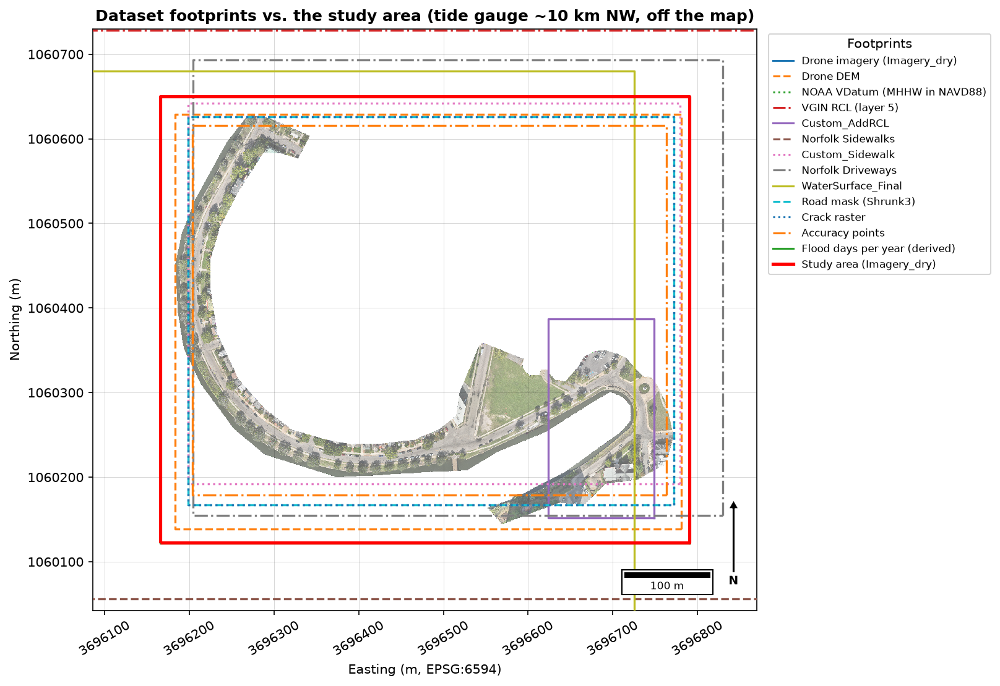

In [46]:
# ---------------------------------------------------------------------
# 02.3 (Step A) — Map of the dataset footprints around the study area
# ---------------------------------------------------------------------
print("Map: footprint (bounding box) of each spatial dataset compared with the study area")
fig, ax = plt.subplots(figsize=(11, 7.5), dpi=FIG_DPI)
draw_imagery(ax, alpha=0.6)
_cols = plt.cm.tab20(np.linspace(0, 1, 20))
_handles = []
for i, (name, d) in enumerate((n, d) for n, d in DATASETS.items()
                              if d.get("footprint") is not None and d["footprint"].area > 0):
    fx, fy = d["footprint"].exterior.xy
    ls = ["-", "--", ":", "-."][i % 4]
    ax.plot(fx, fy, color=_cols[(2 * i) % 20], linewidth=1.6, linestyle=ls, zorder=3)
    _handles.append(mlines.Line2D([], [], color=_cols[(2 * i) % 20], linestyle=ls, label=name))
AOI.boundary.plot(ax=ax, color="red", linewidth=2.5, zorder=4)
_handles.append(mlines.Line2D([], [], color="red", linewidth=2.5, label="Study area (Imagery_dry)"))
pad = 80
ax.set_xlim(REF_BOUNDS[0] - pad, REF_BOUNDS[2] + pad); ax.set_ylim(REF_BOUNDS[1] - pad, REF_BOUNDS[3] + pad)
ax.legend(handles=_handles, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, title="Footprints")
map_axes(ax, "Dataset footprints vs. the study area (tide gauge ~10 km NW, off the map)")
plt.tight_layout()
save_fig(fig, 14, "DatasetFootprints", 2, maps=True)
plt.show()

### 02.4 Temporal coverage & sampling frequency (Q6)

The VGIN edit dates are read from the layer's own date fields (`GEO_ED`, `ST_ED`, `ADD_ED`, `GEO_EFFDT`). The NOAA
sea level record's dates are read from the data. The custom layers (`Custom_AddRCL`, `Custom_Sidewalk`) are dated to
the imagery they were digitized on (3 Oct 2025), because that is the surface they describe.

**What the timeline shows.**

- **On the 3 October 2025 line:** the imagery, DEM, road mask and crack raster, accuracy points and custom layers,
  and the 2025 flood-days model.
- **Edit dates of the VGIN segments in the study area:** 2012 to September 2026.
  - Street-name edits cluster in 2023 and address edits in 2025.
  - Most segments have a blank geometry-edit date (`GEO_ED`), and `GEO_EFFDT` is blank on all 85.
- **Older or fixed periods:** the City sidewalks and driveways date from the 2006–2008 aerials. VDatum is fixed to
  the 1983–2001 tidal epoch.
- **Longest record:** the NOAA monthly series runs from August 1927 to August 2026.
- **Projection:** it spans 2000–2100 at decadal steps.

In [47]:
# ---------------------------------------------------------------------
# 02.4 (Step A) — Q6: temporal coverage table (dates from settings + dates read from the data)
# ---------------------------------------------------------------------
IMAGERY_DATE = pd.Timestamp("2025-10-03")
temporal = pd.DataFrame(TEMPORAL_INFO, columns=["Dataset", "Start", "End", "Sampling / note"])
temporal["Start"] = pd.to_datetime(temporal["Start"])
temporal["End"] = pd.to_datetime(temporal["End"])
_date_cols = [c for c in ("GEO_ED", "ST_ED", "ADD_ED", "GEO_EFFDT") if c in rcl_raw.columns]
rcl_dates = pd.DataFrame()
if _date_cols:
    _in = rcl_raw.to_crs(REF_CRS).intersects(aoi_geom)
    rcl_dates = rcl_raw.loc[_in, _date_cols].apply(pd.to_datetime, errors="coerce")
    _all = rcl_dates.stack().dropna()
    if len(_all):
        _i = temporal.index[temporal["Dataset"].str.startswith("VGIN")]
        temporal.loc[_i, "Start"] = _all.min()
        temporal.loc[_i, "End"] = max(_all.max(), pd.Timestamp("2024-09-17"))
        temporal.loc[_i, "Sampling / note"] += f" | segment edit dates {_all.min():%Y-%m} to {_all.max():%Y-%m}"
_i = temporal.index[temporal["Dataset"].str.startswith("NOAA sea level trend")]
temporal.loc[_i, "Start"], temporal.loc[_i, "End"] = slt["Date"].min(), slt["Date"].max()
temporal["Years before imagery (start)"] = ((IMAGERY_DATE - temporal["Start"]).dt.days / 365.25).round(1)
print("Q6) Temporal coverage & sampling: every dataset is a one-time snapshot or a single modeled year (most from the "
      "3 Oct 2025 survey), except the NOAA tide-gauge record -- a monthly time series "
      f"{slt['Date'].min():%Y}-{slt['Date'].max():%Y} -- and the decadal 2000-2100 projection.")
display(temporal)
if len(rcl_dates):
    print("VGIN date fields inside the study area (min / max / # blank):")
    display(pd.DataFrame({"min": rcl_dates.min(), "max": rcl_dates.max(), "# blank": rcl_dates.isna().sum()}))

Q6) Temporal coverage & sampling: every dataset is a one-time snapshot or a single modeled year (most from the 3 Oct 2025 survey), except the NOAA tide-gauge record -- a monthly time series 1927-2026 -- and the decadal 2000-2100 projection.


,Dataset,Start,End,Sampling / note,Years before imagery (start)
0,Drone imagery (Imagery_dry),2025-10-03,2025-10-03,One low-tide flight (DJI M3M),0.0
1,Drone DEM,2025-10-03,2025-10-03,Same low-tide flight as the imagery,0.0
2,NOAA VDatum (MHHW in NAVD88),1983-01-01,2001-12-31,Static surface; tidal datums on the 1983-2001 ...,42.8
3,VGIN RCL + VDOT_AADT,2012-02-22,2026-09-21,"Living layer, republished quarterly (created 2...",13.6
4,Custom_AddRCL,2025-10-03,2025-10-03,Represents the 2025 imagery (digitized on it i...,0.0
5,Norfolk Driveways,2006-01-01,2008-12-31,Digitized once from 2006/2008 VGIN aerials,19.8
6,Norfolk Sidewalks,2006-01-01,2006-12-31,Digitized once from 2006 VGIN aerials,19.8
7,Custom_Sidewalk,2025-10-03,2025-10-03,Represents the 2025 imagery (digitized on it i...,0.0
8,WaterSurface_Final,2023-09-13,2025-10-03,HCDEM water (item updated 2023-09-13) + SAM3 o...,2.1
9,Road mask & crack raster,2025-10-03,2025-10-03,Derived once from the 2025 imagery,0.0


VGIN date fields inside the study area (min / max / # blank):


,min,max,# blank
GEO_ED,2012-02-22,2023-06-26,78
ST_ED,2013-06-26,2023-06-26,57
ADD_ED,2015-09-24,2026-09-21,68
GEO_EFFDT,NaT,NaT,85


Timeline: temporal coverage of each dataset (bars = date range, diamonds = single date)


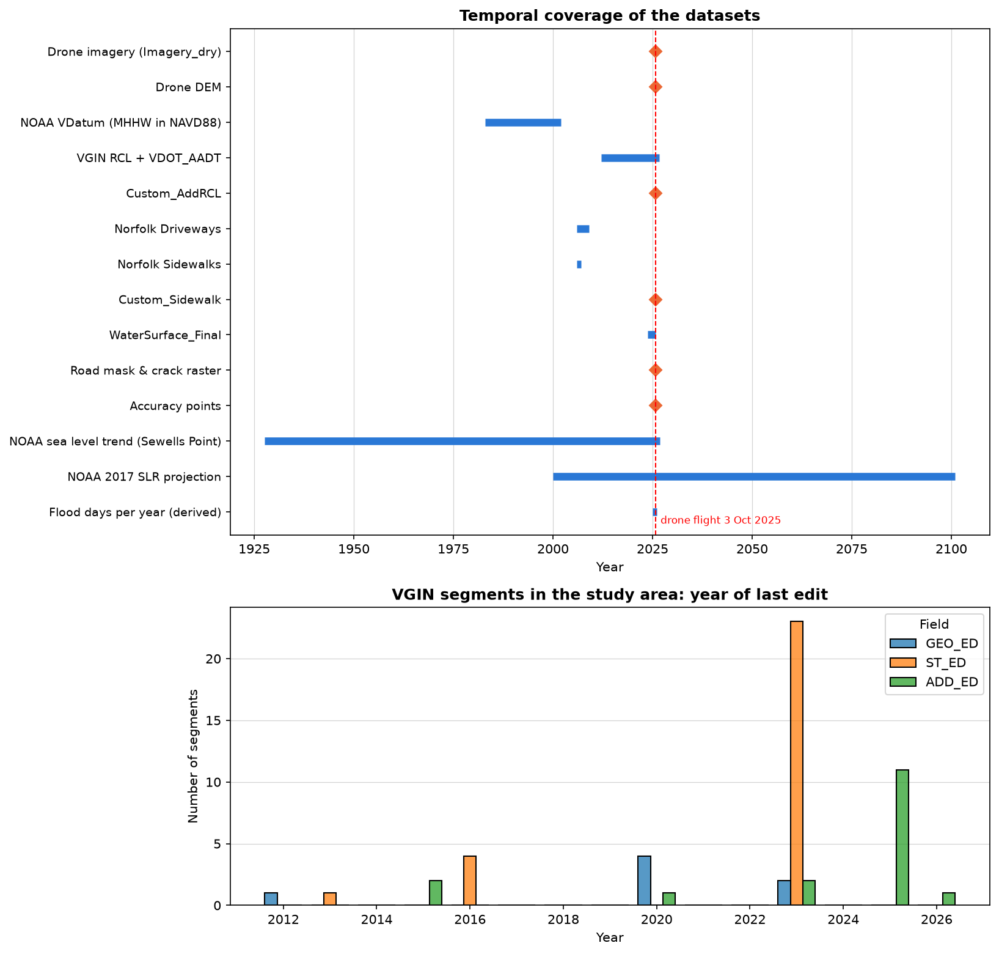

In [48]:
# ---------------------------------------------------------------------
# 02.4 (Step B) — Timeline figure (top) and VGIN edit-year histogram (bottom)
# ---------------------------------------------------------------------
print("Timeline: temporal coverage of each dataset (bars = date range, diamonds = single date)")
fig, axes = plt.subplots(2, 1, figsize=(11, 10.5), dpi=FIG_DPI, gridspec_kw=dict(height_ratios=[1.7, 1]))
ax = axes[0]
_t = temporal.dropna(subset=["Start"]).iloc[::-1].reset_index(drop=True)
for i, r in _t.iterrows():
    s, e = r["Start"].year + r["Start"].dayofyear / 365.25, r["End"].year + r["End"].dayofyear / 365.25
    if e - s < 0.2:
        ax.plot(s, i, marker="D", color=COLOR_ACCENT, markersize=7)
    else:
        ax.plot([s, e], [i, i], color=COLOR_ROAD, linewidth=6, solid_capstyle="butt")
ax.axvline(IMAGERY_DATE.year + IMAGERY_DATE.dayofyear / 365.25, color="red", linestyle="--", linewidth=1)
ax.text(2027, -0.4, "drone flight 3 Oct 2025", color="red", fontsize=8, va="bottom")
ax.set_yticks(range(len(_t))); ax.set_yticklabels(_t["Dataset"], fontsize=9)
ax.set_xlabel("Year"); ax.set_title("Temporal coverage of the datasets", fontweight="bold")
style_ax(ax, "x")
ax = axes[1]
if len(rcl_dates):
    _yrs = rcl_dates.apply(lambda c: c.dt.year).melt(var_name="Field", value_name="Year").dropna()
    sns.histplot(data=_yrs, x="Year", hue="Field", multiple="dodge", discrete=True, ax=ax, shrink=0.8)
    ax.set_title("VGIN segments in the study area: year of last edit", fontweight="bold")
    ax.set_xlabel("Year"); ax.set_ylabel("Number of segments")
    style_ax(ax, "y")
else:
    ax.axis("off"); ax.text(0.5, 0.5, "No VGIN date fields", ha="center")
plt.tight_layout()
save_fig(fig, 15, "TemporalCoverage", 2)
plt.show()

--------------------------------------------------------------------------------------

**Section 02 summary: spatial & temporal coverage.**

- **Q4) Spatial bounds.**
  - The study area is the 624 × 528 m rectangle of `Imagery_dry` (329,275 m²). The drone data fill a C-shaped
    street corridor inside it: the imagery covers ≈ 17 % of the rectangle and the DEM ≈ 22 %. Their "no-data" pixels
    are simply outside the flight, not gaps.
  - The DEM, road mask, crack raster and accuracy points have bounding boxes covering 74–89 % of the rectangle. They
    all contain the full pavement corridor.
  - VDatum, the VGIN centerlines and the City layers extend beyond the study area and are clipped in Section 03.
  - The NOAA tide gauge is a single point about 10 km northwest. It represents the regional water level, not a
    place inside the study area.
- **Q5) Spatial resolution.**
  - The rasters span more than three orders of magnitude: 0.02 m imagery, cracks and mask; 0.5 m DEM and flood days;
    ~40 × 50 m VDatum (0.00045°).
  - VDatum varies by only 1.1 mm across the study area, so its coarse pixels lose nothing.
  - The vector layers carry the positional detail of the imagery they were digitized from: 2025 drone imagery for
    the custom layers, 2006/2008 aerials for the City layers.
- **Q6) Temporal coverage & sampling frequency.**
  - The variables that drive the analysis come from the same **3 October 2025** low-tide survey: cracks, mask,
    elevation and, through it, flood days.
  - Traffic (`VDOT_AADT`) and the centerlines are a recent snapshot of a quarterly product. Its segment edits in the
    study area run 2012–2026, and the AADT count year is not stated.
  - The City sidewalk/driveway layers are ~18–20 years older.
  - VDatum is a static datum surface on the 1983–2001 tidal epoch.
  - The only true time series is the NOAA monthly sea level record: 1,185 months, August 1927 – August 2026. The
    projection is decadal.
  - Everything else is a single snapshot, so this is a **cross-sectional** study of one point in time.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 03) Data cleaning: filter, reproject, snap & join

This section finishes putting every dataset on the same footing. The project's definition of "clean" is:

1. **Filtered** to the `Imagery_dry` extent.
2. **Reprojected** to the imagery's CRS (EPSG:6594 metres; vertical NAVD88).
3. **Snapped** to the imagery grid.
4. **Joined** where needed.

Done earlier:

- **00.1:** the rasters (DEM, VDatum, water, flood days) were resampled onto the 0.5 m raster grid.
- **01.6.2:** the 0.02 m crack raster and mask were counted into the same 0.5 m cells.

This section covers four steps:

- **03.1–03.2** clean and merge the **vector layers**.
- **03.3** builds the **traffic (AADT) polygon**.
- **03.4** builds the **analysis cells**: a 5 m × 5 m fishnet clipped to the shrunk road mask. Every per-cell
  variable is computed on these cells (crack density, flood days, elevation, sidewalk share, traffic).
- **03.5** summarizes the section.

Outputs go to `DATA/02_Clean_Data/OUT_DATA_NB00_Sec03/` and are rebuilt on every run.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 03.1 Vector layers: reproject & clip to the study area

In [49]:
# ---------------------------------------------------------------------
# 03.1 (Step A) — Reproject + clip every vector layer to the study area
# ---------------------------------------------------------------------
OUT03 = clean_dir(3)


def clean_vector(gdf, name):
    """Reproject to the project CRS, repair geometries, clip to the study area (keeping the geometry type)."""
    if gdf is None or len(gdf) == 0:
        return gdf
    g = gdf.copy()
    if g.crs is None:
        print(f"[WARN] {name} has no CRS -- assumed to be {REF_CRS_NAME}")
        g = g.set_crs(REF_CRS)
    g = g.to_crs(REF_CRS)
    g = g[g.geometry.notna() & ~g.geometry.is_empty]
    g["geometry"] = g.geometry.make_valid()
    g = gpd.clip(g, aoi_geom, keep_geom_type=True)
    g = g[~g.geometry.is_empty].reset_index(drop=True)
    print(f"[03.1] {name}: {len(gdf)} -> {len(g)} features inside the study area")
    return g


rcl_c = clean_vector(rcl_raw, "VGIN RCL")
add_c = clean_vector(addrcl_raw, "Custom_AddRCL")
sidewalk_c = clean_vector(sidewalk_raw, "Custom_Sidewalk")
driveway_c = clean_vector(driveway_raw, "Norfolk Driveways")
sidewalk_city_c = clean_vector(sidewalk_city_raw, "Norfolk Sidewalks")
accpts_c = clean_vector(accpts_raw, "Accuracy points")
# Sidewalk/driveway SURFACE: Custom_Sidewalk merged with the City driveways and dissolved into one polygon.
_swd = [g for g in (sidewalk_c, driveway_c) if g is not None and len(g)]
sw_surface = shapely.union_all(pd.concat(_swd).geometry.values) if _swd else shapely.Polygon()
print(f"[03.1] sidewalk/driveway surface: {sw_surface.area:,.0f} m2")

[03.1] VGIN RCL: 102 -> 85 features inside the study area
[03.1] Custom_AddRCL: 9 -> 9 features inside the study area
[03.1] Custom_Sidewalk: 14 -> 14 features inside the study area
[03.1] Norfolk Driveways: 112 -> 100 features inside the study area
[03.1] Norfolk Sidewalks: 274 -> 226 features inside the study area
[03.1] Accuracy points: 150 -> 150 features inside the study area
[03.1] sidewalk/driveway surface: 11,767 m2


**What the output shows.** Clipping removes the features that only touch the padded query box: VGIN goes from 102 to 85
segments, the City driveways from 112 to 100 and the City sidewalks from 274 to 226. The custom layers and the
accuracy points lie entirely inside the study area. The merged sidewalk/driveway surface (`Custom_Sidewalk` + City
driveways) covers 11,767 m².

### 03.2 Join: merge the centerlines (traffic attribute) and write the clean GeoPackage

The VDOT traffic volume `VDOT_AADT` is already an attribute of the VGIN centerlines (layer 5), so no table join is
needed. The VGIN lines are merged with `Custom_AddRCL`, and `AADT` is standardized (0/blank → missing). The layers are
written to one **GeoPackage**, a single open-source file with many layers that keeps full field names, which
shapefiles truncate to 10 characters.

In [50]:
# ---------------------------------------------------------------------
# 03.2 (Step A) — Merge the centerlines and standardize the traffic field
# ---------------------------------------------------------------------
rcl_c["Source"] = "VGIN_RCL"
add_c["Source"] = "Custom_AddRCL"
centerlines = gpd.GeoDataFrame(pd.concat([rcl_c, add_c], ignore_index=True), geometry="geometry", crs=REF_CRS)
if "MTFCC" not in centerlines.columns:
    centerlines["MTFCC"] = None
centerlines["MTFCC_Desc"] = centerlines["MTFCC"].map(MTFCC_DESC).fillna("Unclassified (custom)")
_aadt = pd.to_numeric(centerlines["VDOT_AADT"], errors="coerce") if "VDOT_AADT" in centerlines.columns else np.nan
centerlines["AADT"] = pd.Series(_aadt, index=centerlines.index).where(lambda s: s > 0)    # 0 / blank = no count
centerlines["Length_m"] = centerlines.length
print(f"[03.2] merged centerlines: {len(centerlines)} segments, {centerlines['Length_m'].sum():,.0f} m; "
      f"{centerlines['AADT'].notna().sum()} with an AADT count (vehicles/day)")

[03.2] merged centerlines: 94 segments, 6,352 m; 85 with an AADT count (vehicles/day)


**What the output shows.** The merged centerline layer has 94 segments (85 VGIN + 9 custom) and 6,352 m of road.
85 segments carry an AADT count, covering 92 % of the centerline length.

In [51]:
# ---------------------------------------------------------------------
# 03.2 (Step B) — Write the clean vector layers to one GeoPackage
# ---------------------------------------------------------------------
clean_gpkg = OUT03 / "Clean_Hague2025_NB00.gpkg"
for layer, g in (("StudyArea", AOI), ("Centerlines", centerlines), ("Sidewalk_Custom", sidewalk_c),
                 ("Driveway_Norfolk", driveway_c), ("Sidewalk_Norfolk", sidewalk_city_c),
                 ("SidewalkDriveway_Surface", gpd.GeoDataFrame(geometry=[sw_surface], crs=REF_CRS)),
                 ("WaterSurface", water_c), ("AccuracyPoints", accpts_c)):
    if g is not None and len(g) and not g.geometry.iloc[0].is_empty:
        g.to_file(clean_gpkg, layer=layer, driver="GPKG")
print(f"[03.2] saved {clean_gpkg.relative_to(PROJECT)}")

[03.2] saved DATA\02_Clean_Data\OUT_DATA_NB00_Sec03\Clean_Hague2025_NB00.gpkg


### 03.3 Traffic (AADT) polygon

A plain "nearest centerline" join can give a cell the wrong street's count near an intersection. So, as in the
project's original workflow, a **polygon** of traffic counts is built, and each road cell later takes the AADT of the
polygon covering **most** of it (03.4).

1. **Buffer.** Every centerline segment with a real VDOT count (AADT > 0) is buffered `AADT_BUFFER_M` = 6 m on each
   side, with flat ends and mitered corners. Segments VDOT never counted are left out, because there is no count to
   carry forward.
2. **Erase.** The sidewalk/driveway surface (`Custom_Sidewalk` + City driveways) is cut out of the buffers, so
   sidewalk pavement never inherits a road's traffic.
3. **Remove overlaps by priority.** Where buffers overlap (intersections), the **higher AADT wins**: each buffer
   keeps only the area no busier road already claims. The reasoning is that pavement stress in a shared intersection
   is dominated by the busier road.

*The original workflow also merged in hand-digitized road-only polygons (not part of this package) for road surface
the buffers do not reach. Road cells outside the buffers here are therefore labeled "Uncounted road".*

In [52]:
# ---------------------------------------------------------------------
# 03.3 (Step A) — Buffer the counted centerlines, erase the sidewalk/driveway surface, remove overlaps
# ---------------------------------------------------------------------
_counted = centerlines[centerlines["AADT"].notna()].sort_values("AADT", ascending=False)
_keep_cols = [c for c in ("AADT", "MTFCC_Desc", "ST_FULL", "Source") if c in _counted.columns]
_pieces, _claimed = [], None
for _, r in _counted.iterrows():
    g = r.geometry.buffer(AADT_BUFFER_M, cap_style="flat", join_style="mitre").difference(sw_surface)
    piece = g if _claimed is None else g.difference(_claimed)        # area not claimed by a busier road
    _claimed = g if _claimed is None else _claimed.union(g)
    if not piece.is_empty and piece.area > 1e-6:
        _pieces.append({**{c: r[c] for c in _keep_cols}, "geometry": piece})
aadt_poly = gpd.GeoDataFrame(_pieces, geometry="geometry", crs=REF_CRS) if _pieces else \
    gpd.GeoDataFrame({"AADT": [], "geometry": []}, geometry="geometry", crs=REF_CRS)
aadt_poly = gpd.clip(aadt_poly, aoi_geom).reset_index(drop=True)
aadt_poly["PolyID"] = np.arange(len(aadt_poly))
if len(aadt_poly):
    aadt_poly.to_file(clean_gpkg, layer="AADT_Polygon", driver="GPKG")
print(f"[03.3] traffic polygon: {len(_counted)} counted segments -> {len(aadt_poly)} non-overlapping polygons, "
      f"{aadt_poly.area.sum():,.0f} m2; AADT values: {sorted(aadt_poly['AADT'].astype(int).unique().tolist())}")

[03.3] traffic polygon: 85 counted segments -> 84 non-overlapping polygons, 63,656 m2; AADT values: [220, 260, 440, 1200, 4500, 6300, 9500]


**What the output shows.**

- **Polygon.** The 85 counted segments become 84 non-overlapping traffic polygons covering 63,656 m². One segment's
  buffer lies entirely inside busier overlapping buffers, so it keeps no area of its own.
- **Count values.** The polygons carry seven distinct counts: 220, 260, 440, 1,200, 4,500, 6,300 and 9,500
  vehicles/day.
- **Coverage.** Much of the polygon lies over streets the drone did not image, so 03.4 shows how much of it reaches
  the analysis cells.

### 03.4 Analysis cells: 5 m fishnet clipped to the shrunk road mask

Following the project's original workflow:

1. **Fishnet.** A fishnet of 5 m × 5 m squares starts at the lower-left corner of the shrunk road mask, aligned to
   the 0.5 m raster grid (shifted by < 0.5 m), so each square holds exactly 10 × 10 raster cells or 250 × 250
   imagery pixels.
2. **Clip.** Every square is clipped to the pavement, which gives the **analysis cells**. Every cell that contains
   pavement is kept, including small edge slivers. `CellArea_m2` and `AreaFrac` (share of a full square) record their
   size.
3. **Per-cell values,** all over the cell's masked pavement pixels:
   - `CrackDens`: crack pixels ÷ classified pavement pixels, the zonal mean of the 0/1 crack raster.
   - `FloodDays`: the arithmetic mean flood days.
   - `LogFloodDays`: the mean of log10(flood days + 1e-4), i.e. log10 of the cell's **geometric-mean** flood days
     (`FloodDaysGeo`). Flood days are exponential in elevation, so an arithmetic mean would be dominated by a cell's
     lowest pixels.
   - `ElevMHHW`: the mean elevation above MHHW.
4. **Surface type & traffic.**
   - `SidewalkFrac` = the share of the cell's pavement inside the sidewalk/driveway surface.
   - Cells with `SidewalkFrac` ≥ 0.5 are **Sidewalk** cells and get AADT = 0.
   - The others are **Road** cells. Each takes the AADT of the traffic polygon (03.3) covering most of it, or stays
     *uncounted* if none does.
5. **Traffic / surface class:** Sidewalk/driveway, Uncounted road, or each distinct AADT value present.

The pavement inside each square is drawn at the 0.5 m resolution of the raster grid. Pixel-based values (area,
crack density) use the exact 0.02 m counts.

In [53]:
# ---------------------------------------------------------------------
# 03.4 (Step A) — Fishnet aligned to the 0.5 m grid, origin at the road mask's lower-left corner
# ---------------------------------------------------------------------
K = int(round(FISHNET_CELL_M / G_RES))
if abs(K * G_RES - FISHNET_CELL_M) > 1e-9:
    raise ValueError(f"FISHNET_CELL_M must be a multiple of {G_RES} m")
fn_c0 = int(math.floor((mm["bounds"][0] - REF_X0) / G_RES + 1e-9))          # fishnet origin column (0.5 m grid)
fn_rb = int(math.ceil((REF_Y0 - mm["bounds"][1]) / G_RES - 1e-9))            # fishnet bottom-edge row (0.5 m grid)
FN_X0, FN_Y0 = REF_X0 + fn_c0 * G_RES, REF_Y0 - fn_rb * G_RES              # fishnet origin (lower-left corner)
_fr = (fn_rb - 1 - np.arange(G_H)) // K           # fishnet row of every 0.5 m row (counted up from the origin)
_fc = (np.arange(G_W) - fn_c0) // K               # fishnet column of every 0.5 m column
FN_R, FN_C = int(_fr.max()) + 1, int(_fc.max()) + 1
_FR, _FC = np.meshgrid(_fr, _fc, indexing="ij")
fish_id = np.where((_FR >= 0) & (_FC >= 0), _FR * FN_C + _FC, -1)            # fishnet square of every 0.5 m cell
_ids = fish_id.ravel()
_sel = _ids >= 0
_N = FN_R * FN_C


def fish_sum(arr):
    """Sum of a 0.5 m array within every fishnet square."""
    return np.bincount(_ids[_sel], weights=arr.ravel()[_sel].astype("float64"), minlength=_N)


def fish_wmean(arr, w=mask_cnt):
    """Mean of a 0.5 m array within every fishnet square, weighted by the pavement pixels of each 0.5 m cell
    (= the zonal mean over the cell's masked pavement); NaN values are ignored."""
    v, ww = arr.ravel()[_sel].astype("float64"), w.ravel()[_sel].astype("float64")
    ok = np.isfinite(v) & (ww > 0)
    num = np.bincount(_ids[_sel][ok], weights=(v * ww)[ok], minlength=_N)
    den = np.bincount(_ids[_sel][ok], weights=ww[ok], minlength=_N)
    return np.where(den > 0, num / np.maximum(den, 1e-12), np.nan)


print(f"[03.4 A] fishnet: {FN_C} x {FN_R} squares of {FISHNET_CELL_M} m, origin ({FN_X0:.2f}, {FN_Y0:.2f}) "
      f"= mask lower-left corner snapped to the 0.5 m grid")

[03.4 A] fishnet: 119 x 97 squares of 5 m, origin (3696198.49, 1060167.15) = mask lower-left corner snapped to the 0.5 m grid


In [54]:
# ---------------------------------------------------------------------
# 03.4 (Step B) — Per-cell values (pixel counts, crack density, flood days, elevation)
# ---------------------------------------------------------------------
t0 = time.time()
_maskpx, _crackpx, _validpx = fish_sum(mask_cnt), fish_sum(crack_cnt), fish_sum(valid_cnt)
_logfd_g = np.log10(flood_g + LOG_FD_OFFSET_DAYS)
_vals = {"FloodDays": fish_wmean(flood_g), "LogFloodDays": fish_wmean(_logfd_g), "ElevMHHW": fish_wmean(wtrhc_g),
         "DEM_NAVD88": fish_wmean(dem_g), "VDatum": fish_wmean(vdatum_g),
         "WaterFrac": fish_wmean(water_g.astype("float32"))}
fid = np.flatnonzero(_maskpx > 0)                                # squares that contain pavement
cells = pd.DataFrame({"FishnetID": fid, "FishRow": fid // FN_C, "FishCol": fid % FN_C})
cells["CellID"] = np.arange(1, len(cells) + 1)
cells["MaskPx"], cells["CrackPx"], cells["ValidPx"] = _maskpx[fid], _crackpx[fid], _validpx[fid]
cells["CellArea_m2"] = cells["MaskPx"] * REF_RES ** 2
cells["AreaFrac"] = cells["CellArea_m2"] / FISHNET_CELL_M ** 2
cells["CrackDens"] = np.where(cells["ValidPx"] > 0, cells["CrackPx"] / cells["ValidPx"].clip(lower=1), 0.0)
for k, v in _vals.items():
    cells[k] = v[fid]
cells["FloodDaysGeo"] = 10 ** cells["LogFloodDays"] - LOG_FD_OFFSET_DAYS
print(f"[03.4 B] {len(cells):,} analysis cells contain pavement ({time.time() - t0:.1f} s)")

[03.4 B] 1,129 analysis cells contain pavement (0.2 s)


In [55]:
# ---------------------------------------------------------------------
# 03.4 (Step C) — Cell polygons: each fishnet square clipped to the pavement (0.5 m outline)
# ---------------------------------------------------------------------
t0 = time.time()
_geoms = []
warnings.filterwarnings("ignore", message=".*'Memory' driver is deprecated.*")   # GDAL >= 3.11 notice, harmless
for fr_, fc_ in zip(cells["FishRow"], cells["FishCol"]):
    r0, r1 = max(0, fn_rb - K * (fr_ + 1)), max(0, fn_rb - K * fr_)
    c0, c1 = fn_c0 + K * fc_, min(G_W, fn_c0 + K * (fc_ + 1))
    blk = road_g[r0:r1, c0:c1]
    t = from_origin(REF_X0 + c0 * G_RES, REF_Y0 - r0 * G_RES, G_RES, G_RES)
    parts = [shapely.geometry.shape(g) for g, _ in features.shapes(blk.astype("uint8"), mask=blk, transform=t)]
    _geoms.append(shapely.union_all(parts) if parts else shapely.Polygon())
cells_gdf = gpd.GeoDataFrame(cells[["FishnetID", "CellID"]].copy(), geometry=_geoms, crs=REF_CRS)
_cen = cells_gdf.geometry.centroid
cells["CentroidX"], cells["CentroidY"] = _cen.x.values, _cen.y.values
print(f"[03.4 C] {len(cells_gdf):,} cell polygons built ({time.time() - t0:.1f} s)")

[03.4 C] 1,129 cell polygons built (0.8 s)


In [56]:
# ---------------------------------------------------------------------
# 03.4 (Step D) — Sidewalk share, surface type, and traffic (largest-overlap traffic polygon)
# ---------------------------------------------------------------------
_area = cells_gdf.area.values
_sw_area = shapely.area(shapely.intersection(cells_gdf.geometry.values, sw_surface)) if not sw_surface.is_empty \
    else np.zeros(len(cells_gdf))
cells["SidewalkFrac"] = np.clip(_sw_area / np.maximum(_area, 1e-9), 0, 1)
cells["SurfaceType"] = np.where(cells["SidewalkFrac"] >= SIDEWALK_FRAC_THRESHOLD, "Sidewalk", "Road")
cells["AADT"], cells["RoadClass"], cells["AADT_PolyShare"] = np.nan, None, 0.0
if len(aadt_poly):
    ov = gpd.overlay(cells_gdf[["CellID", "geometry"]], aadt_poly[["PolyID", "AADT", "MTFCC_Desc", "geometry"]],
                     how="intersection", keep_geom_type=True)
    ov["OvArea"] = ov.area
    best = ov.loc[ov.groupby("CellID")["OvArea"].idxmax()].set_index("CellID")
    _m = cells["CellID"].map
    cells["AADT"] = _m(best["AADT"]).astype(float)
    cells["RoadClass"] = _m(best["MTFCC_Desc"])
    cells["AADT_PolyShare"] = (_m(ov.groupby("CellID")["OvArea"].sum()).fillna(0) / _area).clip(0, 1)
    AADT_POLY_COVER = 100 * ov["OvArea"].sum() / _area.sum()
else:
    AADT_POLY_COVER = 0.0
cells.loc[cells["SurfaceType"] == "Sidewalk", "AADT"] = SIDEWALK_AADT_VALUE   # sidewalks: not loaded by road traffic


# Traffic / surface class: Sidewalk/driveway, Uncounted road, then each distinct AADT (or AADT bins if many).
def traffic_class(row):
    if row["SurfaceType"] == "Sidewalk":
        return "Sidewalk/driveway"
    if pd.isna(row["AADT"]):
        return "Uncounted road"
    return f"AADT {int(row['AADT']):,}"


_road_aadt = sorted(cells.loc[(cells["SurfaceType"] == "Road") & cells["AADT"].notna(), "AADT"].unique())
if len(_road_aadt) > MAX_AADT_CLASSES:                       # many distinct counts -> quantile bins instead
    _edges = np.unique(np.quantile(_road_aadt, np.linspace(0, 1, MAX_AADT_CLASSES)))
    _lab = {a: f"AADT {int(_edges[max(0, np.searchsorted(_edges, a, 'right') - 1)]):,}+" for a in _road_aadt}
    cells["TrafficClass"] = [("Sidewalk/driveway" if s == "Sidewalk" else "Uncounted road" if pd.isna(a) else _lab[a])
                             for s, a in zip(cells["SurfaceType"], cells["AADT"])]
else:
    cells["TrafficClass"] = cells.apply(traffic_class, axis=1)
TRAFFIC_ORDER = ["Sidewalk/driveway", "Uncounted road"] + sorted(
    [c for c in cells["TrafficClass"].unique() if c.startswith("AADT")],
    key=lambda c: float(c.split()[1].replace(",", "").rstrip("+")))
print(f"[03.4 D] Sidewalk cells: {(cells['SurfaceType'] == 'Sidewalk').sum():,}; Road cells: "
      f"{(cells['SurfaceType'] == 'Road').sum():,} ({int(((cells['SurfaceType'] == 'Road') & cells['AADT'].isna()).sum()):,} "
      f"uncounted); traffic polygon covers {AADT_POLY_COVER:.1f} % of the pavement-cell area")
display(cells["TrafficClass"].value_counts().reindex(TRAFFIC_ORDER).to_frame("# cells"))

[03.4 D] Sidewalk cells: 360; Road cells: 769 (141 uncounted); traffic polygon covers 65.7 % of the pavement-cell area


,# cells
TrafficClass,
Sidewalk/driveway,360
Uncounted road,141
AADT 260,354
"AADT 1,200",207
"AADT 4,500",67


**What the table shows.**

- **Surface type.** Of the 1,129 analysis cells, 360 are mostly sidewalk/driveway (Sidewalk, AADT = 0) and 769 are
  road cells.
- **Traffic counts.** 628 road cells (81.7 %) take an AADT from the traffic polygon, and 141 are "Uncounted road".
- **Count values reaching the cells.** Only three of the seven values appear: 260 (Mowbray Arch, 354 cells), 1,200
  (Botetourt St, Fairfax Ave and other side streets, 207) and 4,500 (Memorial Pl and Yarmouth St, 67). The 220, 440,
  6,300 and 9,500 vehicles/day segments are on streets outside the imaged pavement.
- **Uncounted roads.** These are mostly the parking-lot lanes and drives at the east end (`Custom_AddRCL`), plus
  road pavement wider than the 6 m buffer.

In [57]:
# ---------------------------------------------------------------------
# 03.4 (Step E) — Write the analysis cells (GeoPackage layer + CSV); analysis subset
# ---------------------------------------------------------------------
cells_gdf = gpd.GeoDataFrame(cells.copy(), geometry=cells_gdf.geometry.values, crs=REF_CRS)
cells_gdf.to_file(clean_gpkg, layer=f"AnalysisCells_{FISHNET_CELL_M}m", driver="GPKG")
cells_csv = OUT03 / f"AnalysisCells_{FISHNET_CELL_M}m.csv"
cells.to_csv(cells_csv, index=False)
# Analysis subset used in Sections 04-07: cells with a valid flood-days value (i.e. not entirely open water / no DEM).
cells_land = cells[cells["LogFloodDays"].notna()].copy()
CRACK_MAX = float(cells_land["CrackDens"].max())
CRACK_UNITS = f"fraction of pavement pixels in cell\n(0 to max ~{CRACK_MAX:.2f})"
print(f"[03.4 E] {len(cells):,} analysis cells x {cells.shape[1]} columns -> {cells_csv.relative_to(PROJECT)}; "
      f"{len(cells_land):,} with a valid flood-days value (used below)")

[03.4 E] 1,129 analysis cells x 25 columns -> DATA\02_Clean_Data\OUT_DATA_NB00_Sec03\AnalysisCells_5m.csv; 1,129 with a valid flood-days value (used below)


Map: the 1,129 analysis cells (5 m fishnet clipped to the shrunk road mask)


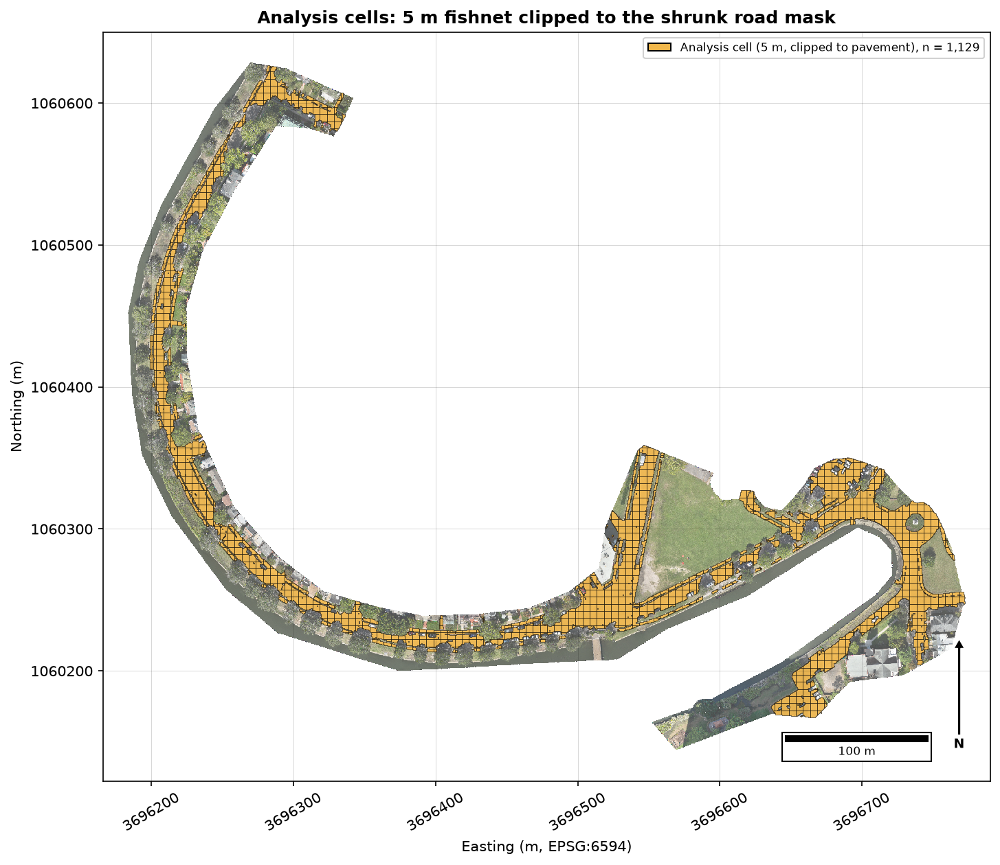

In [58]:
# ---------------------------------------------------------------------
# 03.4 (Step F) — Map of the analysis cells (fishnet clipped to the shrunk road mask)
# ---------------------------------------------------------------------
print(f"Map: the {len(cells_gdf):,} analysis cells ({FISHNET_CELL_M} m fishnet clipped to the shrunk road mask)")
fig, ax = plt.subplots(figsize=(10, 8.5), dpi=FIG_DPI)
draw_imagery(ax, alpha=0.7)
cells_gdf.plot(ax=ax, facecolor=COLOR_CELLS, edgecolor="black", linewidth=0.3, alpha=0.9, zorder=2)
ax.legend(handles=[mpatches.Patch(facecolor=COLOR_CELLS, edgecolor="black",
                                  label=f"Analysis cell ({FISHNET_CELL_M} m, clipped to pavement), n = {len(cells_gdf):,}")],
          loc="upper right", fontsize=8, framealpha=0.9)
ax.set_xlim(P_EXTENT[0], P_EXTENT[1]); ax.set_ylim(P_EXTENT[2], P_EXTENT[3])
map_axes(ax, f"Analysis cells: {FISHNET_CELL_M} m fishnet clipped to the shrunk road mask")
plt.tight_layout()
save_fig(fig, 16, "AnalysisCells", 3, maps=True)
plt.show()

**What the map shows.**

- **The cells.** The 1,129 analysis cells tile the pavement corridor continuously. Inner cells are full 5 × 5 m
  squares.
- **Edge cells.** Cells along the curb lines, sidewalks and driveways are clipped slivers: 59 % of cells have less
  than half a full square of pavement.
- **Why it matters.** The cell size is recorded (`AreaFrac`), so later steps can weight or filter the slivers.

In [59]:
# ---------------------------------------------------------------------
# 03.5 (Step A) — Section 03 key numbers: list of every clean output
# ---------------------------------------------------------------------
clean_files = pd.DataFrame([(p.parent.name, p.name, f"{p.stat().st_size / 1e6:.2f} MB")
                            for p in sorted(CLEAN.glob(f"OUT_DATA_{NB}_Sec*/*"))], columns=["Folder", "File", "Size"])
print(f"Clean outputs in {CLEAN.relative_to(PROJECT)}:")
display(clean_files)

Clean outputs in DATA\02_Clean_Data:


,Folder,File,Size
0,OUT_DATA_NB00_Sec00,DEM_MHHW_0p5m.tif,1.03 MB
1,OUT_DATA_NB00_Sec00,DEM_MHHW_WtrHC_0p5m.tif,0.93 MB
2,OUT_DATA_NB00_Sec00,DEM_NAVD88_0p5m.tif,1.03 MB
3,OUT_DATA_NB00_Sec00,FloodDays_2025_0p5m.tif,0.99 MB
4,OUT_DATA_NB00_Sec00,Imagery_dry_GridSpec.json,0.00 MB
5,OUT_DATA_NB00_Sec00,VDatum_MHHWinNAVD88_0p5m.tif,0.83 MB
6,OUT_DATA_NB00_Sec00,WaterSurface_0p5m.tif,0.01 MB
7,OUT_DATA_NB00_Sec01,Crack_Count_0p5m.tif,0.05 MB
8,OUT_DATA_NB00_Sec01,CrackDensity_0p5m.tif,0.11 MB
9,OUT_DATA_NB00_Sec01,CrackValid_Count_0p5m.tif,0.07 MB


--------------------------------------------------------------------------------------

**Section 03 summary: data cleaning.**

- **Filtered & reprojected.**
  - Every vector layer was reprojected from WGS84 (API layers) or its own CRS (custom files) to EPSG:6594 and
    clipped to the study area.
  - Downloaded features that only touch the padded query box are dropped here: 17 VGIN segments, 12 driveways and
    48 sidewalk lines.
- **Snapped.**
  - All raster information sits on one 0.5 m grid sharing its origin with the 0.02 m imagery.
  - The 5 m analysis cells are aligned to that grid, so every cell value is an exact sum or a pavement-weighted mean
    of whole 0.5 m cells.
  - The crack information is exact, because it is counted rather than resampled.
- **Joined.**
  - `VDOT_AADT` comes with the VGIN centerlines and becomes a non-overlapping **traffic polygon**.
  - Each road cell takes the AADT of the polygon covering most of it. Cells that are mostly sidewalk/driveway are
    labeled Sidewalk (AADT = 0).
  - The result is one tidy table, `AnalysisCells_5m.csv`, also saved as a GeoPackage layer. It has one row per 5 m
    analysis cell (1,129 cells × 25 columns) with crack density, flood days (arithmetic and geometric mean),
    elevation, sidewalk share and traffic class.
  - Every cell has a valid flood-days value. 360 cells are sidewalk/driveway, 628 are road cells with a traffic count
    (three AADT classes: 260, 1,200 and 4,500 vehicles/day), and 141 are uncounted road.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 04) Data integration & overlap

This section answers three questions, numbered after Section 02's Q4–Q6:

- **Q7) Resolution compatibility:** are the datasets' grids compatible, and how were they reconciled?
- **Q8) Spatial overlap:** how much of the pavement (the analysis cells) does each dataset cover, and do the layers
  line up?
- **Q9) Temporal overlap:** do the datasets describe the same period?

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 04.1 Resolution & grid alignment (Q7)

In [60]:
# ---------------------------------------------------------------------
# 04.1 (Step A) — Q7: resolution / alignment table of the rasters (native -> cleaned)
# ---------------------------------------------------------------------
def _align_row(name, meta, method, cleaned):
    same_crs = meta["crs"].equals(REF_CRS)
    ox, oy = grid_offset(meta) if same_crs else (np.nan, np.nan)
    unit = meta["crs"].axis_info[0].unit_name
    res_m = meta["res_x"] if unit in ("metre", "meter") else np.nan
    return {"Dataset": name, "Native CRS": meta["crs"].name, "Native pixel": f"{meta['res_x']:g} {unit}",
            "Pixel / imagery pixel": round(res_m / REF_RES, 2) if np.isfinite(res_m) else "different units",
            "Origin offset (imagery px)": f"({ox:.2f}, {oy:.2f})" if same_crs else "different CRS",
            "Snapped natively?": bool(same_crs and abs(ox - round(ox)) < 1e-3 and abs(oy - round(oy)) < 1e-3),
            "Cleaning method": method, "Cleaned resolution": cleaned}


align = pd.DataFrame([
    {"Dataset": "Imagery_dry (reference)", "Native CRS": REF_CRS.name, "Native pixel": f"{REF_RES} metre",
     "Pixel / imagery pixel": 1.0, "Origin offset (imagery px)": "(0.00, 0.00)", "Snapped natively?": True,
     "Cleaning method": "block-averaged into a downsampled preview for maps", "Cleaned resolution": f"{P_RES:.2f} m-pixel preview"},
    _align_row("Road mask (Shrunk3)", mm, f"counted into 0.5 m cells, then {FISHNET_CELL_M} m analysis cells",
               f"{G_RES} m / {FISHNET_CELL_M} m cells"),
    _align_row("Crack raster", cm, f"counted into 0.5 m cells, then {FISHNET_CELL_M} m analysis cells",
               f"{G_RES} m / {FISHNET_CELL_M} m cells"),
    _align_row("Drone DEM", dm, "bilinear resample onto the snapped grid; pavement-weighted cell mean", f"{G_RES} m / cells"),
    _align_row("NOAA VDatum", vm, "reproject + bilinear resample", f"{G_RES} m / cells"),
    _align_row("Flood days (derived)", fm_, "computed on the snapped grid; cell geometric mean", f"{G_RES} m / cells"),
]).set_index("Dataset")
print(f"Q7) Resolution compatibility: the crack raster and road mask share the 0.02 m imagery grid exactly; the DEM's "
      f"0.5 m cell is 25 imagery pixels but its corner is offset by a fraction of a cell, so it is resampled; VDatum is "
      f"reprojected from ~{_res_m:.0f} x {_res_my:.0f} m. Everything meets on the 0.5 m grid and is summarized into {FISHNET_CELL_M} m "
      f"analysis cells aligned to it.")
display(align)

Q7) Resolution compatibility: the crack raster and road mask share the 0.02 m imagery grid exactly; the DEM's 0.5 m cell is 25 imagery pixels but its corner is offset by a fraction of a cell, so it is resampled; VDatum is reprojected from ~40 x 50 m. Everything meets on the 0.5 m grid and is summarized into 5 m analysis cells aligned to it.


,Native CRS,Native pixel,Pixel / imagery pixel,Origin offset (imagery px),Snapped natively?,Cleaning method,Cleaned resolution
Dataset,,,,,,,
Imagery_dry (reference),NAD83(2011) / Virginia South,0.02 metre,1.0,"(0.00, 0.00)",True,block-averaged into a downsampled preview for ...,0.32 m-pixel preview
Road mask (Shrunk3),NAD83(2011) / Virginia South,0.02 metre,1.0,"(1645.00, 1189.00)",True,"counted into 0.5 m cells, then 5 m analysis cells",0.5 m / 5 m cells
Crack raster,NAD83(2011) / Virginia South,0.02 metre,1.0,"(1645.00, 1189.00)",True,"counted into 0.5 m cells, then 5 m analysis cells",0.5 m / 5 m cells
Drone DEM,NAD83(2011) / Virginia South,0.5 metre,25.0,"(845.57, 1067.61)",False,bilinear resample onto the snapped grid; pavem...,0.5 m / cells
NOAA VDatum,WGS 84,0.000449158 degree,different units,different CRS,False,reproject + bilinear resample,0.5 m / cells
Flood days (derived),NAD83(2011) / Virginia South,0.5 metre,25.0,"(0.00, 0.00)",True,computed on the snapped grid; cell geometric mean,0.5 m / cells


**What the table shows.**

- **Exact matches.** The road mask and crack raster are already on the imagery grid. Their corners sit a whole number
  of pixels (1,645, 1,189) from the imagery corner, so they need no resampling. The flood-days raster is computed on
  the snapped grid and is aligned by construction.
- **DEM.** Its pixel is exactly 25 imagery pixels, but its corner is offset by 845.57 × 1,067.61 imagery pixels, a
  fractional shift of about 0.4 × 0.5 of a DEM cell. It is therefore bilinearly resampled, which moves values by at
  most a quarter metre.
- **VDatum.** It is in geographic degrees (WGS 84) and is reprojected. Its 1.1 mm range over the site makes the
  resampling method irrelevant.

### 04.2 Spatial overlap with the analysis cells (Q8)

In [61]:
# ---------------------------------------------------------------------
# 04.2 (Step A) — Q8: share of the analysis cells covered by each dataset
# ---------------------------------------------------------------------
_pr = np.minimum(((np.arange(P_H) + 0.5) * PF // AGG_FACTOR).astype(int), G_H - 1)
_pc = np.minimum(((np.arange(P_W) + 0.5) * PF // AGG_FACTOR).astype(int), G_W - 1)
_img_on_grid = np.zeros((G_H, G_W), "float32")
_img_on_grid[np.ix_(_pr, _pc)] = img_valid
_img_cover = fish_wmean(_img_on_grid)[cells["FishnetID"]]
overlap = pd.Series({
    "Imagery (full cell has imagery)": (_img_cover >= 0.999).mean(),
    "Drone DEM (valid elevation)": cells["DEM_NAVD88"].notna().mean(),
    "VDatum (valid value)": cells["VDatum"].notna().mean(),
    "Flood days (valid value)": cells["LogFloodDays"].notna().mean(),
    "Touches the water surface": (cells["WaterFrac"] > 0).mean(),
    "Crack raster (every pavement pixel classified)": (cells["ValidPx"] == cells["MaskPx"]).mean(),
    "Traffic polygon (any overlap)": (cells["AADT_PolyShare"] > 0).mean(),
    "AADT assigned (Road cells with a count)": ((cells["SurfaceType"] == "Road") & cells["AADT"].notna()).mean(),
    "Sidewalk/driveway cells": (cells["SurfaceType"] == "Sidewalk").mean(),
    "Full-size cells (AreaFrac >= 0.5)": (cells["AreaFrac"] >= 0.5).mean(),
}) * 100
print(f"Q8) Spatial overlap: of the {len(cells):,} analysis cells, {overlap['Drone DEM (valid elevation)']:.1f} % have "
      f"a DEM value, {overlap['Flood days (valid value)']:.1f} % a flood-days value, "
      f"{overlap['AADT assigned (Road cells with a count)']:.1f} % are road cells with a traffic count, and "
      f"{overlap['Sidewalk/driveway cells']:.1f} % are sidewalk/driveway cells.")
display(overlap.round(1).to_frame("% of analysis cells"))

Q8) Spatial overlap: of the 1,129 analysis cells, 100.0 % have a DEM value, 100.0 % a flood-days value, 55.6 % are road cells with a traffic count, and 31.9 % are sidewalk/driveway cells.


,% of analysis cells
Imagery (full cell has imagery),96.8
Drone DEM (valid elevation),100.0
VDatum (valid value),100.0
Flood days (valid value),100.0
Touches the water surface,0.0
Crack raster (every pavement pixel classified),97.1
Traffic polygon (any overlap),71.6
AADT assigned (Road cells with a count),55.6
Sidewalk/driveway cells,31.9
Full-size cells (AreaFrac >= 0.5),41.1


In [62]:
# ---------------------------------------------------------------------
# 04.2 (Step B) — Q8 alignment checks: centerlines on the pavement, accuracy points inside the cells
# ---------------------------------------------------------------------
_pts = []
for src, geom in zip(centerlines["Source"], centerlines.geometry):
    for line in getattr(geom, "geoms", [geom]):
        _xy = shapely.get_coordinates(shapely.line_interpolate_point(line, np.arange(0, line.length, G_RES)))
        _pts.append(pd.DataFrame({"Source": src, "x": _xy[:, 0], "y": _xy[:, 1]}))
cl_pts = pd.concat(_pts, ignore_index=True)
_r = ((REF_Y0 - cl_pts["y"]) // G_RES).astype(int).clip(0, G_H - 1)
_c = ((cl_pts["x"] - REF_X0) // G_RES).astype(int).clip(0, G_W - 1)
cl_pts["OnPavement"] = road_g[_r, _c]
cl_in_mask = cl_pts.groupby("Source")["OnPavement"].mean() * 100
# Inside the imaged corridor only (the VGIN lines also run along streets the drone never flew), and allowing 1 m
# of tolerance (the mask excludes curbs, shadows and joint lines next to a centerline).
cl_pts["Imaged"] = _img_on_grid[_r, _c] > 0
cl_pts["Within1m"] = ndimage.binary_dilation(road_g, iterations=int(round(1 / G_RES)))[_r, _c]
cl_in_mask_img = cl_pts[cl_pts["Imaged"]].groupby("Source")[["OnPavement", "Within1m"]].mean() * 100
_ar = ((REF_Y0 - acc.geometry.y) // G_RES).astype(int).clip(0, G_H - 1)
_ac = ((acc.geometry.x - REF_X0) // G_RES).astype(int).clip(0, G_W - 1)
pts_in_mask = road_g[_ar, _ac].mean() * 100
print("Q8) Alignment: share of centerline length (sampled every 0.5 m) that lies on pavement -- all lines: "
      + ", ".join(f"{k} {v:.1f} %" for k, v in cl_in_mask.items())
      + "; inside the imaged corridor: "
      + ", ".join(f"{k} {r['OnPavement']:.1f} % on pavement ({r['Within1m']:.1f} % within 1 m)"
                  for k, r in cl_in_mask_img.iterrows())
      + f"; accuracy points inside the pavement: {pts_in_mask:.1f} %")

Q8) Alignment: share of centerline length (sampled every 0.5 m) that lies on pavement -- all lines: Custom_AddRCL 60.5 %, VGIN_RCL 20.8 %; inside the imaged corridor: Custom_AddRCL 84.5 % on pavement (92.0 % within 1 m), VGIN_RCL 85.4 % on pavement (91.2 % within 1 m); accuracy points inside the pavement: 100.0 %


Bar chart: spatial overlap of each dataset with the analysis cells


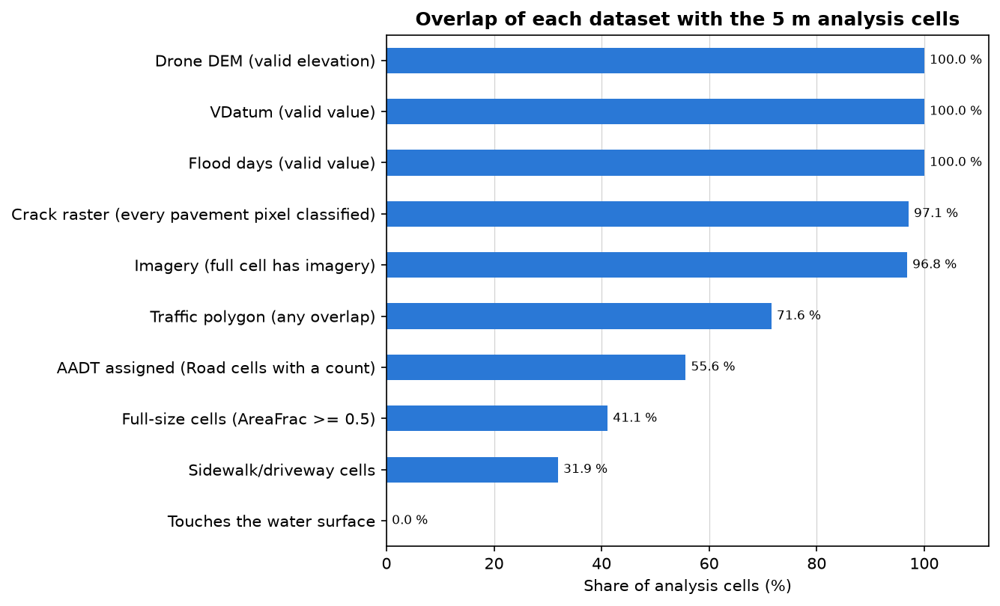

In [63]:
# ---------------------------------------------------------------------
# 04.2 (Step C) — Bar chart of the overlap
# ---------------------------------------------------------------------
print("Bar chart: spatial overlap of each dataset with the analysis cells")
fig, ax = plt.subplots(figsize=(9, 5.5), dpi=FIG_DPI)
_o = overlap.sort_values()
_o.plot.barh(ax=ax, color=COLOR_ROAD)
for i, v in enumerate(_o):
    ax.text(v + 1, i, f"{v:.1f} %", va="center", fontsize=8)
ax.set_xlim(0, 112); ax.set_xlabel("Share of analysis cells (%)")
ax.set_title(f"Overlap of each dataset with the {FISHNET_CELL_M} m analysis cells", fontweight="bold"); style_ax(ax, "x")
plt.tight_layout()
save_fig(fig, 17, "SpatialOverlap", 4)
plt.show()

**What the chart shows.**

- **Complete overlap.** Every analysis cell has a DEM, VDatum and flood-days value (100 %).
- **Nearly complete.** 97.1 % of the cells have every pavement pixel classified by the crack raster, and 96.8 % lie
  wholly inside the imagery footprint. The remaining few percent are edge cells where a handful of pixels are
  unclassified or fall on the boundary of the 0.32 m preview.
- **Traffic.** It is the least complete layer. The traffic polygon touches 71.6 % of the cells, but a count is
  assigned to 55.6 % (road cells only). The rest are sidewalk/driveway cells (31.9 %, which carry no traffic by
  definition) and uncounted road (12.5 %).
- **Water.** No analysis cell touches the water surface, so the pavement analysis is not affected by the water
  removal.
- **Alignment.** Every accuracy point falls on pavement. The centerline check above is lower for VGIN because the mask
  omits curbs, shadows and joint lines next to the road centre. Most of the VGIN length also runs through streets the
  drone did not fly; the corridor-only figures remove that effect.

### 04.3 Integrated maps

All cleaned layers together, from bottom to top:

1. imagery;
2. flood days per year on the pavement (01.8 classes);
3. water surface (cyan);
4. sidewalk/driveway surface (`Custom_Sidewalk` + City driveways, semi-transparent dark gray);
5. **Imagery Excluded From Mask** (black, 50 %);
6. classified cracks (semi-transparent red);
7. centerlines coloured by traffic.

The flood-day legend sits below each map. The three zoomed maps check how well the layers line up at full detail.
The vector layers came down in WGS84 and were reprojected to NAD83(2011), so a systematic shift of about a metre
between the VGIN centerlines and the imagery would point to a datum offset.

In [64]:
# ---------------------------------------------------------------------
# 04.3 (Step A) — Shared drawing function for the integrated maps
# ---------------------------------------------------------------------
_has_aadt = centerlines["AADT"].notna().any()
AADT_NORM = mcolors.LogNorm(vmin=max(np.nanmin(centerlines["AADT"]), 50) if _has_aadt else 50,
                            vmax=max(np.nanmax(centerlines["AADT"]), 100) if _has_aadt else 100)
COLOR_SWD_SURFACE = (0.25, 0.25, 0.25, 0.45)


def draw_integrated(fig, ax, ext=None):
    draw_imagery(ax, ext)
    ax.imshow(np.where(road_g, flood_g, np.nan), extent=G_EXTENT, cmap=FLOOD_CMAP, norm=FLOOD_NORM,
              interpolation="none", zorder=1)
    if len(water_c):
        water_c.plot(ax=ax, facecolor="cyan", edgecolor="none", alpha=0.5, zorder=2)
    if not sw_surface.is_empty:
        gpd.GeoSeries([sw_surface], crs=REF_CRS).plot(ax=ax, facecolor=COLOR_SWD_SURFACE, edgecolor="black",
                                                      linewidth=0.4, zorder=3)
    if ext is None:                                           # reverse mask + cracks on the 0.5 m grid
        _in_img = np.zeros_like(road_g); _in_img[:REF_H // AGG_FACTOR, :REF_W // AGG_FACTOR] = True
        ax.imshow(np.where((mask_frac_g < 0.5) & _in_img, 1, np.nan), extent=G_EXTENT, cmap=EXCL_CMAP,
                  interpolation="none", zorder=4)
        ax.imshow(np.where(crack_cnt > 0, 1, np.nan), extent=G_EXTENT, cmap=CRACK_CMAP, interpolation="none", zorder=5)
    else:                                                     # zoom: full-detail reverse mask + cracks
        zmask, zext = read_ref_window(mm, mask_path, ext, ZOOM_CRACK_FACTOR, "mean", ROAD_MASK_VALUE)
        zcrack, _ = read_ref_window(cm, crack_path, ext, ZOOM_CRACK_FACTOR, "max", CRACK_VALUE)
        ax.imshow(np.where(zmask < 0.5, 1, np.nan), extent=zext, cmap=EXCL_CMAP, interpolation="none", zorder=4)
        ax.imshow(np.where(zcrack, 1, np.nan), extent=zext, cmap=CRACK_CMAP, interpolation="none", zorder=5)
    centerlines[centerlines["AADT"].isna()].plot(ax=ax, zorder=6, linestyle="--", **outlined("white", 1.2))
    if _has_aadt:
        centerlines[centerlines["AADT"].notna()].plot(ax=ax, column="AADT", cmap="plasma", norm=AADT_NORM,
                                                      linewidth=2.5, zorder=7)
    if ext is not None:
        set_extent(ax, ext)
    leg1 = ax.legend(handles=[mpatches.Patch(color=(0, 0, 0, 0.5), label="Imagery Excluded From Mask"),
                       mpatches.Patch(color=(1, 0, 0, 0.75), label="Classified cracks"),
                       mpatches.Patch(color="cyan", alpha=0.5, label="Water surface"),
                       mpatches.Patch(facecolor=COLOR_SWD_SURFACE, edgecolor="black", label="Sidewalk/driveway surface"),
                       mlines.Line2D([], [], linestyle="--", label="Centerline, no AADT", **outlined("white", 1.5))],
              loc="upper right", fontsize=8, framealpha=0.9)
    ax.add_artist(leg1)
    fig.colorbar(plt.cm.ScalarMappable(norm=AADT_NORM, cmap="plasma"), ax=ax, shrink=0.6,
                 label="Centerline VDOT AADT (vehicles/day, log scale)")
    ax.legend(handles=FLOOD_HANDLES, title=f"Pavement: flood days per year ({FLOOD_YEAR}, Ezer 2022)", loc="upper center",
              ncol=5, fontsize=8, title_fontsize=8.5, bbox_to_anchor=(0.5, -0.13), framealpha=1)

Map: all cleaned layers over the imagery (full site)


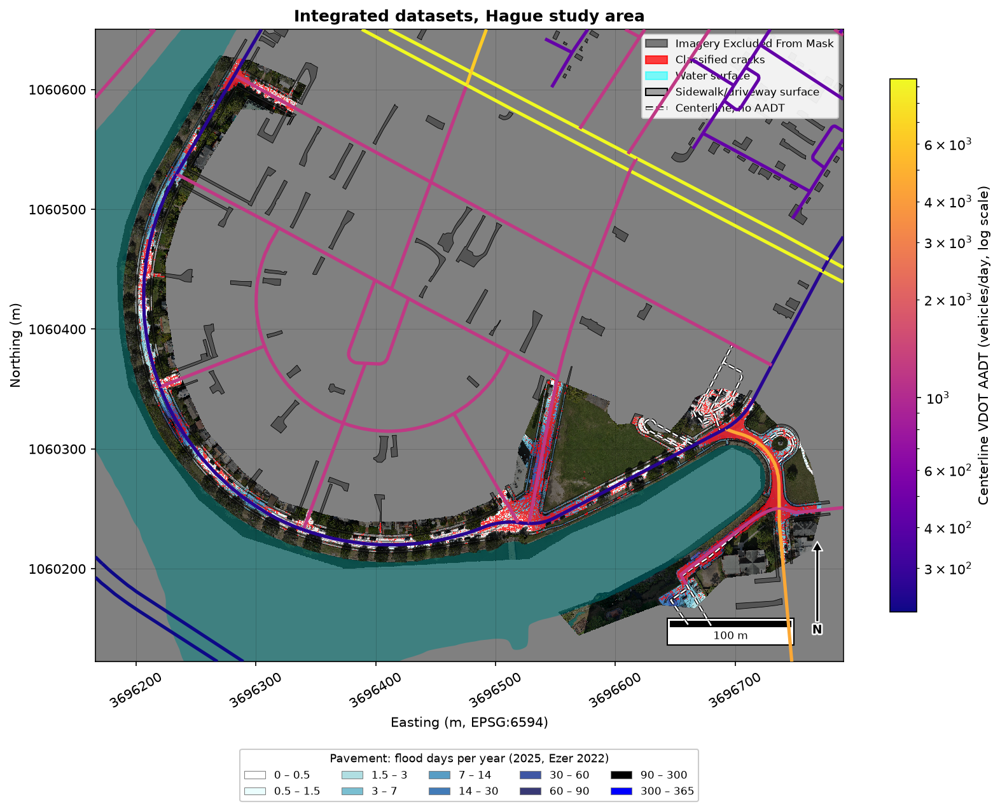

In [65]:
# ---------------------------------------------------------------------
# 04.3 (Step B) — Integrated map, full site
# ---------------------------------------------------------------------
print("Map: all cleaned layers over the imagery (full site)")
fig, ax = plt.subplots(figsize=(11, 10), dpi=FIG_DPI)
draw_integrated(fig, ax)
map_axes(ax, "Integrated datasets, Hague study area")
plt.tight_layout()
save_fig(fig, 18, "IntegratedOverview", 4, maps=True)
plt.show()

Map: all cleaned layers -- Botetourt St & Mowbray Arch


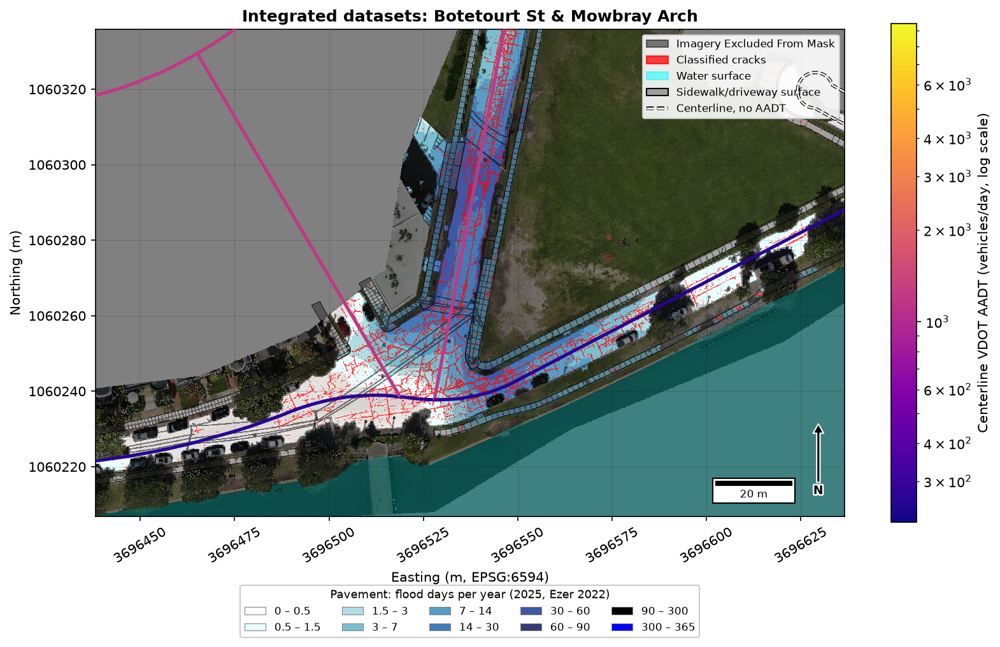

Map: all cleaned layers -- Memorial Pl & Mowbray Arch


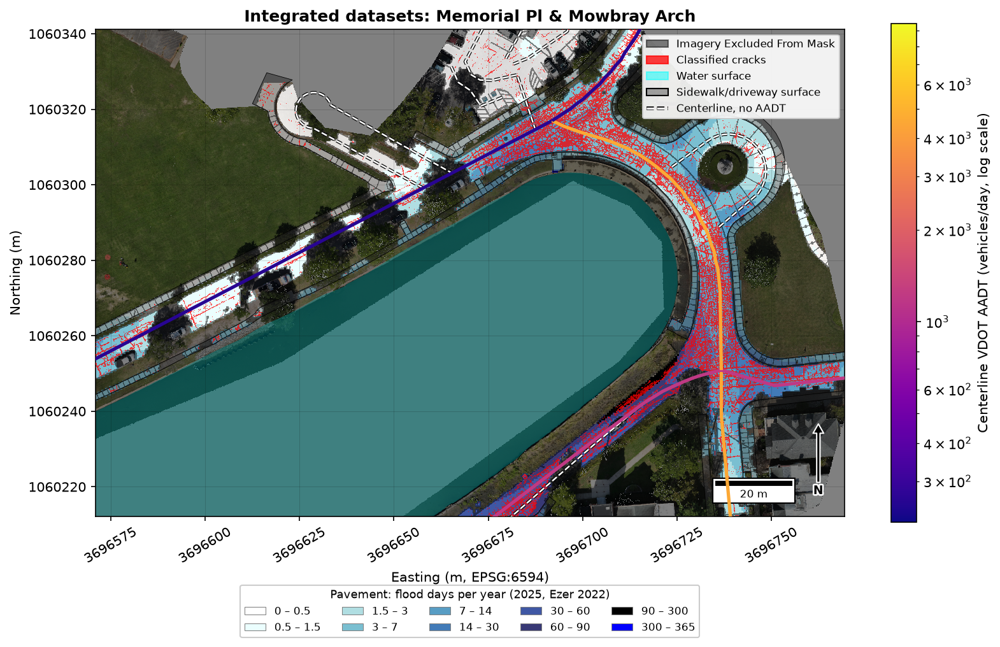

Map: all cleaned layers -- Mowbray Arch & Fairfax Ave


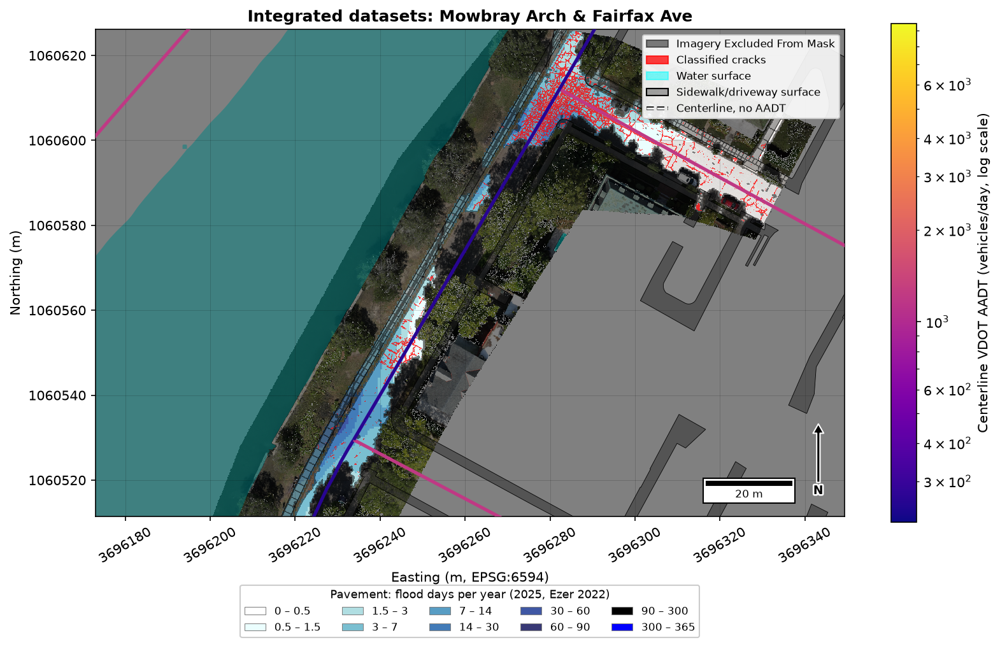

In [66]:
# ---------------------------------------------------------------------
# 04.3 (Step C) — Integrated maps, zoom extents (alignment check)
# ---------------------------------------------------------------------
for i, (name, ext) in enumerate(ZOOM_EXTENTS.items()):
    print(f"Map: all cleaned layers -- {name}")
    fig, ax = plt.subplots(figsize=(11, 9), dpi=FIG_DPI)
    draw_integrated(fig, ax, ext)
    map_axes(ax, f"Integrated datasets: {name}")
    plt.tight_layout()
    save_fig(fig, 19 + i, f"IntegratedZoom{i + 1}", 4, maps=True)
    plt.show()

**What the maps show.**

- **Centerline alignment.** The VGIN centerlines (coloured by AADT) follow every imaged street, with no consistent
  shift in one direction. The WGS 84 → NAD83(2011) reprojection therefore introduced no datum offset. Locally a line
  sits 1–3 m off the road centre, e.g. along Botetourt St and the curve of Mowbray Arch. This is why the traffic
  polygon uses a 6 m buffer and a largest-overlap rule rather than a nearest-line join. `Custom_AddRCL` (dashed white)
  follows the parking-lot lanes it was drawn on.
- **Layers line up with the imagery.** The sidewalk/driveway surface (dark grey) sits on the sidewalks and
  driveways, and the water surface (cyan) meets the shoreline.
- **Cracks and flood exposure.** The cracks (red) lie inside the pavement mask. The flood classes mark the lowest
  pavement along Botetourt St and the east-end streets, where cracks are also dense. The Memorial Pl loop, the
  busiest counted street (4,500 vehicles/day), is both heavily cracked and frequently flooded. That overlap matters
  when traffic and flooding are separated in Section 07.

### 04.4 Temporal overlap (Q9)

In [67]:
# ---------------------------------------------------------------------
# 04.4 (Step A) — Q9: time offset of every dataset relative to the 3 Oct 2025 survey
# ---------------------------------------------------------------------
_tq = temporal[["Dataset", "Start", "End", "Years before imagery (start)"]].copy()
_tq["Overlaps the 2025 survey?"] = (_tq["Start"] <= IMAGERY_DATE) & (_tq["End"] >= pd.Timestamp("2025-01-01"))
_same = _tq.loc[_tq["Overlaps the 2025 survey?"], "Dataset"].tolist()
_not = _tq.loc[~_tq["Overlaps the 2025 survey?"], "Dataset"].tolist()
print(f"Q9) Temporal overlap: {len(_same)} of {len(_tq)} datasets cover 2025 ({', '.join(_same)}). "
      f"The other {len(_not)} ({', '.join(_not)}) are older snapshots (City layers, 2006-2008 aerials) or a static "
      "datum surface (VDatum, 1983-2001 tidal epoch). The NOAA record (1927-2026) and the projection (2000-2100) are "
      "long reference periods that include 2025.")
display(_tq)

Q9) Temporal overlap: 11 of 14 datasets cover 2025 (Drone imagery (Imagery_dry), Drone DEM, VGIN RCL + VDOT_AADT, Custom_AddRCL, Custom_Sidewalk, WaterSurface_Final, Road mask & crack raster, Accuracy points, NOAA sea level trend (Sewells Point), NOAA 2017 SLR projection, Flood days per year (derived)). The other 3 (NOAA VDatum (MHHW in NAVD88), Norfolk Driveways, Norfolk Sidewalks) are older snapshots (City layers, 2006-2008 aerials) or a static datum surface (VDatum, 1983-2001 tidal epoch). The NOAA record (1927-2026) and the projection (2000-2100) are long reference periods that include 2025.


,Dataset,Start,End,Years before imagery (start),Overlaps the 2025 survey?
0,Drone imagery (Imagery_dry),2025-10-03,2025-10-03,0.0,True
1,Drone DEM,2025-10-03,2025-10-03,0.0,True
2,NOAA VDatum (MHHW in NAVD88),1983-01-01,2001-12-31,42.8,False
3,VGIN RCL + VDOT_AADT,2012-02-22,2026-09-21,13.6,True
4,Custom_AddRCL,2025-10-03,2025-10-03,0.0,True
5,Norfolk Driveways,2006-01-01,2008-12-31,19.8,False
6,Norfolk Sidewalks,2006-01-01,2006-12-31,19.8,False
7,Custom_Sidewalk,2025-10-03,2025-10-03,0.0,True
8,WaterSurface_Final,2023-09-13,2025-10-03,2.1,True
9,Road mask & crack raster,2025-10-03,2025-10-03,0.0,True


**Temporal overlap in context:**

- **Same survey.** Cracks, pavement mask, elevation, flood days, water surface and the custom sidewalk/centerline
  layers all describe the **October 2025** surface, so they overlap fully in time. The custom layers were digitized
  in 2026, but on the 2025 imagery.
- **Traffic.** `VDOT_AADT` is one recent count for roads that cracked over many years before it. Traffic is treated
  as a slowly varying background condition, not a time-matched measurement. Segment edits in the study area run from
  2012 to September 2026, and the count year is not stated.
- **Flood exposure.**
  - The flood-days raster models the **2025** tide climate, whereas cracking builds up over a pavement's whole
    service life.
  - Comparing them in one snapshot assumes the *relative* flood exposure of each spot has been similar over that
    period. That is reasonable because exposure follows elevation, which changes little.
  - The NOAA record (05.7) shows how much the absolute level has risen over the same decades: about 0.47 m since
    1927 at 4.83 mm/yr, or ≈ 0.12 m over the 25 years since 2000.
- **Old City layers.** The 2006–2008 City sidewalk/driveway layers do not overlap the 2025 conditions. The City
  driveways help define the sidewalk/driveway surface, and the 2025 custom polygons cover the sidewalks.
- **VDatum.** It refers to the 1983–2001 National Tidal Datum Epoch. MHHW has risen with sea level since then, so
  the modelled exposure is relative to an older high-tide level. In Ezer's (2022) equation, the RSLR term accounts for
  that rise.

--------------------------------------------------------------------------------------

**Section 04 summary: data integration & overlap.**

- **Q7) Resolution.**
  - The crack raster and road mask share the imagery's 0.02 m grid exactly, so counting them into cells is lossless.
  - The DEM's 0.5 m cell is an exact multiple (×25) of the imagery pixel. Its corner is a fraction of a cell off, so
    the resample in 00.1 moves values by less than half a cell (≤ 0.25 m).
  - VDatum (~40 × 50 m pixels) varies only slowly across the site. It shifts the *level* of exposure much more than its
    *pattern*.
  - The 5 m analysis cells are aligned to the 0.5 m grid, so every per-cell value is exact.
- **Q8) Space.**
  - The DEM, VDatum and flood days cover 100 % of the 1,129 analysis cells. The crack raster fully classifies 97.1 % of
    them, and the imagery covers 96.8 % in full.
  - Traffic is the limiting layer. 55.6 % of all cells (81.7 % of the road cells) carry an AADT count. Sidewalk cells
    (31.9 %) carry no traffic by definition, and 12.5 % are uncounted road.
  - All 150 accuracy points fall on pavement, and the integrated maps show no systematic offset between the API
    vector layers and the imagery.
- **Q9) Time.** 11 of the 14 datasets include 2025, and the core variables come from one survey date (3 October
  2025). Traffic and the City layers are older snapshots and are treated as background conditions. VDatum is tied to
  the 1983–2001 tidal epoch.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 05) Descriptive statistics & distributions

Each dataset gets the same three items, in this order:

- **Step A:** a descriptive-statistics table;
- **Step B:** a distribution plot (histogram, box plot and/or bar chart);
- **Step C:** additional figures, where there are any.

Variables measured on the pavement use the **5 m analysis cells** with a valid flood-days value (`cells_land`).
Outliers are covered separately in Section 06.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 05.1 Drone imagery

Statistics use the downsampled imagery preview (0.32 m pixels), split into pavement and everything else.

**Why the mask matters.** The colour bands differ sharply between the masked pavement and everything else. That is
why a tightly drawn pavement mask was essential. It keeps the custom deep-learning crack model working only on
pavement, where cracks can actually occur, and stops it from producing false positives on roofs, vegetation, cars
and shadows that look nothing like the surfaces it was trained on.

In [68]:
# ---------------------------------------------------------------------
# 05.1 (Step A) — Imagery: descriptive statistics by band, pavement vs everything else
# ---------------------------------------------------------------------
road_p = road_g[np.ix_(_pr, _pc)] & img_valid
other_p = ~road_g[np.ix_(_pr, _pc)] & img_valid
img_stats = pd.concat({"Pavement": pd.DataFrame({b: nice_stats(rgb_u8[i][road_p], b, "DN") for i, b in
                                                 enumerate(["Red", "Green", "Blue"])}).T,
                       "Everything else": pd.DataFrame({b: nice_stats(rgb_u8[i][other_p], b, "DN") for i, b in
                                                        enumerate(["Red", "Green", "Blue"])}).T})
print("Descriptive statistics of the 0.32 m-pixel imagery preview (digital numbers, 0-255):")
display(img_stats.round(1))

Descriptive statistics of the 0.32 m-pixel imagery preview (digital numbers, 0-255):


count   mean   std  min    25%  50% (median)    75%    max   IQR  skewness
Pavement        Red    154451.0  167.0  40.4  0.0  149.0         169.0  191.0  255.0  42.0      -0.8
                Green  154451.0  158.2  36.5  0.0  142.0         159.0  180.0  255.0  38.0      -0.7
                Blue   154451.0  146.3  34.4  0.0  131.0         148.0  167.0  254.0  36.0      -0.7
Everything else Red    394408.0   92.0  54.7  0.0   50.0          85.0  125.0  255.0  75.0       0.6
                Green  394408.0   96.6  51.3  0.0   57.0          92.0  131.0  255.0  74.0       0.5
                Blue   394408.0   70.1  47.7  0.0   40.0          57.0   88.0  255.0  48.0       1.4

Histograms: imagery brightness by band, pavement vs everything else


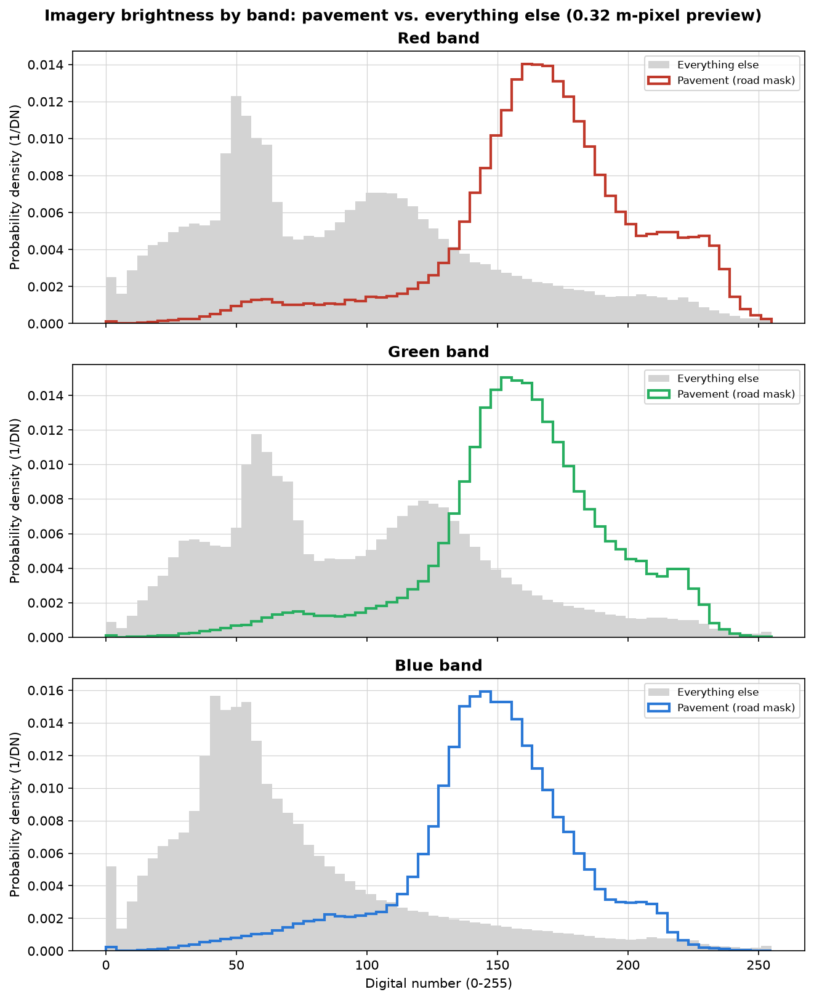

In [69]:
# ---------------------------------------------------------------------
# 05.1 (Step B) — Imagery: RGB histograms, pavement vs everything else (3 stacked)
# ---------------------------------------------------------------------
print("Histograms: imagery brightness by band, pavement vs everything else")
fig, axes = plt.subplots(3, 1, figsize=(9, 11), dpi=FIG_DPI, sharex=True)
for i, (ax, band, colr) in enumerate(zip(axes, ["Red", "Green", "Blue"], ["#c0392b", "#27ae60", "#2a78d6"])):
    ax.hist(rgb_u8[i][other_p], bins=64, range=(0, 255), density=True, color="lightgray", label="Everything else")
    ax.hist(rgb_u8[i][road_p], bins=64, range=(0, 255), density=True, histtype="step", linewidth=2, color=colr,
            label="Pavement (road mask)")
    ax.set_ylabel("Probability density (1/DN)"); ax.set_title(f"{band} band", fontweight="bold")
    style_ax(ax); ax.legend(fontsize=8, loc="upper right")
axes[-1].set_xlabel("Digital number (0-255)")
fig.suptitle("Imagery brightness by band: pavement vs. everything else (0.32 m-pixel preview)", fontweight="bold")
plt.tight_layout()
save_fig(fig, 22, "Imagery_RGB_Distributions", 5)
plt.show()

**What the table and histograms show.**

- **Brightness.** Pavement is much **brighter** than everything else in all three bands. Its mean R/G/B is
  167/158/146 digital numbers, against 92/97/70 elsewhere.
- **Spread.** Pavement is also more uniform: a standard deviation of 34–40 against 48–55, and an IQR of 36–42
  against 48–75.
- **Shape.** Pavement forms one narrow peak at about 150–170. It has a bright shoulder at about 210–230 (light
  concrete sidewalks) and a thin dark tail (shadows and stains, see 06.1).
- **Everything else.** The rest of the image is spread across the whole range, with a large dark peak near 50
  (shadow, trees, water). Its blue band is especially low (vegetation).

Without the mask, the crack model would see this whole range: dark, textured surfaces that resemble cracks far more
than smooth pavement does.

### 05.2 Drone DEM: elevation (NAVD88 and above MHHW)

In [70]:
# ---------------------------------------------------------------------
# 05.2 (Step A) — DEM: descriptive statistics
# ---------------------------------------------------------------------
elev_stats = pd.DataFrame([
    nice_stats(dem_raw, "DEM native 0.5 m, whole DEM", "m NAVD88"),
    nice_stats(dem_g, "DEM on raster grid, study area", "m NAVD88"),
    nice_stats(wtrhc_g, "DEM above MHHW, land", "m MHHW"),
    nice_stats(cells_land["ElevMHHW"], f"Cell mean above MHHW, {FISHNET_CELL_M} m cells", "m MHHW")])
print("Descriptive statistics of elevation:")
display(elev_stats.round(3))
print(f"Analysis cells with a mean elevation at or below MHHW: {(cells_land['ElevMHHW'] <= 0).mean() * 100:.2f} %   |   "
      f"within 0.5 m above MHHW: {((cells_land['ElevMHHW'] > 0) & (cells_land['ElevMHHW'] <= 0.5)).mean() * 100:.1f} %")

Descriptive statistics of elevation:


,count,mean,std,min,25%,50% (median),75%,max,IQR,skewness
"DEM native 0.5 m, whole DEM (m NAVD88)",286856.0,1.325,0.689,-0.094,0.892,1.282,1.681,3.734,0.789,0.374
"DEM on raster grid, study area (m NAVD88)",286856.0,1.325,0.689,-0.066,0.891,1.282,1.681,3.718,0.790,0.376
"DEM above MHHW, land (m MHHW)",260510.0,1.056,0.597,-0.417,0.612,0.968,1.343,3.332,0.732,0.898
"Cell mean above MHHW, 5 m cells (m MHHW)",1129.0,0.752,0.359,-0.040,0.483,0.708,1.011,2.244,0.528,0.573


Analysis cells with a mean elevation at or below MHHW: 0.09 %   |   within 0.5 m above MHHW: 26.7 %


**What the table shows.**

- **Resampling.** Snapping the DEM to the analysis grid leaves its statistics unchanged (mean 1.325 m, median
  1.282 m NAVD88). Bilinear resampling only trims the extreme cells.
- **Land vs. pavement.** Above MHHW, land has a median of 0.97 m. The 5 m pavement cells are lower: median 0.71 m,
  IQR 0.48–1.01 m, range −0.04 to 2.24 m.
- **Near the high-tide line.** Only one analysis cell (0.09 %) has a mean at or below MHHW, but 26.7 % lie within
  0.5 m above it.

Histogram + box plot: elevation above MHHW


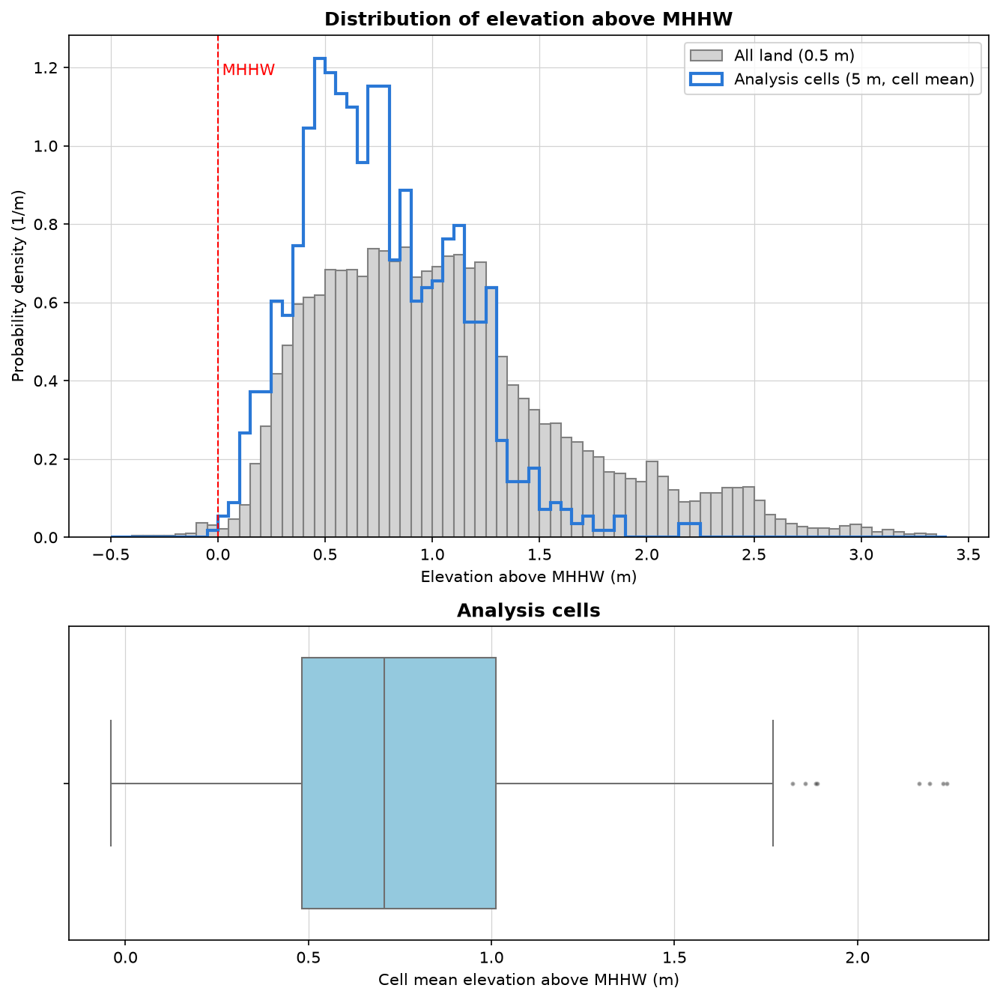

In [71]:
# ---------------------------------------------------------------------
# 05.2 (Step B) — DEM: histogram (land vs analysis cells) and box plot
# ---------------------------------------------------------------------
print("Histogram + box plot: elevation above MHHW")
fig, axes = plt.subplots(2, 1, figsize=(9, 9), dpi=FIG_DPI, gridspec_kw=dict(height_ratios=[1.6, 1]))
ax = axes[0]
_bins = np.arange(np.floor(np.nanmin(wtrhc_g) * 10) / 10, np.nanmax(wtrhc_g) + 0.1, 0.05)
ax.hist(wtrhc_g[np.isfinite(wtrhc_g)], bins=_bins, density=True, color="lightgray", edgecolor="gray", label="All land (0.5 m)")
ax.hist(cells_land["ElevMHHW"], bins=_bins, density=True, histtype="step", linewidth=2, color=COLOR_ROAD,
        label=f"Analysis cells ({FISHNET_CELL_M} m, cell mean)")
ax.axvline(0, color="red", linestyle="--", linewidth=1); ax.text(0.02, ax.get_ylim()[1] * 0.92, "MHHW", color="red")
ax.set_xlabel("Elevation above MHHW (m)"); ax.set_ylabel("Probability density (1/m)")
ax.set_title("Distribution of elevation above MHHW", fontweight="bold"); ax.legend(loc="upper right"); style_ax(ax)
ax = axes[1]
sns.boxplot(x=cells_land["ElevMHHW"], ax=ax, color="skyblue",
            flierprops=dict(marker="o", markerfacecolor="black", markersize=2, alpha=0.4))
ax.set_xlabel("Cell mean elevation above MHHW (m)"); ax.set_title("Analysis cells", fontweight="bold"); style_ax(ax, "x")
plt.tight_layout()
save_fig(fig, 23, "Elevation_Distribution", 5)
plt.show()

**What the plots show.** The pavement cells (blue outline) are concentrated lower than the land as a whole (grey).
Their distribution is bimodal, with one peak at about 0.4–0.8 m and a second at about 1.0–1.3 m above MHHW: a low
group of streets and a higher one. Almost nothing reaches the MHHW line. The box plot shows a few high cells above
1.8 m, which are flagged in 06.2.

Map: analysis cells by mean elevation above MHHW


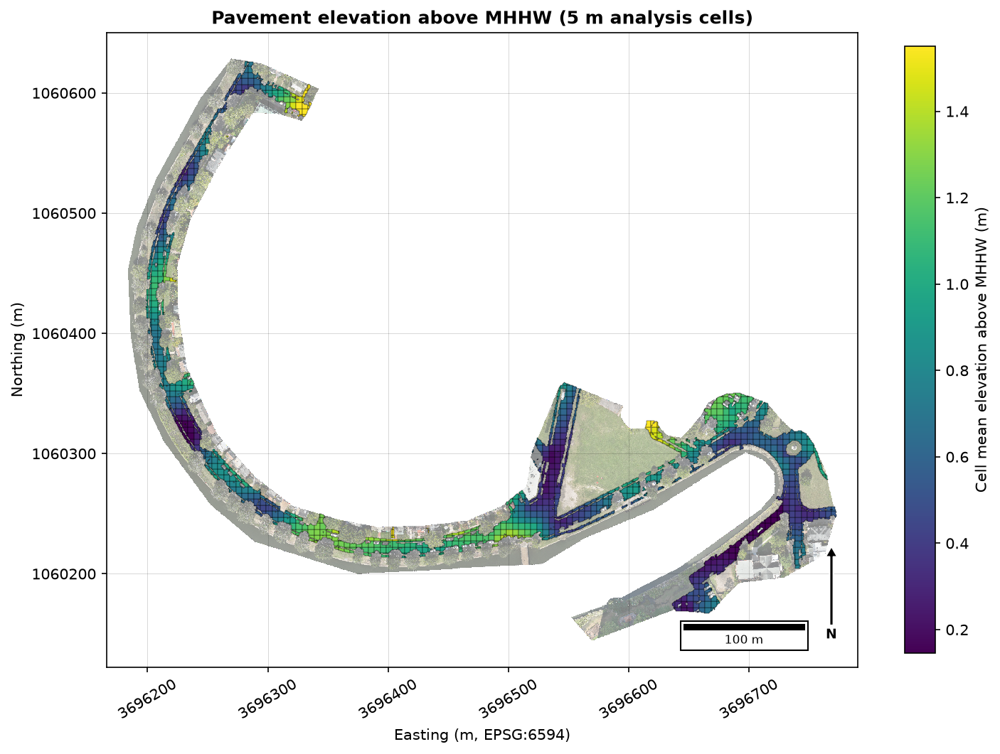

In [72]:
# ---------------------------------------------------------------------
# 05.2 (Step C) — DEM: map of the analysis cells by mean elevation above MHHW
# ---------------------------------------------------------------------
print("Map: analysis cells by mean elevation above MHHW")
fig, ax = plt.subplots(figsize=(10, 8.5), dpi=FIG_DPI)
draw_imagery(ax, alpha=0.5)
_v = np.nanpercentile(cells_land["ElevMHHW"], [2, 98])
cells_gdf.plot(ax=ax, column="ElevMHHW", cmap=CMAP_ELEV, vmin=_v[0], vmax=_v[1], edgecolor="black", linewidth=0.2,
               zorder=2, missing_kwds=dict(color="lightgray"))
fig.colorbar(plt.cm.ScalarMappable(norm=mcolors.Normalize(*_v), cmap=CMAP_ELEV), ax=ax, shrink=0.7,
             label="Cell mean elevation above MHHW (m)")
ax.set_xlim(P_EXTENT[0], P_EXTENT[1]); ax.set_ylim(P_EXTENT[2], P_EXTENT[3])
map_axes(ax, f"Pavement elevation above MHHW ({FISHNET_CELL_M} m analysis cells)")
plt.tight_layout()
save_fig(fig, 24, "Elevation_CellMap", 5, maps=True)
plt.show()

**What the map shows.** The lowest pavement (dark purple, < 0.4 m above MHHW) runs along Botetourt St on the west
side of the field, along the southeastern street at the east end, and at a low spot on the western arc. The highest
pavement (green-yellow, > 1.2 m) is along the southern arc and at the northern ends of the corridor. These are the
same places the flood-days map (05.8) shows as least and most flooded.

### 05.3 NOAA VDatum / MHHW

In [73]:
# ---------------------------------------------------------------------
# 05.3 (Step A) — VDatum: descriptive statistics
# ---------------------------------------------------------------------
display(pd.DataFrame([nice_stats(vdatum_raw, "VDatum, downloaded box", "m NAVD88"),
                      nice_stats(vdatum_g, "VDatum on raster grid, study area", "m NAVD88"),
                      nice_stats(cells_land["VDatum"], "VDatum, analysis cells", "m NAVD88")]).round(4))
print(f"Range of MHHW across the study area: {(np.nanmax(vdatum_g) - np.nanmin(vdatum_g)) * 1000:.1f} mm")

,count,mean,std,min,25%,50% (median),75%,max,IQR,skewness
"VDatum, downloaded box (m NAVD88)",6789.0,0.3854,0.0042,0.3713,0.3826,0.3859,0.3877,0.3941,0.0051,-0.1256
"VDatum on raster grid, study area (m NAVD88)",1318944.0,0.3862,0.0003,0.3859,0.3860,0.3860,0.3863,0.3870,0.0003,1.4946
"VDatum, analysis cells (m NAVD88)",1129.0,0.3863,0.0003,0.3860,0.3860,0.3863,0.3865,0.3868,0.0005,0.3520


Range of MHHW across the study area: 1.1 mm


Histogram: VDatum MHHW values (downloaded box)


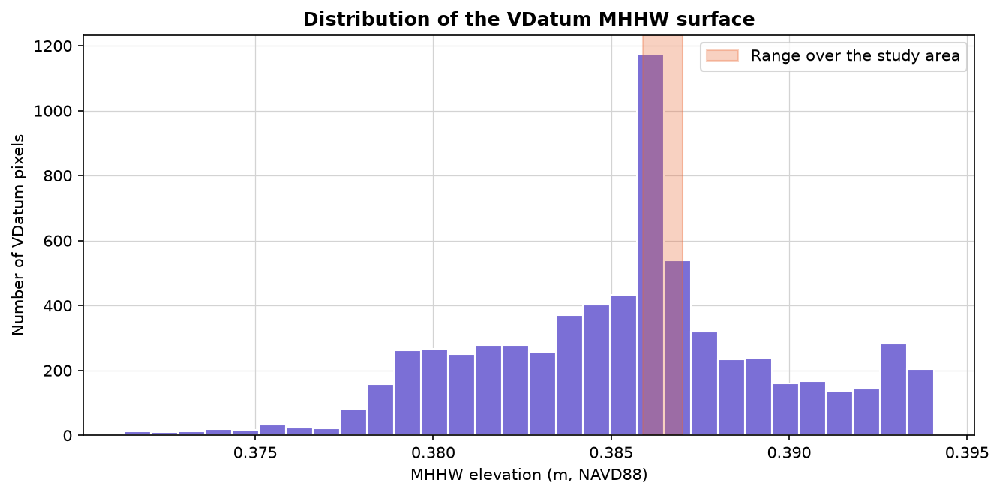

In [74]:
# ---------------------------------------------------------------------
# 05.3 (Step B) — VDatum: histogram of the pixel values in the downloaded box
# ---------------------------------------------------------------------
print("Histogram: VDatum MHHW values (downloaded box)")
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=FIG_DPI)
ax.hist(vdatum_raw[np.isfinite(vdatum_raw)], bins=30, color="#7b6fd6", edgecolor="white")
ax.axvspan(np.nanmin(vdatum_g), np.nanmax(vdatum_g), color=COLOR_ACCENT, alpha=0.3, label="Range over the study area")
ax.set_xlabel("MHHW elevation (m, NAVD88)"); ax.set_ylabel("Number of VDatum pixels")
ax.set_title("Distribution of the VDatum MHHW surface", fontweight="bold"); ax.legend(loc="upper right"); style_ax(ax)
plt.tight_layout()
save_fig(fig, 25, "VDatum_Distribution", 5)
plt.show()

**What the table and histogram show.**

- **Downloaded box.** The 6,789 pixels range from 0.371 to 0.394 m NAVD88 (standard deviation 4 mm).
- **Study area.** Inside it, the surface spans only 0.3859–0.3870 m (orange band, a range of 1.1 mm). Over the
  1,129 analysis cells the standard deviation is 0.3 mm.
- **Implication.** The conversion from NAVD88 to height above MHHW is effectively a constant subtraction of
  ≈ 0.386 m. VDatum sets the absolute level of the flood exposure but does not change its pattern.

### 05.4 Road attributes: road class and traffic (AADT, vehicles/day)

In [75]:
# ---------------------------------------------------------------------
# 05.4 (Step A) — Road attributes: descriptive statistics
# ---------------------------------------------------------------------
len_by_class = (centerlines.groupby(["MTFCC_Desc", "Source"])["Length_m"].sum().unstack(fill_value=0)
                .assign(Total=lambda d: d.sum(axis=1)).sort_values("Total"))
print("Centerline length inside the study area by road class (m):")
display(len_by_class.round(0).iloc[::-1])
_cnt = centerlines["AADT"].notna()
_name_col = "ST_FULL" if "ST_FULL" in centerlines.columns else "MTFCC_Desc"
print(f"AADT per street ({_name_col}; segments with a count, vehicles/day); counts on "
      f"{centerlines.loc[_cnt, 'Length_m'].sum() / centerlines['Length_m'].sum() * 100:.1f} % of the centerline length:")
display(centerlines[_cnt].groupby(_name_col).agg(Segments=("AADT", "size"), Length_m=("Length_m", "sum"),
                                                 AADT_min=("AADT", "min"), AADT_max=("AADT", "max"))
        .sort_values("AADT_max", ascending=False).round(0))
display(nice_stats(centerlines["AADT"], "AADT per counted segment", "vehicles/day").to_frame().T.round(0))
traffic_tbl = (cells.groupby("TrafficClass").agg(Cells=("CellID", "size"), PavementArea_m2=("CellArea_m2", "sum"))
               .reindex(TRAFFIC_ORDER))
traffic_tbl["% of cells"] = 100 * traffic_tbl["Cells"] / traffic_tbl["Cells"].sum()
print(f"Analysis cells by traffic / surface class ({FISHNET_CELL_M} m cells):")
display(traffic_tbl.round(1))

Centerline length inside the study area by road class (m):


Source,Custom_AddRCL,VGIN_RCL,Total
MTFCC_Desc,,,
Local roads,0.0,4688.0,4688.0
Secondary roads (local route),0.0,882.0,882.0
Unclassified (custom),507.0,0.0,507.0
Secondary roads (VDOT primary route),0.0,275.0,275.0


AADT per street (ST_FULL; segments with a count, vehicles/day); counts on 92.0 % of the centerline length:


,Segments,Length_m,AADT_min,AADT_max
ST_FULL,,,,
W Olney Rd,13,916.0,260.0,9500.0
Colonial Ave,5,368.0,1200.0,6300.0
Memorial Pl,1,90.0,4500.0,4500.0
Yarmouth St,1,129.0,4500.0,4500.0
Beechwood Pl,2,157.0,1200.0,1200.0
Drummond Pl,1,106.0,1200.0,1200.0
Boissevain Ave,1,14.0,1200.0,1200.0
Botetourt Gdns,4,223.0,1200.0,1200.0
Botetourt St,3,307.0,1200.0,1200.0


,count,mean,std,min,25%,50% (median),75%,max,IQR,skewness
AADT per counted segment (vehicles/day),85.0,2039.0,2942.0,220.0,440.0,1200.0,1200.0,9500.0,760.0,2.0


Analysis cells by traffic / surface class (5 m cells):


,Cells,PavementArea_m2,% of cells
TrafficClass,,,
Sidewalk/driveway,360,1659.3,31.9
Uncounted road,141,1453.9,12.5
AADT 260,354,4660.0,31.4
"AADT 1,200",207,3257.3,18.3
"AADT 4,500",67,1262.7,5.9


Bar charts: road length by class, and analysis cells by traffic / surface class


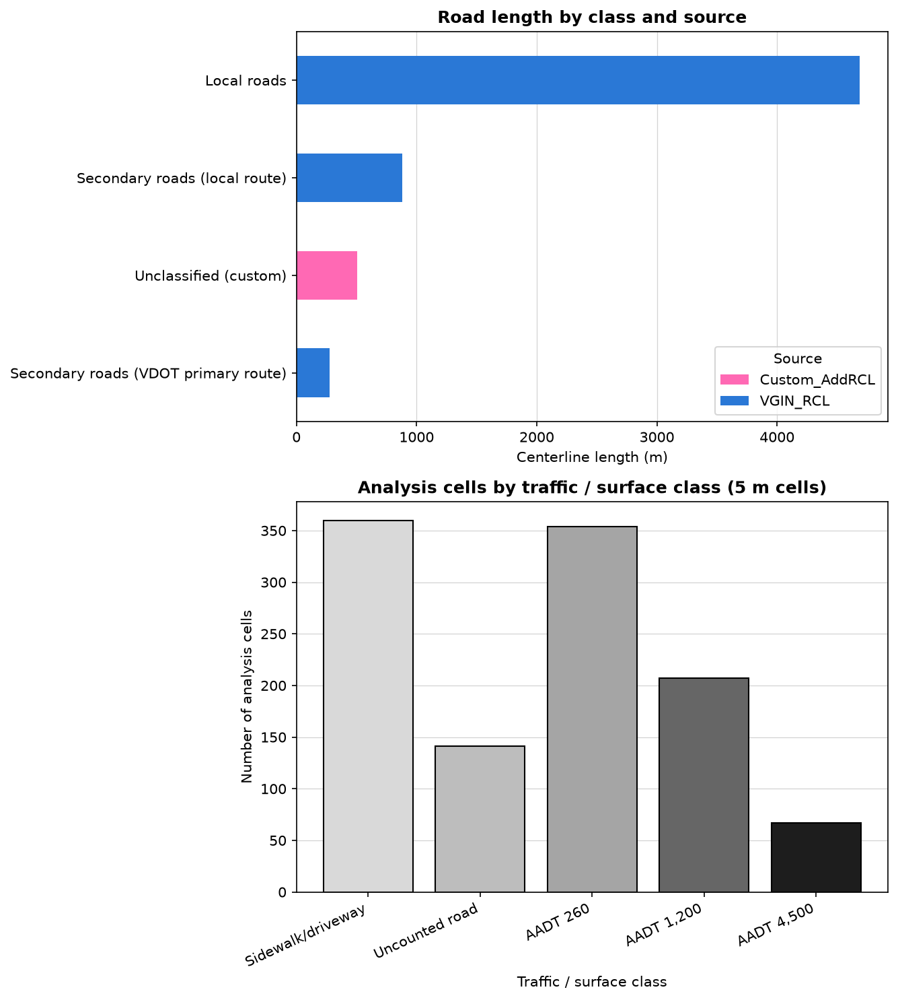

In [76]:
# ---------------------------------------------------------------------
# 05.4 (Step B) — Road attributes: bar charts (road length by class; cells by traffic / surface class)
# ---------------------------------------------------------------------
print("Bar charts: road length by class, and analysis cells by traffic / surface class")
TRAFFIC_COLORS = ["#d9d9d9", "#bdbdbd"] + list(plt.cm.Greys(np.linspace(0.45, 0.9, max(1, len(TRAFFIC_ORDER) - 2))))
fig, axes = plt.subplots(2, 1, figsize=(9, 10), dpi=FIG_DPI)
ax = axes[0]
len_by_class.drop(columns="Total").plot.barh(stacked=True, ax=ax, color=[COLOR_ADDRCL, COLOR_ROAD][:len_by_class.shape[1] - 1])
ax.set_xlabel("Centerline length (m)"); ax.set_ylabel("")
ax.set_title("Road length by class and source", fontweight="bold"); style_ax(ax, "x")
ax = axes[1]
ax.bar(range(len(traffic_tbl)), traffic_tbl["Cells"], color=TRAFFIC_COLORS[:len(traffic_tbl)], edgecolor="black")
ax.set_xticks(range(len(traffic_tbl))); ax.set_xticklabels(traffic_tbl.index, rotation=25, ha="right")
ax.set_xlabel("Traffic / surface class"); ax.set_ylabel("Number of analysis cells")
ax.set_title(f"Analysis cells by traffic / surface class ({FISHNET_CELL_M} m cells)", fontweight="bold"); style_ax(ax, "y")
plt.tight_layout()
save_fig(fig, 26, "RoadAttributes_Distribution", 5)
plt.show()

**What the table and charts show.**

- **Road length.** Of the 6,352 m of centerline in the study area, 4,688 m are VGIN local roads, 1,157 m VGIN
  secondary roads and 507 m custom lines.
- **Counts.** 92 % of the length carries a VDOT count. The counts are right-skewed: median 1,200, mean 2,039, maximum
  9,500 vehicles/day. The busiest segments are W Olney Rd and Colonial Ave, outside the imaged pavement.
- **Cells.** Sidewalk/driveway cells are 31.9 % of the cells but only 13.5 % of the pavement area (1,659 of
  12,293 m²), because many are narrow slivers. Mowbray Arch (AADT 260) supplies the largest share of road pavement
  (4,660 m²).

Map: analysis cells by traffic / surface class, with the traffic polygon outline


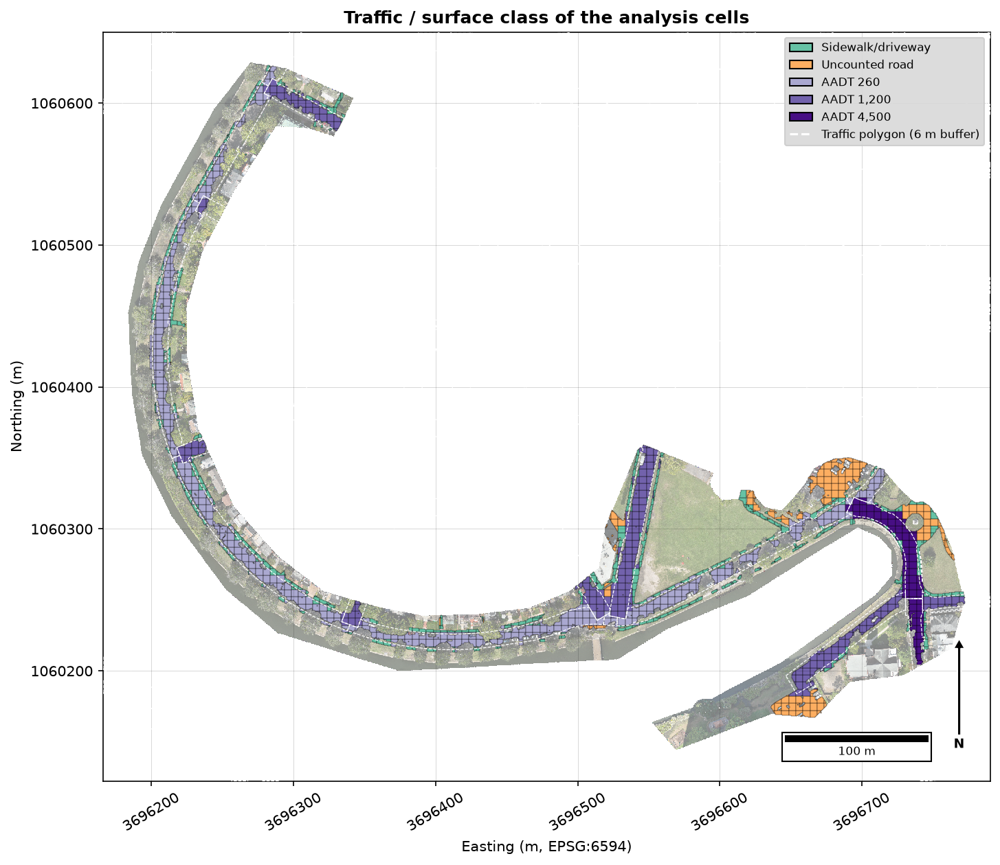

In [77]:
# ---------------------------------------------------------------------
# 05.4 (Step C) — Road attributes: map of the analysis cells by traffic / surface class
# ---------------------------------------------------------------------
print("Map: analysis cells by traffic / surface class, with the traffic polygon outline")
fig, ax = plt.subplots(figsize=(10, 8.5), dpi=FIG_DPI)
draw_imagery(ax, alpha=0.5)
_tc = dict(zip(TRAFFIC_ORDER, ["#66c2a5", "#fdae61"] + list(plt.cm.Purples(np.linspace(0.45, 0.95, max(1, len(TRAFFIC_ORDER) - 2))))))
for k, colr in _tc.items():
    _g = cells_gdf[cells_gdf["TrafficClass"] == k]
    if len(_g):
        _g.plot(ax=ax, facecolor=colr, edgecolor="black", linewidth=0.2, zorder=2)
if len(aadt_poly):
    aadt_poly.boundary.plot(ax=ax, color="white", linewidth=0.6, linestyle="--", zorder=3)
ax.legend(handles=[mpatches.Patch(facecolor=c, edgecolor="black", label=k) for k, c in _tc.items()]
          + [mlines.Line2D([], [], color="white", linestyle="--", label=f"Traffic polygon ({AADT_BUFFER_M} m buffer)")],
          loc="upper right", fontsize=8, framealpha=0.9, facecolor="0.85")
ax.set_xlim(P_EXTENT[0], P_EXTENT[1]); ax.set_ylim(P_EXTENT[2], P_EXTENT[3])
map_axes(ax, "Traffic / surface class of the analysis cells")
plt.tight_layout()
save_fig(fig, 27, "TrafficClass_CellMap", 5, maps=True)
plt.show()

**What the map shows.**

- **AADT 260.** Mowbray Arch (light purple) is the long arc.
- **AADT 1,200.** Botetourt St, Fairfax Ave and the other side streets (medium purple).
- **AADT 4,500.** Memorial Pl and Yarmouth St around the east-end loop (dark purple).
- **Uncounted road.** The orange cells are mostly parking-lot lanes and drives at the east end.
- **Sidewalk/driveway.** These cells (green) form thin strips along both sides of the streets.

The busiest class is concentrated in one small, low-lying area. This is a first sign that traffic and flood exposure
may be confounded.

### 05.5 Road cracks: crack density per analysis cell

In [78]:
# ---------------------------------------------------------------------
# 05.5 (Step A) — Cracks: descriptive statistics
# ---------------------------------------------------------------------
cd = cells_land["CrackDens"]
print(f"Descriptive statistics of crack density ({CRACK_UNITS.replace(chr(10), ' ')}):")
display(pd.DataFrame([nice_stats(cd, "Crack density, all analysis cells", "fraction"),
                      nice_stats(cd[cd > 0], "Crack density, cells with cracks", "fraction")]).round(4))
print(f"Cells with no crack pixels: {(cd == 0).mean() * 100:.1f} %   |   maximum crack density: {CRACK_MAX:.3f}   |   "
      f"small edge cells (AreaFrac < 0.1): {(cells_land['AreaFrac'] < 0.1).mean() * 100:.1f} %")

Descriptive statistics of crack density (fraction of pavement pixels in cell (0 to max ~0.61)):


,count,mean,std,min,25%,50% (median),75%,max,IQR,skewness
"Crack density, all analysis cells (fraction)",1129.0,0.0841,0.1257,0.0000,0.0015,0.0261,0.1122,0.6123,0.1107,1.9177
"Crack density, cells with cracks (fraction)",918.0,0.1034,0.1321,0.0001,0.0104,0.0445,0.1406,0.6123,0.1302,1.6522


Cells with no crack pixels: 18.7 %   |   maximum crack density: 0.612   |   small edge cells (AreaFrac < 0.1): 21.0 %


**What the table shows.**

- **All cells.** Crack density is low for most cells: median 0.026, mean 0.084, IQR 0.0015–0.112, maximum 0.612.
- **Zeros.** 18.7 % of the cells have no crack pixel at all.
- **Cracked cells.** Among the 918 cells with cracks, the median is 0.045.
- **Edge cells.** 21 % of the cells are small edge slivers (AreaFrac < 0.1), whose density rests on very little
  pavement.

Histogram + box plot: crack density per analysis cell


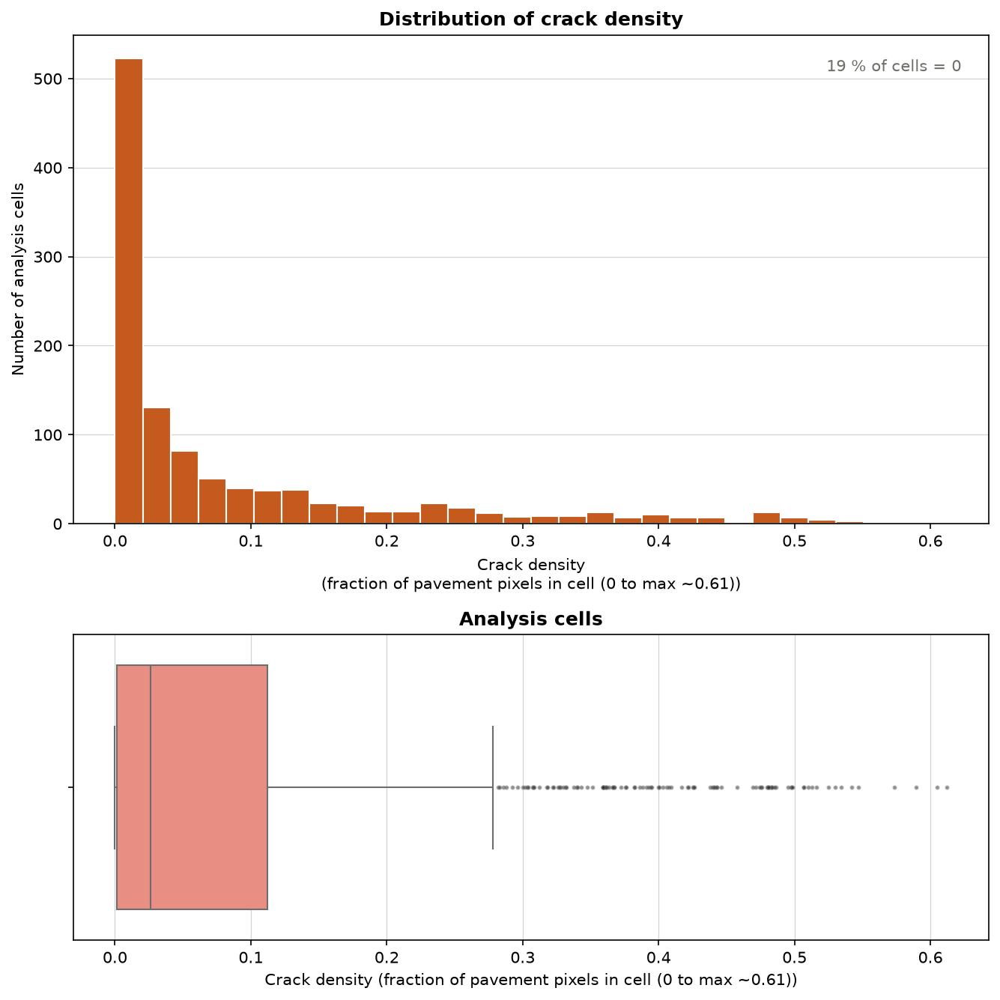

In [79]:
# ---------------------------------------------------------------------
# 05.5 (Step B) — Cracks: histogram and box plot of crack density
# ---------------------------------------------------------------------
print("Histogram + box plot: crack density per analysis cell")
fig, axes = plt.subplots(2, 1, figsize=(9, 9), dpi=FIG_DPI, gridspec_kw=dict(height_ratios=[1.6, 1]))
ax = axes[0]
ax.hist(cd, bins=30, color="#c55a1e", edgecolor="white")
ax.text(0.97, 0.95, f"{(cd == 0).mean() * 100:.0f} % of cells = 0", transform=ax.transAxes, ha="right", va="top",
        fontsize=10, color=COLOR_GREY)
ax.set_xlabel(f"Crack density\n({CRACK_UNITS.replace(chr(10), ' ')})"); ax.set_ylabel("Number of analysis cells")
ax.set_title("Distribution of crack density", fontweight="bold"); style_ax(ax, "y")
ax = axes[1]
sns.boxplot(x=cd, ax=ax, color="salmon", flierprops=dict(marker="o", markerfacecolor="black", markersize=2, alpha=0.4))
ax.set_xlabel(f"Crack density ({CRACK_UNITS.replace(chr(10), ' ')})"); ax.set_title("Analysis cells", fontweight="bold")
style_ax(ax, "x")
plt.tight_layout()
save_fig(fig, 28, "CrackDensity_Distribution", 5)
plt.show()

**What the plots show.** The histogram is L-shaped: a tall bar of zero or near-zero cells, then a long right tail
out to 0.61 (skewness 1.9). The box plot puts everything above ≈ 0.28 beyond the upper whisker. Crack density is
therefore a bounded, zero-inflated, right-skewed fraction.

Map: crack density per analysis cell


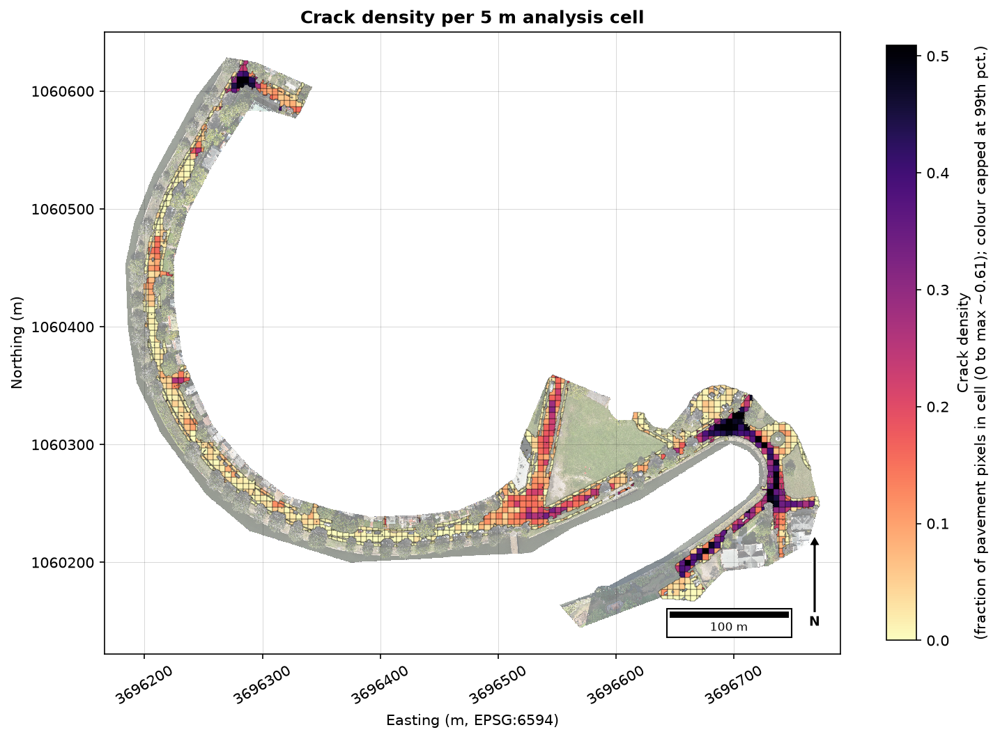

In [80]:
# ---------------------------------------------------------------------
# 05.5 (Step C) — Cracks: map of crack density per analysis cell
# ---------------------------------------------------------------------
print("Map: crack density per analysis cell")
fig, ax = plt.subplots(figsize=(10, 8.5), dpi=FIG_DPI)
draw_imagery(ax, alpha=0.5)
_vmax = max(np.nanpercentile(cells_land["CrackDens"], 99), 1e-3)
cells_gdf.plot(ax=ax, column="CrackDens", cmap=CMAP_CRACK, vmin=0, vmax=_vmax, edgecolor="black", linewidth=0.2, zorder=2)
fig.colorbar(plt.cm.ScalarMappable(norm=mcolors.Normalize(0, _vmax), cmap=CMAP_CRACK), ax=ax, shrink=0.7,
             label=f"Crack density\n({CRACK_UNITS.replace(chr(10), ' ')}; colour capped at 99th pct.)")
ax.set_xlim(P_EXTENT[0], P_EXTENT[1]); ax.set_ylim(P_EXTENT[2], P_EXTENT[3])
map_axes(ax, f"Crack density per {FISHNET_CELL_M} m analysis cell")
plt.tight_layout()
save_fig(fig, 29, "CrackDensity_CellMap", 5, maps=True)
plt.show()

**What the map shows.**

- **Most cracked.** The most cracked cells (purple to black, > 0.3) cluster along Memorial Pl and Yarmouth St around
  the east-end loop and at the Mowbray Arch / Fairfax Ave corner in the northwest. Botetourt St also has many
  moderately cracked cells.
- **Least cracked.** The long arc of Mowbray Arch and the sidewalk strips are mostly pale (< 0.05).

The pattern follows the busier streets as much as the low ones; Section 07 explores this.

### 05.6 Accuracy assessment points

The points were drawn with an *equalized* stratified design, with about the same number on each class. The overall
accuracy below is therefore **not** area-weighted, and the per-class precision and recall are the informative numbers.
Cohen's (1960) κ is the agreement beyond chance.

In [81]:
# ---------------------------------------------------------------------
# 05.6 (Step A) — Accuracy points: accuracy metrics table
# ---------------------------------------------------------------------
if CLASSIFIED_FIELD in acc.columns:
    _agree = (pd.to_numeric(acc[CLASSIFIED_FIELD], errors="coerce") == acc["Pred"]).mean() * 100
    print(f"Check: the crack raster value at each point equals the stored '{CLASSIFIED_FIELD}' field for {_agree:.1f} % of points")
acc_metrics = None
if "Outcome" in acc.columns:
    tp, tn, fn, fp = (int((acc["Outcome"] == k).sum()) for k in ("TP", "TN", "FN", "FP"))
    n = tp + fp + fn + tn
    po = (tp + tn) / n
    p_e = ((tp + fp) * (tp + fn) + (fn + tn) * (fp + tn)) / n ** 2
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    acc_metrics = pd.Series({"Labeled points": n, "Overall accuracy": po, "Crack precision (user's)": prec,
                             "Crack recall (producer's)": rec, "Crack F1": 2 * prec * rec / max(prec + rec, 1e-12),
                             "No-crack precision": tn / max(tn + fn, 1), "No-crack recall": tn / max(tn + fp, 1),
                             "Cohen's kappa": (po - p_e) / (1 - p_e) if p_e < 1 else np.nan}, name="value")
    display(acc_metrics.round(3).to_frame())

Check: the crack raster value at each point equals the stored 'Classified' field for 100.0 % of points


,value
Labeled points,150.000
Overall accuracy,0.920
Crack precision (user's),0.933
Crack recall (producer's),0.909
Crack F1,0.921
No-crack precision,0.907
No-crack recall,0.932
Cohen's kappa,0.840


Bar chart: accuracy-point outcomes


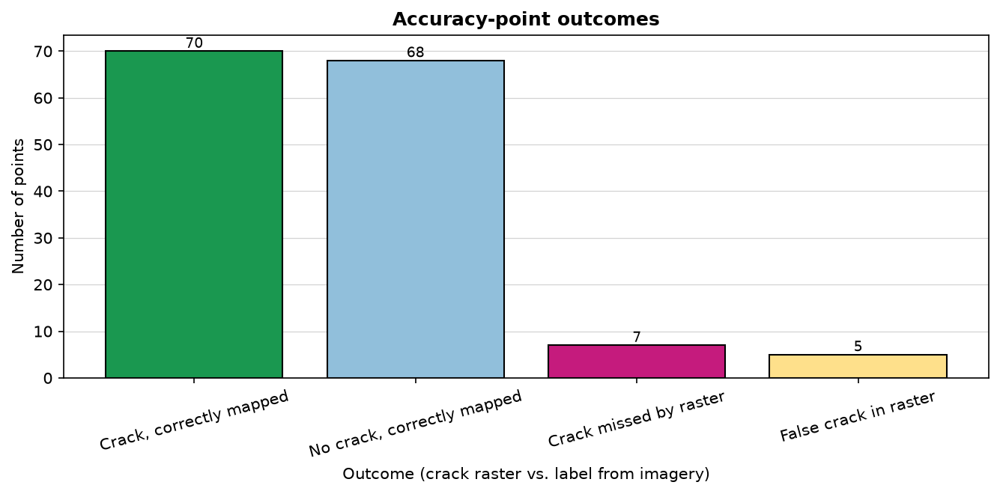

In [82]:
# ---------------------------------------------------------------------
# 05.6 (Step B) — Accuracy points: bar chart of the four outcomes
# ---------------------------------------------------------------------
if "Outcome" in acc.columns:
    print("Bar chart: accuracy-point outcomes")
    _oc = acc["Outcome"].value_counts().reindex(list(ACC_STYLE)).fillna(0)
    fig, ax = plt.subplots(figsize=(9, 4.5), dpi=FIG_DPI)
    ax.bar([ACC_STYLE[k][1] for k in _oc.index], _oc.values, color=[ACC_STYLE[k][0] for k in _oc.index], edgecolor="black")
    for i, v in enumerate(_oc.values):
        ax.text(i, v, f"{int(v)}", ha="center", va="bottom", fontsize=9)
    ax.set_ylabel("Number of points"); ax.set_xlabel("Outcome (crack raster vs. label from imagery)")
    ax.set_title("Accuracy-point outcomes", fontweight="bold"); style_ax(ax, "y")
    plt.xticks(rotation=15)
    plt.tight_layout()
    save_fig(fig, 30, "AccuracyOutcomes", 5)
    plt.show()

Heatmap: confusion matrix of the crack raster vs. the labeled points


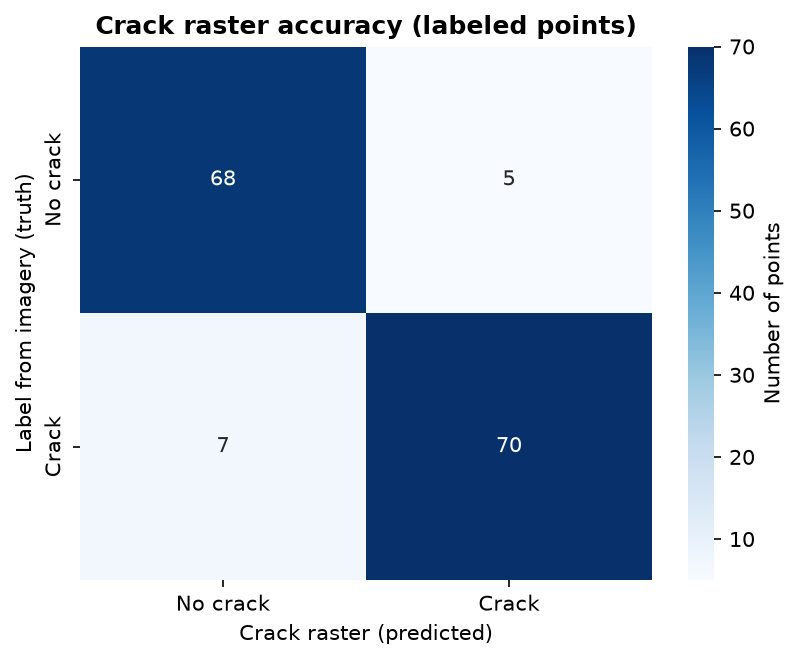

In [83]:
# ---------------------------------------------------------------------
# 05.6 (Step C) — Accuracy points: confusion matrix heatmap
# ---------------------------------------------------------------------
if acc_metrics is not None:
    print("Heatmap: confusion matrix of the crack raster vs. the labeled points")
    fig, ax = plt.subplots(figsize=(5.5, 4.5), dpi=FIG_DPI)
    sns.heatmap(np.array([[tn, fp], [fn, tp]]), annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "Number of points"},
                xticklabels=["No crack", "Crack"], yticklabels=["No crack", "Crack"], ax=ax)
    ax.set_xlabel("Crack raster (predicted)"); ax.set_ylabel("Label from imagery (truth)")
    ax.set_title("Crack raster accuracy (labeled points)", fontweight="bold")
    plt.tight_layout()
    save_fig(fig, 31, "ConfusionMatrix", 5)
    plt.show()

**What the table and figures show.**

- **Overall.** The crack raster agrees with the labels at 92.0 % of the 150 points. Cohen's κ = 0.84, which is
  "almost perfect" agreement beyond chance.
- **Crack class.** Precision (user's accuracy) is 0.933: 93 % of mapped cracks are real. Recall (producer's
  accuracy) is 0.909: 91 % of real cracks are mapped. The F1 score is 0.921.
- **No-crack class.** Precision 0.907, recall 0.932.
- **Balance.** The 7 misses and 5 false cracks are close, so the raster slightly under-maps cracks rather than
  inventing them.
- **Data check.** The raster value at every point matched the stored `Classified` field (100 %).

### 05.7 Relative sea level (RSLR): observed trend and projection

The observed record is re-expressed relative to the **year-2000 level of NOAA's linear trend**, so it shares the
projection's reference (relative sea-level rise since 2000).

In [84]:
# ---------------------------------------------------------------------
# 05.7 (Step A) — RSLR: descriptive statistics (observed record and projection)
# ---------------------------------------------------------------------
_t2000 = slt.loc[slt["Year"] == 2000, "Trend_m"].mean()
if not np.isfinite(_t2000):                                           # no trend value in 2000: fit one
    _ok = slt["MSL_m"].notna()
    _b, _a = np.polyfit(slt.loc[_ok, "DecYear"], slt.loc[_ok, "MSL_m"], 1)
    _t2000 = _a + _b * 2000.5
slt["MSL_rel2000_m"] = slt["MSL_m"] - _t2000
slt["Trend_rel2000_m"] = slt["Trend_m"] - _t2000
_ok = slt["MSL_m"].notna()
_slope, _icpt = np.polyfit(slt.loc[_ok, "DecYear"], slt.loc[_ok, "MSL_m"], 1)
slt["Residual_m"] = slt["MSL_m"] - (_icpt + _slope * slt["DecYear"])
slt_annual = slt.groupby("Year").agg(MSL_rel2000_m=("MSL_rel2000_m", "mean"), Months=("MSL_m", "count"))
rslr_stats = pd.DataFrame([nice_stats(slt["MSL_rel2000_m"], "Observed monthly MSL, rel. to 2000 trend level", "m"),
                           nice_stats(slt_annual.loc[slt_annual["Months"] >= 10, "MSL_rel2000_m"],
                                      "Observed annual mean (>= 10 months)", "m"),
                           nice_stats(noaa["RSLR_m"], "Projection 2000-2100 (decadal)", "m")])
display(rslr_stats.round(3))
_obs2025 = slt_annual.loc[2025, "MSL_rel2000_m"] if 2025 in slt_annual.index else np.nan
print(f"Linear trend fitted here: {_slope * 1000:.2f} mm/yr; trend-line rise 2000 -> 2025: {_slope * 25:.3f} m; "
      f"observed 2025 annual mean: {_obs2025:.3f} m; projection for 2025: {RSLR_FLOOD_YEAR:.3f} m (all relative to 2000)")

,count,mean,std,min,25%,50% (median),75%,max,IQR,skewness
"Observed monthly MSL, rel. to 2000 trend level (m)",1187.0,-0.112,0.155,-0.491,-0.232,-0.126,0.005,0.357,0.237,0.251
Observed annual mean (>= 10 months) (m),99.0,-0.111,0.143,-0.383,-0.216,-0.129,0.009,0.189,0.225,0.208
Projection 2000-2100 (decadal) (m),10.0,0.890,0.678,0.000,0.370,0.790,1.350,2.040,0.980,0.353


Linear trend fitted here: 4.83 mm/yr; trend-line rise 2000 -> 2025: 0.121 m; observed 2025 annual mean: 0.118 m; projection for 2025: 0.260 m (all relative to 2000)


**What the table shows.**

- **Observed.** Relative to the 2000 trend level, monthly mean sea level ranges from −0.49 m to
  +0.36 m. The linear trend fitted here, 4.82 mm/yr, reproduces NOAA's 4.83 mm/yr.
- **2025, observed vs. projected.** Along the trend, sea level rose 0.121 m from 2000 to 2025, and the observed 2025
  annual mean is 0.118 m. The projection used for the flood-days model gives **0.260 m** for 2025, about 0.14 m (more
  than double) above what the gauge recorded.

Histograms: observed monthly mean sea level, and its departures from the linear trend


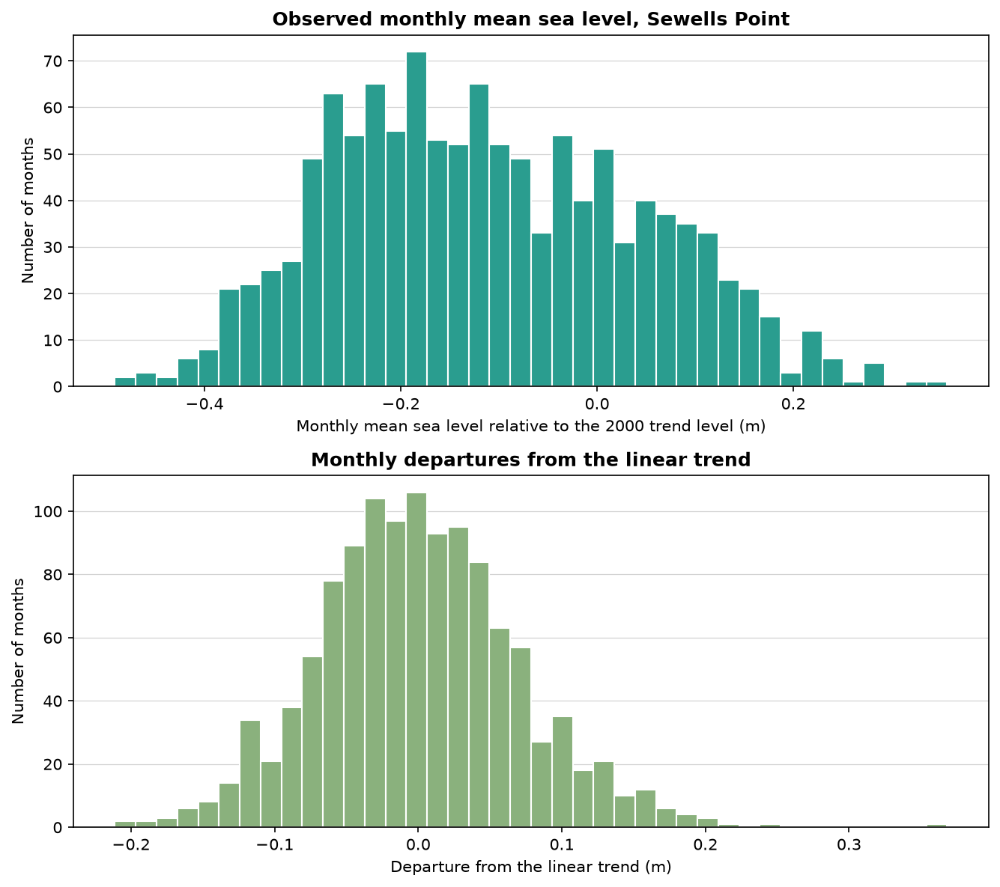

In [85]:
# ---------------------------------------------------------------------
# 05.7 (Step B) — RSLR: distribution of the observed monthly sea level (and residuals from the trend)
# ---------------------------------------------------------------------
print("Histograms: observed monthly mean sea level, and its departures from the linear trend")
fig, axes = plt.subplots(2, 1, figsize=(9, 8), dpi=FIG_DPI)
ax = axes[0]
ax.hist(slt["MSL_rel2000_m"].dropna(), bins=40, color="#2a9d8f", edgecolor="white")
ax.set_xlabel("Monthly mean sea level relative to the 2000 trend level (m)"); ax.set_ylabel("Number of months")
ax.set_title("Observed monthly mean sea level, Sewells Point", fontweight="bold"); style_ax(ax, "y")
ax = axes[1]
ax.hist(slt["Residual_m"].dropna(), bins=40, color="#8ab17d", edgecolor="white")
ax.set_xlabel("Departure from the linear trend (m)"); ax.set_ylabel("Number of months")
ax.set_title("Monthly departures from the linear trend", fontweight="bold"); style_ax(ax, "y")
plt.tight_layout()
save_fig(fig, 32, "SeaLevel_Distribution", 5)
plt.show()

**What the histograms show.**

- **Monthly levels (top).** The distribution is broad and flat-topped: it mixes the 98-year rise with the
  month-to-month variability.
- **Departures from the trend (bottom).** Once the trend is removed, the departures form a narrow, nearly symmetric
  distribution centred on zero. The IQR is −0.046 to +0.042 m, with a longer high tail: a few months were 0.2–0.37 m
  above the trend. Single months can thus depart from the long-term level by more than the whole 2000–2025 rise.

Line plot: relative sea-level-rise projection (USACE / NOAA 2017 Intermediate-High)


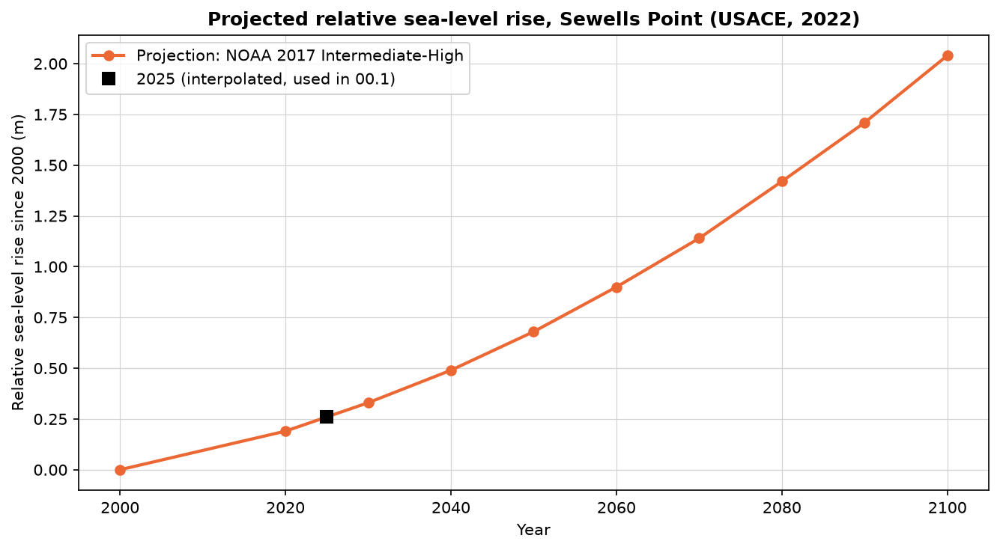

In [86]:
# ---------------------------------------------------------------------
# 05.7 (Step C.1) — RSLR: the projection on its own
# ---------------------------------------------------------------------
print("Line plot: relative sea-level-rise projection (USACE / NOAA 2017 Intermediate-High)")
fig, ax = plt.subplots(figsize=(9, 5), dpi=FIG_DPI)
ax.plot(noaa["Year"], noaa["RSLR_m"], "o-", color=COLOR_ACCENT, linewidth=2, label="Projection: NOAA 2017 Intermediate-High")
ax.plot([FLOOD_YEAR], [RSLR_FLOOD_YEAR], "s", color="black", markersize=8, label=f"{FLOOD_YEAR} (interpolated, used in 00.1)")
ax.set_xlabel("Year"); ax.set_ylabel("Relative sea-level rise since 2000 (m)")
ax.set_title("Projected relative sea-level rise, Sewells Point (USACE, 2022)", fontweight="bold")
ax.legend(loc="upper left"); style_ax(ax)
plt.tight_layout()
save_fig(fig, 33, "SLR_Projection", 5)
plt.show()

**What the plot shows.** The NOAA 2017 Intermediate-High projection accelerates through the century: 0.19 m by 2020,
0.68 m by 2050 and 2.04 m by 2100, relative to 2000. The 2025 value used in 00.1 (black square, 0.26 m) is
interpolated between 2020 and 2030.

Line plot: observed relative sea level (NOAA) and the projection


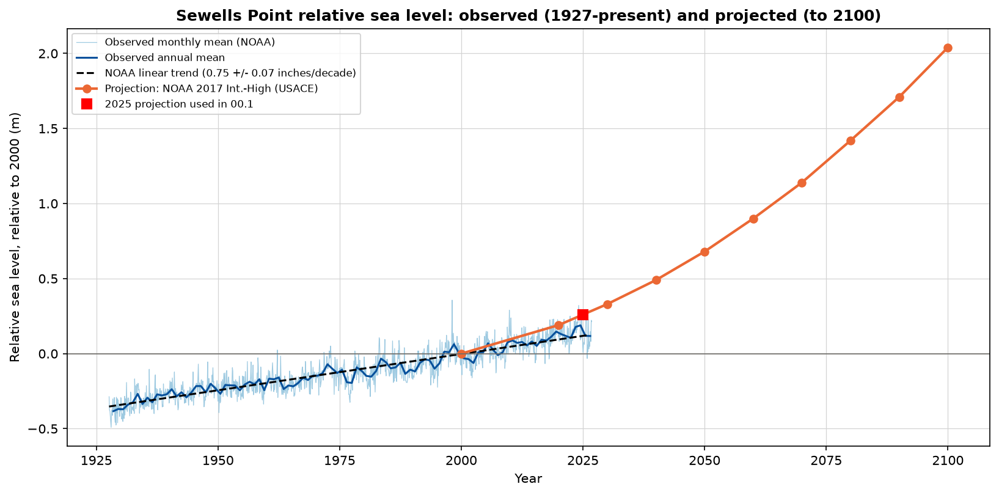

In [87]:
# ---------------------------------------------------------------------
# 05.7 (Step C.2) — RSLR: observed record + NOAA linear trend, followed by the projection
# ---------------------------------------------------------------------
print("Line plot: observed relative sea level (NOAA) and the projection")
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=FIG_DPI)
ax.plot(slt["DecYear"], slt["MSL_rel2000_m"], color="#9ecae1", linewidth=0.6, label="Observed monthly mean (NOAA)")
_ann = slt_annual[slt_annual["Months"] >= 10]
ax.plot(_ann.index + 0.5, _ann["MSL_rel2000_m"], color="#08519c", linewidth=1.5, label="Observed annual mean")
if slt["Trend_rel2000_m"].notna().any():
    ax.plot(slt["DecYear"], slt["Trend_rel2000_m"], color="black", linewidth=1.5, linestyle="--",
            label="NOAA linear trend (" + (f"{slt_info['trend']} +/- {slt_info.get('trendError')} {slt_info['trendUnits']}"
                                             if slt_info.get("trend") is not None else f"{_slope * 1000:.2f} mm/yr") + ")")
ax.plot(noaa["Year"], noaa["RSLR_m"], "o-", color=COLOR_ACCENT, linewidth=2, label="Projection: NOAA 2017 Int.-High (USACE)")
ax.plot([FLOOD_YEAR], [RSLR_FLOOD_YEAR], "s", color="red", markersize=8, label=f"{FLOOD_YEAR} projection used in 00.1")
ax.axhline(0, color=COLOR_GREY, linewidth=0.8)
ax.set_xlabel("Year"); ax.set_ylabel("Relative sea level, relative to 2000 (m)")
ax.set_title("Sewells Point relative sea level: observed (1927-present) and projected (to 2100)", fontweight="bold")
ax.legend(loc="upper left", fontsize=8); style_ax(ax)
plt.tight_layout()
save_fig(fig, 34, "SLR_Observed_and_Projection", 5)
plt.show()

**What the plot shows.**

- **Observed record.** The gauge (blue) follows NOAA's linear trend (dashed) closely from 1927 to the present, with
  no obvious acceleration over the record.
- **Projection.** It (orange) leaves the observed trend right after 2000. By 2025 it sits well above both the trend
  line and the observed annual means.
- **Effect on flood days.** In Ezer's (2022) equation every 0.1 m of RSLR multiplies flood days by 10^0.24 ≈ 1.7.
  Using the projected 0.26 m instead of the observed ≈ 0.12 m therefore raises the modeled 2025 flood days by a
  factor of about 2.2 everywhere.
- **What stays the same.** The ranking of cells, which drives the crack analysis, is unchanged. Absolute flood-day
  numbers in this notebook should be read as an upper-end estimate.

### 05.8 Derived flood days per year (2025)

Per analysis cell, `FloodDaysGeo` is the **geometric-mean** flood days (10^`LogFloodDays`), the exposure used in the
analysis. `FloodDays` (the arithmetic mean) is kept for reference; it is pulled up by a cell's lowest pixels.

In [88]:
# ---------------------------------------------------------------------
# 05.8 (Step A) — Flood days: descriptive statistics, threshold and class shares
# ---------------------------------------------------------------------
display(pd.DataFrame([nice_stats(flood_g, "Flood days, all land (0.5 m raster)", "days/yr"),
                      nice_stats(cells_land["FloodDays"], "Cell arithmetic mean", "days/yr"),
                      nice_stats(cells_land["FloodDaysGeo"], "Cell geometric mean", "days/yr"),
                      nice_stats(cells_land["LogFloodDays"], "Cell mean log10 flood days", "log10 days/yr")]).round(3))
for thr in (1, 3, 30, 182.5):
    print(f"Analysis cells with a geometric-mean flood days >= {thr:g} days/yr: "
          f"{(cells_land['FloodDaysGeo'] >= thr).mean() * 100:.1f} %")
flood_class_share = (pd.cut(cells_land["FloodDaysGeo"], FLOOD_BOUNDS, include_lowest=True).value_counts(normalize=True)
                     .sort_index() * 100)
print("Share of analysis cells in each flood-day class (geometric mean, %):")
display(flood_class_share.round(2).to_frame("% of cells").T)

,count,mean,std,min,25%,50% (median),75%,max,IQR,skewness
"Flood days, all land (0.5 m raster) (days/yr)",260510.0,5.716,19.387,0.000,0.073,0.580,4.150,365.000,4.078,11.009
Cell arithmetic mean (days/yr),1129.0,7.923,14.487,0.001,0.468,2.488,8.795,152.938,8.328,3.952
Cell geometric mean (days/yr),1129.0,7.703,14.155,0.001,0.456,2.440,8.455,152.413,7.999,4.018
Cell mean log10 flood days (log10 days/yr),1129.0,0.281,0.861,-3.221,-0.341,0.387,0.927,2.183,1.268,-0.560


Analysis cells with a geometric-mean flood days >= 1 days/yr: 65.7 %
Analysis cells with a geometric-mean flood days >= 3 days/yr: 45.4 %
Analysis cells with a geometric-mean flood days >= 30 days/yr: 6.1 %
Analysis cells with a geometric-mean flood days >= 182.5 days/yr: 0.0 %
Share of analysis cells in each flood-day class (geometric mean, %):


FloodDaysGeo,"(-0.001, 0.5]","(0.5, 1.5]","(1.5, 3.0]","(3.0, 7.0]","(7.0, 14.0]","(14.0, 30.0]","(30.0, 60.0]","(60.0, 90.0]","(90.0, 300.0]","(300.0, 365.0]"
% of cells,26.04,14.26,14.26,17.09,13.55,8.68,4.43,1.33,0.35,0.0


**What the table shows.**

- **Typical cell.** The geometric mean per cell has a median of 2.4 flood days/yr, a mean of 7.7 and a maximum of
  152. The arithmetic means are only slightly higher, because each 5 m cell spans a small elevation range.
- **Thresholds.** 65.7 % of the cells flood at least once a year, 45.4 % at least 3 days/yr and 6.1 % at least
  30 days/yr. No cell floods on half the days of the year.
- **Classes.** About a quarter of the cells (26 %) fall in the lowest class (≤ 0.5 days/yr). The 30–300 days/yr
  classes hold 69 cells (6.1 %).

Histogram + box plot: geometric-mean flood days per analysis cell


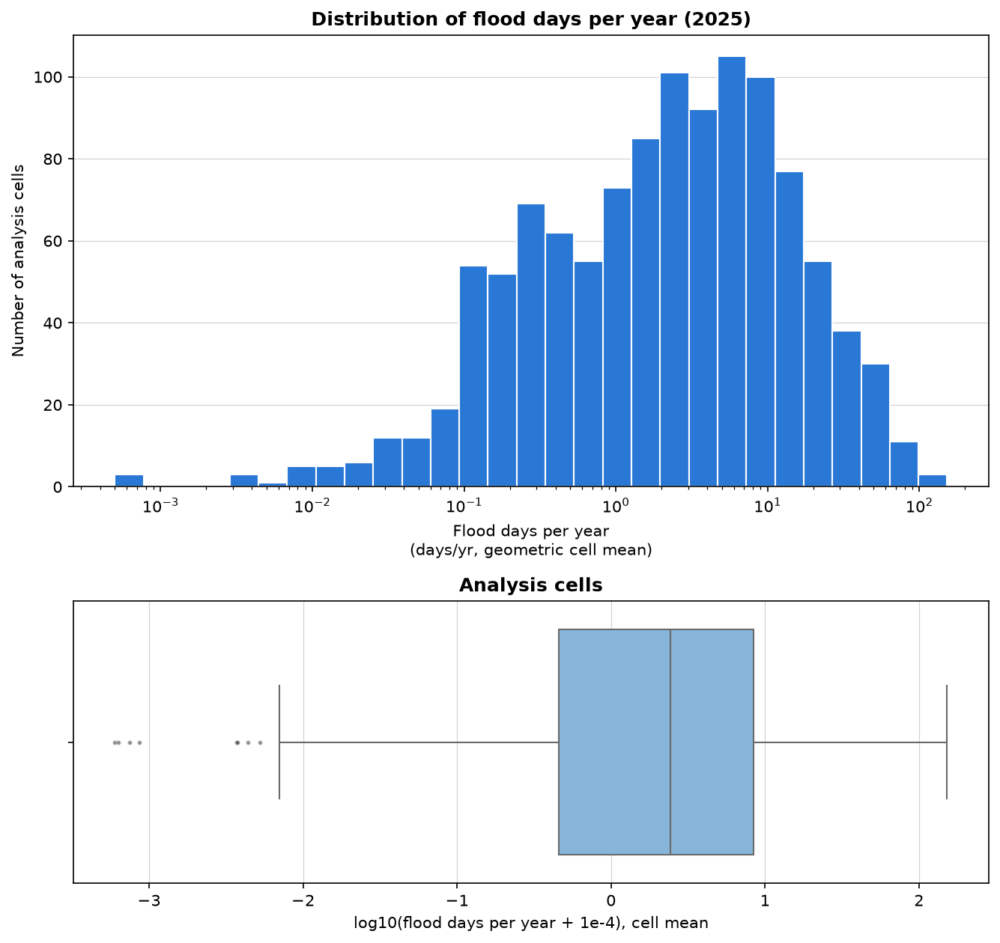

In [89]:
# ---------------------------------------------------------------------
# 05.8 (Step B) — Flood days: histogram (log scale) and box plot of the cell geometric mean
# ---------------------------------------------------------------------
print("Histogram + box plot: geometric-mean flood days per analysis cell")
_fdg = cells_land["FloodDaysGeo"].clip(lower=1e-4)
fig, axes = plt.subplots(2, 1, figsize=(9, 8.5), dpi=FIG_DPI, gridspec_kw=dict(height_ratios=[1.6, 1]))
ax = axes[0]
ax.hist(_fdg, bins=np.logspace(np.log10(_fdg.min()), np.log10(max(_fdg.max(), 1)), 30), color=COLOR_ROAD, edgecolor="white")
ax.set_xscale("log")
ax.set_xlabel("Flood days per year\n(days/yr, geometric cell mean)"); ax.set_ylabel("Number of analysis cells")
ax.set_title(f"Distribution of flood days per year ({FLOOD_YEAR})", fontweight="bold"); style_ax(ax, "y")
ax = axes[1]
sns.boxplot(x=cells_land["LogFloodDays"], ax=ax, color="#7ab8e8",
            flierprops=dict(marker="o", markerfacecolor="black", markersize=2, alpha=0.4))
ax.set_xlabel("log10(flood days per year + 1e-4), cell mean"); ax.set_title("Analysis cells", fontweight="bold")
style_ax(ax, "x")
plt.tight_layout()
save_fig(fig, 35, "FloodDays_Distribution", 5)
plt.show()

**What the plots show.** On a log axis the cell flood days form a single, roughly symmetric hump centred near
3 days/yr, spanning more than five orders of magnitude (10⁻³ to 10² days/yr). This is the expected shape for a
quantity exponential in elevation. It is why `log10` flood days and the geometric mean are used as the exposure
variable, not raw days.

Map: analysis cells by geometric-mean flood days per year


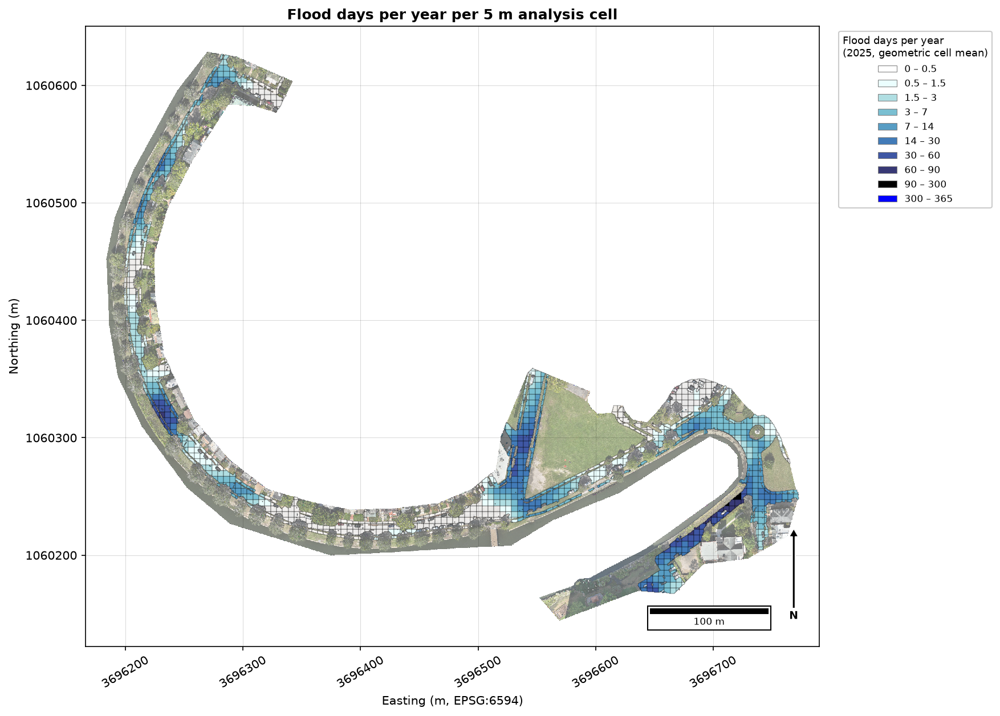

In [90]:
# ---------------------------------------------------------------------
# 05.8 (Step C) — Flood days: map of the analysis cells by flood-day class (01.8 classes)
# ---------------------------------------------------------------------
print("Map: analysis cells by geometric-mean flood days per year")
fig, ax = plt.subplots(figsize=(11, 8.5), dpi=FIG_DPI)
draw_imagery(ax, alpha=0.6)
_fc = FLOOD_CMAP(FLOOD_NORM(cells_gdf["FloodDaysGeo"].fillna(-1).clip(lower=0).values))
_fc[cells_gdf["FloodDaysGeo"].isna().values] = (0.8, 0.8, 0.8, 1)
cells_gdf.plot(ax=ax, color=_fc, edgecolor="black", linewidth=0.2, zorder=2)
ax.legend(handles=FLOOD_HANDLES, title=f"Flood days per year\n({FLOOD_YEAR}, geometric cell mean)", loc="upper left",
          bbox_to_anchor=(1.02, 1), fontsize=8, title_fontsize=8.5, framealpha=1)
ax.set_xlim(P_EXTENT[0], P_EXTENT[1]); ax.set_ylim(P_EXTENT[2], P_EXTENT[3])
map_axes(ax, f"Flood days per year per {FISHNET_CELL_M} m analysis cell")
plt.tight_layout()
save_fig(fig, 36, "FloodDays_CellMap", 5, maps=True)
plt.show()

**What the map shows.** The most frequently flooded cells (30–152 days/yr, dark blue) are on Botetourt St, along
the southeastern street and around the east-end loop, and at the low spot on the western arc. The southern arc and
the northern ends are rarely flooded (white, ≤ 0.5 days/yr). This is the inverse of the elevation map in 05.2.

### 05.9 Summary figure: distributions of the study variables

Figure: distributions of the study variables (analysis cells)


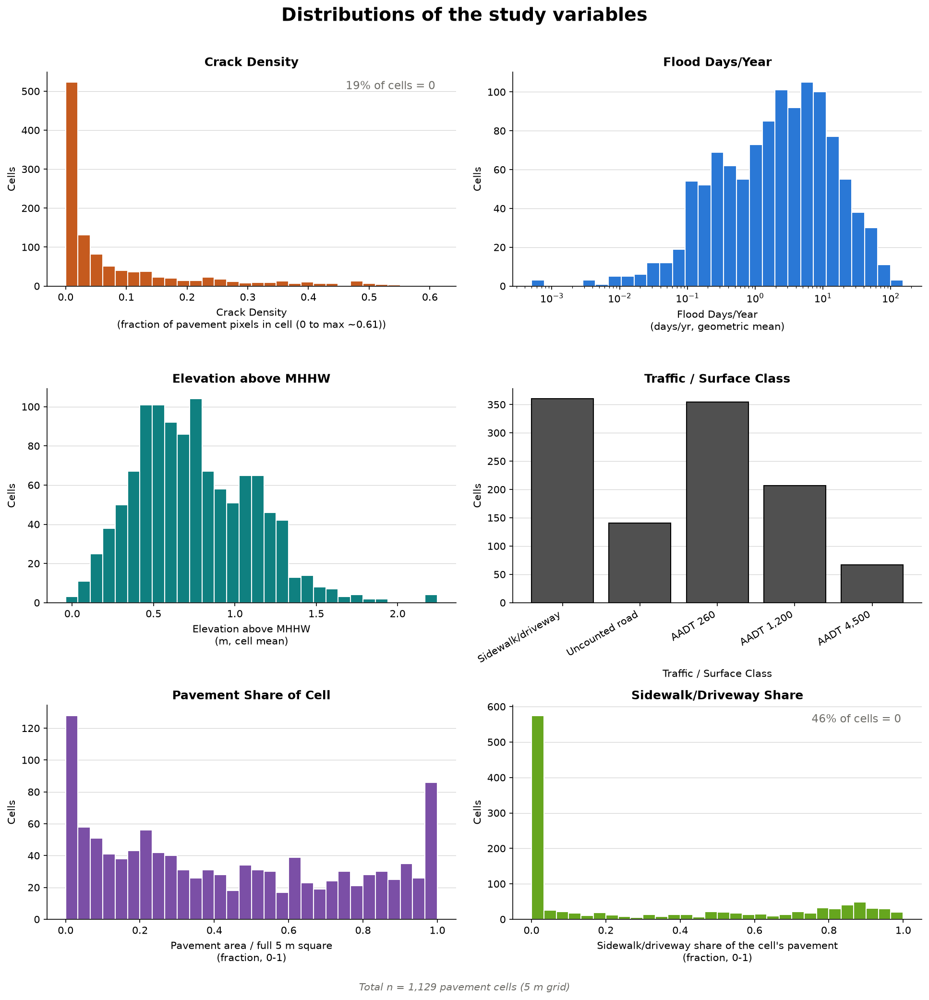

In [91]:
# ---------------------------------------------------------------------
# 05.9 (Step A) — Summary figure: distributions of the per-cell study variables
# ---------------------------------------------------------------------
def _panel(ax, title, xlabel, ylabel="Cells"):
    ax.set_title(title, fontweight="bold"); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="lightgray", linewidth=0.6)
    ax.set_axisbelow(True)


print("Figure: distributions of the study variables (analysis cells)")
fig, axes = plt.subplots(3, 2, figsize=(13, 14), dpi=FIG_DPI)
ax = axes[0, 0]
ax.hist(cells_land["CrackDens"], bins=30, color="#c55a1e", edgecolor="white")
ax.text(0.95, 0.92, f"{(cells_land['CrackDens'] == 0).mean() * 100:.0f}% of cells = 0", transform=ax.transAxes,
        ha="right", color=COLOR_GREY, fontsize=11)
_panel(ax, "Crack Density", f"Crack Density\n({CRACK_UNITS.replace(chr(10), ' ')})")
ax = axes[0, 1]
ax.hist(_fdg, bins=np.logspace(np.log10(_fdg.min()), np.log10(max(_fdg.max(), 1)), 30), color="#2a78d6", edgecolor="white")
ax.set_xscale("log")
_panel(ax, "Flood Days/Year", "Flood Days/Year\n(days/yr, geometric mean)")
ax = axes[1, 0]
ax.hist(cells_land["ElevMHHW"], bins=30, color="#0f8080", edgecolor="white")
_panel(ax, "Elevation above MHHW", "Elevation above MHHW\n(m, cell mean)")
ax = axes[1, 1]
_tc_counts = cells_land["TrafficClass"].value_counts().reindex(TRAFFIC_ORDER).fillna(0)
ax.bar(range(len(_tc_counts)), _tc_counts.values, color="#505050", edgecolor="black")
ax.set_xticks(range(len(_tc_counts))); ax.set_xticklabels(_tc_counts.index, rotation=30, ha="right")
_panel(ax, "Traffic / Surface Class", "Traffic / Surface Class")
ax = axes[2, 0]
ax.hist(cells_land["AreaFrac"], bins=30, color="#7b4fa6", edgecolor="white")
_panel(ax, "Pavement Share of Cell", f"Pavement area / full {FISHNET_CELL_M} m square\n(fraction, 0-1)")
ax = axes[2, 1]
ax.hist(cells_land["SidewalkFrac"], bins=30, color="#66a61e", edgecolor="white")
ax.text(0.95, 0.92, f"{(cells_land['SidewalkFrac'] == 0).mean() * 100:.0f}% of cells = 0", transform=ax.transAxes,
        ha="right", color=COLOR_GREY, fontsize=11)
_panel(ax, "Sidewalk/Driveway Share", "Sidewalk/driveway share of the cell's pavement\n(fraction, 0-1)")
fig.suptitle("Distributions of the study variables", fontweight="bold", fontsize=18)
fig.text(0.5, 0.005, f"Total n = {len(cells_land):,} pavement cells ({FISHNET_CELL_M} m grid)", ha="center",
         style="italic", color=COLOR_GREY)
plt.tight_layout(rect=(0, 0.02, 1, 0.97))
save_fig(fig, 37, "StudyVariable_Distributions", 5)
plt.show()

**What the figure shows** (all 1,129 analysis cells):

- **Crack density.** L-shaped and zero-inflated (19 % of cells = 0).
- **Flood days.** Roughly log-normal, centred near 3 days/yr.
- **Elevation above MHHW.** Bimodal, with low and high groups of streets.
- **Traffic / surface class.** Dominated by sidewalk/driveway and AADT 260 cells; the 4,500 class is small (67 cells).
- **Pavement share.** U-shaped: many edge slivers and many full squares.
- **Sidewalk/driveway share.** Mostly 0 (46 %), with a second mode near 0.8–1 (sidewalk cells).

These shapes set the modelling choices: a fractional or two-part model for the response, log10 flood days as the
exposure, traffic as a categorical control, and cell area as a weight or filter.

--------------------------------------------------------------------------------------

**Section 05 summary: descriptive statistics & distributions,** dataset by dataset:

1. **Imagery.** Pavement is much brighter and more uniform than its surroundings in all three bands (mean R/G/B
   167/158/146 vs. 92/97/70). That contrast is why a tight pavement mask was needed before running the crack model.
2. **DEM.**
   - The pavement cells sit in a narrow band above MHHW: median 0.71 m, IQR 0.48–1.01 m. A few centimetres
     therefore matter.
   - Only one cell (0.09 %) has a mean at or below MHHW, but 26.7 % are within 0.5 m of it.
3. **VDatum / MHHW.** It is almost constant over the site: 0.3859–0.3870 m NAVD88, a 1.1 mm range. It sets the overall
   *level* of exposure, not its pattern.
4. **Road attributes.**
   - All VGIN segments in the study area carry a VDOT count. Only three count values (260, 1,200 and
     4,500 vehicles/day) reach the analysis cells.
   - 141 road cells are uncounted (mainly the east-end parking lanes), and 360 cells are sidewalk/driveway.
   - With only three levels plus two non-count classes, traffic is best treated as a class, not a continuous variable.
5. **Road cracks.**
   - Crack density is **zero-inflated** (18.7 % of cells without a crack pixel) and right-skewed (median 0.026, mean
     0.084). Its maximum, 0.61, is well below 1, hence the "(0 to max ~0.61)" units.
   - A model for a 0–1 fraction with many zeros (fractional logit or two-part) fits this better than ordinary
     regression.
6. **Accuracy points.** Overall accuracy is 0.92 and κ = 0.84. Crack precision is 0.93 and recall 0.91. The raster
   can be trusted at the cell level and slightly under-maps cracks (7 misses vs. 5 false cracks).
7. **RSLR.**
   - The tide gauge shows a steady, linear rise of 4.8 mm/yr since 1927. Single months depart from it by up to
     0.37 m.
   - The observed 2025 level (0.118 m above the 2000 trend level) is less than half the projected 0.26 m used for the
     flood-days model. Absolute flood days are therefore about 2.2 times higher than an observation-based RSLR would
     give.
8. **Flood days.**
   - The values are spread over five orders of magnitude and roughly log-normal: median 2.4 days/yr, 6.1 % of cells
     ≥ 30 days/yr, maximum 152. This is why the log scale and the geometric mean are used.
   - The most flooded pavement is on Botetourt St, around the east-end loop and at one low spot on the western arc.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 06) Outliers

Outliers are flagged with the IQR rule: values more than 1.5 × IQR beyond the first or third quartile (Tukey, 1977).
The datasets follow the same order as Section 05. Where the rule does not make sense for a dataset, the cell says so
and checks what can go wrong with that dataset instead.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

In [92]:
# ---------------------------------------------------------------------
# 06.0 (Step A) — Shared IQR helpers
# ---------------------------------------------------------------------
def iqr_bounds(v):
    v = np.asarray(v, dtype="float64"); v = v[np.isfinite(v)]
    q1, q3 = np.percentile(v, [25, 75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)


OUTLIER_ROWS, OUTLIER_FLAGS = [], {}


def iqr_report(values, label, units, key=None, index=None):
    """IQR bounds and counts for one variable; stores the flagged index (for the map) under `key`."""
    v = pd.Series(np.asarray(values, dtype="float64"), index=index)
    lo, hi = iqr_bounds(v)
    flag = (v < lo) | (v > hi)
    OUTLIER_ROWS.append({"Variable": label, "Units": units, "Lower bound": lo, "Upper bound": hi,
                         "# low": int((v < lo).sum()), "# high": int((v > hi).sum()), "% outliers": 100 * flag.mean()})
    if key:
        OUTLIER_FLAGS[key] = v.index[flag]
    display(pd.DataFrame([OUTLIER_ROWS[-1]]).set_index("Variable").round(4))
    return lo, hi


def iqr_box(values, xlabel, title, color, fig_num, short):
    """Horizontal box plot with an IQR text box."""
    v = pd.Series(values).dropna()
    fig, ax = plt.subplots(figsize=(9, 3.2), dpi=FIG_DPI)
    sns.boxplot(x=v, ax=ax, color=color, flierprops=dict(marker="o", markerfacecolor="black", markersize=2, alpha=0.4))
    q1, q3 = np.percentile(v, [25, 75])
    ax.text(0.98, 0.9, f"IQR: {q1:.3g} - {q3:.3g}", transform=ax.transAxes, ha="right", va="top", fontsize=8,
            bbox=dict(facecolor="white", edgecolor="black", linewidth=0.7))
    ax.set_xlabel(xlabel); ax.set_title(title, fontweight="bold"); style_ax(ax, "x")
    plt.tight_layout()
    save_fig(fig, fig_num, short, 6)
    plt.show()

### 06.1 Imagery

The IQR rule is applied to the brightness (mean of R, G, B) of the pavement pixels in the 0.32 m-pixel preview.
Dark outliers are usually shadows, oil stains or fresh asphalt patches. Bright ones are usually road paint or
concrete patches. Both can mislead a crack detector.

,Units,Lower bound,Upper bound,# low,# high,% outliers
Variable,,,,,,
Pavement brightness (mean RGB),DN 0-255,84.0,236.0,8070,327,5.4367


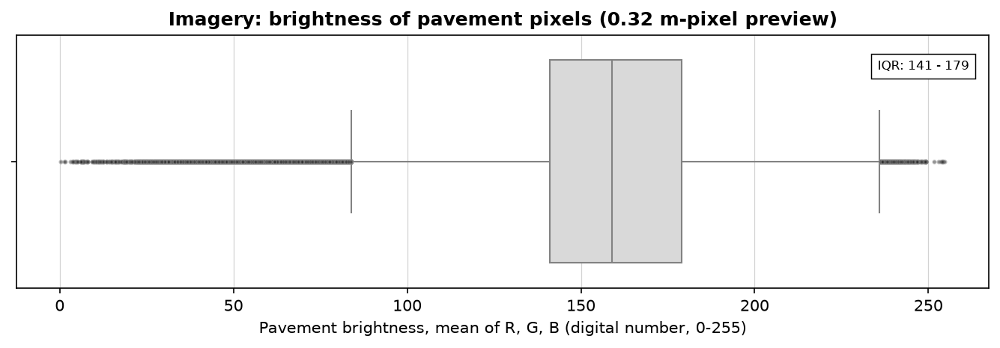

In [93]:
# ---------------------------------------------------------------------
# 06.1 (Step A) — Imagery: pavement brightness outliers
# ---------------------------------------------------------------------
pav_bright = rgb_u8[:, road_p].mean(axis=0)
iqr_report(pav_bright, "Pavement brightness (mean RGB)", "DN 0-255")
iqr_box(pav_bright, "Pavement brightness, mean of R, G, B (digital number, 0-255)",
        "Imagery: brightness of pavement pixels (0.32 m-pixel preview)", "#d9d9d9", 38, "Outliers_ImageryBrightness")

**What the box plot shows.** 5.4 % of the pavement pixels in the preview are outliers. Most are dark: 8,070 pixels
below 84 DN, which are tree and car shadows, oil stains and dark asphalt patches. Only 327 are bright (above 236 DN),
mostly road paint and light concrete. The dark tail is where the crack model is most likely to confuse shading
with cracks. The mask excluded the largest shadows, but small ones remain inside the pavement.

### 06.2 DEM: elevation above MHHW (analysis cells)

,Units,Lower bound,Upper bound,# low,# high,% outliers
Variable,,,,,,
Cell mean elevation above MHHW,m,-0.3094,1.8036,0,8,0.7086


,CellID,CentroidX,CentroidY,ElevMHHW,AreaFrac,SurfaceType
1085,1086,3.696334e+06,1.060592e+06,1.823128,0.000352,Sidewalk
1110,1111,3.696333e+06,1.060604e+06,1.856494,0.166288,Sidewalk
1111,1112,3.696334e+06,1.060605e+06,1.885274,0.142432,Sidewalk
249,250,3.696433e+06,1.060238e+06,1.890419,0.004016,Sidewalk
204,205,3.696404e+06,1.060235e+06,2.168496,0.214128,Sidewalk
203,204,3.696403e+06,1.060235e+06,2.197856,0.122160,Road
248,249,3.696404e+06,1.060238e+06,2.233561,0.056704,Sidewalk
247,248,3.696403e+06,1.060237e+06,2.244415,0.001472,Sidewalk


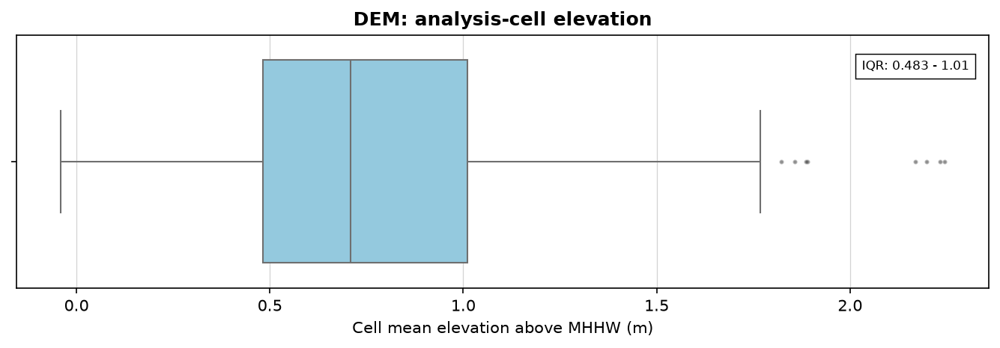

In [94]:
# ---------------------------------------------------------------------
# 06.2 (Step A) — DEM: cell-mean elevation outliers
# ---------------------------------------------------------------------
iqr_report(cells_land["ElevMHHW"], "Cell mean elevation above MHHW", "m", key="ElevMHHW", index=cells_land.index)
display(cells_land.loc[OUTLIER_FLAGS["ElevMHHW"]].sort_values("ElevMHHW")
        [["CellID", "CentroidX", "CentroidY", "ElevMHHW", "AreaFrac", "SurfaceType"]].head(10))
iqr_box(cells_land["ElevMHHW"], "Cell mean elevation above MHHW (m)", "DEM: analysis-cell elevation", "skyblue", 39,
        "Outliers_Elevation")

**What the table and box plot show.** There are 8 high outliers (1.82–2.24 m above MHHW, upper bound 1.80 m) and no
low ones.

- **Size.** All 8 are small slivers (AreaFrac ≤ 0.21), and 7 are sidewalk cells.
- **Location.** They sit at two spots: the east end of the Fairfax Ave arm in the northwest, and one raised spot on the southern
  arc near E 3,696,403, N 1,060,236.
- **Interpretation.** These are slivers of raised sidewalk or steps next to higher ground, not DEM errors. With their
  tiny pavement area they barely affect any statistic.

### 06.3 VDatum / MHHW

The IQR rule is **not meaningful** here. The surface is a smooth, nearly constant datum field of only a few pixels
across the site, so the check is simply that every value is physically plausible.

In [95]:
# ---------------------------------------------------------------------
# 06.3 (Step A) — VDatum: plausibility check instead of an IQR test
# ---------------------------------------------------------------------
_vd = vdatum_g[np.isfinite(vdatum_g)]
print(f"VDatum over the study area: {_vd.min():.3f} to {_vd.max():.3f} m NAVD88 (range {(_vd.max() - _vd.min()) * 1000:.1f} mm); "
      f"{'all values are plausible for MHHW near Norfolk (small and positive)' if (_vd > 0).all() and (_vd < 1).all() else 'CHECK: values outside 0-1 m'}")

VDatum over the study area: 0.386 to 0.387 m NAVD88 (range 1.1 mm); all values are plausible for MHHW near Norfolk (small and positive)


**Result.** All VDatum values over the study area (0.386–0.387 m NAVD88) are plausible for MHHW at Norfolk. There is
nothing to flag.

### 06.4 Road attributes: traffic counts

,Units,Lower bound,Upper bound,# low,# high,% outliers
Variable,,,,,,
AADT per counted segment,vehicles/day,-700.0,2340.0,0,14,16.4706


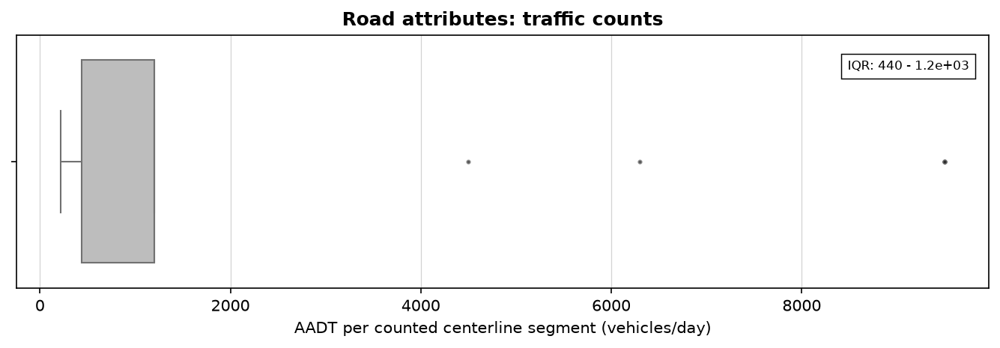

In [96]:
# ---------------------------------------------------------------------
# 06.4 (Step A) — Road attributes: AADT outliers among the counted segments
# ---------------------------------------------------------------------
_aadt_seg = centerlines["AADT"].dropna()
if len(_aadt_seg) >= 4:
    iqr_report(_aadt_seg, "AADT per counted segment", "vehicles/day")
    iqr_box(_aadt_seg, "AADT per counted centerline segment (vehicles/day)", "Road attributes: traffic counts", "#bdbdbd",
            40, "Outliers_AADT")
else:
    print(f"Only {len(_aadt_seg)} counted segment(s) -- too few for an IQR test; the counts are: {_aadt_seg.tolist()}")

**What the box plot shows.** Most counted segments carry 260–1,200 vehicles/day, so the IQR is narrow and the upper
bound is only 2,340. The 14 segments above it (16.5 %) are the 4,500, 6,300 and 9,500 vehicles/day streets (Memorial
Pl, Yarmouth St, Colonial Ave and W Olney Rd). These are real counts on busier streets, not errors. In the analysis
cells only the 4,500 class appears (67 cells).

### 06.5 Road cracks

The IQR rule is applied to the crack density of the cells **with** cracks; most cells are 0, so the IQR of all cells
collapses toward 0. Very small edge cells are listed too, because a sliver with little pavement can show an extreme
fraction only because the denominator is small.

,Units,Lower bound,Upper bound,# low,# high,% outliers
Variable,,,,,,
"Crack density, cracked cells",fraction,-0.1848,0.3359,0,81,8.8235


Of the 81 high crack-density cells, 4 are small edge cells (AreaFrac < 0.1):


,CellID,CrackDens,AreaFrac,CellArea_m2,TrafficClass
731,732,0.612304,1.000000,25.0000,"AADT 4,500"
349,350,0.604838,0.226864,5.6716,"AADT 4,500"
1115,1116,0.589424,1.000000,25.0000,"AADT 1,200"
1114,1115,0.573280,1.000000,25.0000,"AADT 1,200"
42,43,0.546848,1.000000,25.0000,"AADT 1,200"
761,762,0.542181,0.980544,24.5136,"AADT 4,500"
664,665,0.534224,1.000000,25.0000,"AADT 4,500"
791,792,0.530054,0.908224,22.7056,AADT 260
451,452,0.525248,1.000000,25.0000,"AADT 4,500"
56,57,0.515888,1.000000,25.0000,"AADT 1,200"


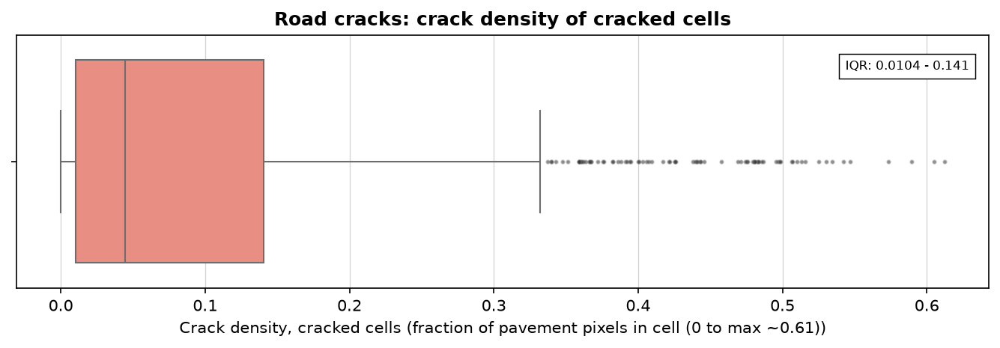

In [97]:
# ---------------------------------------------------------------------
# 06.5 (Step A) — Cracks: crack-density outliers among the cracked cells; small edge cells
# ---------------------------------------------------------------------
_cracked = cells_land[cells_land["CrackDens"] > 0]
iqr_report(_cracked["CrackDens"], "Crack density, cracked cells", "fraction", key="CrackDens", index=_cracked.index)
_hi = cells_land.loc[OUTLIER_FLAGS["CrackDens"]]
print(f"Of the {len(_hi)} high crack-density cells, {(_hi['AreaFrac'] < 0.1).sum()} are small edge cells (AreaFrac < 0.1):")
display(_hi.sort_values("CrackDens", ascending=False)[["CellID", "CrackDens", "AreaFrac", "CellArea_m2", "TrafficClass"]].head(10))
iqr_box(_cracked["CrackDens"], f"Crack density, cracked cells ({CRACK_UNITS.replace(chr(10), ' ')})",
        "Road cracks: crack density of cracked cells", "salmon", 41, "Outliers_CrackDensity")

**What the table and box plot show.** 81 of the 918 cracked cells (8.8 %) are above the upper bound of 0.336.

- **Not artefacts.** Only 4 of them are small edge slivers. Nine of the ten most cracked cells (0.52–0.61) are full or
  nearly full 25 m² squares.
- **Real hot spots.** These are genuine hot spots of dense, connected cracking. They should be kept, not removed.
- **Where.** The outlier map below places them on the AADT 4,500 and 1,200 streets: around the east-end loop, along
  the southeastern street and at the Mowbray Arch / Fairfax Ave corner.

### 06.6 Accuracy assessment points

The points are labels (0/1), not measurements, so an IQR test does not apply. The check is for points that could
not be assessed: unlabeled points, or points that fall outside the pavement mask.

In [98]:
# ---------------------------------------------------------------------
# 06.6 (Step A) — Accuracy points: points that cannot be assessed
# ---------------------------------------------------------------------
_unl = int((pd.to_numeric(acc.get(GRNDTRUTH_FIELD, pd.Series(dtype=float)), errors="coerce") == -1).sum())
print(f"Unlabeled points (GrndTruth = -1): {_unl}; points outside the pavement mask: "
      f"{int(round(len(acc) * (1 - pts_in_mask / 100)))} of {len(acc)}")

Unlabeled points (GrndTruth = -1): 0; points outside the pavement mask: 0 of 150


**Result.** No point is unlabeled and none falls outside the pavement mask. All 150 points are usable for the
accuracy assessment.

### 06.7 Relative sea level

The IQR rule is applied to the **monthly departures from the linear trend**. Outlier months are unusually high or
low water levels, often storm surges, nor'easters or persistent wind events. They show how far a single month can
stray from the long-term rise.

,Units,Lower bound,Upper bound,# low,# high,% outliers
Variable,,,,,,
Monthly departure from the linear trend,m,-0.1788,0.1742,4,13,1.4322


Largest departures:


,Year,Month,MSL_m,Residual_m
842,1998,2,0.409018,0.368359
983,2009,11,0.342316,0.244899
590,1977,2,-0.271982,-0.211202
412,1962,3,0.076492,0.209325
97,1935,11,-0.051684,0.208350
1154,2024,2,0.374018,0.207768
241,1947,11,-0.002684,0.199385
806,1995,2,-0.171982,-0.198150


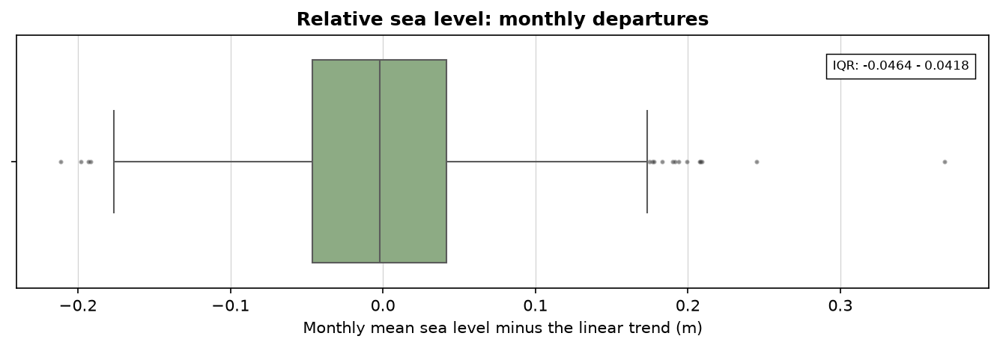

In [99]:
# ---------------------------------------------------------------------
# 06.7 (Step A) — Sea level: months with unusually large departures from the trend
# ---------------------------------------------------------------------
iqr_report(slt["Residual_m"], "Monthly departure from the linear trend", "m", key="SLT", index=slt.index)
print("Largest departures:")
display(slt.loc[OUTLIER_FLAGS["SLT"]].reindex(slt.loc[OUTLIER_FLAGS["SLT"], "Residual_m"].abs()
                                              .sort_values(ascending=False).index)[["Year", "Month", "MSL_m", "Residual_m"]].head(8))
iqr_box(slt["Residual_m"], "Monthly mean sea level minus the linear trend (m)", "Relative sea level: monthly departures",
        "#8ab17d", 42, "Outliers_SeaLevel")

**What the table and box plot show.**

- **How many.** 17 of the 1,185 months (1.4 %) are outliers: 13 high and 4 low.
- **Largest departures.** The largest is February 1998 (+0.37 m above the trend), followed by November 2009
  (+0.25 m), February 2024 (+0.21 m) and February 1977 (−0.21 m). The largest ones all fall in November–March, the
  nor'easter season. The 1998 and 2009 months match well-known nor'easters that flooded Norfolk.
- **Interpretation.** These are real events, not errors. The flood-days model uses the long-term level (trend and
  projection), not individual months, so they do not enter it.

### 06.8 Flood days per year

,Units,Lower bound,Upper bound,# low,# high,% outliers
Variable,,,,,,
Cell mean log10 flood days,log10 days/yr,-2.2422,2.8287,8,0,0.7086


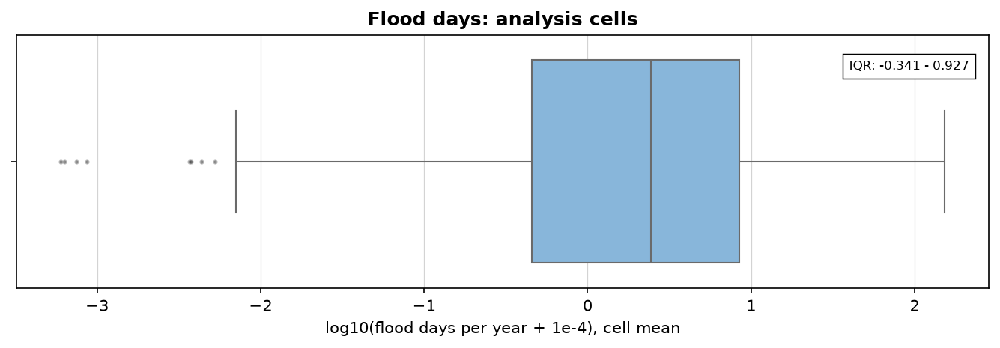

In [100]:
# ---------------------------------------------------------------------
# 06.8 (Step A) — Flood days: outliers of the cell log10 flood days
# ---------------------------------------------------------------------
iqr_report(cells_land["LogFloodDays"], "Cell mean log10 flood days", "log10 days/yr", key="LogFloodDays",
           index=cells_land.index)
iqr_box(cells_land["LogFloodDays"], "log10(flood days per year + 1e-4), cell mean", "Flood days: analysis cells",
        "#7ab8e8", 43, "Outliers_FloodDays")

**What the box plot shows.** There are 8 low outliers in log10 flood days (below −2.24, i.e. fewer than about
0.006 days/yr) and no high ones. They are the same 8 high sidewalk slivers flagged in 06.2: the least flooded spots,
not the most flooded. On the log scale even the most frequently flooded cells (up to 152 days/yr) are within the
whiskers. The heavy upper tail seen in raw flood days is therefore a scale effect, not an outlier problem.

IQR outlier bounds (1.5 x IQR beyond Q1/Q3), every dataset:


,Units,Lower bound,Upper bound,# low,# high,% outliers
Variable,,,,,,
Pavement brightness (mean RGB),DN 0-255,84.0000,236.0000,8070,327,5.4367
Cell mean elevation above MHHW,m,-0.3094,1.8036,0,8,0.7086
AADT per counted segment,vehicles/day,-700.0000,2340.0000,0,14,16.4706
"Crack density, cracked cells",fraction,-0.1848,0.3359,0,81,8.8235
Monthly departure from the linear trend,m,-0.1788,0.1742,4,13,1.4322
Cell mean log10 flood days,log10 days/yr,-2.2422,2.8287,8,0,0.7086


Map: analysis cells flagged as outliers


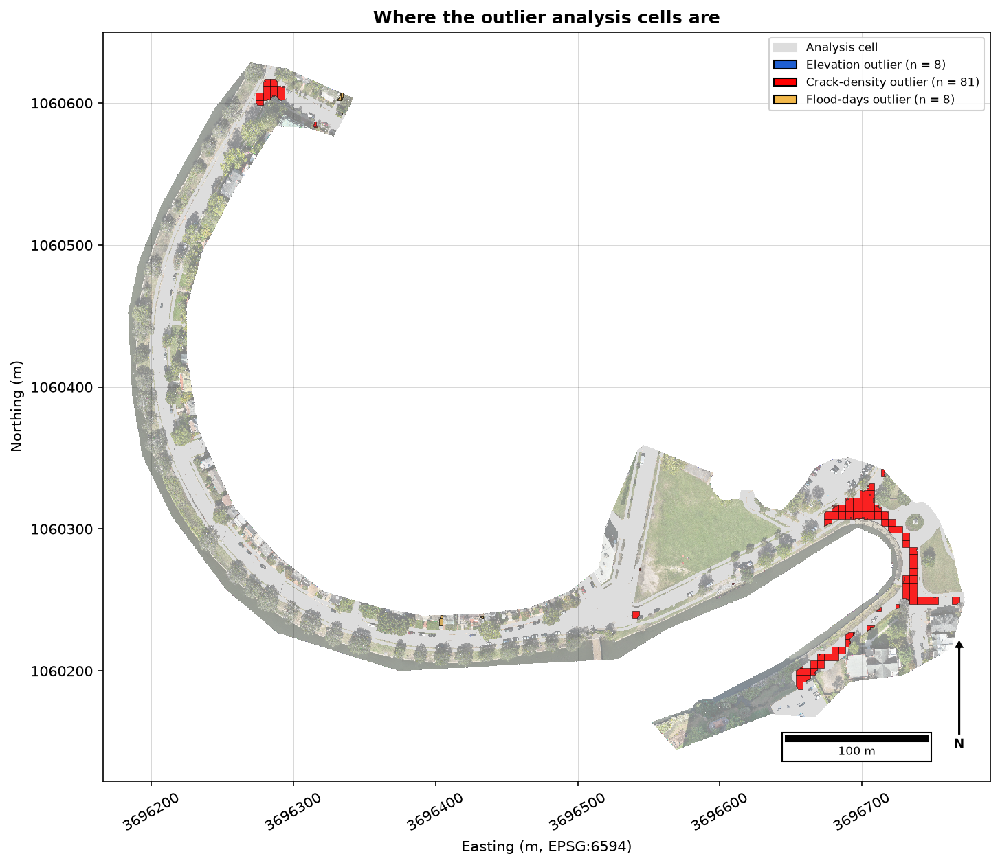

In [101]:
# ---------------------------------------------------------------------
# 06.9 (Step A) — All outlier bounds, and a map of the outlier analysis cells
# ---------------------------------------------------------------------
outliers_tbl = pd.DataFrame(OUTLIER_ROWS).set_index("Variable")
print("IQR outlier bounds (1.5 x IQR beyond Q1/Q3), every dataset:")
display(outliers_tbl.round(4))
print("Map: analysis cells flagged as outliers")
fig, ax = plt.subplots(figsize=(10, 8.5), dpi=FIG_DPI)
draw_imagery(ax, alpha=0.5)
cells_gdf.plot(ax=ax, facecolor="#dddddd", edgecolor="none", zorder=1)
_h = [mpatches.Patch(color="#dddddd", label="Analysis cell")]
for key, colr, lab in (("ElevMHHW", "#1f5fd1", "Elevation outlier"), ("CrackDens", "red", "Crack-density outlier"),
                       ("LogFloodDays", "#f2b84b", "Flood-days outlier")):
    _g = cells_gdf.loc[cells_gdf.index.isin(OUTLIER_FLAGS.get(key, []))]
    if len(_g):
        _g.plot(ax=ax, facecolor=colr, edgecolor="black", linewidth=0.3, zorder=2, alpha=0.85)
    _h.append(mpatches.Patch(facecolor=colr, edgecolor="black", label=f"{lab} (n = {len(_g):,})"))
ax.legend(handles=_h, loc="upper right", fontsize=8, framealpha=0.9)
ax.set_xlim(P_EXTENT[0], P_EXTENT[1]); ax.set_ylim(P_EXTENT[2], P_EXTENT[3])
map_axes(ax, "Where the outlier analysis cells are")
plt.tight_layout()
save_fig(fig, 44, "Outliers_CellMap", 6, maps=True)
plt.show()

**What the map shows.** The crack-density outliers (red) form continuous clusters along the east-end streets and at
the Fairfax Ave corner, so they reflect real spatial patterns, not isolated noise. The elevation and flood-days
outliers are the same few slivers, too small to see at this scale.

--------------------------------------------------------------------------------------

**Section 06 summary: outliers.**

1. **Imagery.** 5.4 % of the pavement preview pixels are outliers, almost all dark (shadows, stains, patches). These
   are where crack detection is least reliable.
2. **DEM.** 8 high cell-elevation outliers (1.82–2.24 m above MHHW), all small sidewalk/edge slivers at two raised
   spots. They are real and have negligible weight. There are no low outliers.
3. **VDatum.** No outliers by nature; all values are plausible (0.386–0.387 m).
4. **Road attributes.** 14 counted segments (16.5 %) exceed the upper bound. These are the 4,500–9,500 vehicles/day
   streets: real values on the busier roads, not errors.
5. **Road cracks.** 81 cracked cells (8.8 %) are high outliers (> 0.336). Only 4 are edge slivers; the rest are full
   cells forming hot spots on the busier east-end streets and at the Fairfax Ave corner. They are kept.
6. **Accuracy points.** All 150 are labeled and inside the mask.
7. **Sea level.** 17 months (1.4 %) are outliers, led by the February 1998 and November 2009 nor'easters. They do not
   enter the 2025 flood-days model, which uses the long-term level.
8. **Flood days.** The 8 outliers are at the *low* end (the high slivers of 06.2, < 0.006 days/yr). Frequently
   flooded cells are not outliers on the log scale.

**Decision for the analysis:** no values are removed. Outliers are real features, and the influence of small edge
cells is handled by weighting or filtering on `AreaFrac`.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 07) First look at relationships (exploratory)

First looks at how crack density relates to the candidate predictors, on the 5 m analysis cells.

**Caution:** neighbouring cells are spatially autocorrelated, so they are not independent. The p-values below
(regression line, Kruskal–Wallis tests) treat every cell as independent and therefore **overstate** significance.
They describe the pattern; they do not test it. The formal tests belong in the analysis notebook, using spatially
robust standard errors.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 07.1 Rank correlations

Heatmap: Spearman rank correlation between per-cell variables (analysis cells)


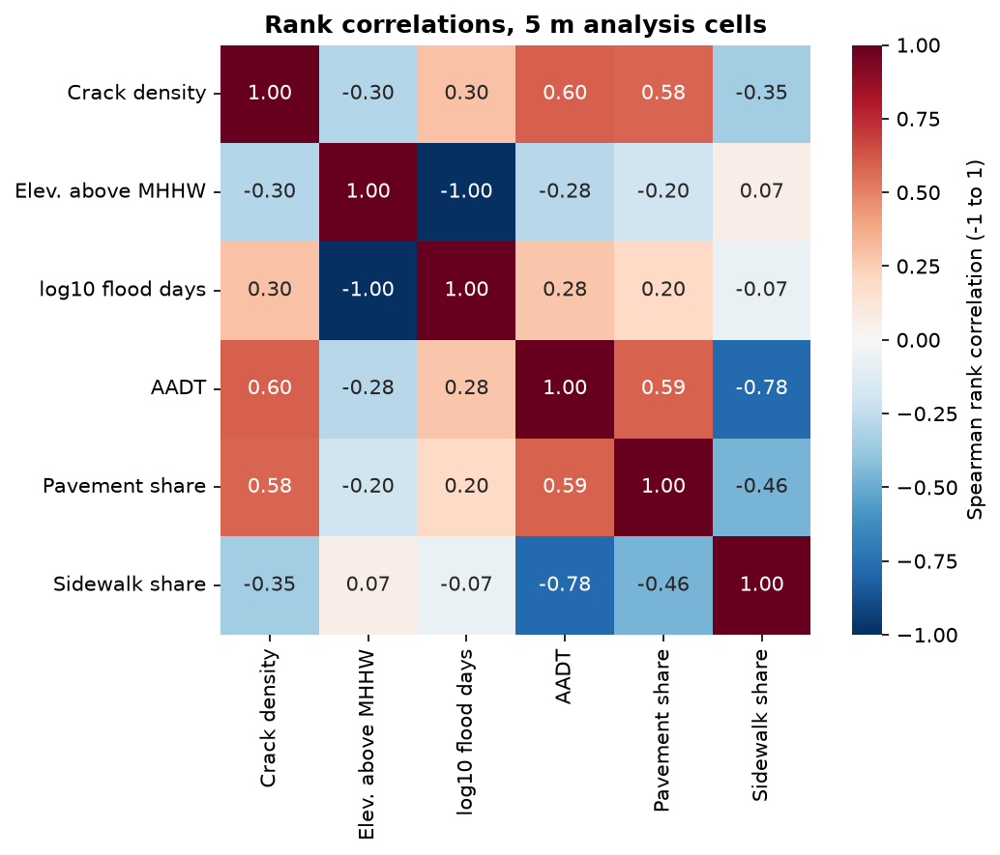

In [102]:
# ---------------------------------------------------------------------
# 07.1 (Step A) — Spearman rank correlations between the per-cell variables
# ---------------------------------------------------------------------
corr_cols = ["CrackDens", "ElevMHHW", "LogFloodDays", "AADT", "AreaFrac", "SidewalkFrac"]
corr_labels = ["Crack density", "Elev. above MHHW", "log10 flood days", "AADT", "Pavement share", "Sidewalk share"]
corr = cells_land[corr_cols].corr(method="spearman")
corr.index = corr.columns = corr_labels
print("Heatmap: Spearman rank correlation between per-cell variables (analysis cells)")
fig, ax = plt.subplots(figsize=(7.5, 6), dpi=FIG_DPI)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Spearman rank correlation (-1 to 1)"}, ax=ax)
ax.set_title(f"Rank correlations, {FISHNET_CELL_M} m analysis cells", fontweight="bold")
plt.tight_layout()
save_fig(fig, 45, "SpearmanHeatmap", 7)
plt.show()

**What the heatmap shows.**

- **Flood exposure.** Crack density has a moderate rank correlation with flood exposure: ρ = −0.30 with elevation
  and +0.30 with log10 flood days. Elevation and log10 flood days are perfectly anti-correlated (ρ = −1.00), because
  one is a monotonic function of the other.
- **Traffic and cell size.** Crack density correlates more strongly with AADT (ρ = +0.60) and with the cell's
  pavement share (+0.58). It correlates negatively with the sidewalk share (−0.35).
- **Possible confounders.** AADT is itself correlated with low elevation (ρ = −0.28 with elevation, +0.28 with
  flood days) and with pavement share (+0.59). Busier roads are lower, wider and less often sliver cells. Traffic
  and cell size are therefore potential **confounders** of the flood–crack association.

### 07.2 Crack density vs. elevation and flood days

In [103]:
# ---------------------------------------------------------------------
# 07.2 (Step A) — Shared helpers: p-value text and the class bar chart
# ---------------------------------------------------------------------
def p_text(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


def class_bar_chart(groups, labels, colors, xlabel, title, fig_num, short):
    """Mean crack density per class with +/- 1 SE bars, value and n labels, and a Kruskal-Wallis footnote."""
    means = [g.mean() if len(g) else np.nan for g in groups]
    ses = [g.sem() if len(g) > 1 else 0.0 for g in groups]
    ns = [len(g) for g in groups]
    fig, ax = plt.subplots(figsize=(11, 6), dpi=FIG_DPI)
    ax.bar(range(len(groups)), means, yerr=ses, color=colors, edgecolor="black", linewidth=0.7, capsize=5,
           error_kw=dict(elinewidth=1))
    top = np.nanmax([m + s for m, s in zip(means, ses)])
    for i, (m, s, n_) in enumerate(zip(means, ses, ns)):
        if np.isfinite(m):
            ax.text(i, m + s + top * 0.01, f"{m:.3f}\n(n={n_:,})", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(len(groups))); ax.set_xticklabels(labels, fontsize=11)
    ax.set_ylim(0, top * 1.18)
    ax.set_xlabel(xlabel, fontsize=13); ax.set_ylabel(f"Mean crack density\n({CRACK_UNITS})")
    ax.set_title(title, fontweight="bold", fontsize=16)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="lightgray", linewidth=0.6); ax.set_axisbelow(True)
    _g = [g for g in groups if len(g) > 0]
    kw = f"Kruskal–Wallis H test {p_text(stats.kruskal(*_g).pvalue)}" if len(_g) >= 2 else "Kruskal–Wallis: < 2 groups"
    fig.text(0.5, 0.01, f"Total n = {sum(ns):,} pavement cells ({FISHNET_CELL_M} m grid); error bars = ±1 SE; {kw}",
             ha="center", style="italic", color=COLOR_GREY, fontsize=10)
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    save_fig(fig, fig_num, short, 7)
    plt.show()

Linear fit on the 1,129 cells: CrackDens = 0.1731 - 0.1184 x ElevMHHW;  r2 = 0.115;  p < 0.001 (naive, see caution)
Line + bar chart: crack density vs. elevation above MHHW


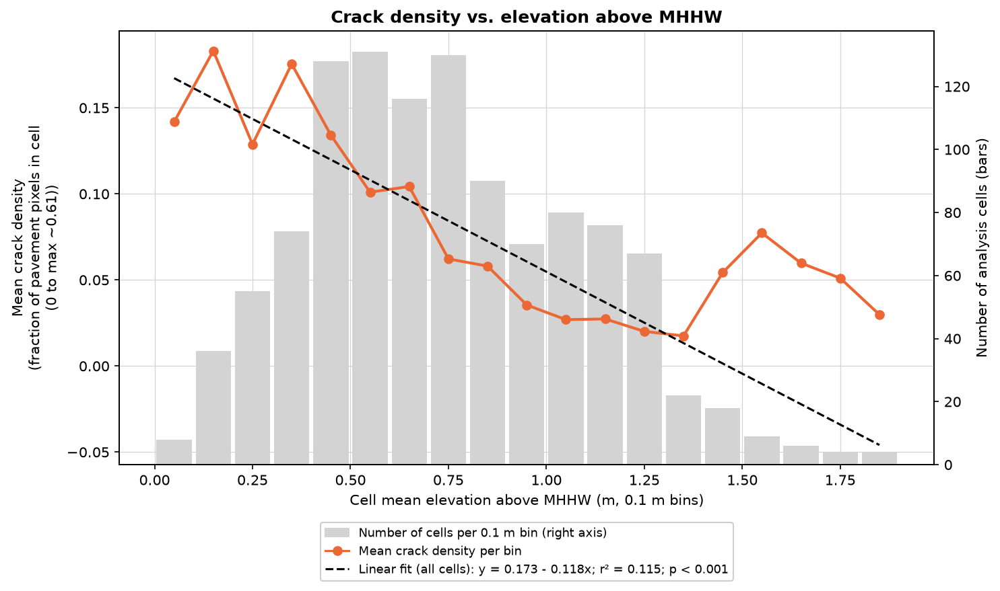

In [104]:
# ---------------------------------------------------------------------
# 07.2 (Step B) — Crack density vs elevation above MHHW: binned means, cell counts and a fitted line
# ---------------------------------------------------------------------
_e = cells_land["ElevMHHW"]
ebins = np.arange(np.floor(_e.quantile(0.005) * 10) / 10, _e.quantile(0.995) + 0.1, 0.1)
cells_land["ElevBin"] = pd.cut(_e, ebins)
by_elev = cells_land.groupby("ElevBin", observed=True).agg(Cells=("CrackDens", "size"), MeanCrack=("CrackDens", "mean"))
by_elev["BinMid_m"] = [iv.mid for iv in by_elev.index]
fit = stats.linregress(cells_land["ElevMHHW"], cells_land["CrackDens"])
print(f"Linear fit on the {len(cells_land):,} cells: CrackDens = {fit.intercept:.4f} {'+' if fit.slope >= 0 else '-'} "
      f"{abs(fit.slope):.4f} x ElevMHHW;  r2 = {fit.rvalue ** 2:.3f};  {p_text(fit.pvalue)} (naive, see caution)")
print("Line + bar chart: crack density vs. elevation above MHHW")
fig, ax = plt.subplots(figsize=(10, 6), dpi=FIG_DPI)
ax2 = ax.twinx()
ax2.bar(by_elev["BinMid_m"], by_elev["Cells"], width=0.09, color="lightgray", zorder=1)
ax2.set_ylabel("Number of analysis cells (bars)")
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.plot(by_elev["BinMid_m"], by_elev["MeanCrack"], "o-", color=COLOR_ACCENT, linewidth=2)
_xx = np.array([by_elev["BinMid_m"].min(), by_elev["BinMid_m"].max()])
ax.plot(_xx, fit.intercept + fit.slope * _xx, color="black", linestyle="--", linewidth=1.5)
ax.set_xlabel("Cell mean elevation above MHHW (m, 0.1 m bins)"); ax.set_ylabel(f"Mean crack density\n({CRACK_UNITS})")
ax.set_title("Crack density vs. elevation above MHHW", fontweight="bold"); style_ax(ax)
ax.legend(handles=[mpatches.Patch(color="lightgray", label="Number of cells per 0.1 m bin (right axis)"),
                   mlines.Line2D([], [], color=COLOR_ACCENT, marker="o", label="Mean crack density per bin"),
                   mlines.Line2D([], [], color="black", linestyle="--",
                                 label=f"Linear fit (all cells): y = {fit.intercept:.3f} {'+' if fit.slope >= 0 else '-'} "
                                       f"{abs(fit.slope):.3f}x; r² = {fit.rvalue ** 2:.3f}; {p_text(fit.pvalue)}")],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=1, fontsize=8.5, framealpha=0.95)
plt.tight_layout()
save_fig(fig, 46, "Crack_vs_Elevation", 7)
plt.show()

**What the plot shows.**

- **Low cells.** Mean crack density is highest (≈ 0.13–0.18) in the cells lowest above MHHW (0–0.45 m).
- **The decline.** It falls steadily to ≈ 0.02–0.03 at 1.0–1.35 m.
- **Fitted line.** CrackDens = 0.173 − 0.118 × elevation: each metre of elevation lowers crack density by about
  0.12. The fit explains only 11.5 % of the cell-to-cell variance (r² = 0.115), so elevation is one factor among
  several.
- **The upturn.** The bin means rise again above 1.4 m, but those bins hold fewer than about 20 cells each, and the
  highest include the raised slivers of 06.2. Their means are noisy.

Mean crack density by flood-day class (2025):


,Cells,MeanCrack,SE,ShareCracked
FloodClass,,,,
≤ 0.5,294,0.0299,0.0027,0.7959
0.5–1.5,161,0.0488,0.0058,0.7888
1.5–3,161,0.0666,0.0072,0.8199
3–7,193,0.1097,0.0115,0.7720
7–14,153,0.1308,0.0130,0.8301
14–30,98,0.1573,0.0155,0.9082
30–60,50,0.1540,0.0206,0.8800
60–90,15,0.1557,0.0331,0.8667
90–300,4,0.2274,0.0984,0.7500


Bar chart: crack density by flood frequency


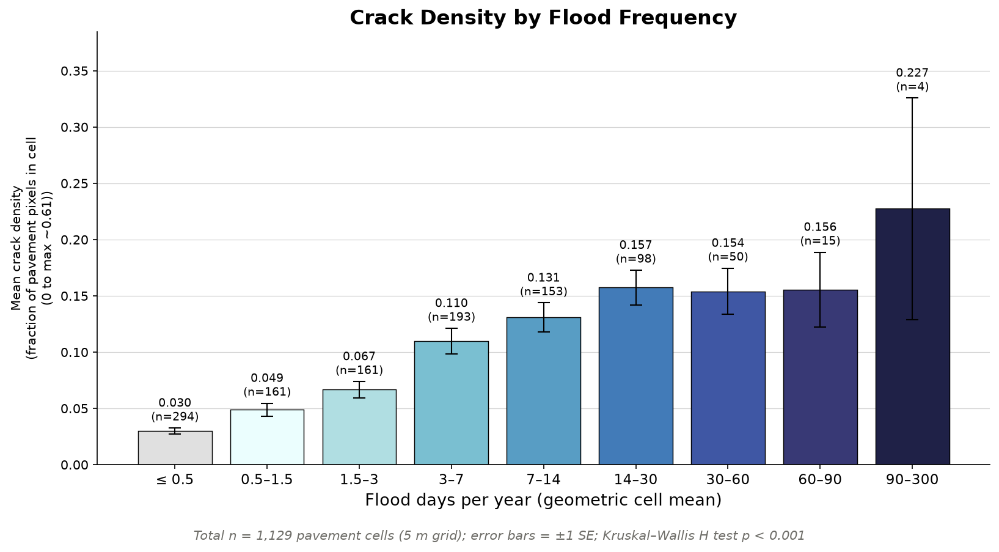

In [105]:
# ---------------------------------------------------------------------
# 07.2 (Step C) — Mean crack density by flood-day class (geometric cell mean, 01.8 classes)
# ---------------------------------------------------------------------
_fl_labels = ["≤ 0.5"] + [f"{lo:g}–{hi:g}" for lo, hi in zip(FLOOD_BOUNDS[1:-1], FLOOD_BOUNDS[2:])]
cells_land["FloodClass"] = pd.cut(cells_land["FloodDaysGeo"], FLOOD_BOUNDS, include_lowest=True, labels=_fl_labels)
by_flood = cells_land.groupby("FloodClass", observed=False).agg(
    Cells=("CrackDens", "size"), MeanCrack=("CrackDens", "mean"), SE=("CrackDens", "sem"),
    ShareCracked=("CrackDens", lambda v: (v > 0).mean()))
print(f"Mean crack density by flood-day class ({FLOOD_YEAR}):")
display(by_flood.round(4))
_present = [i for i, n_ in enumerate(by_flood["Cells"]) if n_ > 0]
_bar_cols = ["#e0e0e0"] + [FLOOD_CLASS_COLORS[i] for i in range(1, len(FLOOD_CLASS_COLORS))]
_bar_cols[-2] = "#1f2147"                                          # very dark navy instead of pure black for 90-300
print("Bar chart: crack density by flood frequency")
class_bar_chart([cells_land.loc[cells_land["FloodClass"] == _fl_labels[i], "CrackDens"] for i in _present],
                [_fl_labels[i] for i in _present], [_bar_cols[i] for i in _present],
                "Flood days per year (geometric cell mean)", "Crack Density by Flood Frequency", 47, "Crack_by_FloodClass")

**What the chart shows.**

- **The rise.** Mean crack density rises steadily with flood frequency, from 0.030 in the rarely flooded cells
  (≤ 0.5 days/yr, n = 294) to 0.157 at 14–30 days/yr: about a five-fold increase.
- **Plateau.** It then levels off at ≈ 0.155 through 60–90 days/yr. The highest class (90–300 days/yr) reaches 0.227,
  but with only 4 cells and a wide error bar.
- **Share of cells with any crack.** It changes much less (75–91 %), so flooding is associated mainly with *how much*
  of a cell is cracked, not with *whether* it cracks.
- **Significance.** The Kruskal–Wallis test (p < 0.001) confirms the classes differ, subject to the caution about
  spatial autocorrelation.

### 07.3 Crack density by traffic / surface class

Mean crack density by traffic / surface class:


,Cells,MeanCrack,SE
TrafficClass,,,
Sidewalk/driveway,360,0.0273,0.0031
Uncounted road,141,0.0210,0.0032
AADT 260,354,0.0769,0.0059
"AADT 1,200",207,0.1657,0.0093
"AADT 4,500",67,0.3079,0.0204


Bar chart: crack density by traffic / surface class


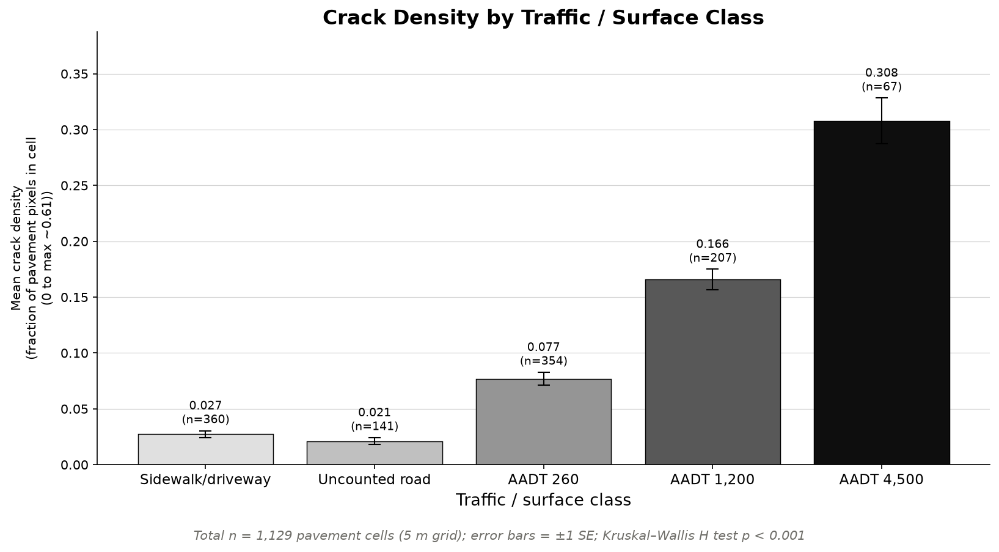

In [106]:
# ---------------------------------------------------------------------
# 07.3 (Step A) — Mean crack density by traffic / surface class
# ---------------------------------------------------------------------
grp = (cells_land.groupby("TrafficClass")["CrackDens"].agg(["size", "mean", "sem"])
       .rename(columns={"size": "Cells", "mean": "MeanCrack", "sem": "SE"}).reindex(TRAFFIC_ORDER))
print("Mean crack density by traffic / surface class:")
display(grp.round(4))
_tc_present = [c for c in TRAFFIC_ORDER if (cells_land["TrafficClass"] == c).any()]
_grays = ["#e0e0e0", "#c0c0c0"] + list(plt.cm.Greys(np.linspace(0.5, 0.95, max(1, len(_tc_present) - 2))))
print("Bar chart: crack density by traffic / surface class")
class_bar_chart([cells_land.loc[cells_land["TrafficClass"] == c, "CrackDens"] for c in _tc_present], _tc_present,
                _grays[:len(_tc_present)], "Traffic / surface class", "Crack Density by Traffic / Surface Class", 48,
                "Crack_by_TrafficClass")

**What the chart shows.**

- **No traffic.** Sidewalk/driveway cells (0.027) and uncounted road cells (0.021) are the least cracked. The
  uncounted roads are mostly parking-lot lanes with little traffic.
- **Counted roads.** Crack density rises in step with traffic: 0.077 at AADT 260, 0.166 at 1,200 and 0.308 at 4,500
  vehicles/day.
- **Size of the effect.** The busiest class is cracked about 11 times more than the sidewalks and 4 times more than
  Mowbray Arch. This is a larger spread than across the flood classes (≈ 5×).
- **Significance.** The Kruskal–Wallis test gives p < 0.001.

--------------------------------------------------------------------------------------

**Section 07 summary: first look at relationships.**

- **Elevation and flood days.**
  - Crack density falls with elevation: slope −0.118 per m, r² = 0.115, Spearman ρ = −0.30.
  - It rises about five-fold from the rarely flooded cells (0.030 at ≤ 0.5 days/yr) to the 14–30 days/yr class
    (0.157), then levels off. The most-flooded classes hold only 15 and 4 cells, so their means are uncertain.
  - This is the pattern expected if frequent flooding damages pavement.
- **Elevation vs. flood days.** These are the same exposure on different scales; their Spearman correlation is −1.00
  by construction. Only one of them belongs in a model, and log10 flood days is the more interpretable one.
- **Traffic and surface type.**
  - Traffic shows the strongest association: crack density climbs from 0.021–0.027 (uncounted roads, sidewalks) to
    0.308 at 4,500 vehicles/day (ρ = +0.60).
  - Traffic is also correlated with low elevation (ρ = −0.28). The busiest street (Memorial Pl / Yarmouth St) lies in
    one of the most flooded areas. Part of the apparent flood effect may therefore be a traffic effect, and the
    reverse. Traffic class must be controlled for when estimating the flood effect.
  - Cell size (pavement share) is correlated with both cracking (+0.58) and traffic (+0.59), so it belongs in the
    model as a weight or covariate.
- **Caution.** The r² and p-values treat cells as independent. They describe the pattern but overstate its
  significance.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 08) Summary, EDA note & initial conclusions

The cells below print the key numbers. When `WRITE_REPORTS = True`, they also write them, with every coverage,
overlap, statistics and outlier table, to `REPORTS/02_Notes/OUT_REPORTS_NB00_Sec08/EDA_Summary_<stamp>.txt`.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

In [107]:
# ---------------------------------------------------------------------
# 08 (Step A) — Key numbers
# ---------------------------------------------------------------------
_kappa = acc_metrics["Cohen's kappa"] if acc_metrics is not None else np.nan
key = pd.Series({
    "Study area (m2)": f"{AOI_AREA_M2:,.0f}",
    "Pavement area (m2)": f"{TOTAL_MASK_PX * REF_RES ** 2:,.0f}",
    f"Analysis cells ({FISHNET_CELL_M} m), with flood days": f"{len(cells_land):,}",
    "Overall crack fraction of pavement": f"{TOTAL_CRACK_PX / max(TOTAL_MASK_PX, 1):.4f}",
    "Cells with no cracks (%)": f"{(cells_land['CrackDens'] == 0).mean() * 100:.1f}",
    "Maximum cell crack density": f"{CRACK_MAX:.3f}",
    "Median cell elevation above MHHW (m)": f"{cells_land['ElevMHHW'].median():.3f}",
    f"Median geometric-mean flood days {FLOOD_YEAR}": f"{cells_land['FloodDaysGeo'].median():.2f}",
    "Road cells with an AADT count (%)": f"{((cells['SurfaceType'] == 'Road') & cells['AADT'].notna()).sum() / max((cells['SurfaceType'] == 'Road').sum(), 1) * 100:.1f}",
    "Crack-raster Cohen's kappa": f"{_kappa:.3f}",
    "Spearman: crack density vs log10 flood days": f"{corr.loc['Crack density', 'log10 flood days']:.3f}",
    "Spearman: crack density vs AADT": f"{corr.loc['Crack density', 'AADT']:.3f}",
    "Spearman: AADT vs elevation above MHHW": f"{corr.loc['AADT', 'Elev. above MHHW']:.3f}",
    "Linear fit crack ~ elevation (slope per m, r2)": f"{fit.slope:.4f}, {fit.rvalue ** 2:.3f}",
    "Mean crack density, lowest vs highest populated flood class": (
        f"{by_flood['MeanCrack'].dropna().iloc[0]:.3f} vs {by_flood['MeanCrack'].dropna().iloc[-1]:.3f}"),
    "Mean crack density, sidewalk vs busiest traffic class": (
        f"{grp['MeanCrack'].dropna().iloc[0]:.3f} vs {grp['MeanCrack'].dropna().iloc[-1]:.3f}"),
    f"RSLR {FLOOD_YEAR}: observed annual mean vs projection (m, rel. 2000)": f"{_obs2025:.3f} vs {RSLR_FLOOD_YEAR:.3f}",
}, name="value")
print("Key numbers:")
display(key.to_frame())

Key numbers:


,value
Study area (m2),"329,275"
Pavement area (m2),"12,293"
"Analysis cells (5 m), with flood days","1,129"
Overall crack fraction of pavement,0.1292
Cells with no cracks (%),18.7
Maximum cell crack density,0.612
Median cell elevation above MHHW (m),0.708
Median geometric-mean flood days 2025,2.44
Road cells with an AADT count (%),81.7
Crack-raster Cohen's kappa,0.840


In [108]:
# ---------------------------------------------------------------------
# 08 (Step B) — Write the EDA summary note (time-stamped) and list the package versions
# ---------------------------------------------------------------------
if WRITE_REPORTS:
    REPORT_OUT.mkdir(parents=True, exist_ok=True)
    note = REPORT_OUT / f"EDA_Summary_{STAMP}.txt"
    with pd.option_context("display.width", 250, "display.max_columns", 50, "display.max_colwidth", 80):
        parts = [
            "NB00 - Exploratory data analysis, Hague 2025 road cracking & flooding",
            "=" * 90, f"Run stamp: {STAMP}   |   project: {PROJECT}", "",
            "REFERENCE GRID", json.dumps(gridspec, indent=2), "",
            "KEY NUMBERS", key.to_string(), "",
            "01) DATASETS", sec01_summary.to_string(), "",
            "02) Q4 SPATIAL BOUNDS", spatial_bounds.drop(columns=["xmin (m)", "ymin (m)", "xmax (m)", "ymax (m)"]).to_string(), "",
            "02) Q5 SPATIAL RESOLUTION", spatial_res.to_string(), "",
            "02) Q6 TEMPORAL COVERAGE", temporal.to_string(index=False), "",
            "04) Q7 RESOLUTION & ALIGNMENT", align.to_string(), "",
            "04) Q8 SPATIAL OVERLAP WITH ANALYSIS CELLS (%)", overlap.round(1).to_string(),
            "   Centerline length on pavement (%):", cl_in_mask.round(1).to_string(),
            "   Inside the imaged corridor (%):", cl_in_mask_img.round(1).to_string(),
            f"   Accuracy points inside the pavement: {pts_in_mask:.1f} %", "",
            "05) ELEVATION", elev_stats.round(3).to_string(), "",
            "05) TRAFFIC / SURFACE CLASSES", traffic_tbl.round(1).to_string(), "",
            "05) SEA LEVEL", rslr_stats.round(3).to_string(), "",
            "05) FLOOD-DAY CLASS SHARES (% of cells)", flood_class_share.round(2).to_string(), "",
            "05) CRACK-RASTER ACCURACY", acc_metrics.round(3).to_string() if acc_metrics is not None else "n/a", "",
            "06) OUTLIERS (IQR)", outliers_tbl.round(4).to_string(), "",
            "07) CRACK DENSITY BY FLOOD-DAY CLASS", by_flood.round(4).to_string(), "",
            "07) CRACK DENSITY BY TRAFFIC / SURFACE CLASS", grp.round(4).to_string(), "",
            f"07) LINEAR FIT crack ~ elevation: intercept {fit.intercept:.4f}, slope {fit.slope:.4f}, "
            f"r2 {fit.rvalue ** 2:.3f}, p {fit.pvalue:.3g} (naive)", "",
            "SOURCES: Ezer (2022) doi:10.1029/2022EF002786; Sweet et al. (2017) NOAA Tech. Rep. NOS CO-OPS 083; "
            "USACE (2022) Sea-level change curve calculator; NOAA CO-OPS (2026) Relative sea level trend 8638610; "
            "Tukey (1977); Cohen (1960).",
        ]
        note.write_text("\n".join(parts), encoding="utf-8")
    print(f"[saved] {note.relative_to(PROJECT)}")
print("\nPackage versions:", {m.__name__: getattr(m, "__version__", "?") for m in
                              (np, pd, gpd, shapely, pyproj, rasterio, sns, requests)})

[saved] REPORTS\02_Notes\OUT_REPORTS_NB00_Sec08\EDA_Summary_20261122_104844.txt

Package versions: {'numpy': '2.4.6', 'pandas': '3.0.6', 'geopandas': '1.1.3', 'shapely': '2.1.2', 'pyproj': '3.6.1', 'rasterio': '1.4.4', 'seaborn': '0.13.2', 'requests': '2.34.2'}


--------------------------------------------------------------------------------------

**Overall summary of the EDA:**

1. **Data access.**
   - Every external dataset is pulled from a public endpoint for the study area only:
     - LERC tiles for the three image services;
     - paged queries for the three feature layers;
     - Data API / JSON API for the NOAA sea level record.
   - The project-made inputs are small files in `01_Raw_Data_Custom`, so nothing large lives in the repository.
2. **Derived flood exposure.**
   - Flood days per year for 2025 come from the drone DEM, converted to height above MHHW with NOAA VDatum
     (≈ 0.386 m NAVD88 over the whole site), with open water removed and Ezer's (2022) equation applied.
   - The result is a 0.5 m raster snapped to the imagery. Pavement cells have a median of 2.4 flood days/yr, and
     6.1 % of them flood on 30 or more days.
3. **Coverage.**
   - **Spatially:** the drone data cover a C-shaped street corridor (≈ 17 % of the 329,275 m² rectangle) holding
     12,293 m² of pavement. VDatum and the vector layers extend beyond it and are clipped.
   - **Temporally:** 11 of 14 datasets include 2025, and the core variables share the 3 October 2025 survey. Traffic
     and the City layers are older snapshots. The tide-gauge record (1927–2026) supplies the long-term context.
4. **Integration.**
   - Every raster sits on one 0.5 m grid snapped to the 0.02 m imagery.
   - The **1,129 analysis cells** (5 m fishnet clipped to the shrunk road mask) carry exact crack densities,
     geometric-mean flood days, elevation, sidewalk share and traffic class. All have a flood-days value.
   - 81.7 % of the road cells carry an AADT count.
5. **Distributions.**
   - Crack density is zero-inflated (18.7 % zeros) and right-skewed, with a maximum of 0.61.
   - Flood days span five orders of magnitude and are roughly log-normal.
   - Only three traffic levels (260, 1,200 and 4,500 vehicles/day) reach the analysis cells.

**Initial conclusions from the EDA**

1. **The data support the study question.**
   - Every variable the hypothesis needs covers the same 1,129 pavement cells, at the same time, on one exact grid:
     crack density, flood exposure, traffic, and the surface type that controls for it.
   - DEM, VDatum and flood days cover 100 % of the cells, and the crack raster fully classifies 97 % of them.
   - The analysis can proceed on the 5 m analysis cells without further cleaning.
2. **The crack map is reliable enough to use.**
   - Overall accuracy is 0.92 and κ = 0.84, with balanced errors (7 misses, 5 false cracks).
   - Differences in crack density of a few percentage points between classes are therefore meaningful, but single
     cells carry some classification noise.
3. **Cracking rises with flood exposure.**
   - Crack density falls with elevation (−0.12 per m) and rises about five-fold from the rarely flooded cells (0.030)
     to those flooded 14–30 days/yr (0.157).
   - The increase is steady over the first five classes and then levels off. This is consistent with the hypothesis
     that repeated tidal flooding weakens pavement.
   - It is an association in one snapshot, not proof of cause, and elevation alone explains only ≈ 12 % of the
     variance.
4. **Traffic is an even stronger correlate, and it overlaps with flooding.**
   - Crack density climbs eleven-fold from sidewalks (0.027) to the 4,500 vehicles/day streets (0.308). Its rank
     correlation with AADT (+0.60) is twice that with flood days (+0.30).
   - The busiest streets around the east-end loop are also among the lowest and most flooded (ρ AADT–elevation =
     −0.28).
   - Separating the two effects is the central task of the analysis. It needs a model with traffic / surface class
     as a control, or a comparison of flood classes *within* each traffic class, e.g. along Mowbray Arch (AADT 260,
     354 cells), which spans both high and low ground.
5. **Cell size must be accounted for.**
   - Small edge cells are less cracked: crack density correlates +0.58 with pavement share.
   - 59 % of the cells are less than half a square, and their size also correlates with traffic.
   - Cells should be weighted by pavement area, or the slivers filtered (e.g. `AreaFrac` ≥ 0.1 or 0.5) in a
     sensitivity test.
6. **The response needs a suitable model.**
   - Crack density is a bounded fraction with many zeros, so a fractional logit or two-part (hurdle) model on log10
     flood days fits better than ordinary least squares.
   - Flooding mainly changes how much of a cell is cracked (the share of cells with any crack stays at 75–91 %
     across flood classes). The continuous part of such a model should therefore carry most of the signal.
   - Neighbouring cells are spatially correlated, so spatially robust standard errors are needed. The naive p-values
     here (all < 0.001) overstate significance.
7. **The absolute flood level is probably overstated, but the ranking is robust.**
   - The projection-based RSLR used for 2025 (0.26 m) is more than twice the observed 2025 level at Sewells Point
     (0.12 m above the 2000 trend level). This inflates every modeled flood-day value by a factor of about 2.2.
   - The ranking of cells, which drives the crack comparison, does not change, because the factor is the same
     everywhere.
   - For the analysis, the observed-trend RSLR is a defensible alternative to report alongside the projection.
     Absolute flood days should be quoted with this caveat.
8. **Data-quality caveats to carry forward.**
   - Traffic counts reach only three AADT levels in the imaged area, and their count year is not stated.
   - 141 road cells are "Uncounted road" because the hand-drawn road-only fill polygons of the original workflow
     are not included.
   - The City sidewalk/driveway layers are ~20 years old (the custom 2025 polygons reduce this problem).
   - Elevation and flood-days outliers are a few raised slivers. Crack outliers are real hot spots and should be
     kept.
   - The flood days do not account for storm drains, tide-check valves or flood protection, and VDatum refers to the
     1983–2001 tidal epoch.